# Milestone 1: Formula 1 Podium Prediction

**Course:** CSEN 903 · **Data:** F1 World Championship, 1950–2024 (14 Ergast CSV tables)
**Target:** `podium` = 1 if the driver finishes in the top three (`positionOrder <= 3`).
**Prediction time:** after qualifying, before the race starts. Nothing from the current race, and no standings updated after it, may be used as a feature.

| Member | Role | Owns |
| :--- | :--- | :--- |
| **M1** | Data lead | Audit, cleaning, before/after EDA, report assembly |
| **M2** | Analytics lead | Data-engineering questions Q1–Q3, domain mappings, XAI |
| **M3** | Features lead | Leakage-safe features, split, preprocessing, ablation |
| **M4** | Modeling lead | Baselines, models, tuning, thresholds, inference function |

This notebook currently covers the shared components (Section 1), the data audit (Section 2), cleaning (Section 3), the data-engineering questions (Section 4), feature engineering (Section 5), the split and preprocessing (Section 6) and modeling (Section 7).

## 1. Shared Components

Everything the four members must handle the same way: config, plot style, leakage guard, data contract, decision log and the raw data loader. Later sections import from here and never hard-code these values.

In [1]:
# 1.1 Config: seed, split years, scope flags and paths
import re
import warnings
from pathlib import Path
from typing import Dict, List, Optional, Set, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 1000)

RANDOM_SEED: int = 42                      # DEC-001
np.random.seed(RANDOM_SEED)

TRAIN_MAX_YEAR: int = 2019                 # DEC-002: train <= 2019
VAL_YEARS: Tuple[int, int] = (2020, 2021)  #          validation 2020-2021
TEST_MIN_YEAR: int = 2022                  #          test >= 2022

EXCLUDE_INDY_500: bool = True              # DEC-003
SENTINEL_VALUES: List[str] = [r"\N", ""]   # how the CSVs encode a missing value

FIGURES_DIR: Path = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def resolve_dataset_dir() -> Path:
    """Return the first folder that holds results.csv: Kaggle input first, then a local archive/ (DEC-006)."""
    candidates = [
        Path("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"),
        Path("/kaggle/input/formula-1-world-championship-1950-2020"),
        Path("./archive"),
        Path("../archive"),
    ]
    for folder in candidates:
        if (folder / "results.csv").exists():
            return folder.resolve()
    for hit in Path("/kaggle/input").rglob("results.csv"):  # any other Kaggle mount point
        return hit.parent.resolve()
    raise FileNotFoundError("F1 dataset not found. Checked: " + ", ".join(str(c) for c in candidates))


DATASET_DIR: Path = resolve_dataset_dir()
print(f"Dataset: {DATASET_DIR} | figures: {FIGURES_DIR}/ | seed: {RANDOM_SEED}")
print(f"Split: train <= {TRAIN_MAX_YEAR}, validation {VAL_YEARS}, test >= {TEST_MIN_YEAR} | exclude Indy 500: {EXCLUDE_INDY_500}")

Dataset: /Users/marina/Desktop/Formula-1/archive | figures: figures/ | seed: 42
Split: train <= 2019, validation (2020, 2021), test >= 2022 | exclude Indy 500: True


In [2]:
# 1.2 Plot style and figure export (DEC-007)
F1_PALETTE = {
    "crimson": "#E10600",
    "dark": "#15151E",
    "teal": "#00D2BE",
    "blue": "#1E41FF",
    "orange": "#FF8700",
    "green": "#229971",
    "gray": "#7A7A85",
    "light_gray": "#E0E0E6",
}

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 100,
    "figure.autolayout": False,
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Helvetica", "Arial"],
    "font.family": "sans-serif",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
    "axes.labelsize": 12,
    "axes.labelweight": "medium",
    "axes.labelpad": 8,
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 1.0,
    "grid.color": "#E5E5EB",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.frameon": True,
    "legend.framealpha": 0.9,
    "legend.edgecolor": "#E5E5EB",
})


def save_fig(fig_id: str, tight_layout: bool = True, fig_extension: str = "png",
             dpi: int = 300, transparent: bool = False) -> Path:
    """Save the current figure as figures/<fig_id>.<fig_extension> and return its path."""
    file_path = FIGURES_DIR / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(file_path, format=fig_extension, dpi=dpi, transparent=transparent, bbox_inches="tight")
    print(f"[FIGURE SAVED] {file_path}")
    return file_path

In [3]:
# 1.3 Leakage blacklist and guard (DEC-004)

# Columns produced during or after the race. They can never be features.
LEAKAGE_BLACKLIST_COLUMNS: Set[str] = {
    # results.csv outcome columns (positionOrder is used only to build the target)
    "position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
    "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId",
    # status.csv / constructor_results.csv
    "status",
    # lap_times.csv / pit_stops.csv
    "lap", "stop", "duration",
    # standings recorded after the race
    "wins", "post_race_points", "post_race_position", "post_race_wins", "post_race_rank",
}

# Name patterns that catch renamed variants of the columns above
LEAKAGE_PATTERNS: List[re.Pattern] = [
    re.compile(r"^fastest.*", re.IGNORECASE),
    re.compile(r"^post_.*", re.IGNORECASE),
    re.compile(r".*current.*", re.IGNORECASE),
    re.compile(r"^finish.*", re.IGNORECASE),
    re.compile(r"^pit_stop_.*", re.IGNORECASE),
    re.compile(r"^lap_time_.*", re.IGNORECASE),
]

# What each of the 14 tables may contribute at prediction time
TABLE_TEMPORAL_AUDIT: Dict[str, str] = {
    "circuits": "PRE-RACE SAFE: Static track characteristics (country, location, altitude, lat, lng).",
    "constructors": "PRE-RACE SAFE: Static constructor identity (name, nationality).",
    "drivers": "PRE-RACE SAFE: Static driver identity (dob/age, nationality).",
    "seasons": "PRE-RACE SAFE: Season year metadata.",
    "races": "PRE-RACE SAFE: Scheduled race calendar, round, circuit, session timestamps.",
    "qualifying": "PRE-RACE SAFE: Concluded before lights-out. Column 'position' MUST be renamed to 'quali_position'.",
    "results": "HYBRID: 'grid', 'constructorId', 'number' are SAFE; 'positionOrder' is TARGET; 11 outcome columns are BLACKLISTED.",
    "status": "POST-RACE LEAKAGE: Describes current race termination reason. Safe only for historical aggregations.",
    "constructor_results": "POST-RACE LEAKAGE: Records current race constructor points. Safe only lagged to t-1.",
    "constructor_standings": "POST-RACE LEAKAGE: Ergast records post-race standings for raceId. Safe only lagged to round t-1.",
    "driver_standings": "POST-RACE LEAKAGE: Ergast records post-race standings for raceId. Safe only lagged to round t-1.",
    "lap_times": "IN-RACE TELEMETRY: 100% Forbidden for current race.",
    "pit_stops": "IN-RACE EVENTS: 100% Forbidden for current race.",
    "sprint_results": "PRE-RACE SAFE (CONDITIONAL): Saturday sprint before Sunday race (verified in Task 12.7a); features must be prefixed with 'sprint_'.",
}


def assert_leakage_safe(feature_cols: List[str]) -> None:
    """Raise ValueError if a candidate feature is blacklisted or matches a leakage pattern."""
    violations = [
        col for col in feature_cols
        if col.strip() in LEAKAGE_BLACKLIST_COLUMNS or any(p.match(col.strip()) for p in LEAKAGE_PATTERNS)
    ]
    if violations:
        raise ValueError(f"[DATA LEAKAGE] These columns are not known before the race: {violations}")
    print(f"[LEAKAGE CHECK PASSED] All {len(feature_cols)} candidate features respect the pre-race cutoff.")


# Self-test: the guard must reject outcome columns
for forbidden in ["milliseconds", "position", "status", "fastestLapTime", "wins"]:
    try:
        assert_leakage_safe(["grid", "quali_position", forbidden])
    except ValueError:
        continue
    raise AssertionError(f"Leakage guard failed to catch '{forbidden}'")

In [4]:
# 1.4 Data contract for the modeling table (DEC-005) and feature groups
GRAIN: List[str] = ["raceId", "driverId"]   # one row per driver per race
IDENTIFIER_COLUMNS: List[str] = ["raceId", "driverId", "constructorId", "date", "year"]
TARGET_COLUMN: str = "podium"

# Feature names by group. Ablation and XAI loop over this dict.
FEATURE_GROUPS: Dict[str, List[str]] = {
    "grid": ["grid", "pit_start", "front_row", "teammate_grid_diff"],
    "qualifying": ["quali_position", "gap_to_pole", "q3_reached", "missing_quali_flag"],
    "driver_form": ["driver_rolling_podium_rate_5", "driver_rolling_avg_finish_5", "driver_career_podium_rate"],
    "constructor_form": ["constructor_rolling_podium_rate_5", "constructor_rolling_points_5"],
    "standings": ["driver_pre_race_points", "driver_pre_race_rank",
                  "constructor_pre_race_points", "constructor_pre_race_rank"],
    "context": ["field_size", "round", "is_home_race", "circuit_historical_podium_rate"],
    "sprint": ["sprint_position", "sprint_points"],
}


def validate_data_contract(df: pd.DataFrame, feature_cols: Optional[List[str]] = None,
                           enforce_grain_only: bool = False) -> bool:
    """Check the contract: unique (raceId, driverId), non-null identifiers, binary target, leakage-safe features."""
    assert set(GRAIN) <= set(df.columns), "Dataframe is missing key columns 'raceId' or 'driverId'."
    n_duplicates = df.duplicated(subset=GRAIN).sum()
    assert n_duplicates == 0, f"Grain violation: Found {n_duplicates} duplicate (raceId, driverId) rows!"
    if enforce_grain_only:
        print(f"[CONTRACT PASSED] Grain verified: {len(df):,} unique (raceId, driverId) rows.")
        return True

    for col in IDENTIFIER_COLUMNS + [TARGET_COLUMN]:
        assert col in df.columns, f"Missing required column: '{col}'"
        assert df[col].notna().all(), f"Column '{col}' contains NULL values."
    assert set(df[TARGET_COLUMN].unique()) <= {0, 1}, f"Target '{TARGET_COLUMN}' must be binary {{0, 1}}."

    if feature_cols is not None:
        assert_leakage_safe(feature_cols)
    print(f"[CONTRACT PASSED] Full modeling table contract satisfied across {len(df):,} rows.")
    return True

### 1.5 Decision Log and Leakage Reference

The full log, including the cleaning decisions DEC-008 to DEC-010, is in [`docs/decision_log.md`](docs/decision_log.md).

| Decision ID | Pipeline Stage | Owner | Decision | Rationale & Evidence | Status |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **DEC-001** | Shared Setup | All | Global Random Seed = `42` | Ensures deterministic reproduction across all environments and runs. | **Approved** |
| **DEC-002** | Shared Setup | M3 / All | Temporal Split: Train $\le 2019$, Val $2020\text{–}2021$, Test $\ge 2022$ | Prevents temporal leakage across F1 aero/engine regulation eras; 2022 tests ground-effect generalization. | **Approved** |
| **DEC-003** | Scope / Cleaning | M1 | Exclude Indianapolis 500 ($1950\text{–}1960$) | Run under AAA/USAC Indy regulations on an oval; non-F1 grid contaminates conversion & form baselines. | **Approved** |
| **DEC-004** | Leakage Guard | M3 / M4 | Strict pre-race temporal cutoff & Blacklist | Prediction target is `positionOrder <= 3`. All current-race in-event metrics across 14 tables are forbidden. | **Approved** |
| **DEC-005** | Data Contract | All | Table Grain strictly `(raceId, driverId)` | Exactly one prediction per driver-race entry. Identifiers retained for lineage, target is binary `podium`. | **Approved** |
| **DEC-006** | Environment | M1 | Kaggle & Local path auto-detection | Seamless execution across Kaggle notebooks and local git repositories with zero config tweaks. | **Approved** |
| **DEC-007** | Visual Standards | M2 | Publication-grade Seaborn style & `save_fig()` | Enforces visual cohesion and automatic 300-DPI exports to `figures/` for report assembly. | **Approved** |

**Leakage by table**
- **Safe before the race:** `circuits`, `constructors`, `drivers`, `seasons`, `races`, `qualifying` (rename `position` to `quali_position`).
- **`results`:** only `grid`, `constructorId` and `number` are features. `positionOrder` defines the target. The other 11 columns are blacklisted.
- **Forbidden for the current race:** `lap_times`, `pit_stops`.
- **Recorded after the race:** `driver_standings`, `constructor_standings`, `constructor_results`. Use them only lagged to the previous round.

In [5]:
# 1.6 Raw data loader
def load_raw_datasets(dataset_dir: Path, sentinels: List[str] = SENTINEL_VALUES) -> Dict[str, pd.DataFrame]:
    """Load every CSV in dataset_dir as {table_name: DataFrame}, reading the sentinels as NaN.

    Treat the result as read-only. All cleaning works on copies, so the raw tables stay
    available for the before/after comparison.
    """
    csv_paths = sorted(dataset_dir.glob("*.csv"))
    if not csv_paths:
        raise FileNotFoundError(f"No CSV files found in {dataset_dir}")
    return {path.stem: pd.read_csv(path, na_values=sentinels, low_memory=False) for path in csv_paths}


raw_dataframes = load_raw_datasets(DATASET_DIR)
print(f"Loaded {len(raw_dataframes)} tables: {', '.join(raw_dataframes)}")

Loaded 14 tables: circuits, constructor_results, constructor_standings, constructors, driver_standings, drivers, lap_times, pit_stops, qualifying, races, results, seasons, sprint_results, status


---
# 2. Step 1: Data Audit (M1)

## Task 1: Raw Table Inventory

Confirm that all 14 tables loaded and record their size, missingness and column types. `raw_dataframes` is only read here, never changed.

In [6]:
# Task 1.1: the 14 expected tables are present and non-empty
EXPECTED_TABLES: Set[str] = {
    "circuits", "constructor_results", "constructor_standings", "constructors", "driver_standings",
    "drivers", "lap_times", "pit_stops", "qualifying", "races", "results", "seasons", "sprint_results", "status",
}
assert set(raw_dataframes) == EXPECTED_TABLES, f"Table mismatch: {set(raw_dataframes) ^ EXPECTED_TABLES}"
assert all(len(df) > 0 for df in raw_dataframes.values()), "A table loaded empty"

inventory_summary_df = pd.DataFrame.from_dict({
    name: {
        "rows": len(df),
        "cols": df.shape[1],
        "memory_mb": round(df.memory_usage(deep=True).sum() / 1024**2, 2),
        "null_cells": int(df.isna().sum().sum()),
        "null_pct": round(df.isna().mean().mean() * 100, 2),
        "dtypes": ", ".join(f"{n} {dtype}" for dtype, n in df.dtypes.astype(str).value_counts().items()),
    }
    for name, df in raw_dataframes.items()
}, orient="index")
display(inventory_summary_df)

total_rows = inventory_summary_df["rows"].sum()
print(f"Total: {total_rows:,} rows, of which lap_times holds {len(raw_dataframes['lap_times']) / total_rows:.1%}")

,rows,cols,memory_mb,null_cells,null_pct,dtypes
circuits,77,9,0.03,0,0.00,"5 object, 2 int64, 2 float64"
constructor_results,12625,5,0.77,12608,19.97,"3 int64, 1 float64, 1 object"
constructor_standings,13391,7,1.36,0,0.00,"5 int64, 1 float64, 1 object"
constructors,212,5,0.06,0,0.00,"4 object, 1 int64"
driver_standings,34863,7,3.55,0,0.00,"5 int64, 1 float64, 1 object"
drivers,861,9,0.39,1559,20.12,"7 object, 1 int64, 1 float64"
lap_times,589081,6,58.99,0,0.00,"5 int64, 1 object"
pit_stops,11371,7,1.82,0,0.00,"5 int64, 2 object"
qualifying,10494,9,2.06,11668,12.35,"6 int64, 3 object"
races,1125,18,0.72,11349,56.04,"14 object, 4 int64"


Total: 701,433 rows, of which lap_times holds 84.0%


In [7]:
# Task 1.2: column types and non-null counts for every table
for name, df in raw_dataframes.items():
    print(f"\n=== {name} ===")
    df.info()


=== circuits ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB

=== constructor_results ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId        

In [8]:
# Task 1.3: summary statistics for the two tables the pipeline is built on
display(raw_dataframes["results"].describe().T.round(2))
display(raw_dataframes["qualifying"].describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
resultId,26759.0,13380.98,7726.13,1.00,6690.50,13380.00,20069.50,26764.00
raceId,26759.0,551.69,313.27,1.00,300.00,531.00,811.00,1144.00
driverId,26759.0,278.67,282.70,1.00,57.00,172.00,399.50,862.00
constructorId,26759.0,50.18,61.55,1.00,6.00,25.00,63.00,215.00
number,26753.0,18.15,15.58,0.00,7.00,16.00,24.00,208.00
grid,26759.0,11.13,7.20,0.00,5.00,11.00,17.00,34.00
position,15806.0,8.02,4.84,1.00,4.00,8.00,11.00,33.00
positionOrder,26759.0,12.79,7.67,1.00,6.00,12.00,18.00,39.00
points,26759.0,1.99,4.35,0.00,0.00,0.00,2.00,50.00
laps,26759.0,46.30,29.50,0.00,23.00,53.00,66.00,200.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
qualifyId,10494.0,NaN,NaN,NaN,5262.482847,3046.588486,1.0,2625.25,5249.5,7893.75,10551.0
raceId,10494.0,NaN,NaN,NaN,624.600915,428.298147,1.0,160.0,870.0,1006.0,1144.0
driverId,10494.0,NaN,NaN,NaN,343.002287,389.586448,1.0,17.0,60.0,822.0,862.0
constructorId,10494.0,NaN,NaN,NaN,47.91843,73.217993,1.0,4.0,9.0,31.0,215.0
number,10494.0,NaN,NaN,NaN,18.786449,18.447502,0.0,7.0,14.0,22.0,99.0
position,10494.0,NaN,NaN,NaN,11.195826,6.260374,1.0,6.0,11.0,16.0,28.0
q1,10338,9146,1:20.382,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
q2,5847,5473,1:26.161,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
q3,3629,3470,1:33.008,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Task 1.4: key facts about results and qualifying
races_year = raw_dataframes["races"][["raceId", "year"]]
raw_with_year = raw_dataframes["results"].merge(races_year, on="raceId")       # raw results + season
quali_with_year = raw_dataframes["qualifying"].merge(races_year, on="raceId")  # raw qualifying + season

raw_podium_rate = (raw_with_year["positionOrder"] <= 3).mean() * 100
print(f"results: {len(raw_with_year):,} rows, {raw_with_year['raceId'].nunique():,} races, "
      f"seasons {raw_with_year['year'].min()}–{raw_with_year['year'].max()}, raw podium rate {raw_podium_rate:.2f}%")

# positionText is the finishing position, or a letter code when the driver was not classified
codes = raw_with_year.loc[~raw_with_year["positionText"].str.isdigit(), "positionText"]
print(f"positionText letter codes: {codes.value_counts().to_dict()}")

print(f"qualifying: {len(quali_with_year):,} rows, seasons {quali_with_year['year'].min()}–{quali_with_year['year'].max()}")
print("Missing qualifying times (%):", (raw_dataframes["qualifying"][["q1", "q2", "q3"]].isna().mean() * 100).round(1).to_dict())

results: 26,759 rows, 1,125 races, seasons 1950–2024, raw podium rate 12.69%
positionText letter codes: {'R': 8897, 'F': 1368, 'W': 336, 'N': 190, 'D': 151, 'E': 9}
qualifying: 10,494 rows, seasons 1994–2024
Missing qualifying times (%): {'q1': 1.5, 'q2': 44.3, 'q3': 65.4}


## Task 2: Primary Keys and Referential Integrity

Every table must have a unique, non-null key, and every foreign key must point to an existing parent row. The one known exception is `results` on `(raceId, driverId)`, which has shared-drive duplicates. They are measured here and resolved in Task 6.

In [10]:
# Task 2.1: each key is unique and non-null
TABLE_KEYS: List[Tuple[str, List[str]]] = [
    ("circuits", ["circuitId"]),
    ("constructors", ["constructorId"]),
    ("drivers", ["driverId"]),
    ("races", ["raceId"]),
    ("seasons", ["year"]),
    ("status", ["statusId"]),
    ("results", ["resultId"]),
    ("qualifying", ["qualifyId"]),
    ("sprint_results", ["resultId"]),
    ("constructor_results", ["constructorResultsId"]),
    ("constructor_standings", ["constructorStandingsId"]),
    ("driver_standings", ["driverStandingsId"]),
    ("qualifying", GRAIN),
    ("sprint_results", GRAIN),
    ("lap_times", GRAIN + ["lap"]),
    ("pit_stops", GRAIN + ["stop"]),
]

key_report = []
for table, key in TABLE_KEYS:
    df = raw_dataframes[table]
    n_null = int(df[key].isna().any(axis=1).sum())
    n_duplicate = int(df.duplicated(subset=key).sum())
    assert n_null == 0 and n_duplicate == 0, f"{table} {key}: {n_null} null and {n_duplicate} duplicate keys"
    key_report.append({"table": table, "key": " + ".join(key), "rows": len(df), "null": n_null, "duplicate": n_duplicate})
display(pd.DataFrame(key_report))

,table,key,rows,null,duplicate
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,drivers,driverId,861,0,0
3,races,raceId,1125,0,0
4,seasons,year,75,0,0
5,status,statusId,139,0,0
6,results,resultId,26759,0,0
7,qualifying,qualifyId,10494,0,0
8,sprint_results,resultId,360,0,0
9,constructor_results,constructorResultsId,12625,0,0


In [11]:
# Task 2.2: shared drives break the (raceId, driverId) grain of results
shared_rows = raw_with_year[raw_with_year.duplicated(subset=GRAIN, keep=False)]
print(f"Rows involved in shared drives : {len(shared_rows)}")
print(f"(raceId, driverId) pairs       : {shared_rows.groupby(GRAIN).ngroups}")
print(f"Surplus rows to remove         : {raw_with_year.duplicated(subset=GRAIN).sum()}")

display(shared_rows.groupby("year").agg(rows=("resultId", "size"), races=("raceId", "nunique")).T)
display(shared_rows.sort_values(GRAIN).head(4)[["year", "raceId", "driverId", "constructorId", "grid", "positionOrder", "positionText"]])

Rows involved in shared drives : 176
(raceId, driverId) pairs       : 85
Surplus rows to remove         : 91


year,1950,1951,1952,1953,1954,1955,1956,1957,1958,1960,1961,1962,1964,1978
rows,8,8,6,30,33,33,24,16,6,2,4,2,2,2
races,3,2,3,5,5,4,6,5,3,1,2,1,1,1


,year,raceId,driverId,constructorId,grid,positionOrder,positionText
13188,1978,540,229,54,0,26,F
13191,1978,540,229,57,0,29,F
17362,1964,717,373,172,1,7,7
24298,1964,717,373,172,1,12,R


In [12]:
# Task 2.3: foreign keys. An anti-join counts child rows whose key has no parent row.
PARENT_TABLE = {"raceId": "races", "driverId": "drivers", "constructorId": "constructors",
                "statusId": "status", "circuitId": "circuits"}
FOREIGN_KEYS = {
    "results": ["raceId", "driverId", "constructorId", "statusId"],
    "qualifying": ["raceId", "driverId", "constructorId"],
    "sprint_results": ["raceId", "driverId", "constructorId", "statusId"],
    "races": ["circuitId"],
    "constructor_standings": ["raceId", "constructorId"],
    "constructor_results": ["raceId", "constructorId"],
    "driver_standings": ["raceId", "driverId"],
    "pit_stops": ["raceId", "driverId"],
    "lap_times": ["raceId", "driverId"],
}

fk_report = []
for child, keys in FOREIGN_KEYS.items():
    for key in keys:
        parent = PARENT_TABLE[key]
        child_keys = raw_dataframes[child][key].dropna()
        n_orphans = int((~child_keys.isin(raw_dataframes[parent][key])).sum())
        assert n_orphans == 0, f"{child}.{key}: {n_orphans} rows have no match in {parent}"
        fk_report.append({"child": f"{child}.{key}", "parent": f"{parent}.{key}", "orphans": n_orphans})
print(f"All {len(fk_report)} foreign keys resolve with zero orphans.")
display(pd.DataFrame(fk_report))

All 22 foreign keys resolve with zero orphans.


,child,parent,orphans
0,results.raceId,races.raceId,0
1,results.driverId,drivers.driverId,0
2,results.constructorId,constructors.constructorId,0
3,results.statusId,status.statusId,0
4,qualifying.raceId,races.raceId,0
5,qualifying.driverId,drivers.driverId,0
6,qualifying.constructorId,constructors.constructorId,0
7,sprint_results.raceId,races.raceId,0
8,sprint_results.driverId,drivers.driverId,0
9,sprint_results.constructorId,constructors.constructorId,0


## Task 3: "Before" EDA

Six plots of the raw data, saved as `figures/before_eda_*.png`. Task 8 repeats them on the cleaned data.

[FIGURE SAVED] figures/before_eda_missingness_heatmap.png


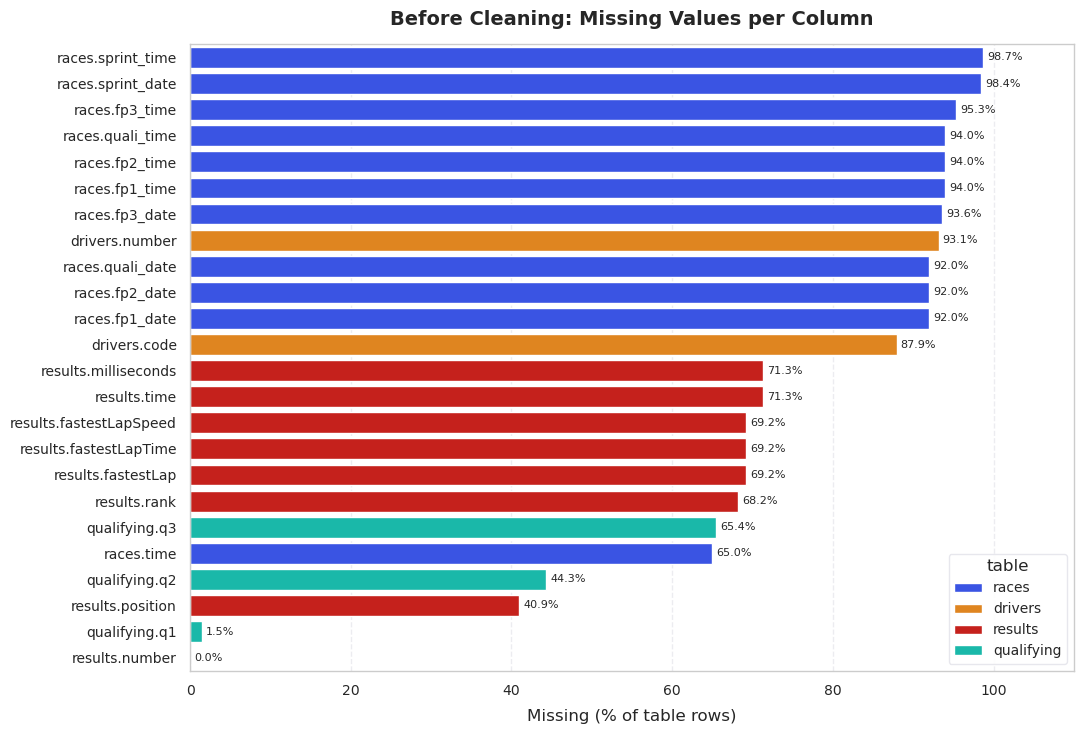

In [13]:
# Task 3.1: missing values per column in the core tables
TABLE_COLORS = {"results": F1_PALETTE["crimson"], "qualifying": F1_PALETTE["teal"],
                "drivers": F1_PALETTE["orange"], "races": F1_PALETTE["blue"]}

missing = pd.concat({t: raw_dataframes[t].isna().mean() * 100 for t in TABLE_COLORS}, names=["table", "column"])
missing = missing[missing > 0].sort_values(ascending=False).rename("missing_pct").reset_index()
missing["label"] = missing["table"] + "." + missing["column"]

fig, ax = plt.subplots(figsize=(11, 7.5))
sns.barplot(data=missing, x="missing_pct", y="label", hue="table", palette=TABLE_COLORS, dodge=False, ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
ax.set(title="Before Cleaning: Missing Values per Column", xlabel="Missing (% of table rows)", ylabel="", xlim=(0, 110))
save_fig("before_eda_missingness_heatmap")
plt.show()

[FIGURE SAVED] figures/before_eda_rows_per_season.png


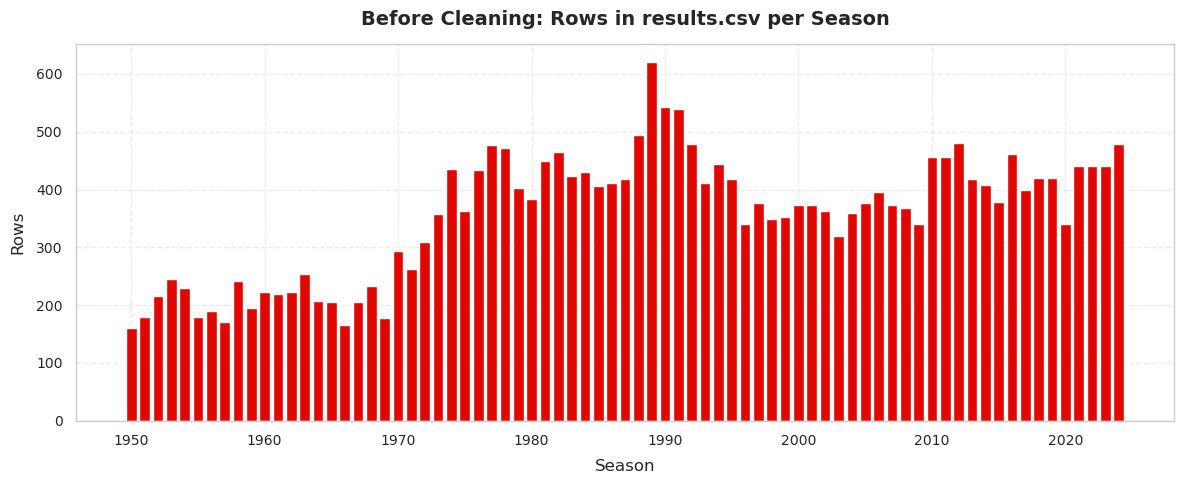

Largest season: 1989 with 620 rows


In [14]:
# Task 3.2: rows per season
rows_per_season = raw_with_year.groupby("year").size()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(rows_per_season.index, rows_per_season.values, color=F1_PALETTE["crimson"], width=0.8)
ax.set(title="Before Cleaning: Rows in results.csv per Season", xlabel="Season", ylabel="Rows")
save_fig("before_eda_rows_per_season")
plt.show()
print(f"Largest season: {rows_per_season.idxmax()} with {rows_per_season.max()} rows")

[FIGURE SAVED] figures/before_eda_entrants_per_race.png


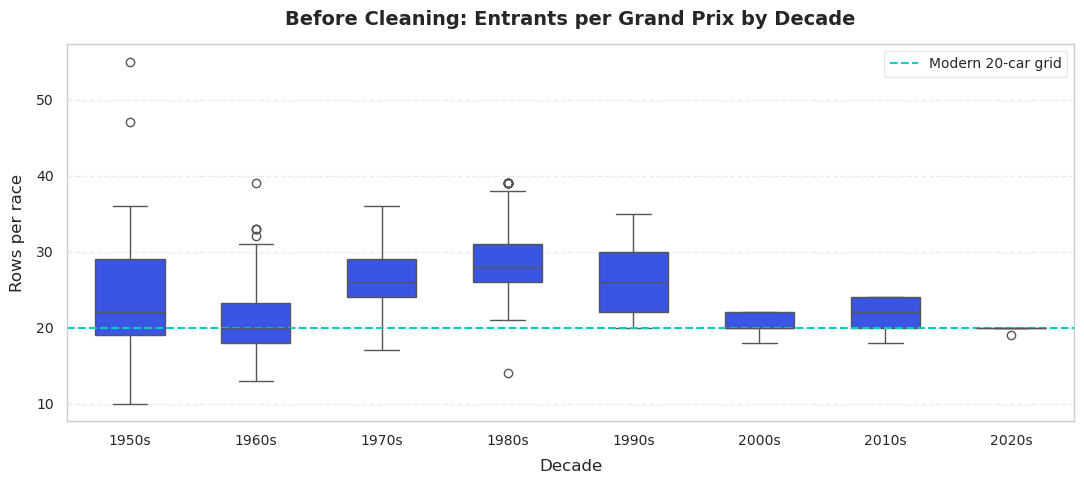

In [15]:
# Task 3.3: entrants per race, by decade
entrants = raw_with_year.groupby(["year", "raceId"]).size().rename("entrants").reset_index()
entrants["decade"] = (entrants["year"] // 10 * 10).astype(str) + "s"

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=entrants, x="decade", y="entrants", color=F1_PALETTE["blue"], width=0.55, ax=ax)
ax.axhline(20, color=F1_PALETTE["teal"], linestyle="--", label="Modern 20-car grid")
ax.set(title="Before Cleaning: Entrants per Grand Prix by Decade", xlabel="Decade", ylabel="Rows per race")
ax.legend()
save_fig("before_eda_entrants_per_race")
plt.show()

[FIGURE SAVED] figures/before_eda_qualifying_coverage.png


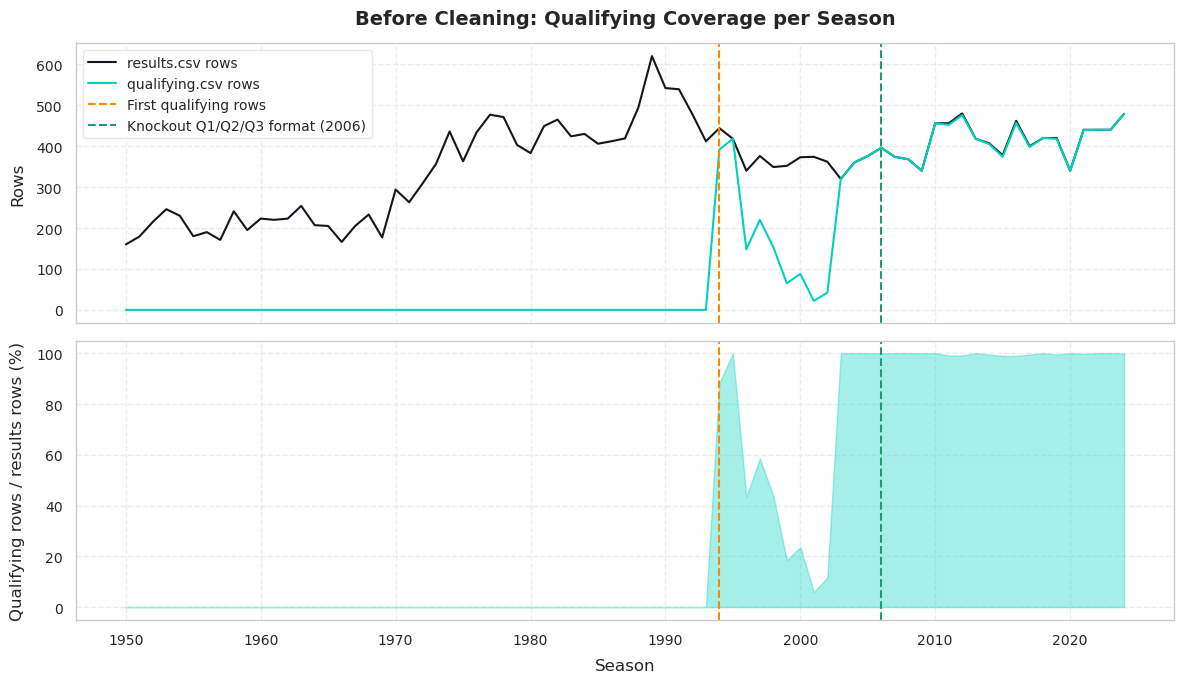

year,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006
results_rows,412.0,444.0,418.0,340.0,376.0,349.0,352.0,373.0,374.0,362.0,320.0,360.0,376.0,396.0
qualifying_rows,0.0,392.0,418.0,148.0,220.0,153.0,65.0,88.0,22.0,42.0,320.0,360.0,376.0,396.0
coverage_pct,0.0,88.3,100.0,43.5,58.5,43.8,18.5,23.6,5.9,11.6,100.0,100.0,100.0,100.0


In [16]:
# Task 3.4: qualifying coverage per season
coverage = pd.DataFrame({
    "results_rows": raw_with_year.groupby("year").size(),
    "qualifying_rows": quali_with_year.groupby("year").size(),
}).fillna(0)
coverage["coverage_pct"] = coverage["qualifying_rows"] / coverage["results_rows"] * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax1.plot(coverage.index, coverage["results_rows"], color=F1_PALETTE["dark"], label="results.csv rows")
ax1.plot(coverage.index, coverage["qualifying_rows"], color=F1_PALETTE["teal"], label="qualifying.csv rows")
ax2.fill_between(coverage.index, coverage["coverage_pct"], color=F1_PALETTE["teal"], alpha=0.35)
for ax in (ax1, ax2):
    ax.axvline(quali_with_year["year"].min(), color=F1_PALETTE["orange"], linestyle="--", label="First qualifying rows")
    ax.axvline(2006, color=F1_PALETTE["green"], linestyle="--", label="Knockout Q1/Q2/Q3 format (2006)")
ax1.set(title="Before Cleaning: Qualifying Coverage per Season", ylabel="Rows")
ax2.set(xlabel="Season", ylabel="Qualifying rows / results rows (%)")
ax1.legend()
save_fig("before_eda_qualifying_coverage")
plt.show()

display(coverage.loc[1993:2006].round(1).T)

[FIGURE SAVED] figures/before_eda_podium_base_rate.png


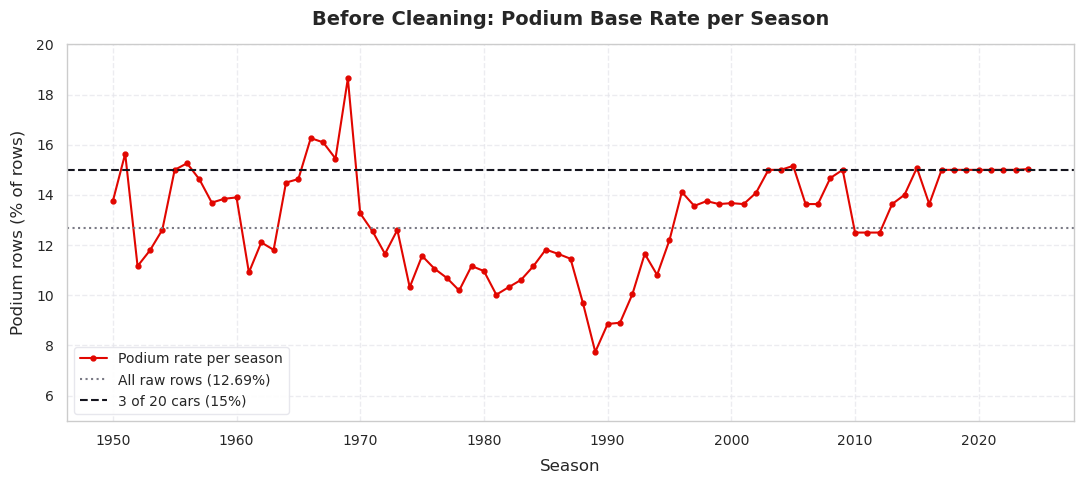

Lowest season: 1989 at 7.74%


In [17]:
# Task 3.5: podium base rate per season
podium_rate_by_season = (raw_with_year["positionOrder"] <= 3).groupby(raw_with_year["year"]).mean() * 100

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(podium_rate_by_season.index, podium_rate_by_season.values, color=F1_PALETTE["crimson"], marker="o", markersize=3.5,
        label="Podium rate per season")
ax.axhline(raw_podium_rate, color=F1_PALETTE["gray"], linestyle=":", label=f"All raw rows ({raw_podium_rate:.2f}%)")
ax.axhline(15, color=F1_PALETTE["dark"], linestyle="--", label="3 of 20 cars (15%)")
ax.set(title="Before Cleaning: Podium Base Rate per Season", xlabel="Season", ylabel="Podium rows (% of rows)", ylim=(5, 20))
ax.legend(loc="lower left")
save_fig("before_eda_podium_base_rate")
plt.show()
print(f"Lowest season: {podium_rate_by_season.idxmin()} at {podium_rate_by_season.min():.2f}%")

[FIGURE SAVED] figures/before_eda_duplicate_distribution.png


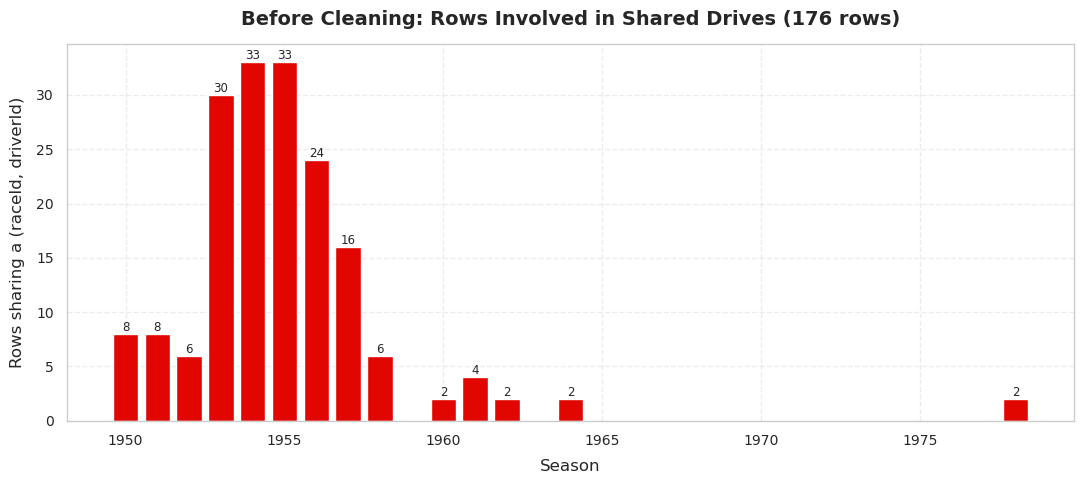

In [18]:
# Task 3.6: where the shared-drive duplicates come from
shared_per_year = shared_rows.groupby("year").size()

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(shared_per_year.index, shared_per_year.values, color=F1_PALETTE["crimson"], width=0.8)
ax.bar_label(bars, fontsize=8.5)
ax.set(title=f"Before Cleaning: Rows Involved in Shared Drives ({len(shared_rows)} rows)",
       xlabel="Season", ylabel="Rows sharing a (raceId, driverId)")
save_fig("before_eda_duplicate_distribution")
plt.show()

---
# 3. Step 2: Data Cleaning (M1)

## Task 4: Types and Sentinels

Work on copies in `cleaned_dataframes` and give each column its real type: dates become datetimes, and lap-time strings such as `"1:24.312"` become seconds. Missing `q2`/`q3` values are kept, because a driver knocked out in an earlier session has no later time.

In [19]:
# Task 4.1: working copies and type conversion
def lap_time_to_seconds(val) -> float:
    """'1:24.312' -> 84.312, '26.898' -> 26.898, missing or unreadable -> NaN."""
    if not isinstance(val, str) or not val.strip():
        return np.nan
    parts = val.strip().split(":")
    try:
        if len(parts) == 1:
            return float(parts[0])
        if len(parts) == 2:
            return float(parts[0]) * 60.0 + float(parts[1])
        if len(parts) == 3:
            return float(parts[0]) * 3600.0 + float(parts[1]) * 60.0 + float(parts[2])
    except ValueError:
        pass
    return np.nan


assert abs(lap_time_to_seconds("1:24.312") - 84.312) < 1e-6
assert abs(lap_time_to_seconds("26.898") - 26.898) < 1e-6
assert np.isnan(lap_time_to_seconds(np.nan))

cleaned_dataframes: Dict[str, pd.DataFrame] = {name: df.copy() for name, df in raw_dataframes.items()}
races, drivers, qualifying, pit_stops, results = (
    cleaned_dataframes[name] for name in ["races", "drivers", "qualifying", "pit_stops", "results"]
)

# Dates
races["date"] = pd.to_datetime(races["date"], errors="raise")
drivers["dob"] = pd.to_datetime(drivers["dob"], errors="raise")
for col in ["fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]:
    races[col] = pd.to_datetime(races[col], errors="coerce")

# Lap times and pit-stop durations -> seconds
for col in ["q1", "q2", "q3"]:
    qualifying[col] = qualifying[col].apply(lap_time_to_seconds)
pit_stops["duration"] = pit_stops["duration"].apply(lap_time_to_seconds)

# Numeric columns (already numeric once the loader has read \N as NaN; kept as a guard)
for col in ["milliseconds", "fastestLap", "rank"]:
    results[col] = pd.to_numeric(results[col], errors="coerce")
drivers["number"] = pd.to_numeric(drivers["number"], errors="coerce")

In [20]:
# Task 4.2: checks
# Parsing lost no value: every time that was present is still present
for table, col in [("qualifying", "q1"), ("qualifying", "q2"), ("qualifying", "q3"), ("pit_stops", "duration")]:
    assert cleaned_dataframes[table][col].isna().sum() == raw_dataframes[table][col].isna().sum(), f"Parsing {table}.{col} lost values"

# No cleaned table still contains the \N sentinel as text
for name, df in cleaned_dataframes.items():
    assert not df.select_dtypes(exclude="number").isin([r"\N", r"\\N"]).any().any(), f"{name} still contains a sentinel"

# The raw tables were not touched
assert not pd.api.types.is_datetime64_any_dtype(raw_dataframes["races"]["date"]), "raw races.date was changed"
assert not pd.api.types.is_float_dtype(raw_dataframes["qualifying"]["q1"]), "raw qualifying.q1 was changed"

typed_columns = [("races", "date"), ("drivers", "dob"), ("qualifying", "q1"), ("qualifying", "q2"),
                 ("qualifying", "q3"), ("pit_stops", "duration")]
display(pd.DataFrame([
    {"column": f"{table}.{col}",
     "raw dtype": str(raw_dataframes[table][col].dtype),
     "clean dtype": str(cleaned_dataframes[table][col].dtype),
     "raw example": raw_dataframes[table][col].dropna().iloc[0],
     "clean example": cleaned_dataframes[table][col].dropna().iloc[0]}
    for table, col in typed_columns
]))

,column,raw dtype,clean dtype,raw example,clean example
0,races.date,object,datetime64[ns],2009-03-29,2009-03-29 00:00:00
1,drivers.dob,object,datetime64[ns],1985-01-07,1985-01-07 00:00:00
2,qualifying.q1,object,float64,1:26.572,86.572
3,qualifying.q2,object,float64,1:25.187,85.187
4,qualifying.q3,object,float64,1:26.714,86.714
5,pit_stops.duration,object,float64,26.898,26.898


## Task 5: Scope Filtering and Non-Starters

Three rules, applied in order to the `results` rows. `cleaning_ledger` records the rows left after each one.

- **DEC-003, Indianapolis 500.** Drop the 1950–1960 Indy 500 races. They counted for the championship but were run to different rules with a different field.
- **DEC-009, non-starters.** Drop a row when the driver completed **zero laps** and is either labelled as not qualified / not pre-qualified / withdrawn, or never held a grid slot. The label alone is not enough: some rows with such a label completed racing laps.
- **DEC-010, pit-lane starts.** Every `grid == 0` row that is left is a genuine pit-lane start. It gets `pit_start = 1`, and `grid` is set to one slot behind the last car on that race's grid, so that `0` is not read as better than pole.

In [21]:
# Task 5.1: Indianapolis 500 exclusion (DEC-003)
# Working table: typed results + season, race name and status text (used for filtering only)
results_work = (
    cleaned_dataframes["results"]
    .merge(races[["raceId", "year", "name"]].rename(columns={"name": "race_name"}), on="raceId", how="left", validate="many_to_one")
    .merge(cleaned_dataframes["status"], on="statusId", how="left", validate="many_to_one")
)
assert len(results_work) == len(raw_dataframes["results"]), "Re-run Task 4 first: cleaned results were already filtered"
cleaning_ledger: Dict[str, int] = {"Raw results.csv": len(results_work)}

is_indy = results_work["year"].between(1950, 1960) & results_work["race_name"].str.contains("Indianapolis 500", case=False, na=False)
assert results_work.loc[is_indy, "raceId"].nunique() == 11, "Expected one Indy 500 per season, 1950-1960"

if EXCLUDE_INDY_500:
    results_work = results_work[~is_indy].copy()
cleaning_ledger["Indy 500 exclusion (DEC-003)"] = len(results_work)
print(f"Removed {is_indy.sum():,} Indy 500 rows -> {len(results_work):,} remaining")

Removed 405 Indy 500 rows -> 26,354 remaining


In [22]:
# Task 5.2: non-starter removal (DEC-009)
NON_START_POSITION_TEXT: Set[str] = {"F", "W"}  # F = failed to qualify, W = withdrawn
NON_START_STATUSES: Set[str] = {"Did not qualify", "Did not prequalify", "Withdrew"}

flagged = results_work["positionText"].isin(NON_START_POSITION_TEXT) | results_work["status"].isin(NON_START_STATUSES)
no_grid_slot = results_work["grid"] == 0
zero_laps = results_work["laps"] == 0

# Why the label alone is not enough
print(f"Rows labelled as non-starters: {flagged.sum():,} | of these, completed at least one lap: "
      f"{(flagged & ~zero_laps).sum()} | hold a grid slot: {(flagged & ~no_grid_slot).sum()}")

is_non_starter = zero_laps & (flagged | no_grid_slot)
assert (results_work.loc[is_non_starter, "positionOrder"] > 3).all(), "The rule would remove a podium finisher"
display(results_work.loc[is_non_starter, "positionText"].value_counts().to_frame("rows removed").T)

results_work = results_work[~is_non_starter].copy()
cleaning_ledger["Non-starter removal (DEC-009)"] = len(results_work)
print(f"Removed {is_non_starter.sum():,} non-starter rows -> {len(results_work):,} remaining")

Rows labelled as non-starters: 1,724 | of these, completed at least one lap: 24 | hold a grid slot: 173


positionText,F,W,E,D,R
rows removed,1367,331,7,6,4


Removed 1,715 non-starter rows -> 24,639 remaining


In [23]:
# Task 5.3: pit-lane starts (DEC-010)
is_pit_start = results_work["grid"] == 0
assert (results_work.loc[is_pit_start, "laps"] > 0).all(), "A grid = 0 row with zero laps survived DEC-009"

results_work["pit_start"] = is_pit_start.astype(int)
last_grid_slot = results_work.groupby("raceId")["grid"].transform("max")
results_work.loc[is_pit_start, "grid"] = last_grid_slot[is_pit_start] + 1
assert (results_work["grid"] >= 1).all(), "grid = 0 survived the recoding"

pit_rows = results_work[is_pit_start]
print(f"Pit-lane starts: {len(pit_rows)} rows, seasons {pit_rows['year'].min()}–{pit_rows['year'].max()}, "
      f"podium finishes among them: {(pit_rows['positionOrder'] <= 3).sum()}")

Pit-lane starts: 72 rows, seasons 2015–2024, podium finishes among them: 0


## Task 6: Shared-Drive Removal

**DEC-034 (replaces DEC-008).** Until the mid-1960s a driver could take over a teammate's car during a race. Ergast then lists the shared car once under each driver, with the same grid slot and the same classification. The slot belongs to whoever started the car and the result to whoever finished it, and the data does not say which driver did which. A row of a shared car therefore pairs one driver's pre-race data with another driver's result. The instructors ruled that this is data leakage (Piazza). They also ruled that removing or keeping such entries is the team's choice, provided it is justified.

- **A car** is one constructor entry with one grid slot and one classification (`positionOrder`). Two drivers listed with the same car shared it. Two drivers with the same slot but different classifications drove two different cars (a data-entry collision, for example in the 1975 Brazilian GP), and their rows are kept.
- **Every row of a shared car is removed**, under every driver it is listed for.
- **A driver who also drove a car of their own keeps that row:** its grid slot and its result are both theirs. A driver left with two cars of their own is removed, because there is no way to tell which one they started in.
- **`field_size` is counted before the removal,** so it still counts every driver who took the start.

The earlier rule (DEC-008) kept each driver's best-classified row. It was dropped because that row was almost always a shared car (counted below), so it kept exactly the pairing the instructors ruled out.

In [24]:
# Task 6: shared drives (DEC-034, replaces DEC-008)
# A car is one constructor entry with one grid slot and one classification. Listed under two drivers, it was shared.
CAR_KEY: List[str] = ["raceId", "constructorId", "grid", "positionOrder"]
in_shared_car = results_work.groupby(CAR_KEY)["driverId"].transform("nunique") > 1
same_slot = results_work.groupby(["raceId", "constructorId", "grid"])["driverId"].transform("nunique") > 1
shared = results_work[in_shared_car]
print(f"Rows of a shared car: {len(shared)} ({shared.groupby(GRAIN).ngroups} driver entries, {shared['raceId'].nunique()} races, "
      f"seasons {shared['year'].min()}–{shared['year'].max()}), of which podium rows: {int((shared['positionOrder'] <= 3).sum())}")
print(f"Same slot, different classification (two cars, kept): {int((same_slot & ~in_shared_car).sum())} rows")

# What the old rule (DEC-008: each driver's best-classified row) kept
has_two_rows = results_work.duplicated(subset=GRAIN, keep=False)
old_rule_kept = results_work[has_two_rows].sort_values(GRAIN + ["positionOrder"]).drop_duplicates(subset=GRAIN).index
print(f"Old rule: of the {len(old_rule_kept)} rows it kept for drivers with two rows, "
      f"{int(in_shared_car[old_rule_kept].sum())} are a shared car")

# Example: the 1957 British Grand Prix, won by a car that two drivers shared
example = results_work[in_shared_car & (results_work["year"] == 1957) & (results_work["race_name"] == "British Grand Prix")]
display(example.assign(driver=example["driverId"].map(cleaned_dataframes["drivers"].set_index("driverId")["surname"]))
        [["driver", "constructorId", "grid", "laps", "positionOrder", "positionText"]].sort_values(["grid", "driver"]))

# Field size counts every driver who took the start, so it is fixed before any row is removed
results_work["field_size"] = results_work.groupby("raceId")["driverId"].transform("nunique")

own_cars = results_work[~in_shared_car]
two_own_cars = own_cars.duplicated(subset=GRAIN, keep=False)   # no way to tell which of the two they started in
results_clean = own_cars[~two_own_cars].sort_values("resultId").reset_index(drop=True)

affected = shared[GRAIN].drop_duplicates()
kept_own_car = affected.merge(results_clean[GRAIN], on=GRAIN)
print(f"Drivers in a shared car who keep a car of their own: {len(kept_own_car)} of {len(affected)} | "
      f"drivers with two cars of their own (removed): {own_cars.loc[two_own_cars].groupby(GRAIN).ngroups}")

assert (results_clean.groupby(CAR_KEY)["driverId"].transform("nunique") == 1).all(), "A shared car survived"
cleaning_ledger["Shared-drive removal (DEC-034)"] = len(results_clean)
print(f"Removed {len(results_work) - len(results_clean):,} rows -> {len(results_clean):,} remaining")

_ = validate_data_contract(results_clean, enforce_grain_only=True)

Rows of a shared car: 155 (135 driver entries, 40 races, seasons 1950–1964), of which podium rows: 36
Same slot, different classification (two cars, kept): 29 rows
Old rule: of the 61 rows it kept for drivers with two rows, 59 are a shared car


,driver,constructorId,grid,laps,positionOrder,positionText
20290,Brooks,118,1,51,12,R
18816,Moss,118,1,51,12,R
18805,Brooks,118,3,90,1,1
20288,Moss,118,3,90,1,1
20289,Collins,6,9,88,4,4
18808,Trintignant,6,9,88,4,4


Drivers in a shared car who keep a car of their own: 43 of 135 | drivers with two cars of their own (removed): 1
Removed 157 rows -> 24,482 remaining
[CONTRACT PASSED] Grain verified: 24,482 unique (raceId, driverId) rows.


## Task 7: Base Table and Target

Join the cleaned results to `races` and `circuits`, add the `podium` target, and validate the data contract (DEC-005). Two side tables are made safe to merge: `qualifying.position` is renamed to `quali_position`, and every sprint column gets a `sprint_` prefix, so neither collides with the blacklisted `results` columns.

`clean_df` still carries the race-outcome columns, because M2 needs them for the analysis questions. They remain blacklisted as features.

In [25]:
# Task 7.1: side tables, base table and target
qualifying_clean = cleaned_dataframes["qualifying"].rename(columns={"position": "quali_position"})
sprint_clean = cleaned_dataframes["sprint_results"].rename(columns=lambda col: col if col in GRAIN else f"sprint_{col}")

circuit_context = cleaned_dataframes["circuits"][["circuitId", "name", "location", "country"]].rename(
    columns={"name": "circuit_name", "location": "circuit_location", "country": "circuit_country"}
)
clean_df = (
    results_clean
    .merge(races[["raceId", "round", "circuitId", "date"]], on="raceId", how="left", validate="many_to_one")
    .merge(circuit_context, on="circuitId", how="left", validate="many_to_one")
)
clean_df[TARGET_COLUMN] = (clean_df["positionOrder"] <= 3).astype(int)

# Identifiers, context, pre-race columns and target first; outcome columns after
leading_cols = IDENTIFIER_COLUMNS + ["round", "race_name", "circuitId", "circuit_name", "circuit_location",
                                     "circuit_country", "grid", "pit_start", "field_size", TARGET_COLUMN]
clean_df = clean_df[leading_cols + [c for c in clean_df.columns if c not in leading_cols]]

# The cleaned results replace the typed copy in the registry
cleaned_dataframes["results"] = results_clean.drop(columns=["year", "race_name", "status"])

_ = validate_data_contract(clean_df, feature_cols=["grid", "pit_start"])
print(f"clean_df: {clean_df.shape[0]:,} rows x {clean_df.shape[1]} columns, {clean_df['raceId'].nunique():,} races, "
      f"seasons {clean_df['year'].min()}–{clean_df['year'].max()}")
display(clean_df.head(3))

[LEAKAGE CHECK PASSED] All 2 candidate features respect the pre-race cutoff.
[CONTRACT PASSED] Full modeling table contract satisfied across 24,482 rows.
clean_df: 24,482 rows x 30 columns, 1,114 races, seasons 1950–2024


,raceId,driverId,constructorId,date,year,round,race_name,circuitId,circuit_name,circuit_location,circuit_country,grid,pit_start,field_size,podium,resultId,number,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,status
0,18,1,1,2008-03-16,2008,1,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Melbourne,Australia,1,0,22,1,1,22.0,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1,Finished
1,18,2,2,2008-03-16,2008,1,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Melbourne,Australia,5,0,22,1,2,3.0,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1,Finished
2,18,3,3,2008-03-16,2008,1,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Melbourne,Australia,7,0,22,1,3,7.0,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1,Finished


In [26]:
# Task 7.2: the target in each split
split = pd.cut(clean_df["year"], bins=[0, TRAIN_MAX_YEAR, TEST_MIN_YEAR - 1, 9999], labels=["train", "validation", "test"])
split_profile_df = clean_df.groupby(split, observed=True).agg(
    rows=(TARGET_COLUMN, "size"), races=("raceId", "nunique"), podiums=(TARGET_COLUMN, "sum"), podium_pct=(TARGET_COLUMN, "mean")
)
split_profile_df["podium_pct"] = (split_profile_df["podium_pct"] * 100).round(2)
display(split_profile_df)
print(f"Podium base rate: raw {raw_podium_rate:.2f}% -> cleaned {clean_df[TARGET_COLUMN].mean() * 100:.2f}%")

# No race can have more than three podium rows. A race whose podium car was shared keeps fewer (DEC-034).
podiums_per_race = clean_df.groupby("raceId")[TARGET_COLUMN].sum()
assert (podiums_per_race <= 3).all(), "A race has more than three podium rows after cleaning"
display(podiums_per_race.value_counts().sort_index().rename_axis("podium rows in race").to_frame("races").T)

,rows,races,podiums,podium_pct
year,,,,
train,22355,1007,3004,13.44
validation,775,39,117,15.10
test,1352,68,204,15.09


Podium base rate: raw 12.69% -> cleaned 13.58%


podium rows in race,1,2,3
races,2,13,1099


## Task 8: "After" EDA

The Task 3 plots again, with the raw and the cleaned data side by side, saved as `figures/after_eda_*.png`.

,rows_remaining,rows_removed
Raw results.csv,26759,0
Indy 500 exclusion (DEC-003),26354,405
Non-starter removal (DEC-009),24639,1715
Shared-drive removal (DEC-034),24482,157


[FIGURE SAVED] figures/after_eda_row_count_waterfall.png


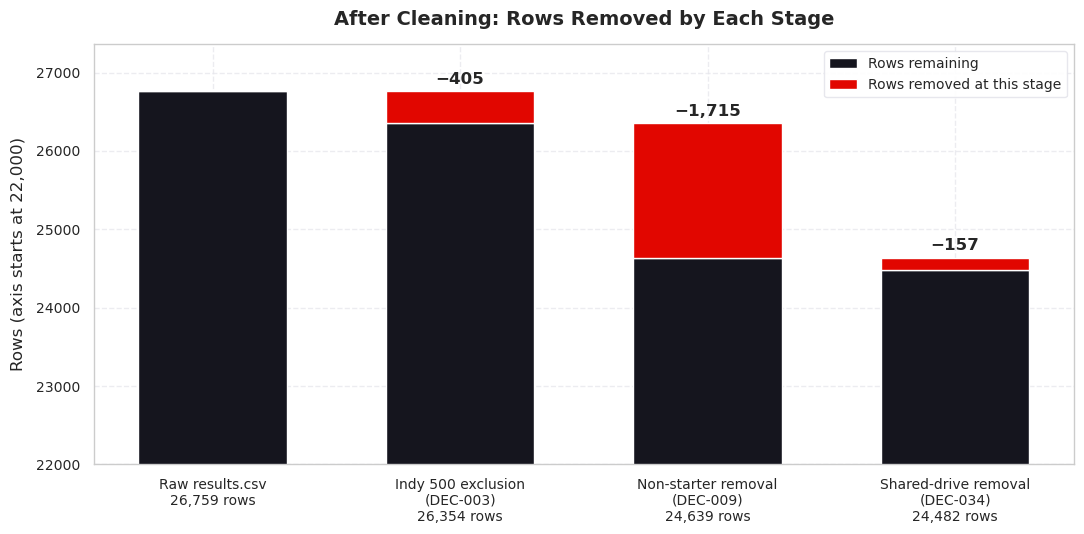

In [27]:
# Task 8.1: rows removed by each cleaning stage
ledger_df = pd.Series(cleaning_ledger, name="rows_remaining").to_frame()
ledger_df["rows_removed"] = -ledger_df["rows_remaining"].diff().fillna(0).astype(int)
display(ledger_df)

labels = [f"{stage.replace(' (', chr(10) + '(')}\n{rows:,} rows" for stage, rows in cleaning_ledger.items()]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(labels, ledger_df["rows_remaining"], color=F1_PALETTE["dark"], width=0.6, label="Rows remaining")
removed = ax.bar(labels, ledger_df["rows_removed"], bottom=ledger_df["rows_remaining"], color=F1_PALETTE["crimson"],
                 width=0.6, label="Rows removed at this stage")
ax.bar_label(removed, labels=[f"−{n:,}" if n else "" for n in ledger_df["rows_removed"]], padding=3, fontweight="bold")
ax.set(title="After Cleaning: Rows Removed by Each Stage", ylabel="Rows (axis starts at 22,000)",
       ylim=(22000, ledger_df["rows_remaining"].iloc[0] + 600))
ax.legend()
save_fig("after_eda_row_count_waterfall")
plt.show()

[FIGURE SAVED] figures/after_eda_entrants_per_race.png


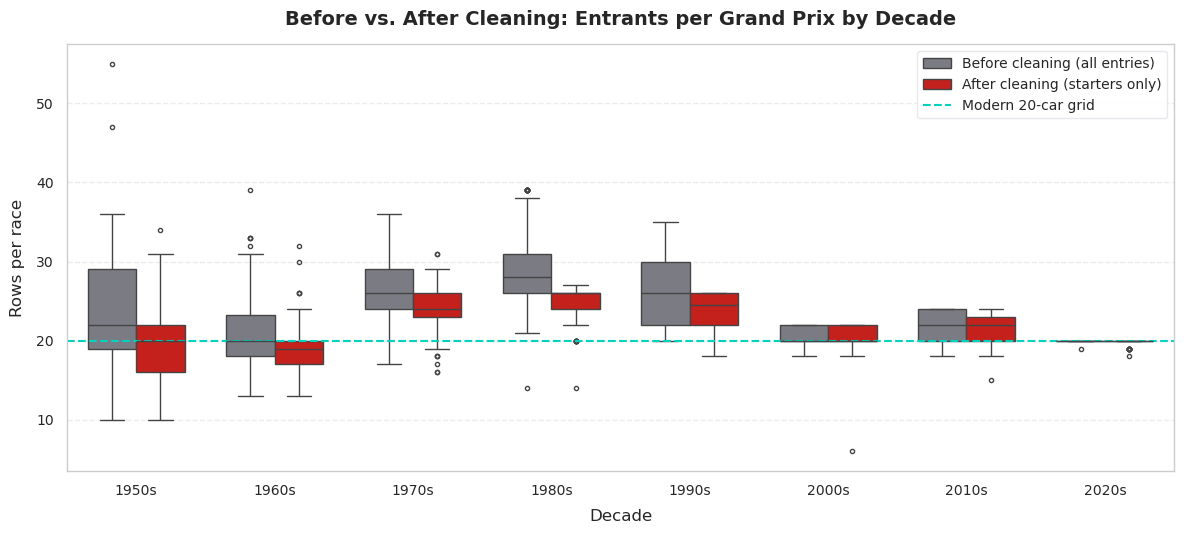

Largest field: {'Before cleaning (all entries)': 55, 'After cleaning (starters only)': 34}


In [28]:
# Task 8.2: entrants per race by decade, before and after
field_sizes = pd.concat([
    raw_with_year.groupby(["year", "raceId"]).size().rename("entrants").reset_index().assign(stage="Before cleaning (all entries)"),
    clean_df.groupby(["year", "raceId"])["field_size"].first().rename("entrants").reset_index().assign(stage="After cleaning (starters only)"),
])
field_sizes["decade"] = (field_sizes["year"] // 10 * 10).astype(str) + "s"

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.boxplot(data=field_sizes, x="decade", y="entrants", hue="stage",
            palette=[F1_PALETTE["gray"], F1_PALETTE["crimson"]], width=0.7, fliersize=3, ax=ax)
ax.axhline(20, color=F1_PALETTE["teal"], linestyle="--", label="Modern 20-car grid")
ax.set(title="Before vs. After Cleaning: Entrants per Grand Prix by Decade", xlabel="Decade", ylabel="Rows per race")
ax.legend(loc="upper right")
save_fig("after_eda_entrants_per_race")
plt.show()
print("Largest field:", field_sizes.groupby("stage", sort=False)["entrants"].max().to_dict())

[FIGURE SAVED] figures/after_eda_missingness.png


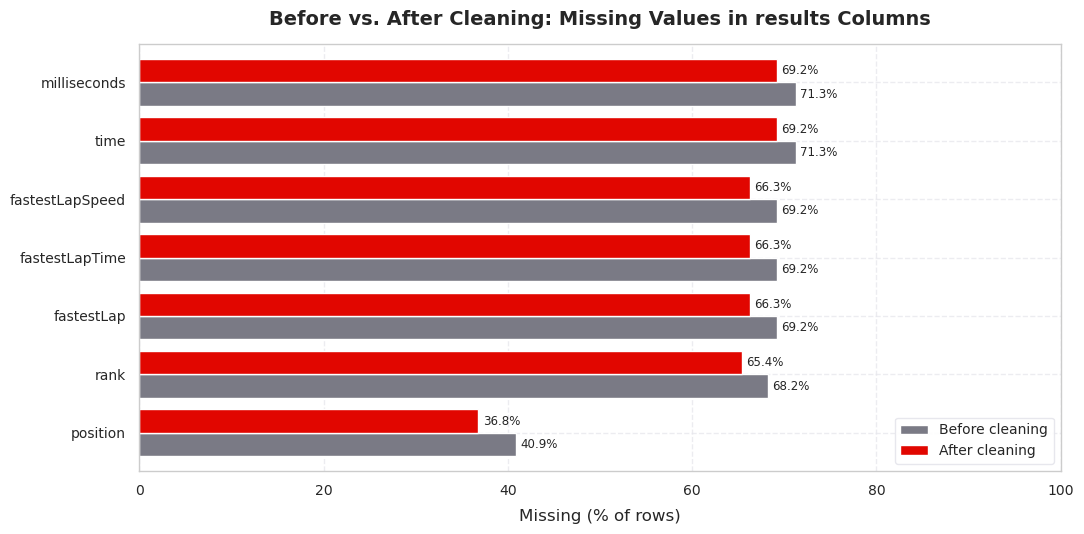

In [29]:
# Task 8.3: missing values in the results columns, before and after
raw_results = raw_dataframes["results"]
null_compare = pd.DataFrame({
    "Before cleaning": raw_results.isna().mean() * 100,
    "After cleaning": clean_df[raw_results.columns].isna().mean() * 100,
})
null_compare = null_compare[null_compare["Before cleaning"] > 0.1].sort_values("Before cleaning")

ax = null_compare.plot.barh(color=[F1_PALETTE["gray"], F1_PALETTE["crimson"]], width=0.8, figsize=(11, 5.5))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8.5)
ax.set(title="Before vs. After Cleaning: Missing Values in results Columns", xlabel="Missing (% of rows)", xlim=(0, 100))
ax.legend(loc="lower right")
save_fig("after_eda_missingness")
plt.show()

[FIGURE SAVED] figures/after_eda_podium_base_rate.png


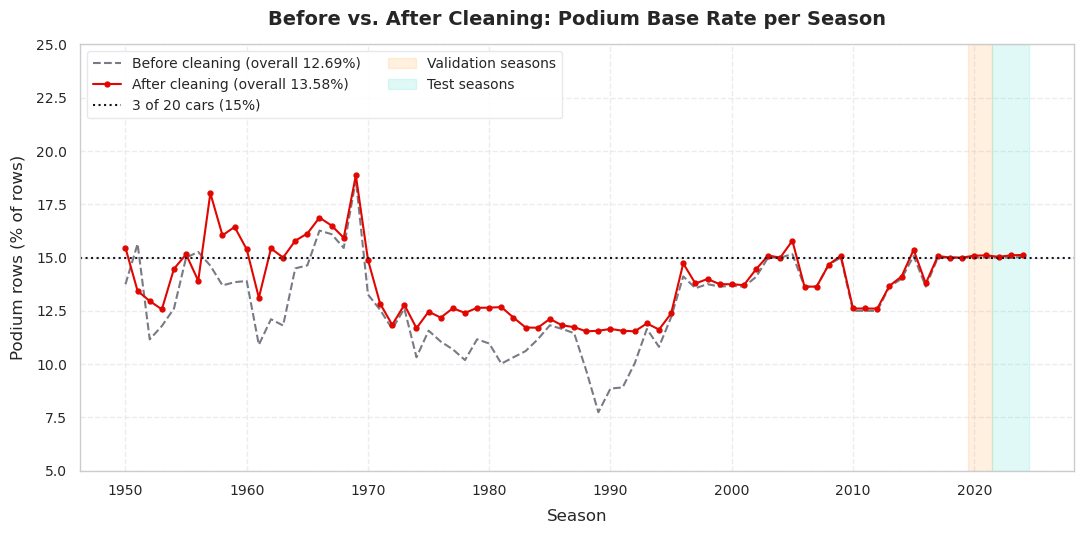

Largest increase: 1989 (+3.82 points)


In [30]:
# Task 8.4: podium base rate per season, before and after
rate_after = clean_df.groupby("year")[TARGET_COLUMN].mean() * 100
clean_podium_rate = clean_df[TARGET_COLUMN].mean() * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(podium_rate_by_season.index, podium_rate_by_season.values, color=F1_PALETTE["gray"], linestyle="--",
        label=f"Before cleaning (overall {raw_podium_rate:.2f}%)")
ax.plot(rate_after.index, rate_after.values, color=F1_PALETTE["crimson"], marker="o", markersize=3.5,
        label=f"After cleaning (overall {clean_podium_rate:.2f}%)")
ax.axhline(15, color=F1_PALETTE["dark"], linestyle=":", label="3 of 20 cars (15%)")
ax.axvspan(VAL_YEARS[0] - 0.5, VAL_YEARS[1] + 0.5, color=F1_PALETTE["orange"], alpha=0.12, label="Validation seasons")
ax.axvspan(TEST_MIN_YEAR - 0.5, clean_df["year"].max() + 0.5, color=F1_PALETTE["teal"], alpha=0.12, label="Test seasons")
ax.set(title="Before vs. After Cleaning: Podium Base Rate per Season", xlabel="Season", ylabel="Podium rows (% of rows)", ylim=(5, 25))
ax.legend(loc="upper left", ncol=2)
save_fig("after_eda_podium_base_rate")
plt.show()

rate_change = (rate_after - podium_rate_by_season).sort_values(ascending=False)
print(f"Largest increase: {rate_change.index[0]} (+{rate_change.iloc[0]:.2f} points)")

[FIGURE SAVED] figures/after_eda_qualifying_coverage.png


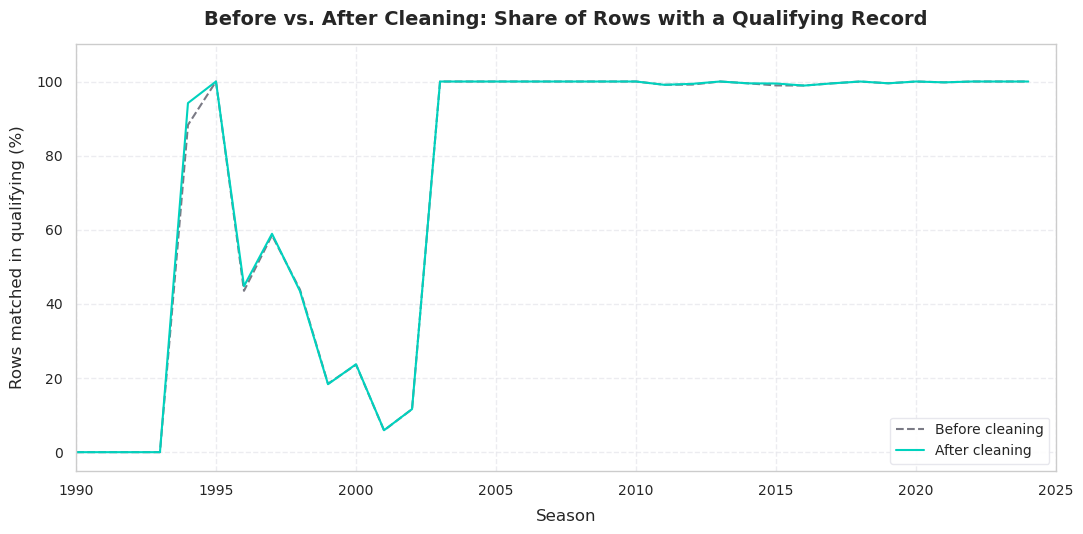

year,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004
Before cleaning,0.0,88.3,100.0,43.5,58.5,43.8,18.5,23.6,5.9,11.6,100.0,100.0
After cleaning,0.0,94.2,100.0,44.8,58.9,43.4,18.3,23.7,5.9,11.6,100.0,100.0


Cleaned rows from 2003 on without a qualifying record: 21


In [31]:
# Task 8.5: share of rows with a qualifying record, before and after
def with_quali_flag(df: pd.DataFrame) -> pd.DataFrame:
    """Return year plus has_quali: does the (raceId, driverId) row have a qualifying record?"""
    merged = df[GRAIN + ["year"]].merge(qualifying_clean[GRAIN], on=GRAIN, how="left", indicator=True)
    return merged.assign(has_quali=merged["_merge"] == "both")

quali_before = with_quali_flag(raw_with_year.drop_duplicates(subset=GRAIN))
quali_after = with_quali_flag(clean_df)
quali_coverage = pd.DataFrame({
    "Before cleaning": quali_before.groupby("year")["has_quali"].mean() * 100,
    "After cleaning": quali_after.groupby("year")["has_quali"].mean() * 100,
})

ax = quali_coverage.plot(color=[F1_PALETTE["gray"], F1_PALETTE["teal"]], style=["--", "-"], figsize=(11, 5.5))
ax.set(title="Before vs. After Cleaning: Share of Rows with a Qualifying Record", xlabel="Season",
       ylabel="Rows matched in qualifying (%)", xlim=(1990, clean_df["year"].max() + 1), ylim=(-5, 110))
ax.legend(loc="lower right")
save_fig("after_eda_qualifying_coverage")
plt.show()

display(quali_coverage.loc[1993:2004].round(1).T)
print(f"Cleaned rows from 2003 on without a qualifying record: {(~quali_after.loc[quali_after['year'] >= 2003, 'has_quali']).sum()}")

In [32]:
# Task 8.6: final types and checks on clean_df
display(pd.DataFrame({
    "dtype": clean_df.dtypes.astype(str),
    "null_pct": (clean_df.isna().mean() * 100).round(2),
    "unique": clean_df.nunique(),
}))

numeric_cols = ["raceId", "driverId", "constructorId", "year", "round", "grid", "pit_start", "positionOrder", "laps",
                "points", "milliseconds", "fastestLap", "rank", "fastestLapSpeed", TARGET_COLUMN]
assert all(pd.api.types.is_numeric_dtype(clean_df[col]) for col in numeric_cols), "A numeric column is not numeric"
assert pd.api.types.is_datetime64_any_dtype(clean_df["date"]), "'date' should be a datetime"
assert all(pd.api.types.is_float_dtype(qualifying_clean[col]) for col in ["q1", "q2", "q3"]), "q1-q3 should be float seconds"
assert not clean_df.select_dtypes(exclude="number").isin([r"\N"]).any().any(), r"\N remains in clean_df"
assert "pit_start" not in raw_dataframes["results"].columns, "raw results was changed"
print(f"[STEP 2 COMPLETE] clean_df is ready: {len(clean_df):,} rows x {clean_df.shape[1]} columns.")

,dtype,null_pct,unique
raceId,int64,0.00,1114
driverId,int64,0.00,678
constructorId,int64,0.00,165
date,datetime64[ns],0.00,1114
year,int64,0.00,75
round,int64,0.00,24
race_name,object,0.00,53
circuitId,int64,0.00,77
circuit_name,object,0.00,77
circuit_location,object,0.00,75


[STEP 2 COMPLETE] clean_df is ready: 24,482 rows x 30 columns.


## Hand-Off

`clean_df` has one row per `(raceId, driverId)` and passes the data contract.

| Stage | Rows removed | Rows left |
| :--- | ---: | ---: |
| Raw `results` | | 26,759 |
| Indianapolis 500, 1950–1960 (DEC-003) | 405 | 26,354 |
| Non-starters (DEC-009) | 1,715 | 24,639 |
| Shared drives (DEC-034) | 157 | 24,482 |

| Split | Rows | Races | Podiums | Podium rate |
| :--- | ---: | ---: | ---: | ---: |
| Train (≤ 2019) | 22,355 | 1,007 | 3,004 | 13.44% |
| Validation (2020–2021) | 775 | 39 | 117 | 15.10% |
| Test (≥ 2022) | 1,352 | 68 | 204 | 15.09% |

| Object | Contents |
| :--- | :--- |
| `clean_df` | Cleaned results with race and circuit context, `pit_start` and `podium`. Outcome columns are kept for analysis and are blacklisted as features. |
| `qualifying_clean` | `position` renamed to `quali_position`; `q1`–`q3` in seconds. |
| `sprint_clean` | Every non-key column prefixed with `sprint_`. |
| `cleaned_dataframes` | Typed copies of all 14 tables; `results` is the cleaned version, one row per driver per race. |

**Keep in mind**
- The podium base rate is 13.58% after cleaning (12.69% raw). It reaches 15% only in the modern 20-car seasons.
- No race has more than three podium rows. Two races keep one and 13 keep two, because their other podium cars were shared and removed (DEC-034).
- Qualifying records cover only 6%–59% of rows per season from 1996 to 2002 and are complete from 2003 (21 rows unmatched), so qualifying features need a missing flag and a `grid` fallback.
- DEC-009 (non-starters) and DEC-003 (Indianapolis 500) are tested by retraining in Task 31b.

---
# 4. Step 3: Data-Engineering Questions (M2)

Three questions, each answered by joining `clean_df` to other tables. Every question ends with the answer, the joins used, and notes on grain, missing values and the pre-race cutoff.

These are descriptive analyses, not model inputs. Outcome columns such as `podium` and `status` are the thing being measured here and stay blacklisted as features. Every grouping variable (grid slot, qualifying position, circuit, nationality, constructor) is known before the race starts.

In [33]:
# Step 3 helpers: statistics imports and a rate table with Wilson 95% intervals
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.proportion import proportion_confint


def rate_table(df: pd.DataFrame, by: List[str], event: str) -> pd.DataFrame:
    """Per group: n rows, number of events, rate in % and its Wilson 95% interval."""
    out = df.groupby(by, observed=True)[event].agg(n="size", events="sum").reset_index()
    low, high = proportion_confint(out["events"], out["n"], method="wilson")
    return out.assign(rate=out["events"] / out["n"] * 100, ci_low=low * 100, ci_high=high * 100)

## Task 9: Q1, Front-Row Conversion by Circuit

**Question.** Which circuits convert a front-row start into a podium most often, and does that ranking change after the 2014 hybrid era?

**DEC-035 (replaces DEC-011).** A front-row start is a start from **grid** slot 1 or 2. Only the grid is used. The instructors confirmed that the question is about the starting grid. The brief's note on qualifying is a reminder that penalties make the two differ, not a request for a second rate (Piazza).

- **Every season is used.** The grid is recorded for every race, so nothing restricts Q1 to the seasons with qualifying data. The pre-hybrid era is 1950–2013 and the hybrid era 2014–2024.
- **A circuit is ranked** only if it has at least 10 front-row starts in each era.
- **Slots 1 and 2 are the same two slots in every season,** even though until the early 1970s the front row of the grid often held three or four cars.
- **A sensitivity check** repeats the comparison with a pre-hybrid window as long as the hybrid one (2003–2013). This shows whether the answer depends on how far back the pre-hybrid era reaches.

In [34]:
# Task 9.1: front-row starts by grid slot, every season (DEC-035)
HYBRID_ERA_START: int = 2014
MIN_FRONT_ROW_STARTS: int = 10   # per circuit, per era
Q1_ERAS: List[str] = [f"{clean_df['year'].min()}–{HYBRID_ERA_START - 1}", f"{HYBRID_ERA_START}–{clean_df['year'].max()}"]

q1_df = clean_df[GRAIN + ["year", "circuitId", "circuit_name", "grid", "pit_start", TARGET_COLUMN]].copy()
q1_df["era"] = np.where(q1_df["year"] >= HYBRID_ERA_START, Q1_ERAS[1], Q1_ERAS[0])
q1_df["front_row"] = q1_df["grid"].isin([1, 2]) & q1_df["pit_start"].eq(0)   # a recoded pit-lane start is never on the front row
assert q1_df["year"].min() == clean_df["year"].min(), "Q1 must use every season"

front_rows_per_race = q1_df.groupby("raceId")["front_row"].sum()
print(f"Q1 table: {len(q1_df):,} starts in {q1_df['raceId'].nunique():,} races, seasons {q1_df['year'].min()}–{q1_df['year'].max()} | "
      f"front-row starts: {int(q1_df['front_row'].sum()):,}")
print(f"Races with fewer than two front-row starts: {int((front_rows_per_race < 2).sum())} "
      f"(a front-row car did not start, or was a shared car) | with more than two: {int((front_rows_per_race > 2).sum())}")
display(q1_df[q1_df["front_row"]].groupby("era").agg(front_row_starts=(TARGET_COLUMN, "size"), podiums=(TARGET_COLUMN, "sum"),
                                                    circuits=("circuitId", "nunique"))
        .assign(podium_pct=lambda d: (d["podiums"] / d["front_row_starts"] * 100).round(1)))

Q1 table: 24,482 starts in 1,114 races, seasons 1950–2024 | front-row starts: 2,212
Races with fewer than two front-row starts: 17 (a front-row car did not start, or was a shared car) | with more than two: 1


,front_row_starts,podiums,circuits,podium_pct
era,,,,
1950–2013,1759,991,69,56.3
2014–2024,453,345,32,76.2


In [35]:
# Task 9.2: conversion rate per circuit and era, minimum-sample filter, rank correlation between eras
def conversion_by_circuit(df: pd.DataFrame, eras: List[str]) -> pd.DataFrame:
    """Front-row conversion rate per circuit and era, for circuits with enough front-row starts in every era."""
    rates = rate_table(df[df["front_row"]], ["circuit_name", "era"], TARGET_COLUMN)
    n_per_era = rates.pivot(index="circuit_name", columns="era", values="n").reindex(columns=eras).fillna(0)
    eligible = n_per_era.index[(n_per_era >= MIN_FRONT_ROW_STARTS).all(axis=1)]
    wide = rates[rates["circuit_name"].isin(eligible)].pivot_table(index="circuit_name", columns="era", values=["rate", "n"])
    wide[("rate", "change")] = wide[("rate", eras[1])] - wide[("rate", eras[0])]
    for era in eras:
        wide[("rank", era)] = wide[("rate", era)].rank(ascending=False, method="min")
    return wide.sort_index(axis=1).sort_values(("rate", eras[1]), ascending=False)


q1_wide = conversion_by_circuit(q1_df, Q1_ERAS)
rho, p_value = stats.spearmanr(q1_wide[("rate", Q1_ERAS[0])], q1_wide[("rate", Q1_ERAS[1])])
print(f"{len(q1_wide)} circuits with >= {MIN_FRONT_ROW_STARTS} front-row starts in both eras | "
      f"Spearman rho between eras = {rho:.2f} (p = {p_value:.2f})")
display(q1_wide.round(1))

# Sensitivity: a pre-hybrid window as long as the hybrid era (2003–2013)
window_start = HYBRID_ERA_START - (int(clean_df["year"].max()) - HYBRID_ERA_START + 1)
Q1_ERAS_SHORT: List[str] = [f"{window_start}–{HYBRID_ERA_START - 1}", Q1_ERAS[1]]
q1_short = q1_df[q1_df["year"] >= window_start].assign(era=lambda d: np.where(d["year"] >= HYBRID_ERA_START, Q1_ERAS_SHORT[1], Q1_ERAS_SHORT[0]))
q1_wide_short = conversion_by_circuit(q1_short, Q1_ERAS_SHORT)
rho_short, p_short = stats.spearmanr(q1_wide_short[("rate", Q1_ERAS_SHORT[0])], q1_wide_short[("rate", Q1_ERAS_SHORT[1])])
both_windows = q1_wide[("rate", Q1_ERAS[0])].to_frame("long").join(q1_wide_short[("rate", Q1_ERAS_SHORT[0])].rename("short"), how="inner")
rho_windows, _ = stats.spearmanr(both_windows["long"], both_windows["short"])
display(pd.DataFrame({
    window: {"circuits ranked": len(table), "front-row starts, pre-hybrid": int(table[("n", eras[0])].sum()),
             "conversion %, pre-hybrid": table[("n", eras[0])].mul(table[("rate", eras[0])]).sum() / table[("n", eras[0])].sum(),
             "Spearman rho between eras": r}
    for window, table, eras, r in [(f"{Q1_ERAS[0]} vs. {Q1_ERAS[1]}", q1_wide, Q1_ERAS, rho),
                                   (f"{Q1_ERAS_SHORT[0]} vs. {Q1_ERAS_SHORT[1]}", q1_wide_short, Q1_ERAS_SHORT, rho_short)]
}).round(2))
print(f"Pre-hybrid rankings, {Q1_ERAS[0]} vs. {Q1_ERAS_SHORT[0]}, on the {len(both_windows)} circuits ranked in both: "
      f"Spearman rho = {rho_windows:.2f}")

16 circuits with >= 10 front-row starts in both eras | Spearman rho between eras = -0.08 (p = 0.76)


n                rank                rate                 
era                            1950–2013 2014–2024 1950–2013 2014–2024 1950–2013 2014–2024 change
circuit_name                                                                                     
Circuit de Monaco                  119.0      19.0      15.0       1.0      49.6      89.5   39.9
Suzuka Circuit                      50.0      18.0       1.0       2.0      70.0      88.9   18.9
Yas Marina Circuit                  10.0      22.0       6.0       3.0      60.0      86.4   26.4
Circuit de Barcelona-Catalunya      45.0      22.0       3.0       4.0      66.7      81.8   15.2
Circuit de Spa-Francorchamps        92.0      22.0      12.0       4.0      53.3      81.8   28.6
Autódromo José Carlos Pace          62.0      19.0       8.0       6.0      59.7      78.9   19.3
Shanghai International Circuit      20.0      14.0       5.0       7.0      65.0      78.6   13.6
Circuit Gilles Villeneuve           68.0      18.0      13.0       8.0      52.9      77.8   24.8
Silverstone Circuit                 94.0      24.0      10.0       9.0      56.4      75.0   18.6
Red Bull Ring                       50.0      26.0      14.0      10.0      52.0      73.1   21.1
Autodromo Nazionale di Monza       127.0      22.0      16.0      11.0      47.2      72.7   25.5
Albert Park Grand Prix Circuit      36.0      18.0      11.0      12.0      55.6      72.2   16.7
Marina Bay Street Circuit           12.0      18.0       9.0      12.0      58.3      72.2   13.9
Bahrain International Circuit       18.0      24.0       3.0      14.0      66.7      66.7    0.0
Autódromo Hermanos Rodríguez        30.0      18.0       6.0      15.0      60.0      61.1    1.1
Hungaroring                         56.0      22.0       2.0      16.0      67.9      59.1   -8.8

,1950–2013 vs. 2014–2024,2003–2013 vs. 2014–2024
circuits ranked,16.00,14.00
"front-row starts, pre-hybrid",889.00,270.00
"conversion %, pre-hybrid",56.13,67.04
Spearman rho between eras,-0.08,0.36


Pre-hybrid rankings, 1950–2013 vs. 2003–2013, on the 14 circuits ranked in both: Spearman rho = -0.22


[FIGURE SAVED] figures/de_q1_front_row_conversion.png


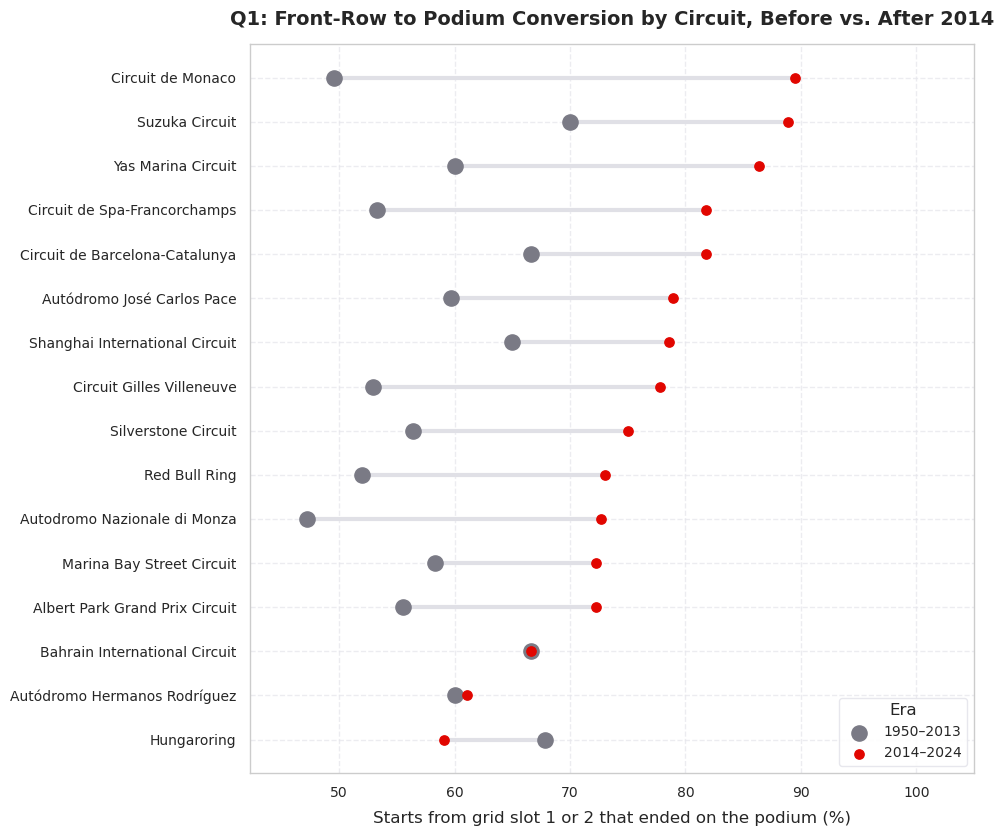

In [36]:
# Task 9.3: dumbbell chart, pre-hybrid vs. hybrid era
rates = q1_wide["rate"].sort_values(Q1_ERAS[1])
fig, ax = plt.subplots(figsize=(10, 0.42 * len(rates) + 1.8))
ax.hlines(rates.index, rates[Q1_ERAS[0]], rates[Q1_ERAS[1]], color=F1_PALETTE["light_gray"], linewidth=3, zorder=1)
ax.scatter(rates[Q1_ERAS[0]], rates.index, color=F1_PALETTE["gray"], s=120, zorder=2, label=Q1_ERAS[0])
ax.scatter(rates[Q1_ERAS[1]], rates.index, color=F1_PALETTE["crimson"], s=45, zorder=3, label=Q1_ERAS[1])
ax.set(title="Q1: Front-Row to Podium Conversion by Circuit, Before vs. After 2014",
       xlabel="Starts from grid slot 1 or 2 that ended on the podium (%)",
       xlim=(min(rates[Q1_ERAS].min()) - 5, 105))
ax.legend(loc="lower right", title="Era")
save_fig("de_q1_front_row_conversion")
plt.show()

### Q1 answer

**Front-row starts convert far more often in the hybrid era. The circuit ranking is not preserved: the circuits that convert best since 2014 are not the ones that converted best before.**

- **Overall level.** A start from grid slot 1 or 2 ended on the podium 56.3% of the time in 1950–2013 (991 of 1,759) and 76.2% in 2014–2024 (345 of 453). The rate rose at 14 of the 16 ranked circuits, was level at Bahrain and fell only at the Hungaroring.
- **Top circuits, 2014–2024.** Monaco (89.5%), Suzuka (88.9%) and Yas Marina (86.4%). The Hungaroring is last (59.1%).
- **Top circuits, 1950–2013.** Suzuka (70.0%), the Hungaroring (67.9%), then Barcelona and Bahrain (both 66.7%).
- **Does the ranking change?** Yes. Spearman ρ between the two eras is −0.08 (p = 0.76): knowing a circuit's rank before 2014 says nothing about its rank after. Monaco climbs from 15th to 1st and Spa from 12th to 4th; the Hungaroring falls from 2nd to 16th and Bahrain from 3rd to 14th.
- **Sensitivity: a pre-hybrid window as long as the hybrid one (2003–2013).** The level rise is smaller (67.0% to 76.2%) but still clear, and the ranking is still only loosely kept (ρ = 0.36, 14 circuits). The two pre-hybrid rankings disagree with each other (ρ = −0.22): over 1950–2013 the long-used circuits (Monza with 127 front-row starts, Monaco 119, Silverstone 94) are dominated by decades of different cars and layouts. Both windows give the same answer to the question: the hybrid era converts front-row starts more often and reorders the circuits.

**How far to trust it.** In 2014–2024 each circuit has 14 to 26 front-row starts, so one race moves a rate by 4 to 7 points. The rise in the overall level is solid; individual rank changes are mostly within that noise.

| | |
| :--- | :--- |
| **Joins** | `results` + `races` + `circuits`, already joined in `clean_df`. No qualifying data is needed |
| **Grain** | One row per driver per race. A front-row start is one such row; rates are aggregated per circuit and era |
| **Missing values** | None: every start has a grid slot. 17 races have fewer than two front-row starts, because a front-row car did not take the start (DEC-009) or was a shared car (DEC-034). The 1952 Italian GP lists two cars in each of slots 1 and 2; all four are kept as recorded. Circuits with fewer than 10 front-row starts in either era are not ranked |
| **Pre-race cutoff** | The grid slot is fixed before the start. `podium` is used only as the outcome |

The grid, not the qualifying order, defines the front row: grid penalties move cars between the two, and the starting grid is what the question asks about (DEC-035). Until the early 1970s the front row of the grid often held three or four cars; slots 1 and 2 are compared across eras, not the physical row.

## Task 10: Q2, Home Advantage Controlling for Grid

**Question.** Do drivers reach the podium more often at a circuit in their home country, compared with drivers who started from a similar grid position?

**DEC-012.** A race is a home race when `circuits.country` is one of the countries mapped from `drivers.nationality`. Edge cases:

- Country names follow `circuits.country` (`British` → `UK`, `American` → `USA`). The circuits table spells the USA two ways; `United States` is folded into `USA`.
- `Monegasque` → `Monaco`, and `East German` → `Germany`.
- Dual nationalities (`American-Italian`, `Argentine-Italian`) have two home countries.
- `Argentinian ` carries a trailing space in the raw table and is stripped.
- Fourteen nationalities, including Finnish, have no circuit in the data. Their drivers are always "away".

All seasons in `clean_df` are used. Grid is bucketed as 1, 2–3, 4–6, 7–10 and 11+; pit-lane starts fall in 11+ after the DEC-010 recoding.

In [37]:
# Task 10.1: nationality -> home country mapping and the home-race flag (DEC-012)
# Country names follow circuits.country. A dual nationality has two home countries.
NATIONALITY_TO_COUNTRIES: Dict[str, Tuple[str, ...]] = {
    "American": ("USA",), "American-Italian": ("USA", "Italy"), "Argentine": ("Argentina",),
    "Argentine-Italian": ("Argentina", "Italy"), "Argentinian": ("Argentina",), "Australian": ("Australia",),
    "Austrian": ("Austria",), "Belgian": ("Belgium",), "Brazilian": ("Brazil",), "British": ("UK",),
    "Canadian": ("Canada",), "Chilean": ("Chile",), "Chinese": ("China",), "Colombian": ("Colombia",),
    "Czech": ("Czech Republic",), "Danish": ("Denmark",), "Dutch": ("Netherlands",), "East German": ("Germany",),
    "Finnish": ("Finland",), "French": ("France",), "German": ("Germany",), "Hungarian": ("Hungary",),
    "Indian": ("India",), "Indonesian": ("Indonesia",), "Irish": ("Ireland",), "Italian": ("Italy",),
    "Japanese": ("Japan",), "Liechtensteiner": ("Liechtenstein",), "Malaysian": ("Malaysia",), "Mexican": ("Mexico",),
    "Monegasque": ("Monaco",), "New Zealander": ("New Zealand",), "Polish": ("Poland",), "Portuguese": ("Portugal",),
    "Rhodesian": ("Rhodesia",), "Russian": ("Russia",), "South African": ("South Africa",), "Spanish": ("Spain",),
    "Swedish": ("Sweden",), "Swiss": ("Switzerland",), "Thai": ("Thailand",), "Uruguayan": ("Uruguay",),
    "Venezuelan": ("Venezuela",),
}
CIRCUIT_COUNTRY_ALIASES: Dict[str, str] = {"United States": "USA"}  # circuits.country spells the USA two ways

q2_df = clean_df[GRAIN + ["year", "circuit_country", "grid", TARGET_COLUMN]].merge(
    cleaned_dataframes["drivers"][["driverId", "nationality"]], on="driverId", how="left", validate="many_to_one"
)
q2_df["nationality"] = q2_df["nationality"].str.strip()   # the raw table holds 'Argentinian ' with a trailing space
q2_df["circuit_country"] = q2_df["circuit_country"].replace(CIRCUIT_COUNTRY_ALIASES)
unmapped = set(q2_df["nationality"]) - set(NATIONALITY_TO_COUNTRIES)
assert not unmapped, f"Nationalities without a home country: {unmapped}"

q2_df["is_home"] = [country in NATIONALITY_TO_COUNTRIES[nat] for nat, country in zip(q2_df["nationality"], q2_df["circuit_country"])]
q2_df["is_home"] = q2_df["is_home"].astype(int)

circuit_countries = set(q2_df["circuit_country"])
no_home_circuit = sorted(nat for nat, countries in NATIONALITY_TO_COUNTRIES.items()
                         if nat in set(q2_df["nationality"]) and not circuit_countries.intersection(countries))
print(f"Home starts: {q2_df['is_home'].sum():,} of {len(q2_df):,} rows ({q2_df['is_home'].mean():.1%})")
print(f"Nationalities whose country never hosts a race in the data ({len(no_home_circuit)}): {', '.join(no_home_circuit)}")
display(q2_df[q2_df["is_home"] == 1].groupby("circuit_country").agg(
    home_starts=(TARGET_COLUMN, "size"), home_podiums=(TARGET_COLUMN, "sum"), drivers=("driverId", "nunique")
).sort_values("home_starts", ascending=False).T)

Home starts: 1,902 of 24,482 rows (7.8%)
Nationalities whose country never hosts a race in the data (14): Chilean, Colombian, Czech, Danish, Finnish, Indonesian, Irish, Liechtensteiner, New Zealander, Polish, Rhodesian, Thai, Uruguayan, Venezuelan


circuit_country,UK,Italy,Germany,France,Brazil,USA,Spain,Belgium,Japan,South Africa,Argentina,Canada,Austria,Australia,Mexico,Netherlands,Switzerland,Sweden,Monaco,Russia,Portugal,Hungary,India,China,Malaysia
home_starts,434,389,204,203,114,112,60,59,53,46,41,32,29,28,24,22,13,12,8,8,5,2,2,1,1
home_podiums,66,25,29,26,20,9,9,3,2,4,10,4,2,0,2,4,1,2,2,0,0,0,0,0,0
drivers,122,77,46,49,27,36,11,19,17,18,17,9,9,5,4,9,6,5,3,3,2,1,1,1,1


In [38]:
# Task 10.2: home vs. away podium rate within each grid bucket
GRID_BUCKET_EDGES: List[int] = [0, 1, 3, 6, 10, 99]
GRID_BUCKET_LABELS: List[str] = ["1", "2–3", "4–6", "7–10", "11+"]
q2_df["grid_bucket"] = pd.cut(q2_df["grid"], bins=GRID_BUCKET_EDGES, labels=GRID_BUCKET_LABELS)
q2_df["venue"] = np.where(q2_df["is_home"] == 1, "Home", "Away")
assert q2_df["grid_bucket"].notna().all(), "A grid position falls outside the buckets"

raw_gap = q2_df.groupby("venue")[TARGET_COLUMN].mean() * 100
print(f"Before controlling for grid: home {raw_gap['Home']:.2f}% vs. away {raw_gap['Away']:.2f}% "
      f"({raw_gap['Home'] - raw_gap['Away']:+.2f} points)")
print("Share of starts from the first three grid slots:",
      (q2_df["grid"].le(3).groupby(q2_df["venue"]).mean() * 100).round(1).to_dict())

q2_rates = rate_table(q2_df, ["grid_bucket", "venue"], TARGET_COLUMN)
q2_wide = q2_rates.pivot(index="grid_bucket", columns="venue", values=["n", "events", "rate"])
q2_wide[("rate", "Home − Away")] = q2_wide[("rate", "Home")] - q2_wide[("rate", "Away")]
display(q2_wide.round(2))

Before controlling for grid: home 11.57% vs. away 13.75% (-2.18 points)
Share of starts from the first three grid slots: {'Away': 13.7, 'Home': 11.9}


n          events         rate                   
venue           Away    Home    Away  Home   Away   Home Home − Away
grid_bucket                                                         
1             1024.0    79.0   666.0  48.0  65.04  60.76       -4.28
2–3           2070.0   148.0  1056.0  79.0  51.01  53.38        2.36
4–6           3101.0   223.0   805.0  59.0  25.96  26.46        0.50
7–10          4080.0   327.0   375.0  23.0   9.19   7.03       -2.16
11+          12305.0  1125.0   203.0  11.0   1.65   0.98       -0.67

In [39]:
# Task 10.3: is the home effect significant once grid is held fixed?
def home_logit(df: pd.DataFrame, grid_term: str) -> Dict[str, float]:
    """Logistic regression podium ~ is_home + grid_term, standard errors clustered by driver."""
    fit = smf.logit(f"{TARGET_COLUMN} ~ is_home + {grid_term}", data=df).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": df["driverId"]})
    low, high = np.exp(fit.conf_int().loc["is_home"])
    return {"rows": len(df), "home odds ratio": np.exp(fit.params["is_home"]), "95% CI low": low, "95% CI high": high,
            "p-value": fit.pvalues["is_home"]}


# Cochran–Mantel–Haenszel: one 2x2 table (venue x podium) per grid bucket
cmh = StratifiedTable([
    pd.crosstab(bucket_df["venue"], bucket_df[TARGET_COLUMN]).loc[["Home", "Away"], [1, 0]].to_numpy()
    for _, bucket_df in q2_df.groupby("grid_bucket", observed=True)
])
cmh_low, cmh_high = cmh.oddsratio_pooled_confint()

q2_df["grid_capped"] = q2_df["grid"].clip(upper=21)               # exact grid slot, 21+ pooled
home_drivers = q2_df.groupby("driverId")["is_home"].transform("max") == 1

q2_tests = pd.DataFrame({
    "CMH test, grid buckets": {"rows": len(q2_df), "home odds ratio": cmh.oddsratio_pooled, "95% CI low": cmh_low,
                               "95% CI high": cmh_high, "p-value": cmh.test_null_odds(correction=True).pvalue},
    "Logit, grid buckets": home_logit(q2_df, "C(grid_bucket)"),
    "Logit, exact grid slot": home_logit(q2_df, "C(grid_capped)"),
    "Logit, grid buckets, drivers with a home race only": home_logit(q2_df[home_drivers], "C(grid_bucket)"),
    "Logit, grid buckets + season decade": home_logit(q2_df.assign(decade=q2_df["year"] // 10 * 10), "C(grid_bucket) + C(decade)"),
}).T
display(q2_tests.round(4))
print(f"Do the buckets share one odds ratio? Breslow–Day p = {cmh.test_equal_odds().pvalue:.3f}")

,rows,home odds ratio,95% CI low,95% CI high,p-value
"CMH test, grid buckets",24482.0,0.9082,0.7626,1.0817,0.3052
"Logit, grid buckets",24482.0,0.9100,0.7465,1.1092,0.3504
"Logit, exact grid slot",24482.0,0.9222,0.7561,1.1249,0.4243
"Logit, grid buckets, drivers with a home race only",20354.0,0.8988,0.7398,1.0921,0.2830
"Logit, grid buckets + season decade",24482.0,0.9123,0.7419,1.1219,0.3844


Do the buckets share one odds ratio? Breslow–Day p = 0.316


[FIGURE SAVED] figures/de_q2_home_advantage.png


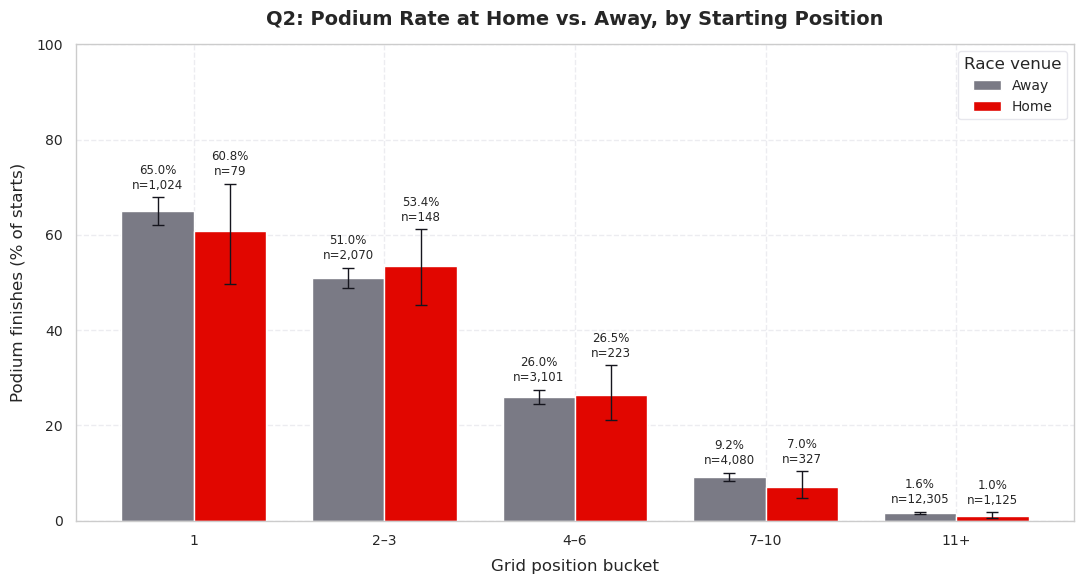

In [40]:
# Task 10.4: grouped bars with Wilson 95% intervals
plot_df = q2_rates.set_index(["grid_bucket", "venue"])
x = np.arange(len(GRID_BUCKET_LABELS))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(11, 6))
for offset, venue, color in [(-bar_width / 2, "Away", F1_PALETTE["gray"]), (bar_width / 2, "Home", F1_PALETTE["crimson"])]:
    rows = plot_df.xs(venue, level="venue").loc[GRID_BUCKET_LABELS]
    bars = ax.bar(x + offset, rows["rate"], bar_width, color=color, label=venue,
                  yerr=[rows["rate"] - rows["ci_low"], rows["ci_high"] - rows["rate"]], capsize=4,
                  error_kw={"ecolor": F1_PALETTE["dark"], "elinewidth": 1})
    ax.bar_label(bars, labels=[f"{rate:.1f}%\nn={n:,}" for rate, n in zip(rows["rate"], rows["n"])], padding=4, fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(GRID_BUCKET_LABELS)
ax.set(title="Q2: Podium Rate at Home vs. Away, by Starting Position", xlabel="Grid position bucket",
       ylabel="Podium finishes (% of starts)", ylim=(0, 100))
ax.legend(title="Race venue")
save_fig("de_q2_home_advantage")
plt.show()

### Q2 answer

**No. Once starting position is held fixed, there is no detectable home advantage.**

- **Before controlling for grid** the home rate is lower: 11.57% at home against 13.75% away. That gap comes from where home drivers start, not from the venue: 11.9% of home starts are from the first three grid slots, against 13.7% of away starts.
- **Within grid buckets** the difference goes both ways: −4.3 points from pole, +2.4 from grid 2–3, +0.5 from 4–6, −2.2 from 7–10 and −0.7 from 11+. Every pair of intervals overlaps.
- **Significance.** The Cochran–Mantel–Haenszel pooled odds ratio for home is 0.91 (95% CI 0.76 to 1.08, p = 0.31). The logistic regression `podium ~ is_home + C(grid_bucket)` agrees: 0.91 (0.75 to 1.11, p = 0.35).
- **Checks.** The result holds with the exact grid slot instead of buckets (0.92), with only drivers who ever had a home race (0.90), and with season decade added (0.91). The Breslow–Day test (p = 0.32) gives no sign that the effect differs between buckets.

The interval rules out a large home advantage: at most about 8% higher odds. It does not rule out a home effect on qualifying itself, because conditioning on grid removes that channel by design.

| | |
| :--- | :--- |
| **Joins** | `results` + `races` + `circuits` (in `clean_df`) + `drivers` on `driverId`, many-to-one |
| **Grain** | One row per driver per race: 24,482 starts, of which 1,902 (7.8%) are home starts |
| **Missing values** | Every nationality is mapped (asserted) and no row lacks a grid slot. Drivers from countries without a circuit stay in the away group; the restricted model above shows this does not drive the result |
| **Pre-race cutoff** | Nationality, circuit country and grid slot are all known before the start. `podium` is the outcome |

Rows are not independent: the same driver appears many times, so the regression standard errors are clustered by driver.

## Task 11: Q3, Mechanical Retirements by Constructor

**Question.** Which constructors have the highest mechanical-retirement rate in 2014–2021 and in 2022–2024?

**DEC-036 (replaces DEC-013).** Each of the 139 status labels is mapped to one of four categories. A retirement is *mechanical* when the label names a failed car component or system. The instructors ruled on the borderline labels (Piazza): `Puncture`, `Tyre`, `Tyre puncture`, `Fire` and `Safety belt` are mechanical, and `Refuelling` is not. The fuel-load labels (`Out of fuel`, `Fuel`) and `Fuel rig`, the refuelling equipment, are not in that ruling. They are kept with `Refuelling`.

| Category | Examples |
| :--- | :--- |
| finished | `Finished`, `+1 Lap` |
| mechanical | `Engine`, `Gearbox`, `Power Unit`, `Hydraulics`, `Brakes`, `Puncture`, `Tyre` |
| accident/driver | `Collision`, `Accident`, `Spun off`, `Illness` |
| regulatory/other | `Disqualified`, generic `Retired` and `Withdrew`, `Refuelling`, `Out of fuel` |

The rate is mechanical retirements divided by **race starts**. `clean_df` already holds starters only (DEC-009). A constructor is ranked in an era only if it has at least 40 starts there, about one season of a two-car team.

In [41]:
# Task 11.1: status -> category mapping (DEC-036)
# 'mechanical' means the status names a failed car component or system, plus the instructor ruling on tyres, fire and safety belts.
ACCIDENT_DRIVER_STATUSES: Set[str] = {
    "Accident", "Collision", "Collision damage", "Spun off", "Fatal accident", "Stalled",
    "Injured", "Injury", "Eye injury", "Physical", "Driver unwell", "Illness",
}
REGULATORY_OTHER_STATUSES: Set[str] = {
    # steward and rule decisions
    "Disqualified", "Excluded", "Underweight", "107% Rule", "Did not qualify", "Did not prequalify", "Safety", "Safety concerns",
    # generic labels that give no cause
    "Retired", "Withdrew", "Not classified", "Not restarted", "Handling", "Damage", "Debris",
    # fuel load and refuelling: not mechanical (instructor ruling on Refuelling; Fuel rig is the refuelling equipment)
    "Out of fuel", "Fuel", "Refuelling", "Fuel rig",
}
MECHANICAL_STATUSES: Set[str] = {
    # power unit and its ancillaries
    "Engine", "Engine fire", "Engine misfire", "Power Unit", "Power loss", "ERS", "Turbo", "Supercharger", "Battery",
    "Ignition", "Injection", "Distributor", "Magneto", "Spark plugs", "Alternator", "Crankshaft", "Exhaust", "Throttle",
    "Electrical", "Electronics", "Launch control", "Pneumatics",
    # cooling, oil and fuel systems
    "Overheating", "Radiator", "Cooling system", "Water leak", "Water pressure", "Water pump", "Water pipe",
    "Oil leak", "Oil pressure", "Oil pump", "Oil line", "Oil pipe", "Fuel system", "Fuel pressure", "Fuel pump",
    "Fuel leak", "Fuel pipe", "Fire", "Heat shield fire",
    # drivetrain
    "Gearbox", "Transmission", "Clutch", "Differential", "Driveshaft", "Halfshaft", "CV joint", "Axle", "Drivetrain", "Hydraulics",
    # chassis, suspension, brakes, wheels and bodywork
    "Suspension", "Steering", "Track rod", "Brakes", "Brake duct", "Wheel", "Wheel nut", "Wheel rim", "Wheel bearing",
    "Chassis", "Front wing", "Rear wing", "Broken wing", "Undertray", "Vibrations", "Seat", "Driver Seat", "Safety belt",
    # tyres: mechanical by instructor ruling
    "Puncture", "Tyre", "Tyre puncture",
    # unspecified technical failure
    "Mechanical", "Technical",
}
FINISHED_PATTERN = re.compile(r"^(Finished|\+\d+ Laps?)$")
STATUS_CATEGORIES: List[str] = ["finished", "mechanical", "accident/driver", "regulatory/other"]


def categorise_status(status_text: str) -> str:
    """Map one status label to finished / mechanical / accident/driver / regulatory/other."""
    if FINISHED_PATTERN.match(status_text):
        return "finished"
    if status_text in MECHANICAL_STATUSES:
        return "mechanical"
    if status_text in ACCIDENT_DRIVER_STATUSES:
        return "accident/driver"
    if status_text in REGULATORY_OTHER_STATUSES:
        return "regulatory/other"
    return "unmapped"


status_map = cleaned_dataframes["status"].assign(category=lambda d: d["status"].map(categorise_status))
assert (status_map["category"] != "unmapped").all(), f"Unmapped statuses: {status_map.loc[status_map['category'] == 'unmapped', 'status'].tolist()}"
assert not (MECHANICAL_STATUSES & ACCIDENT_DRIVER_STATUSES) and not (MECHANICAL_STATUSES & REGULATORY_OTHER_STATUSES) \
    and not (ACCIDENT_DRIVER_STATUSES & REGULATORY_OTHER_STATUSES), "A status sits in two categories"

# Instructor ruling on Q3 (Piazza): these five are mechanical, Refuelling is not
PIAZZA_MECHANICAL: Set[str] = {"Puncture", "Tyre", "Tyre puncture", "Fire", "Safety belt"}
assert PIAZZA_MECHANICAL <= MECHANICAL_STATUSES and "Refuelling" not in MECHANICAL_STATUSES, "The mapping breaks the instructor ruling"
display(status_map.groupby("category").agg(statuses=("status", "size")).reindex(STATUS_CATEGORIES).T)

category,finished,mechanical,accident/driver,regulatory/other
statuses,34,74,12,19


In [42]:
# Task 11.2: mechanical-retirement rate per constructor and era
Q3_ERAS: Dict[str, Tuple[int, int]] = {"2014–2021": (2014, 2021), "2022–2024": (2022, 2024)}
MIN_CONSTRUCTOR_STARTS: int = 40   # about one season of a two-car team

q3_df = (
    clean_df.loc[clean_df["year"] >= 2014, GRAIN + ["constructorId", "year", "statusId", "status"]]
    .merge(status_map[["statusId", "category"]], on="statusId", how="left", validate="many_to_one")
    .merge(cleaned_dataframes["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}),
           on="constructorId", how="left", validate="many_to_one")
)
q3_df["era"] = np.select([q3_df["year"].between(*years) for years in Q3_ERAS.values()], list(Q3_ERAS), default="")
assert (q3_df["era"] != "").all() and q3_df["category"].notna().all() and q3_df["constructor"].notna().all()
q3_df["mechanical"] = (q3_df["category"] == "mechanical").astype(int)

# What ends a race start in each era, and which statuses carry the mechanical count
display((pd.crosstab(q3_df["era"], q3_df["category"], normalize="index") * 100).round(2)[STATUS_CATEGORIES]
        .assign(starts=q3_df.groupby("era").size()))
display(q3_df[q3_df["mechanical"] == 1].groupby(["era", "status"]).size().unstack("era", fill_value=0)
        .sort_values("2014–2021", ascending=False).head(10).T)

q3_rates = rate_table(q3_df, ["era", "constructor"], "mechanical")
below_threshold = q3_rates[q3_rates["n"] < MIN_CONSTRUCTOR_STARTS]
print(f"Dropped for fewer than {MIN_CONSTRUCTOR_STARTS} starts in an era: "
      + ", ".join(f"{row.constructor} ({row.era}, {row.n} starts)" for row in below_threshold.itertuples()))
q3_rates = q3_rates[q3_rates["n"] >= MIN_CONSTRUCTOR_STARTS].sort_values(["era", "rate"], ascending=[True, False])
for era in Q3_ERAS:
    display(q3_rates[q3_rates["era"] == era].set_index("constructor").drop(columns="era")
            .rename(columns={"n": "starts", "events": "mechanical retirements"}).round(2))

category,finished,mechanical,accident/driver,regulatory/other,starts
era,,,,,
2014–2021,81.97,9.77,6.69,1.57,3245
2022–2024,86.17,5.92,6.66,1.26,1352


status,Engine,Brakes,Gearbox,Power Unit,Suspension,Electrical,Wheel,Power loss,Hydraulics,Oil leak
era,,,,,,,,,,
2014–2021,58,44,32,32,24,13,11,10,9,8
2022–2024,21,4,8,7,1,1,0,2,5,2


Dropped for fewer than 40 starts in an era: Caterham (2014–2021, 33 starts), Marussia (2014–2021, 31 starts)


,starts,mechanical retirements,rate,ci_low,ci_high
constructor,,,,,
Lotus F1,75,15,20.00,12.51,30.41
Toro Rosso,242,40,16.53,12.38,21.72
Renault,199,28,14.07,9.92,19.58
McLaren,316,43,13.61,10.26,17.83
Red Bull,318,36,11.32,8.29,15.27
Sauber,199,22,11.06,7.41,16.17
Haas F1 Team,241,23,9.54,6.44,13.91
Racing Point,75,7,9.33,4.59,18.03
AlphaTauri,77,7,9.09,4.47,17.60


,starts,mechanical retirements,rate,ci_low,ci_high
constructor,,,,,
Alfa Romeo,88,11,12.50,7.13,21.01
Alpine F1 Team,135,14,10.37,6.28,16.66
AlphaTauri,88,7,7.95,3.91,15.52
Williams,134,8,5.97,3.06,11.34
Aston Martin,134,7,5.22,2.55,10.39
Ferrari,134,7,5.22,2.55,10.39
Haas F1 Team,135,7,5.19,2.53,10.32
Mercedes,136,6,4.41,2.04,9.29
RB F1 Team,48,2,4.17,1.15,13.98


[FIGURE SAVED] figures/de_q3_mechanical_retirements.png


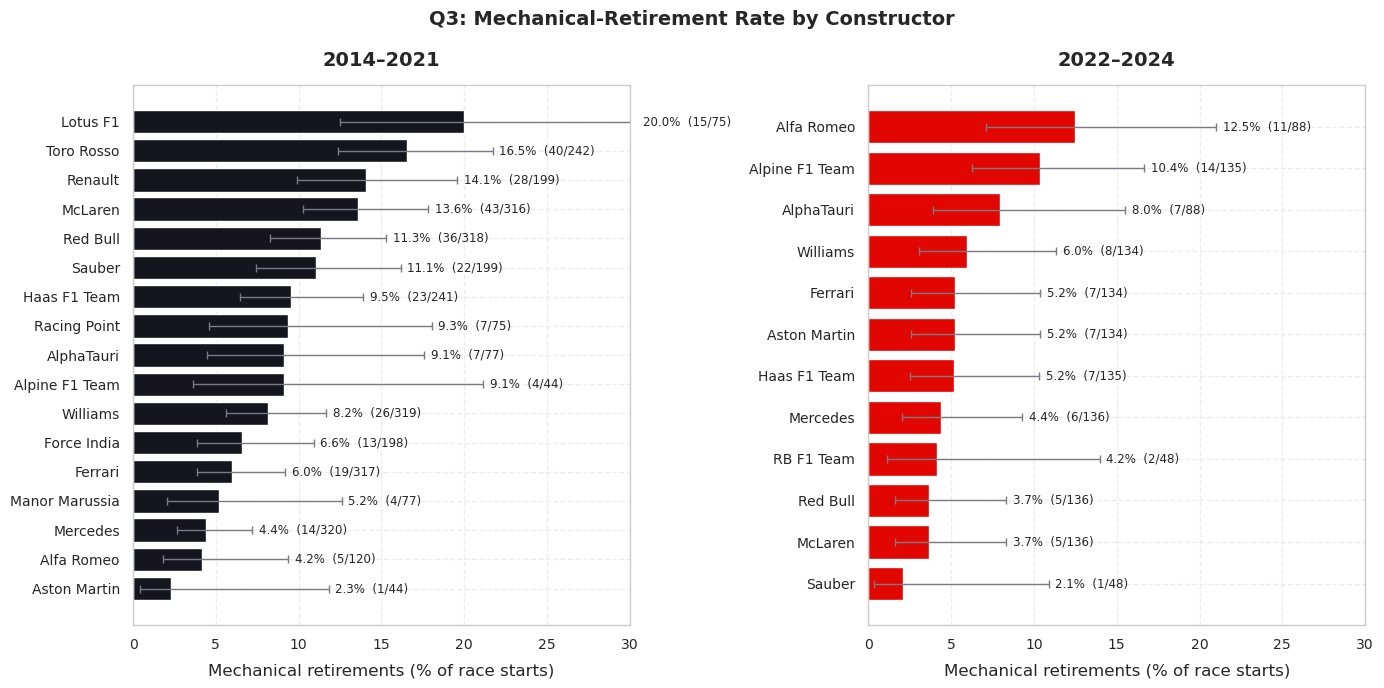

In [43]:
# Task 11.3: constructors ranked within each era
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, era, color in zip(axes, Q3_ERAS, [F1_PALETTE["dark"], F1_PALETTE["crimson"]]):
    rows = q3_rates[q3_rates["era"] == era].sort_values("rate")
    bars = ax.barh(rows["constructor"], rows["rate"], color=color,
                   xerr=[rows["rate"] - rows["ci_low"], rows["ci_high"] - rows["rate"]],
                   error_kw={"ecolor": F1_PALETTE["gray"], "elinewidth": 1, "capsize": 3})
    for bar, row in zip(bars, rows.itertuples()):
        ax.text(row.ci_high + 0.4, bar.get_y() + bar.get_height() / 2, f"{row.rate:.1f}%  ({row.events}/{row.n})",
                va="center", fontsize=8.5)
    ax.set(title=era, xlabel="Mechanical retirements (% of race starts)", xlim=(0, 30))
fig.suptitle("Q3: Mechanical-Retirement Rate by Constructor", fontsize=14, fontweight="bold")
save_fig("de_q3_mechanical_retirements")
plt.show()

n              events                rate                 
era                                       2014–2021 2022–2024 2014–2021 2022–2024 2014–2021 2022–2024 change
team                                                                                                        
Lotus F1 / Renault / Alpine                   318.0     135.0      47.0      14.0     14.78     10.37  -4.41
Toro Rosso / AlphaTauri / RB                  319.0     136.0      47.0       9.0     14.73      6.62  -8.12
McLaren                                       316.0     136.0      43.0       5.0     13.61      3.68  -9.93
Red Bull                                      318.0     136.0      36.0       5.0     11.32      3.68  -7.64
Haas F1 Team                                  241.0     135.0      23.0       7.0      9.54      5.19  -4.36
Sauber / Alfa Romeo                           319.0     136.0      27.0      12.0      8.46      8.82   0.36
Williams                                      319.0     134.0      26.0       8.0      8.15      5.97  -2.18
Force India / Racing Point / Aston Martin     317.0     134.0      21.0       7.0      6.62      5.22  -1.40
Ferrari                                       317.0     134.0      19.0       7.0      5.99      5.22  -0.77
Mercedes                                      320.0     136.0      14.0       6.0      4.38      4.41   0.04

Teams in one era only (not in the chart): Marussia / Manor
Spearman rho between the two eras across 10 teams = 0.24 (p = 0.51)
[FIGURE SAVED] figures/de_q3_mechanical_retirements_lineage.png


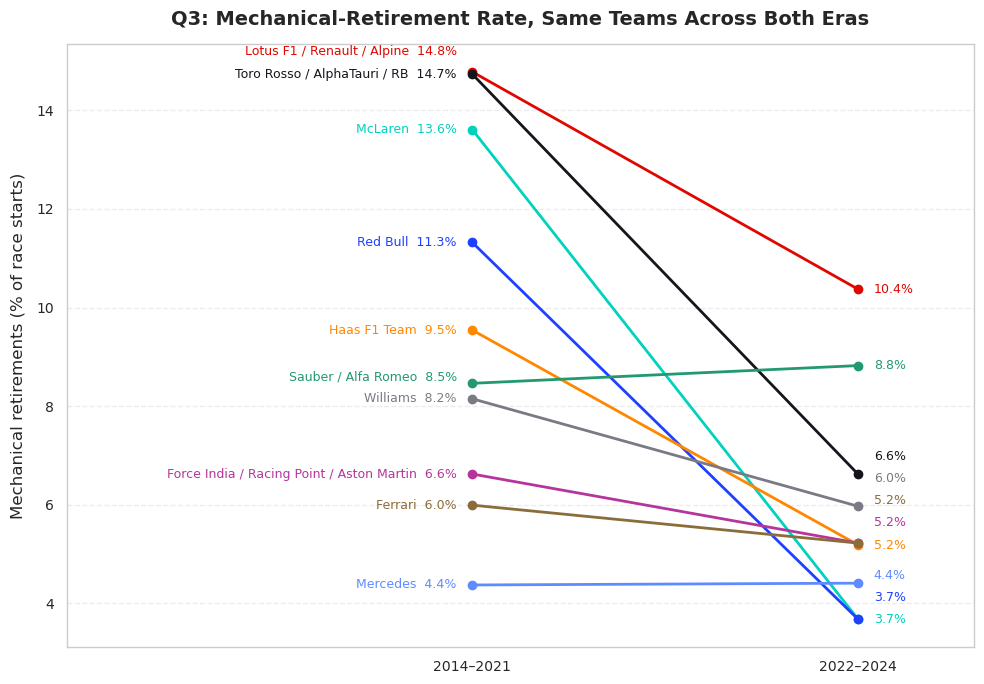

In [44]:
# Task 11.4: the same teams across both eras, with renamed teams merged (DEC-014)
CONSTRUCTOR_LINEAGE: Dict[str, str] = {
    "Toro Rosso": "Toro Rosso / AlphaTauri / RB", "AlphaTauri": "Toro Rosso / AlphaTauri / RB", "RB F1 Team": "Toro Rosso / AlphaTauri / RB",
    "Force India": "Force India / Racing Point / Aston Martin", "Racing Point": "Force India / Racing Point / Aston Martin",
    "Aston Martin": "Force India / Racing Point / Aston Martin",
    "Lotus F1": "Lotus F1 / Renault / Alpine", "Renault": "Lotus F1 / Renault / Alpine", "Alpine F1 Team": "Lotus F1 / Renault / Alpine",
    "Sauber": "Sauber / Alfa Romeo", "Alfa Romeo": "Sauber / Alfa Romeo",
    "Marussia": "Marussia / Manor", "Manor Marussia": "Marussia / Manor",
}
q3_df["team"] = q3_df["constructor"].replace(CONSTRUCTOR_LINEAGE)

lineage_rates = rate_table(q3_df, ["era", "team"], "mechanical")
lineage_wide = lineage_rates[lineage_rates["n"] >= MIN_CONSTRUCTOR_STARTS].pivot(index="team", columns="era", values=["n", "events", "rate"])
only_one_era = lineage_wide[lineage_wide["rate"].isna().any(axis=1)].index.tolist()
lineage_wide = lineage_wide.dropna()
lineage_wide[("rate", "change")] = lineage_wide[("rate", "2022–2024")] - lineage_wide[("rate", "2014–2021")]
lineage_wide = lineage_wide.sort_values(("rate", "2014–2021"), ascending=False)
rho, p_value = stats.spearmanr(lineage_wide[("rate", "2014–2021")], lineage_wide[("rate", "2022–2024")])
display(lineage_wide.round(2))
print(f"Teams in one era only (not in the chart): {', '.join(only_one_era)}")
print(f"Spearman rho between the two eras across {len(lineage_wide)} teams = {rho:.2f} (p = {p_value:.2f})")

def spread_labels(values: pd.Series, min_gap: float) -> pd.Series:
    """Move label heights apart so that no two sit closer than min_gap."""
    heights: List[float] = []
    ordered = values.sort_values()
    for value in ordered:
        heights.append(value if not heights else max(value, heights[-1] + min_gap))
    return pd.Series(heights, index=ordered.index)


left_y = spread_labels(lineage_wide[("rate", "2014–2021")], min_gap=0.45)
right_y = spread_labels(lineage_wide[("rate", "2022–2024")], min_gap=0.45)
slope_palette = [F1_PALETTE[c] for c in ["crimson", "dark", "teal", "blue", "orange", "green", "gray"]] + ["#B6359C", "#8A6D3B", "#5E8BFF"]
fig, ax = plt.subplots(figsize=(10, 7))
for (team, row), color in zip(lineage_wide["rate"].iterrows(), slope_palette):
    ax.plot([0, 1], [row["2014–2021"], row["2022–2024"]], marker="o", color=color, linewidth=2)
    ax.text(-0.04, left_y[team], f"{team}  {row['2014–2021']:.1f}%", ha="right", va="center", fontsize=9, color=color)
    ax.text(1.04, right_y[team], f"{row['2022–2024']:.1f}%", ha="left", va="center", fontsize=9, color=color)
ax.set_xticks([0, 1])
ax.set_xticklabels(list(Q3_ERAS))
ax.set(title="Q3: Mechanical-Retirement Rate, Same Teams Across Both Eras", ylabel="Mechanical retirements (% of race starts)",
       xlim=(-1.05, 1.3))
ax.grid(axis="x", visible=False)
save_fig("de_q3_mechanical_retirements_lineage")
plt.show()

In [45]:
# Task 11.5: sensitivity. Does the ranking move if the generic 'Retired' label counts as mechanical?
q3_df["mechanical_broad"] = ((q3_df["mechanical"] == 1) | (q3_df["status"] == "Retired")).astype(int)
broad_rates = rate_table(q3_df, ["era", "constructor"], "mechanical_broad")
sensitivity = q3_rates.merge(broad_rates[["era", "constructor", "events", "rate"]], on=["era", "constructor"], suffixes=("_strict", "_broad"))
for col in ["rate_strict", "rate_broad"]:
    sensitivity[col.replace("rate", "rank")] = sensitivity.groupby("era")[col].rank(ascending=False, method="min").astype(int)

print("'Retired' rows per era:", q3_df[q3_df["status"] == "Retired"].groupby("era").size().to_dict())
for era, rows in sensitivity.groupby("era"):
    rho, _ = stats.spearmanr(rows["rate_strict"], rows["rate_broad"])
    print(f"{era}: Spearman rho between the strict and broad rankings = {rho:.2f}")
display(sensitivity.sort_values(["era", "rank_strict"]).set_index(["era", "constructor"])
        [["n", "events_strict", "rate_strict", "rank_strict", "events_broad", "rate_broad", "rank_broad"]].round(2))

'Retired' rows per era: {'2014–2021': 37, '2022–2024': 12}
2014–2021: Spearman rho between the strict and broad rankings = 0.97
2022–2024: Spearman rho between the strict and broad rankings = 0.66


n  events_strict  rate_strict  rank_strict  events_broad  rate_broad  rank_broad
era       constructor                                                                                       
2014–2021 Lotus F1         75             15        20.00            1            18       24.00           1
          Toro Rosso      242             40        16.53            2            44       18.18           2
          Renault         199             28        14.07            3            30       15.08           4
          McLaren         316             43        13.61            4            48       15.19           3
          Red Bull        318             36        11.32            5            37       11.64           7
          Sauber          199             22        11.06            6            26       13.07           5
          Haas F1 Team    241             23         9.54            7            29       12.03           6
          Racing Point     75              7         9.33            8             7        9.33          10
          AlphaTauri       77              7         9.09            9             8       10.39           8
          Alpine F1 Team   44              4         9.09            9             4        9.09          11
          Williams        319             26         8.15           11            30        9.40           9
          Force India     198             13         6.57           12            13        6.57          13
          Ferrari         317             19         5.99           13            19        5.99          14
          Manor Marussia   77              4         5.19           14             6        7.79          12
          Mercedes        320             14         4.38           15            15        4.69          15
          Alfa Romeo      120              5         4.17           16             5        4.17          17
          Aston Martin     44              1         2.27           17             2        4.55          16
2022–2024 Alfa Romeo       88             11        12.50            1            11       12.50           1
          Alpine F1 Team  135             14        10.37            2            14       10.37           3
          AlphaTauri       88              7         7.95            3             7        7.95           5
          Williams        134              8         5.97            4            11        8.21           4
          Aston Martin    134              7         5.22            5             8        5.97           8
          Ferrari         134              7         5.22            5             9        6.72           6
          Haas F1 Team    135              7         5.19            7             7        5.19           9
          Mercedes        136              6         4.41            8             6        4.41          10
          RB F1 Team       48              2         4.17            9             5       10.42           2
          McLaren         136              5         3.68           10             5        3.68          12
          Red Bull        136              5         3.68           10             6        4.41          10
          Sauber           48              1         2.08           12             3        6.25           7

### Q3 answer

**2014–2021: Lotus F1, Toro Rosso and Renault. 2022–2024: Alfa Romeo, Alpine and AlphaTauri.**

| Era | Highest mechanical-retirement rates | Lowest |
| :--- | :--- | :--- |
| 2014–2021 | Lotus F1 20.0% (15 of 75), Toro Rosso 16.5% (40 of 242), Renault 14.1% (28 of 199), McLaren 13.6% (43 of 316) | Aston Martin 2.3% (1 of 44), Alfa Romeo 4.2% (5 of 120), Mercedes 4.4% (14 of 320) |
| 2022–2024 | Alfa Romeo 12.5% (11 of 88), Alpine 10.4% (14 of 135), AlphaTauri 8.0% (7 of 88) | Sauber 2.1% (1 of 48), Red Bull and McLaren 3.7% (5 of 136) |

- **Reliability improved across the field.** Mechanical retirements fell from 9.77% of starts in 2014–2021 to 5.92% in 2022–2024.
- **Tyre failures count as mechanical** (instructor ruling, DEC-036). They add 11 retirements in 2014–2021 (7 `Puncture`, 4 `Tyre`) and none in 2022–2024. The top three of each era are the same with or without them.
- **Same teams across eras (DEC-014).** With renamed teams merged, Lotus F1 / Renault / Alpine is the least reliable team in both eras (14.8%, then 10.4%). McLaren improved most, from 13.6% to 3.7%. Only Sauber / Alfa Romeo (+0.4 points) and Mercedes (level, 4.4%) did not improve. The ordering of teams is not stable between eras (Spearman ρ = 0.24, p = 0.51).
- **Sensitivity to the generic `Retired` label** (37 and 12 rows). Counting it as mechanical leaves the 2014–2021 ranking almost unchanged (ρ = 0.97, same top two). In 2022–2024 Alfa Romeo stays first, but the order below it moves (ρ = 0.66): RB F1 Team jumps from 9th to 2nd on 3 `Retired` rows in 48 starts.

**How far to trust it.** The intervals are wide, especially in 2022–2024, where the top three are separated by 4 to 7 retirements. The leaders are clear; the middle of each ranking is not.

| | |
| :--- | :--- |
| **Joins** | `results` + `races` (in `clean_df`) + `status` on `statusId` + `constructors` on `constructorId`, both many-to-one |
| **Grain** | One row per driver per race start, aggregated per constructor and era. 4,597 starts from 2014 on |
| **Missing values** | Every status is mapped (asserted) and every row has a status and a constructor. Caterham and Marussia have fewer than 40 starts in 2014–2021 and are not ranked |
| **Pre-race cutoff** | `status` is recorded after the race and is used here only as the outcome. As a model feature it would be allowed only as a lagged aggregate of earlier races |

One limit: a status such as `Front wing` or `Suspension` names the part that failed, not why. Some of those failures follow contact, so the mapping can still count a few accident-related retirements as mechanical. The same holds for `Puncture`, which can follow contact with another car or debris.

---
# 5. Step 4: Feature Engineering (M3)

Build `model_df`: one row per `(raceId, driverId)` with the identifiers, the `podium` target and 21 features that are all known after qualifying and before the start.

Two rules hold for every feature:

- **Nothing from the current race.** Outcome columns (`positionOrder`, `points`, `podium`) enter only through aggregates of *earlier* races: rows are sorted by date and shifted by one race before any rolling or expanding window is taken.
- **Missing stays missing.** Where a feature has no value (no qualifying record, a driver's first race), it is left as `NaN`. Imputation is a preprocessing choice and belongs to Step 5, where it is fitted on the training seasons only.

## Task 12: Feature Construction

Each feature group has its own small function; `build_feature_table()` chains them. Keeping the build in one function lets Task 13 re-run it on deliberately corrupted inputs.

| Group | Features | Notes |
| :--- | :--- | :--- |
| grid | `grid`, `pit_start`, `front_row`, `teammate_grid_diff` | `teammate_grid_diff` is missing when the constructor entered one car |
| qualifying | `quali_position`, `gap_to_pole`, `q3_reached`, `missing_quali_flag` | **DEC-017.** Left missing where the source has no qualifying record. A gap above 100% is a recording error and is set to missing (one row: 1995 Japanese GP, 1,002.64 s) |
| driver form | rolling podium rate and average finish over 5 races, career podium rate | Missing for a driver's first race |
| constructor form | rolling podium rate and points share over 5 races, all cars combined | A renamed team starts a new history |
| standings | driver and constructor points and rank entering the race | From the standings table at the previous round of the same season |
| context | `field_size`, `round`, `is_home_race`, `circuit_historical_podium_rate` | **DEC-018.** The circuit rate is the *driver's* record at this circuit; across all drivers it would only restate the field size |

**DEC-015, points as shares.** A win was worth 8 to 10 points until 2009 and 25 from 2010. Raw points would mean something different in the training seasons than in validation and test, so every points feature is a share: of all points awarded in the constructor's last 5 races, or of the championship leader's total.

In [46]:
# Task 12.1: base table for the features
from sklearn.metrics import average_precision_score, roc_auc_score

ROLLING_WINDOW: int = 5
# Outcome columns enter the features only through aggregates of earlier races, never from the current race
OUTCOME_COLUMNS: List[str] = ["positionOrder", "points", TARGET_COLUMN]

feature_base = (
    clean_df[IDENTIFIER_COLUMNS + ["round", "circuitId", "circuit_country", "grid", "pit_start", "field_size"] + OUTCOME_COLUMNS]
    .sort_values(["date", "raceId", "driverId"])
    .reset_index(drop=True)
)
# shift(1) within a driver or constructor is only "strictly earlier" if no two of its rows share a date
assert not cleaned_dataframes["races"]["date"].duplicated().any(), "Two races share a date"
assert not feature_base.duplicated(subset=["driverId", "date"]).any(), "A driver has two rows on one date"
print(f"feature_base: {len(feature_base):,} rows, sorted by date | rolling window: last {ROLLING_WINDOW} races")

feature_base: 24,482 rows, sorted by date | rolling window: last 5 races


In [47]:
# Task 12.2: grid features
def add_grid_features(df: pd.DataFrame) -> pd.DataFrame:
    """front_row, and grid slot relative to the average slot of the driver's teammates in the same race."""
    out = df.copy()
    out["front_row"] = out["grid"].isin([1, 2]).astype(int)
    team_grid = out.groupby(["raceId", "constructorId"])["grid"]
    n_cars, grid_sum = team_grid.transform("size"), team_grid.transform("sum")
    teammate_mean = (grid_sum - out["grid"]) / (n_cars - 1).where(n_cars > 1)
    out["teammate_grid_diff"] = out["grid"] - teammate_mean   # negative = starts ahead of teammates; NaN = no teammate
    return out

In [48]:
# Task 12.3: qualifying features (DEC-017)
MAX_VALID_GAP_PCT: float = 100.0   # a lap more than twice as slow as pole is a recording error, not a lap time


def add_qualifying_features(df: pd.DataFrame, quali: pd.DataFrame) -> pd.DataFrame:
    """quali_position, gap_to_pole (% slower than the fastest qualifier), q3_reached, missing_quali_flag."""
    q = quali[GRAIN + ["quali_position", "q1", "q2", "q3"]].copy()
    q["best_time"] = q[["q1", "q2", "q3"]].min(axis=1)
    q["gap_to_pole"] = (q["best_time"] / q.groupby("raceId")["best_time"].transform("min") - 1) * 100
    q.loc[q["gap_to_pole"] > MAX_VALID_GAP_PCT, "gap_to_pole"] = np.nan
    # q3_reached is defined only where the race had a Q3 session (knockout format, from 2006)
    race_has_q3 = q.groupby("raceId")["q3"].transform(lambda times: times.notna().any())
    q["q3_reached"] = q["q3"].notna().astype(float).where(race_has_q3)

    out = df.merge(q[GRAIN + ["quali_position", "gap_to_pole", "q3_reached"]], on=GRAIN, how="left", validate="one_to_one")
    out["missing_quali_flag"] = out["quali_position"].isna().astype(int)
    return out

In [49]:
# Task 12.4: driver form, constructor form and the driver's record at the circuit
DRIVER_ROLLING_PODIUM = f"driver_rolling_podium_rate_{ROLLING_WINDOW}"
DRIVER_ROLLING_FINISH = f"driver_rolling_avg_finish_{ROLLING_WINDOW}"
CONSTRUCTOR_ROLLING_PODIUM = f"constructor_rolling_podium_rate_{ROLLING_WINDOW}"
CONSTRUCTOR_ROLLING_POINTS = f"constructor_rolling_points_{ROLLING_WINDOW}"


def add_driver_form(df: pd.DataFrame, window: int = ROLLING_WINDOW) -> pd.DataFrame:
    """Rolling and career form per driver. shift(1) drops the current race before any window is taken."""
    out = df.sort_values(["date", "raceId", "driverId"]).copy()
    past_podium = out.groupby("driverId")[TARGET_COLUMN].shift(1)
    past_finish = out.groupby("driverId")["positionOrder"].shift(1)
    out[f"driver_rolling_podium_rate_{window}"] = past_podium.groupby(out["driverId"]).transform(
        lambda s: s.rolling(window, min_periods=1).mean())
    out[f"driver_rolling_avg_finish_{window}"] = past_finish.groupby(out["driverId"]).transform(
        lambda s: s.rolling(window, min_periods=1).mean())
    out["driver_career_podium_rate"] = past_podium.groupby(out["driverId"]).transform(lambda s: s.expanding().mean())
    # DEC-018: the driver's own podium rate in earlier races at this circuit
    past_here = out.groupby(["driverId", "circuitId"])[TARGET_COLUMN].shift(1)
    out["circuit_historical_podium_rate"] = past_here.groupby([out["driverId"], out["circuitId"]]).transform(
        lambda s: s.expanding().mean())
    return out


def add_constructor_form(df: pd.DataFrame, window: int = ROLLING_WINDOW) -> pd.DataFrame:
    """Rolling form per constructor over its last races, all of its cars combined.

    Points are a share of all points awarded in those races (DEC-015), because a win was worth
    8 to 10 points until 2009 and 25 from 2010.
    """
    team_race = df.groupby(["constructorId", "raceId"], as_index=False).agg(
        date=("date", "first"), cars=("driverId", "size"), podiums=(TARGET_COLUMN, "sum"), points=("points", "sum"))
    team_race["race_points"] = team_race["raceId"].map(df.groupby("raceId")["points"].sum())
    team_race = team_race.sort_values(["constructorId", "date"])

    def past_sum(col: str) -> pd.Series:
        return team_race.groupby("constructorId")[col].transform(lambda s: s.shift(1).rolling(window, min_periods=1).sum())

    team_race[f"constructor_rolling_podium_rate_{window}"] = past_sum("podiums") / past_sum("cars")
    awarded = past_sum("race_points")
    team_race[f"constructor_rolling_points_{window}"] = past_sum("points") / awarded.where(awarded > 0)
    form_cols = [f"constructor_rolling_podium_rate_{window}", f"constructor_rolling_points_{window}"]
    return df.merge(team_race[["constructorId", "raceId"] + form_cols], on=["constructorId", "raceId"], how="left", validate="many_to_one")

In [50]:
# Task 12.5: championship standings entering the race
def add_standings(df: pd.DataFrame, standings: pd.DataFrame, entity_col: str, prefix: str) -> pd.DataFrame:
    """Points and rank after the previous round of the same season.

    Ergast stores the standings as they stood AFTER each raceId, so the row for round r - 1 is
    the pre-race state of round r. Points are a share of the leader's points (DEC-015).
    """
    calendar = cleaned_dataframes["races"][["raceId", "year", "round", "date"]]
    prev = standings[["raceId", entity_col, "points", "position"]].merge(calendar, on="raceId", validate="many_to_one")
    prev["leader_points"] = prev.groupby("raceId")["points"].transform("max")
    prev["round"] += 1                                   # the standings after round r - 1 serve round r
    prev = prev.rename(columns={"points": "prev_points", "position": f"{prefix}_pre_race_rank", "date": "standings_date"})

    out = df.merge(prev[["year", "round", entity_col, "prev_points", f"{prefix}_pre_race_rank", "standings_date"]],
                   on=["year", "round", entity_col], how="left", validate="many_to_one")
    out = out.merge(prev[["year", "round", "leader_points"]].drop_duplicates(), on=["year", "round"], how="left", validate="many_to_one")
    assert (out["standings_date"].dropna() < out.loc[out["standings_date"].notna(), "date"]).all(), "Standings are not from an earlier race"

    # No row means no points yet (round 1, or a driver's first race of the season). Rank stays missing in that case.
    share = out["prev_points"].fillna(0) / out["leader_points"].where(out["leader_points"] > 0)
    first_season = calendar.loc[calendar["raceId"].isin(standings["raceId"]), "year"].min()
    out[f"{prefix}_pre_race_points"] = share.fillna(0).where(out["year"] >= first_season)   # no championship yet -> NaN
    return out.drop(columns=["prev_points", "leader_points", "standings_date"])

In [51]:
# Task 12.6: race context
def add_context_features(df: pd.DataFrame) -> pd.DataFrame:
    """is_home_race (the nationality mapping of DEC-012). round, and field_size (starters, counted in Task 6), are already present."""
    assert df["field_size"].notna().all(), "field_size must come from cleaning (Task 6)"
    out = df.copy()
    nationality = out["driverId"].map(cleaned_dataframes["drivers"].set_index("driverId")["nationality"].str.strip())
    circuit_country = out["circuit_country"].replace(CIRCUIT_COUNTRY_ALIASES)
    out["is_home_race"] = [int(country in NATIONALITY_TO_COUNTRIES[nat]) for nat, country in zip(nationality, circuit_country)]
    return out

**DEC-016, sprint features are left out.** The first sprint was held in 2021, so the training seasons (up to 2019) contain no sprint at all. A model cannot learn from a column that is empty in everything it is trained on. The `sprint` group is removed from `FEATURE_GROUPS`.

In [52]:
# Task 12.7: sprint features are left out (DEC-016)
sprint_rows = clean_df[GRAIN + ["year"]].merge(sprint_clean[GRAIN + ["sprint_position"]], on=GRAIN, how="left")
split_labels = pd.cut(sprint_rows["year"], bins=[0, TRAIN_MAX_YEAR, TEST_MIN_YEAR - 1, 9999], labels=["train", "validation", "test"])
display(sprint_rows.groupby(split_labels, observed=True)["sprint_position"].agg(rows="size", rows_with_sprint="count").T)

# The first sprint was held in 2021, so the training seasons contain none: a model cannot learn from the column
FEATURE_GROUPS.pop("sprint", None)
FEATURE_COLUMNS: List[str] = [col for cols in FEATURE_GROUPS.values() for col in cols]
print(f"{len(FEATURE_COLUMNS)} features in {len(FEATURE_GROUPS)} groups: {', '.join(FEATURE_GROUPS)}")

year,train,validation,test
rows,22355,775,1352
rows_with_sprint,0,57,283


21 features in 6 groups: grid, qualifying, driver_form, constructor_form, standings, context


In [53]:
# Task 12.7a: is a sprint result known before the Grand Prix of the same weekend? (DEC-039)
sprint_weekends = races.loc[races["raceId"].isin(sprint_clean["raceId"]), ["raceId", "year", "date", "sprint_date"]]
assert sprint_weekends["sprint_date"].notna().all(), "A sprint weekend has no sprint date"
assert (sprint_weekends["sprint_date"] < sprint_weekends["date"]).all(), "A sprint is dated on or after its Grand Prix"
print(f"{len(sprint_weekends)} sprint weekends, {sprint_weekends['year'].min()}–{sprint_weekends['year'].max()}: "
      f"every sprint is held before its Grand Prix (1 to {(sprint_weekends['date'] - sprint_weekends['sprint_date']).dt.days.max()} days)")

# 2021–2022 the sprint finishing order set the Grand Prix grid; from 2023 a separate session sets it
sprint_vs_grid = sprint_clean[GRAIN + ["sprint_positionOrder"]].merge(clean_df[GRAIN + ["year", "grid", "pit_start"]], on=GRAIN, how="inner")
sprint_vs_grid = sprint_vs_grid[sprint_vs_grid["pit_start"] == 0]
sprint_vs_grid["format"] = np.where(sprint_vs_grid["year"] <= 2022, "2021–2022: sprint sets the grid", "2023–2024: grid set separately")
display(sprint_vs_grid.groupby("format").apply(lambda g: pd.Series({
    "starters": len(g),
    "grid slot = sprint finishing position (%)": (g["grid"] == g["sprint_positionOrder"]).mean() * 100,
    "Spearman(grid, sprint position)": g[["grid", "sprint_positionOrder"]].corr("spearman").iloc[0, 1]}), include_groups=False).round(2))

# No sprint column may reach the features (the group is removed in Task 12.7 above)
assert not any(col.startswith("sprint_") for col in FEATURE_COLUMNS), "A sprint column reached the features"

18 sprint weekends, 2021–2024: every sprint is held before its Grand Prix (1 to 1 days)


,starters,grid slot = sprint finishing position (%),"Spearman(grid, sprint position)"
format,,,
2021–2022: sprint sets the grid,113.0,54.87,0.94
2023–2024: grid set separately,225.0,15.56,0.59


**Result (DEC-039): a sprint result is not leakage for the Grand Prix of the same weekend. The sprint group stays out, but for coverage, not for leakage.**

The instructors asked for an explicit judgement on whether sprint results leak (Piazza). The check above gives it:

- **Timing.** All 18 sprints of 2021–2024 were held the day before their Grand Prix (asserted), so a sprint result is known after qualifying and before the race starts. It is inside the prediction cutoff.
- **2021–2022: the sprint is already inside `grid`.** The sprint finishing order set the Grand Prix grid. Grid slot and sprint position agree for 55% of starters (Spearman 0.94) and differ where penalties moved cars. A sprint feature would mostly repeat `grid`.
- **2023–2024: the grid is set by a separate session.** Sprint and grid agree for 16% of starters (Spearman 0.59), so here the sprint would add information known before the race.
- **Where leakage could enter, and how it is prevented:**
  - `sprint_results` uses the Grand Prix `raceId`, so an unprefixed merge would overwrite the race's `positionOrder` and `points` with the sprint's. Every sprint column carries the `sprint_` prefix (Task 7.1).
  - Ergast's standings after a sprint weekend include that weekend's sprint *and* race points. The standings features use round r − 1 only (asserted in `add_standings`).
  - The sprint's own `laps`, `status` and `fastestLap` describe the sprint, never the race, and no sprint column reaches the features (asserted).
- **Why the group is still left out:** the training seasons contain no sprint (0 rows, against 57 in validation and 283 in test), so a model cannot learn from it. Sprint features can be added once enough seasons with sprints are in the training data.

In [54]:
# Task 12.8: build the modeling table
def build_feature_table(base: pd.DataFrame, quali: pd.DataFrame, driver_standings: pd.DataFrame,
                        constructor_standings: pd.DataFrame) -> pd.DataFrame:
    """Identifiers, target and all features, one row per (raceId, driverId), sorted by date."""
    table = add_grid_features(base)
    table = add_qualifying_features(table, quali)
    table = add_driver_form(table)
    table = add_constructor_form(table)
    table = add_standings(table, driver_standings, "driverId", "driver")
    table = add_standings(table, constructor_standings, "constructorId", "constructor")
    table = add_context_features(table)
    table = table.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)
    return table[IDENTIFIER_COLUMNS + [TARGET_COLUMN] + FEATURE_COLUMNS]


model_df = build_feature_table(feature_base, qualifying_clean, cleaned_dataframes["driver_standings"],
                               cleaned_dataframes["constructor_standings"])
assert len(model_df) == len(clean_df), "Feature engineering changed the number of rows"
_ = validate_data_contract(model_df, feature_cols=FEATURE_COLUMNS)
print(f"model_df: {model_df.shape[0]:,} rows x {model_df.shape[1]} columns ({len(FEATURE_COLUMNS)} features)")
display(model_df[model_df["year"] == model_df["year"].max()].head(3).T)

[LEAKAGE CHECK PASSED] All 21 candidate features respect the pre-race cutoff.
[CONTRACT PASSED] Full modeling table contract satisfied across 24,482 rows.
model_df: 24,482 rows x 27 columns (21 features)


,24006,24007,24008
raceId,1121,1121,1121
driverId,1,4,807
constructorId,131,117,210
date,2024-03-02 00:00:00,2024-03-02 00:00:00,2024-03-02 00:00:00
year,2024,2024,2024
podium,0,0,0
grid,9,6,10
pit_start,0,0,0
front_row,0,0,0
teammate_grid_diff,6.0,-6.0,-5.0


In [55]:
# Task 12.9: feature registry (what each feature is, where it comes from, why it is known before the race)
FEATURE_REGISTRY = pd.DataFrame([
    ("grid", "results", "Starting slot; pit-lane starts recoded behind the last car (DEC-010)", "Set after qualifying and penalties"),
    ("pit_start", "results", "1 if the car started from the pit lane", "Set before the start"),
    ("front_row", "results", "1 if grid is 1 or 2", "Derived from grid"),
    ("teammate_grid_diff", "results", "grid minus the mean grid of the same constructor's other cars in this race", "Derived from grid"),
    ("quali_position", "qualifying", "Qualifying classification, before grid penalties", "Qualifying ends before the race"),
    ("gap_to_pole", "qualifying", "Best of Q1-Q3, % slower than the fastest qualifier; above 100% set to missing", "Qualifying ends before the race"),
    ("q3_reached", "qualifying", "1 if a Q3 time was set; missing where the race had no Q3 session", "Qualifying ends before the race"),
    ("missing_quali_flag", "qualifying", "1 if the row has no qualifying record", "Known from the data itself"),
    (DRIVER_ROLLING_PODIUM, "results, races", f"Driver's podium rate over the last {ROLLING_WINDOW} races", "shift(1) by date: earlier races only"),
    (DRIVER_ROLLING_FINISH, "results, races", f"Driver's mean finishing order over the last {ROLLING_WINDOW} races", "shift(1) by date: earlier races only"),
    ("driver_career_podium_rate", "results, races", "Driver's podium rate over all earlier races", "shift(1) by date: earlier races only"),
    (CONSTRUCTOR_ROLLING_PODIUM, "results, races", f"Podiums per car entered over the constructor's last {ROLLING_WINDOW} races", "shift(1) by date: earlier races only"),
    (CONSTRUCTOR_ROLLING_POINTS, "results, races", f"Constructor's share of all points awarded in its last {ROLLING_WINDOW} races", "shift(1) by date: earlier races only"),
    ("driver_pre_race_points", "driver_standings, races", "Driver's points as a share of the leader's, after the previous round", "Standings of round r - 1, same season"),
    ("driver_pre_race_rank", "driver_standings, races", "Championship position after the previous round", "Standings of round r - 1, same season"),
    ("constructor_pre_race_points", "constructor_standings, races", "Constructor's points as a share of the leader's, after the previous round", "Standings of round r - 1, same season"),
    ("constructor_pre_race_rank", "constructor_standings, races", "Constructors' championship position after the previous round", "Standings of round r - 1, same season"),
    ("field_size", "results", "Number of starters in the race", "The grid is final before the start"),
    ("round", "races", "Round number within the season", "Calendar"),
    ("is_home_race", "drivers, circuits", "1 if the circuit is in the driver's home country (DEC-012)", "Static attributes"),
    ("circuit_historical_podium_rate", "results, races", "Driver's podium rate in earlier races at this circuit", "shift(1) by date: earlier races only"),
], columns=["feature", "source tables", "definition", "why it is known before the race"]).set_index("feature")
FEATURE_REGISTRY.insert(0, "group", {col: group for group, cols in FEATURE_GROUPS.items() for col in cols})
assert list(FEATURE_REGISTRY.index) == FEATURE_COLUMNS, "The registry and FEATURE_GROUPS disagree"
with pd.option_context("display.max_colwidth", None):
    display(FEATURE_REGISTRY)

,group,source tables,definition,why it is known before the race
feature,,,,
grid,grid,results,Starting slot; pit-lane starts recoded behind the last car (DEC-010),Set after qualifying and penalties
pit_start,grid,results,1 if the car started from the pit lane,Set before the start
front_row,grid,results,1 if grid is 1 or 2,Derived from grid
teammate_grid_diff,grid,results,grid minus the mean grid of the same constructor's other cars in this race,Derived from grid
quali_position,qualifying,qualifying,"Qualifying classification, before grid penalties",Qualifying ends before the race
gap_to_pole,qualifying,qualifying,"Best of Q1-Q3, % slower than the fastest qualifier; above 100% set to missing",Qualifying ends before the race
q3_reached,qualifying,qualifying,1 if a Q3 time was set; missing where the race had no Q3 session,Qualifying ends before the race
missing_quali_flag,qualifying,qualifying,1 if the row has no qualifying record,Known from the data itself
driver_rolling_podium_rate_5,driver_form,"results, races",Driver's podium rate over the last 5 races,shift(1) by date: earlier races only


## Task 13: Leakage Tests

Two independent tests that the features of race *t* depend only on what happened before it.

- **Brute-force recomputation.** For 300 random rows, the history features are recomputed the slow way, from the rows with `date < date_t` only, and compared with `model_df`.
- **Corruption test.** For 20 random races, every outcome from that race onward is replaced by garbage (finishing order shuffled, points shifted, `podium` flipped, later standings altered) and the whole table is rebuilt. All 21 features of that race must come out identical. A control feature computed *without* `shift(1)` shows that the test does detect leakage.

In [56]:
# Task 13.1: recompute the history features by brute force from rows with date < date_t
def brute_force_history(row: pd.Series) -> Dict[str, float]:
    """The same history features for one row, written the slow and obvious way."""
    earlier = feature_base[feature_base["date"] < row["date"]]
    own = earlier[earlier["driverId"] == row["driverId"]].sort_values("date")
    here = own[own["circuitId"] == row["circuitId"]]
    team = earlier[earlier["constructorId"] == row["constructorId"]]
    team = team[team["raceId"].isin(team.drop_duplicates("raceId").nlargest(ROLLING_WINDOW, "date")["raceId"])]
    awarded = earlier.loc[earlier["raceId"].isin(team["raceId"]), "points"].sum()
    return {
        DRIVER_ROLLING_PODIUM: own[TARGET_COLUMN].tail(ROLLING_WINDOW).mean(),
        DRIVER_ROLLING_FINISH: own["positionOrder"].tail(ROLLING_WINDOW).mean(),
        "driver_career_podium_rate": own[TARGET_COLUMN].mean(),
        "circuit_historical_podium_rate": here[TARGET_COLUMN].mean(),
        CONSTRUCTOR_ROLLING_PODIUM: team[TARGET_COLUMN].mean(),
        CONSTRUCTOR_ROLLING_POINTS: team["points"].sum() / awarded if awarded > 0 else np.nan,
    }


N_BRUTE_FORCE_ROWS: int = 300
sample_rows = feature_base.sample(N_BRUTE_FORCE_ROWS, random_state=RANDOM_SEED)
expected = pd.DataFrame([brute_force_history(row) for _, row in sample_rows.iterrows()], index=sample_rows.index)
actual = sample_rows[GRAIN].merge(model_df, on=GRAIN, how="left").set_index(sample_rows.index)[expected.columns]
for col in expected.columns:
    assert np.allclose(actual[col], expected[col], equal_nan=True), f"{col} uses something other than earlier races"
print(f"[LEAKAGE TEST PASSED] {len(expected.columns)} history features match a brute-force recomputation from "
      f"date < date_t on {N_BRUTE_FORCE_ROWS} random rows.")

[LEAKAGE TEST PASSED] 6 history features match a brute-force recomputation from date < date_t on 300 random rows.


In [57]:
# Task 13.2: corrupt every outcome from a race onward; the features of that race must not move
def corrupt_outcomes_from(race_date: pd.Timestamp, rng: np.random.Generator) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Copies of the inputs with all outcomes on or after race_date replaced by garbage."""
    base = feature_base.copy()
    future = base["date"] >= race_date
    base.loc[future, "positionOrder"] = rng.permutation(base.loc[future, "positionOrder"].to_numpy())
    base.loc[future, "points"] += 100
    base.loc[future, TARGET_COLUMN] = 1 - base.loc[future, TARGET_COLUMN]

    races_dates = cleaned_dataframes["races"].set_index("raceId")["date"]
    corrupted_standings = []
    for name in ["driver_standings", "constructor_standings"]:
        table = cleaned_dataframes[name].copy()
        future_rows = table["raceId"].map(races_dates) >= race_date
        table.loc[future_rows, "points"] += 1000
        table.loc[future_rows, "position"] = rng.permutation(table.loc[future_rows, "position"].to_numpy())
        corrupted_standings.append(table)
    return base, corrupted_standings[0], corrupted_standings[1]


N_CORRUPTION_RACES: int = 20
rng = np.random.default_rng(RANDOM_SEED)
race_dates = feature_base.drop_duplicates("raceId").set_index("raceId")["date"]
tested_races = rng.choice(race_dates.index, size=N_CORRUPTION_RACES, replace=False)
caught_by_control = 0
for race_id in tested_races:
    base_c, driver_standings_c, constructor_standings_c = corrupt_outcomes_from(race_dates[race_id], rng)
    rebuilt = build_feature_table(base_c, qualifying_clean, driver_standings_c, constructor_standings_c)
    pd.testing.assert_frame_equal(
        rebuilt.loc[rebuilt["raceId"] == race_id, GRAIN + FEATURE_COLUMNS].reset_index(drop=True),
        model_df.loc[model_df["raceId"] == race_id, GRAIN + FEATURE_COLUMNS].reset_index(drop=True))

    # Control: a deliberately leaky feature (rolling podium rate WITHOUT shift) must be caught by the same test
    def leaky_rate(df: pd.DataFrame) -> pd.Series:
        rate = df.groupby("driverId")[TARGET_COLUMN].transform(lambda s: s.rolling(ROLLING_WINDOW, min_periods=1).mean())
        return rate[df["raceId"] == race_id].reset_index(drop=True)
    caught_by_control += int(not leaky_rate(feature_base).equals(leaky_rate(base_c)))

years_tested = feature_base.loc[feature_base["raceId"].isin(tested_races), "year"]
print(f"[LEAKAGE TEST PASSED] All {len(FEATURE_COLUMNS)} features of {N_CORRUPTION_RACES} random races "
      f"({years_tested.min()}–{years_tested.max()}) are unchanged after corrupting every outcome from that race onward.")
print(f"Control: the same test flags a rolling rate computed without shift(1) in {caught_by_control} of {N_CORRUPTION_RACES} races.")

[LEAKAGE TEST PASSED] All 21 features of 20 random races (1962–2023) are unchanged after corrupting every outcome from that race onward.
Control: the same test flags a rolling rate computed without shift(1) in 20 of 20 races.


## Task 14: Feature Validation

Evidence for the feature set. Every view that relates a feature to the target uses the **training seasons only** (up to 2019), so nothing learned here comes from the validation or test seasons.

year,train,validation,test
teammate_grid_diff,7.6,0.6,0.6
quali_position,62.9,0.1,0.0
gap_to_pole,63.5,1.2,1.0
q3_reached,74.5,0.1,0.0
driver_rolling_podium_rate_5,3.0,0.8,0.6
driver_rolling_avg_finish_5,3.0,0.8,0.6
driver_career_podium_rate,3.0,0.8,0.6
constructor_rolling_podium_rate_5,1.1,0.5,0.1
constructor_rolling_points_5,1.1,0.5,0.1
driver_pre_race_rank,12.2,5.5,5.0


[FIGURE SAVED] figures/feat_missingness_by_decade.png


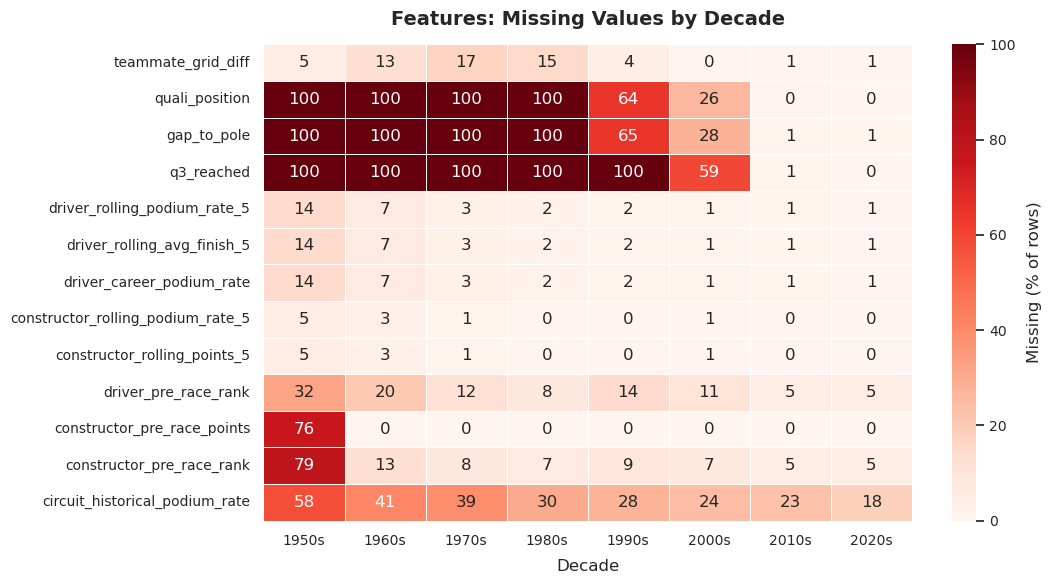

In [58]:
# Task 14.1: missing values per feature, by split and by decade
split_of = pd.cut(model_df["year"], bins=[0, TRAIN_MAX_YEAR, TEST_MIN_YEAR - 1, 9999], labels=["train", "validation", "test"])
train_df = model_df[split_of == "train"]   # every feature-vs-target view below uses the training seasons only

missing_by_split = (model_df[FEATURE_COLUMNS].isna().groupby(split_of, observed=True).mean() * 100).T
display(missing_by_split[missing_by_split.max(axis=1) > 0].round(1))

decade = (model_df["year"] // 10 * 10).astype(str) + "s"
missing_by_decade = (model_df[FEATURE_COLUMNS].isna().groupby(decade).mean() * 100).T
missing_by_decade = missing_by_decade[missing_by_decade.max(axis=1) > 0]

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(missing_by_decade, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, linewidths=0.5,
            cbar_kws={"label": "Missing (% of rows)"}, ax=ax)
ax.set(title="Features: Missing Values by Decade", xlabel="Decade", ylabel="")
save_fig("feat_missingness_by_decade")
plt.show()

[FIGURE SAVED] figures/feat_podium_rate_by_grid.png


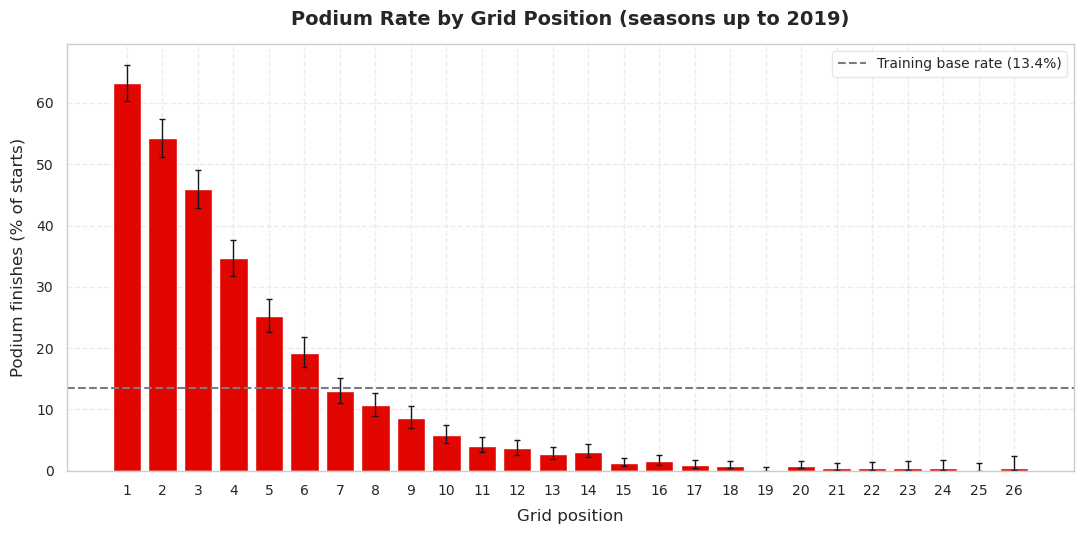

grid,1,2,3,4,6,10,15,20
n,997.0,1003.0,1002.0,1006.0,996.0,989.0,978.0,881.0
rate,63.3,54.3,45.9,34.7,19.2,5.8,1.2,0.8


In [59]:
# Task 14.2: podium rate by grid position (training seasons)
by_grid = rate_table(train_df[train_df["grid"] <= 26], ["grid"], TARGET_COLUMN)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(by_grid["grid"], by_grid["rate"], color=F1_PALETTE["crimson"], width=0.8,
       yerr=[(by_grid["rate"] - by_grid["ci_low"]).clip(lower=0), (by_grid["ci_high"] - by_grid["rate"]).clip(lower=0)],
       error_kw={"ecolor": F1_PALETTE["dark"], "elinewidth": 1, "capsize": 2})
ax.axhline(train_df[TARGET_COLUMN].mean() * 100, color=F1_PALETTE["gray"], linestyle="--",
           label=f"Training base rate ({train_df[TARGET_COLUMN].mean():.1%})")
ax.set(title=f"Podium Rate by Grid Position (seasons up to {TRAIN_MAX_YEAR})", xlabel="Grid position",
       ylabel="Podium finishes (% of starts)", xticks=range(1, 27))
ax.legend()
save_fig("feat_podium_rate_by_grid")
plt.show()
display(by_grid.set_index("grid").loc[[1, 2, 3, 4, 6, 10, 15, 20], ["n", "rate"]].round(1).T)

[FIGURE SAVED] figures/feat_correlation_matrix.png


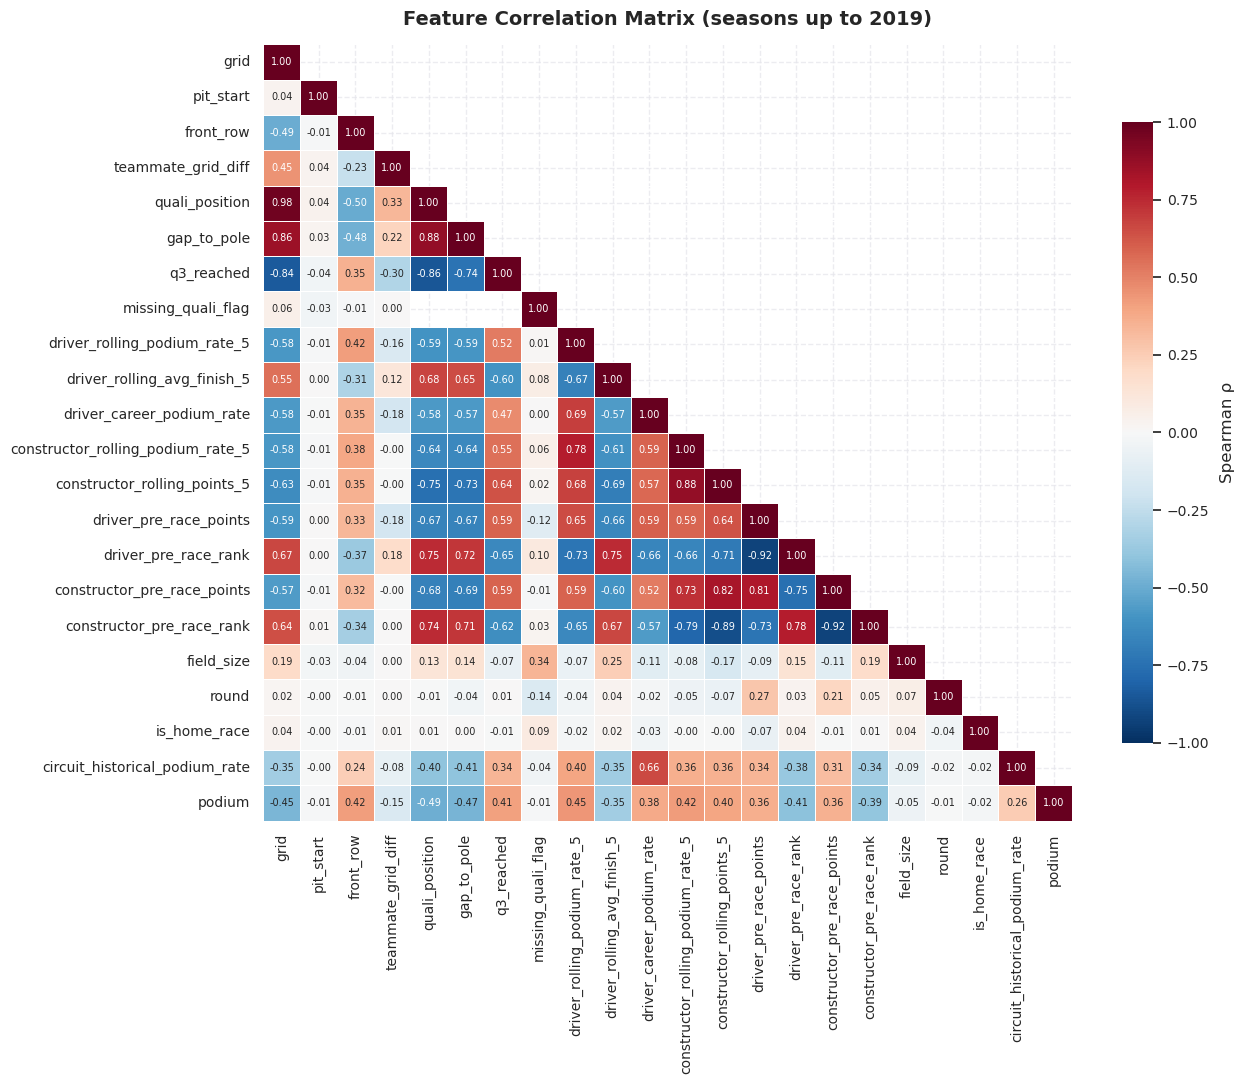

Feature pairs with |ρ| >= 0.8:


,,spearman_rho
quali_position,grid,0.98
constructor_pre_race_rank,constructor_pre_race_points,-0.92
driver_pre_race_rank,driver_pre_race_points,-0.92
constructor_pre_race_rank,constructor_rolling_points_5,-0.89
constructor_rolling_points_5,constructor_rolling_podium_rate_5,0.88
gap_to_pole,quali_position,0.88
q3_reached,quali_position,-0.86
gap_to_pole,grid,0.86
q3_reached,grid,-0.84
constructor_pre_race_points,constructor_rolling_points_5,0.82


In [60]:
# Task 14.3: Spearman correlation between the features and with the target (training seasons)
corr = train_df[FEATURE_COLUMNS + [TARGET_COLUMN]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.4, cbar_kws={"label": "Spearman ρ", "shrink": 0.8}, ax=ax)
ax.set(title=f"Feature Correlation Matrix (seasons up to {TRAIN_MAX_YEAR})")
save_fig("feat_correlation_matrix")
plt.show()

pairs = corr.loc[FEATURE_COLUMNS, FEATURE_COLUMNS].where(np.tril(np.ones((len(FEATURE_COLUMNS),) * 2, dtype=bool), k=-1)).stack()
print("Feature pairs with |ρ| >= 0.8:")
display(pairs[pairs.abs() >= 0.8].sort_values(key=np.abs, ascending=False).round(2).rename("spearman_rho").to_frame())

[FIGURE SAVED] figures/feat_distributions_by_class.png


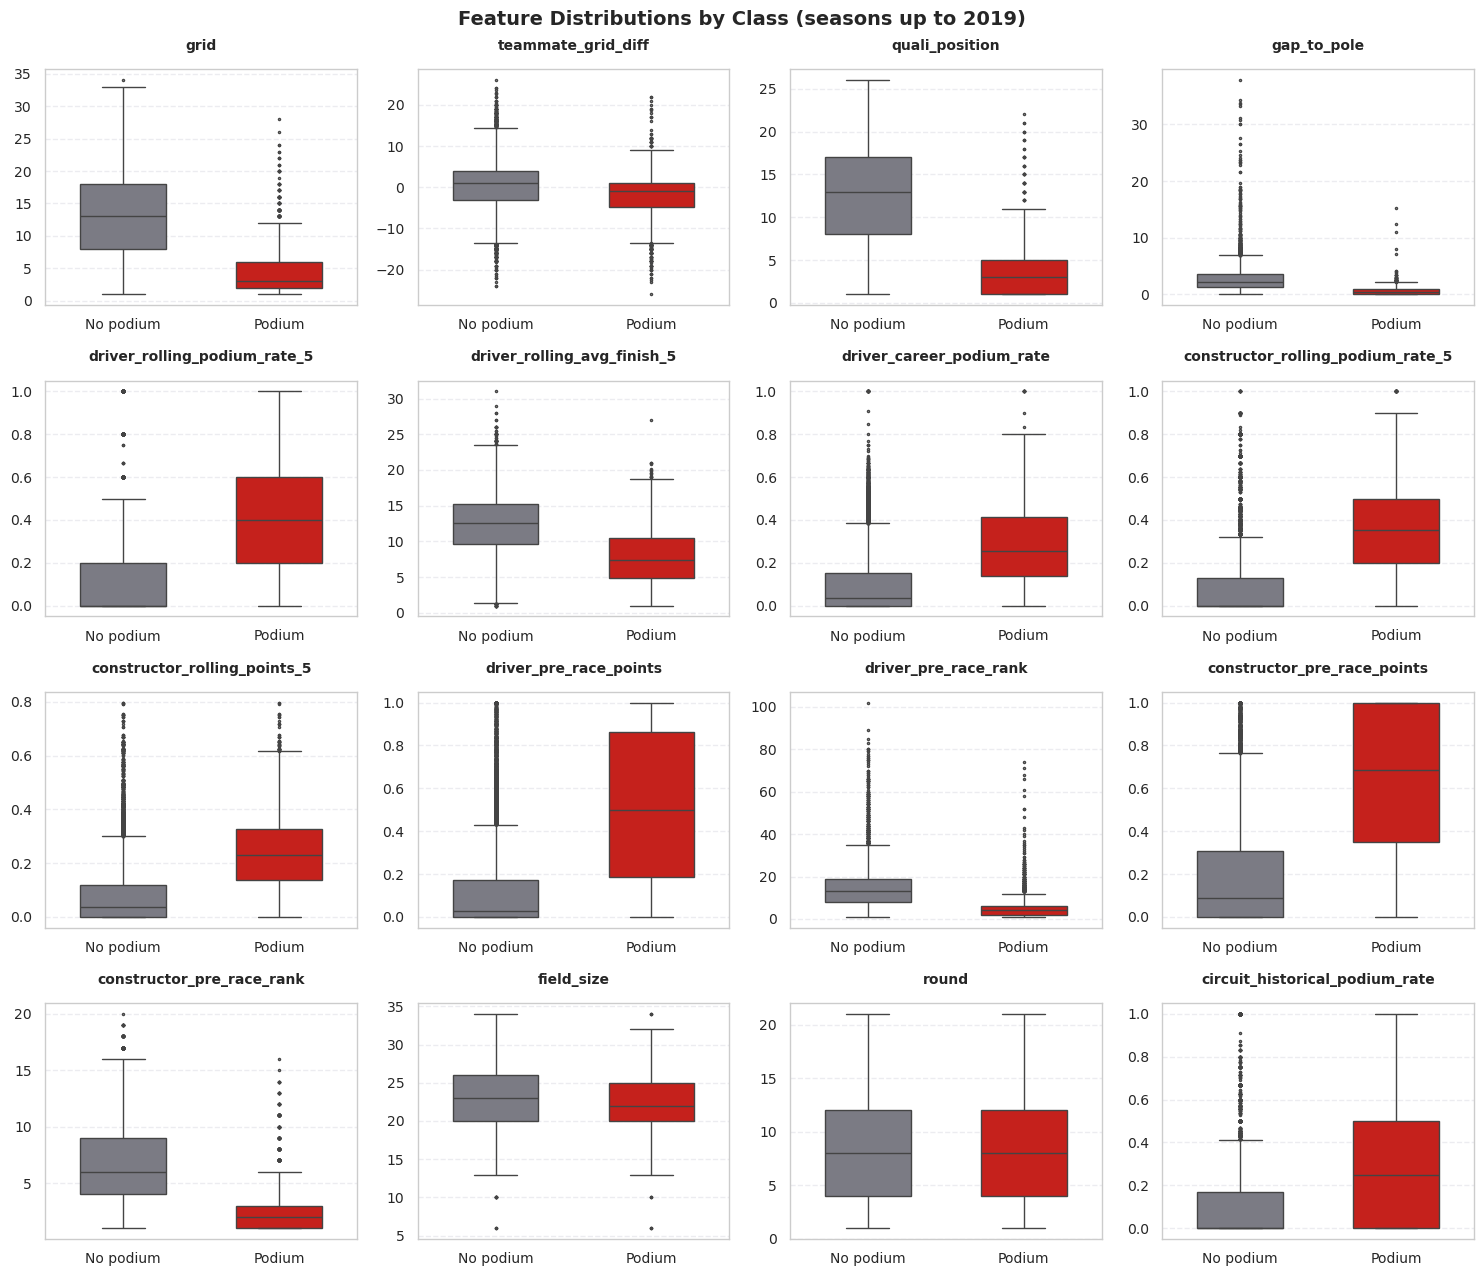

0                 1         
                       rows podium %     rows podium %
pit_start           22336.0    13.45     19.0     0.00
front_row           20355.0     8.98   2000.0    58.80
q3_reached           3123.0     1.18   2580.0    29.61
missing_quali_flag   8291.0    14.00  14064.0    13.10
is_home_race        20520.0    13.64   1835.0    11.17

In [61]:
# Task 14.4: feature distributions by class (training seasons)
BINARY_FEATURES: List[str] = ["pit_start", "front_row", "q3_reached", "missing_quali_flag", "is_home_race"]
continuous_features = [col for col in FEATURE_COLUMNS if col not in BINARY_FEATURES]
class_label = train_df[TARGET_COLUMN].map({0: "No podium", 1: "Podium"})

fig, axes = plt.subplots(4, 4, figsize=(15, 13))
for ax, col in zip(axes.flat, continuous_features):
    sns.boxplot(x=class_label, y=train_df[col], order=["No podium", "Podium"], hue=class_label, legend=False,
                palette={"No podium": F1_PALETTE["gray"], "Podium": F1_PALETTE["crimson"]}, width=0.55, fliersize=1.5, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set(xlabel="", ylabel="")
fig.suptitle(f"Feature Distributions by Class (seasons up to {TRAIN_MAX_YEAR})", fontsize=14, fontweight="bold")
save_fig("feat_distributions_by_class")
plt.show()

# Binary features: podium rate when the flag is 0 and when it is 1
display(pd.DataFrame({
    col: train_df.groupby(col)[TARGET_COLUMN].agg(["size", "mean"]).assign(mean=lambda d: (d["mean"] * 100).round(2)).stack()
    for col in BINARY_FEATURES
}).T.rename(columns={"size": "rows", "mean": "podium %"}))

,group,rows_used_pct,direction,roc_auc,pr_auc,base_rate
quali_position,qualifying,37.088,lower = podium,0.905,0.595,0.140
gap_to_pole,qualifying,36.502,lower = podium,0.887,0.577,0.141
grid,grid,100.000,lower = podium,0.884,0.500,0.134
driver_pre_race_rank,standings,87.775,lower = podium,0.838,0.447,0.140
constructor_rolling_points_5,constructor_form,98.882,higher = podium,0.834,0.379,0.135
constructor_pre_race_rank,standings,87.909,lower = podium,0.830,0.381,0.135
constructor_rolling_podium_rate_5,constructor_form,98.882,higher = podium,0.829,0.428,0.135
driver_rolling_podium_rate_5,driver_form,97.030,higher = podium,0.812,0.405,0.138
driver_career_podium_rate,driver_form,97.030,higher = podium,0.808,0.377,0.138
constructor_pre_race_points,standings,95.231,higher = podium,0.801,0.384,0.134


[FIGURE SAVED] figures/feat_univariate_auc.png


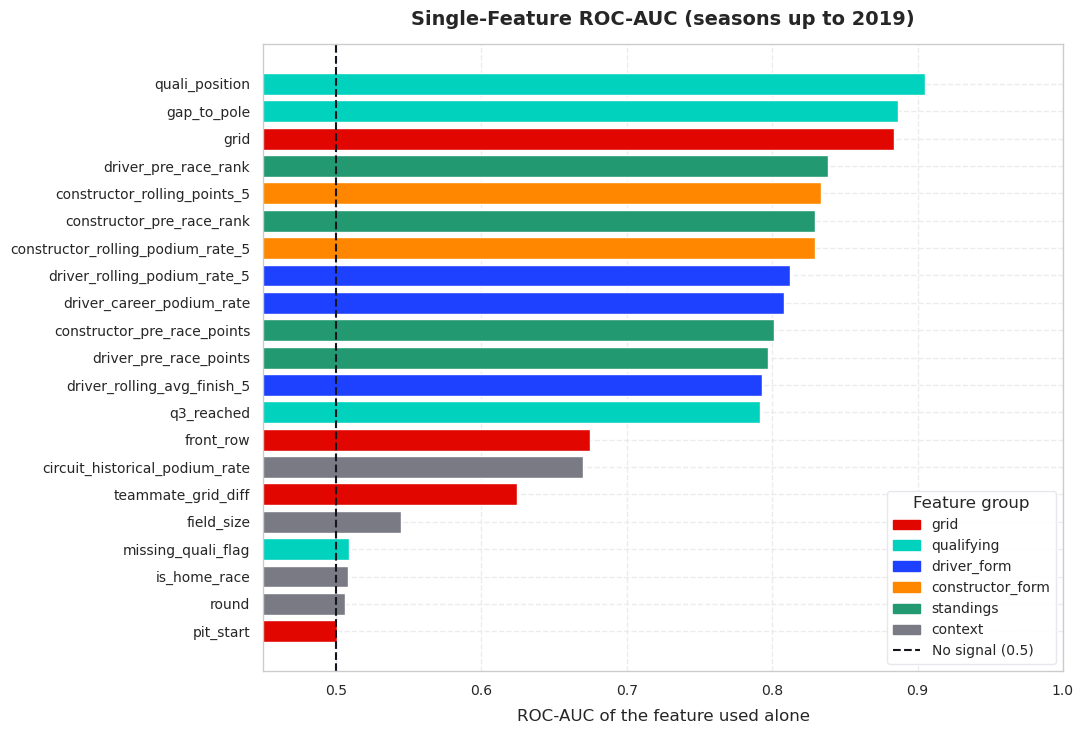

In [62]:
# Task 14.5: how well each feature ranks podiums on its own (training seasons)
def single_feature_scores(df: pd.DataFrame, col: str) -> Dict[str, float]:
    """ROC-AUC and PR-AUC of one raw feature as a score, on the rows where it is present."""
    known = df[[col, TARGET_COLUMN]].dropna()
    auc = roc_auc_score(known[TARGET_COLUMN], known[col])
    sign = 1 if auc >= 0.5 else -1   # a feature may rank podiums by being low (grid) or by being high (form)
    return {"rows_used_pct": len(known) / len(df) * 100, "direction": "higher = podium" if sign == 1 else "lower = podium",
            "roc_auc": max(auc, 1 - auc), "pr_auc": average_precision_score(known[TARGET_COLUMN], sign * known[col]),
            "base_rate": known[TARGET_COLUMN].mean()}


feature_scores = pd.DataFrame({col: single_feature_scores(train_df, col) for col in FEATURE_COLUMNS}).T
feature_scores.insert(0, "group", FEATURE_REGISTRY["group"])
feature_scores = feature_scores.sort_values("roc_auc", ascending=False)
display(feature_scores.infer_objects().round(3))

GROUP_COLORS = dict(zip(FEATURE_GROUPS, [F1_PALETTE[c] for c in ["crimson", "teal", "blue", "orange", "green", "gray"]]))
fig, ax = plt.subplots(figsize=(11, 7.5))
plot_scores = feature_scores.iloc[::-1]
ax.barh(plot_scores.index, plot_scores["roc_auc"].astype(float), color=plot_scores["group"].map(GROUP_COLORS))
ax.axvline(0.5, color=F1_PALETTE["dark"], linestyle="--")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=color) for color in GROUP_COLORS.values()] +
          [plt.Line2D([0], [0], color=F1_PALETTE["dark"], linestyle="--")],
          labels=list(GROUP_COLORS) + ["No signal (0.5)"], title="Feature group", loc="lower right")
ax.set(title=f"Single-Feature ROC-AUC (seasons up to {TRAIN_MAX_YEAR})", xlabel="ROC-AUC of the feature used alone", xlim=(0.45, 1.0))
save_fig("feat_univariate_auc")
plt.show()

In [63]:
# Task 14.6: is 5 races a sensible window? Compare the driver form features for 3, 5 and 10 races
window_scores = {}
for window in [3, 5, 10]:
    form = add_driver_form(feature_base[feature_base["year"] <= TRAIN_MAX_YEAR], window=window)
    rolling_podium, rolling_finish = f"driver_rolling_podium_rate_{window}", f"driver_rolling_avg_finish_{window}"
    # The three driver-form features together, as a logistic regression fitted on the training seasons
    known = form.dropna(subset=["driver_career_podium_rate"])
    combined = smf.logit(f"{TARGET_COLUMN} ~ {rolling_podium} + {rolling_finish} + driver_career_podium_rate", data=known).fit(disp=0)
    window_scores[f"last {window} races"] = {
        "rolling podium rate alone, ROC-AUC": single_feature_scores(form, rolling_podium)["roc_auc"],
        "rolling avg finish alone, ROC-AUC": single_feature_scores(form, rolling_finish)["roc_auc"],
        "all three driver-form features, ROC-AUC": roc_auc_score(known[TARGET_COLUMN], combined.predict(known)),
        "all three driver-form features, PR-AUC": average_precision_score(known[TARGET_COLUMN], combined.predict(known)),
    }
display(pd.DataFrame(window_scores).round(3))

,last 3 races,last 5 races,last 10 races
"rolling podium rate alone, ROC-AUC",0.776,0.812,0.835
"rolling avg finish alone, ROC-AUC",0.772,0.793,0.806
"all three driver-form features, ROC-AUC",0.836,0.843,0.846
"all three driver-form features, PR-AUC",0.447,0.455,0.456


## Hand-Off

`model_df` has 24,482 rows and 27 columns: the 5 identifiers, `podium` and 21 features in 6 groups. It passes the data contract and both leakage tests.

**What the validation shows**

- **Grid position is the strongest pre-race signal available for every row.** The podium rate falls from 63.3% on pole to 5.8% from tenth and 0.8% from twentieth. Used alone, `grid` reaches a ROC-AUC of 0.884.
- **Qualifying adds a little where it exists.** `quali_position` (0.905) and `gap_to_pole` (0.887) rank podiums slightly better than `grid`, but they are present in only 37% of training rows.
- **Form and standings carry real signal.** Every driver-form, constructor-form and standings feature scores between 0.79 and 0.84 alone.
- **Four features have almost none alone:** `pit_start`, `is_home_race`, `round` and `missing_quali_flag` (ROC-AUC 0.50 to 0.51). `is_home_race` agrees with Q2. They are kept for now: the flags mark rows that will be imputed in Step 5, and the ablation in Step 7 measures what each group contributes.
- **Several features overlap.** `quali_position` and `grid` correlate at 0.98; rank and points within each standings table at −0.92. Tree models tolerate this; for logistic regression it argues for regularisation.
- **A window of 5 races is enough.** A 10-race window scores higher alone (0.835 vs. 0.812), but with the career rate alongside, the three driver-form features together reach 0.843 with 5 races and 0.846 with 10.

**Keep in mind for Step 5**

- Qualifying features are missing in 63% of training rows but in almost no validation or test rows. How to fill them, and whether to train on all seasons or only recent ones, is the window experiment.
- `driver_pre_race_rank` and `constructor_pre_race_rank` are missing at round 1 and for a driver's first race of a season (about 12% of training rows).
- `circuit_historical_podium_rate` is missing on a driver's first visit to a circuit (31% of training rows).
- `FEATURE_COLUMNS`, `FEATURE_GROUPS` and `FEATURE_REGISTRY` describe the feature set; `build_feature_table()` rebuilds it.

---
# 6. Step 5: Split and Preprocessing (M3)

Split `model_df` by season, build the preprocessing pipeline, and run the experiments that decide how it is used.

**One rule for the whole section: the test seasons are never scored.** Every comparison below is made on the validation seasons (2020–2021). The test seasons are transformed at the end so that Step 6 can use them once, for the final report.

## Task 15: Temporal Split

**DEC-002.** Train on seasons up to 2019, validate on 2020–2021, test on 2022 onward.

Why by season and not at random:

- **It matches how the model would be used:** trained on the past, asked about a race that has not happened.
- **Rows of one race are not independent.** Exactly three drivers per race reach the podium. A random split would put some drivers of a race in training and the rest in validation, and the model could learn that race's outcome from its neighbours.
- **Regulations change by era.** 2022 brought new ground-effect cars. Keeping it out of training tests whether the model carries over to a new set of rules.

In [64]:
# Task 15.1: temporal split (DEC-002)
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


def split_by_season(df: pd.DataFrame, train_min_year: Optional[int] = None) -> Dict[str, pd.DataFrame]:
    """Train (<= TRAIN_MAX_YEAR, optionally from train_min_year), validation and test, by season."""
    train = df[df["year"] <= TRAIN_MAX_YEAR]
    if train_min_year is not None:
        train = train[train["year"] >= train_min_year]
    return {"train": train, "validation": df[df["year"].between(*VAL_YEARS)], "test": df[df["year"] >= TEST_MIN_YEAR]}


splits = split_by_season(model_df)
assert sum(len(part) for part in splits.values()) == len(model_df), "The splits do not partition model_df"
assert splits["train"]["date"].max() < splits["validation"]["date"].min() < splits["validation"]["date"].max() < splits["test"]["date"].min()
display(pd.DataFrame({
    name: {"first race": part["date"].min().date(), "last race": part["date"].max().date(), "rows": len(part),
           "races": part["raceId"].nunique(), "podium %": round(part[TARGET_COLUMN].mean() * 100, 2)}
    for name, part in splits.items()
}).T)

,first race,last race,rows,races,podium %
train,1950-05-13,2019-12-01,22355,1007,13.44
validation,2020-07-05,2021-12-12,775,39,15.1
test,2022-03-20,2024-12-08,1352,68,15.09


**No encoder is needed (DEC-020).** Every feature is numeric or a 0/1 flag. The identifiers (`driverId`, `constructorId`, `circuitId`) are deliberately not one-hot encoded: the cell below shows that a large share of validation and test rows belong to a driver or constructor that never appears in the training seasons. A one-hot column would be all zeros for them. The form, standings and circuit-history features describe the same thing in a way that also works for a newcomer.

In [65]:
# Task 15.2: why the identifiers are not one-hot encoded
id_report = {}
for col in ["driverId", "constructorId"]:
    seen_in_training = set(clean_df.loc[clean_df["year"] <= TRAIN_MAX_YEAR, col])
    id_report[col] = {"distinct values in training": len(seen_in_training)}
    for name in ["validation", "test"]:
        part = splits[name]
        ids = part[col] if col in part else clean_df.loc[part.index, col]
        id_report[col][f"{name} rows with an unseen value (%)"] = round((~ids.isin(seen_in_training)).mean() * 100, 1)
display(pd.DataFrame(id_report).T)
print(f"Columns in FEATURE_COLUMNS with a non-numeric dtype: {model_df[FEATURE_COLUMNS].select_dtypes(exclude='number').columns.tolist()}")

,distinct values in training,validation rows with an unseen value (%),test rows with an unseen value (%)
driverId,664.0,13.7,21.9
constructorId,162.0,15.6,20.0


Columns in FEATURE_COLUMNS with a non-numeric dtype: []


## Task 16: Preprocessing Pipeline

**DEC-020.** One `sklearn` pipeline, always fitted on training rows only.

| Step | Applies to | What it does |
| :--- | :--- | :--- |
| Qualifying fallback | `quali_position` | Where a row has no qualifying record, use its grid slot. Row-wise, so nothing is learned from other rows |
| Median imputer | 16 continuous features | Fill the remaining missing values with the training median |
| Standard scaler | 16 continuous features | Subtract the training mean, divide by the training standard deviation |
| Constant imputer | 5 binary flags | Fill a missing flag with 0; flags are not scaled |

The experiments are scored with a logistic regression, because it reacts to both imputation and scaling. Each comparison reports the PR-AUC difference with a 95% interval, obtained by resampling whole validation races 500 times.

In [66]:
# Task 16.1: the preprocessing pipeline
CONTINUOUS_FEATURES: List[str] = [col for col in FEATURE_COLUMNS if col not in BINARY_FEATURES]


def fill_quali_from_grid(X: pd.DataFrame) -> pd.DataFrame:
    """Where a row has no qualifying record, use its grid slot as the qualifying position. Row-wise, nothing is fitted."""
    X = X.copy()
    X["quali_position"] = X["quali_position"].fillna(X["grid"])
    return X


def make_preprocessor(quali_fallback: bool = True, impute_first: bool = True) -> Pipeline:
    """Imputer and scaler for the feature columns. Returns an unfitted pipeline; fit it on training rows only.

    Continuous features: median imputation and standardisation (order set by impute_first).
    Binary features: a missing flag is filled with 0 and passed through unscaled.
    """
    impute, scale = ("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())
    continuous = Pipeline([impute, scale] if impute_first else [scale, impute])
    columns = ColumnTransformer([
        ("continuous", continuous, CONTINUOUS_FEATURES),
        ("binary", SimpleImputer(strategy="constant", fill_value=0), BINARY_FEATURES),
    ], verbose_feature_names_out=False)
    steps = [("quali_fallback", FunctionTransformer(fill_quali_from_grid))] if quali_fallback else []
    return Pipeline(steps + [("columns", columns)]).set_output(transform="pandas")


def make_reference_model() -> LogisticRegression:
    """Logistic regression used to score the preprocessing experiments. It is sensitive to imputation and scaling."""
    return LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=RANDOM_SEED)


display(make_preprocessor())

Pipeline(steps=[('quali_fallback',
                 FunctionTransformer(func=<function fill_quali_from_grid at 0x32526bd80>)),
                ('columns',
                 ColumnTransformer(transformers=[('continuous',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['grid', 'teammate_grid_diff',
                                                   'quali_position',
                                                   'gap_to_pole',
                                                   'driver_rolling_podium_rate_5',
                                                   'driver_...
                                                   'constructor_rolling_points_5',
                                                   'driver_pre_race_points',
                                                   'driver_pre_race_rank',
                                                   'constructor_pre_race_points',
                                                   'constructor_pre_race_rank',
                                                   'field_size', 'round',
                                                   'circuit_historical_podium_rate']),
                                                 ('binary',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['pit_start', 'front_row',
                                                   'q3_reached',
                                                   'missing_quali_flag',
                                                   'is_home_race'])],
                                   verbose_feature_names_out=False))])

In [67]:
# Task 16.2: scoring helpers. Everything in Step 5 is scored on the validation seasons; the test seasons are never scored.
N_BOOTSTRAP: int = 500


def validation_probabilities(train: pd.DataFrame, preprocessor: Optional[Pipeline], model=None,
                             fit_preprocessor_on: Optional[pd.DataFrame] = None) -> np.ndarray:
    """Fit preprocessor (on train unless told otherwise) and model on train; return podium probabilities for validation."""
    model = make_reference_model() if model is None else model
    validation = splits["validation"]
    X_train, X_val = train[FEATURE_COLUMNS], validation[FEATURE_COLUMNS]
    if preprocessor is not None:
        preprocessor.fit((train if fit_preprocessor_on is None else fit_preprocessor_on)[FEATURE_COLUMNS])
        X_train, X_val = preprocessor.transform(X_train), preprocessor.transform(X_val)
    return model.fit(X_train, train[TARGET_COLUMN]).predict_proba(X_val)[:, 1]


def compare_on_validation(predictions: Dict[str, np.ndarray], reference: str) -> pd.DataFrame:
    """ROC-AUC and PR-AUC per variant, and the PR-AUC difference to the reference with a 95% interval.

    The interval comes from resampling whole validation races, the same resamples for every variant.
    """
    validation = splits["validation"]
    y = validation[TARGET_COLUMN].to_numpy()
    race_rows = [np.flatnonzero(validation["raceId"].to_numpy() == race) for race in validation["raceId"].unique()]
    rng = np.random.default_rng(RANDOM_SEED)
    resamples = [np.concatenate([race_rows[i] for i in rng.integers(0, len(race_rows), len(race_rows))]) for _ in range(N_BOOTSTRAP)]
    boot = {name: np.array([average_precision_score(y[idx], p[idx]) for idx in resamples]) for name, p in predictions.items()}

    rows = {}
    for name, p in predictions.items():
        low, high = np.percentile(boot[name] - boot[reference], [2.5, 97.5])
        pr_auc = average_precision_score(y, p)
        rows[name] = {"val ROC-AUC": roc_auc_score(y, p), "val PR-AUC": pr_auc,
                      "PR-AUC Δ vs. reference": pr_auc - average_precision_score(y, predictions[reference]),
                      "Δ 95% low": low, "Δ 95% high": high}
    return pd.DataFrame(rows).T

## Task 17: Training-Window Experiment

Qualifying features are missing in 63% of training rows but almost never in validation or test. Two ways to deal with that are compared together:

- **Shorten the training window** to seasons with qualifying data: from 1994 (first rows), from 2003 (complete) or from 2006 (knockout format).
- **Fill the gap** with the training median, or with the grid slot.

A gradient-boosting model on the raw features is added as a check, because it reads missing values directly and needs no imputation.

train rows  train rows without qualifying (%)  val ROC-AUC  val PR-AUC  PR-AUC Δ vs. reference  Δ 95% low  Δ 95% high
training window model                                                                                                                                                 
all seasons     logistic, median imputation         22355.0                               62.9       0.9274      0.7269                  0.0000     0.0000      0.0000
                logistic, grid fallback             22355.0                               62.9       0.9286      0.7262                 -0.0007    -0.0113      0.0090
                gradient boosting, raw features     22355.0                               62.9       0.9286      0.7130                 -0.0139    -0.0383      0.0171
from 1994       logistic, median imputation         10091.0                               17.8       0.9271      0.7191                 -0.0078    -0.0182      0.0011
                logistic, grid fallback             10091.0                               17.8       0.9276      0.7200                 -0.0069    -0.0189      0.0070
                gradient boosting, raw features     10091.0                               17.8       0.9298      0.7039                 -0.0230    -0.0552      0.0173
from 2003       logistic, median imputation          6782.0                                0.3       0.9262      0.7246                 -0.0023    -0.0178      0.0120
                logistic, grid fallback              6782.0                                0.3       0.9262      0.7245                 -0.0024    -0.0177      0.0121
                gradient boosting, raw features      6782.0                                0.3       0.9287      0.6933                 -0.0335    -0.0672      0.0155
from 2006       logistic, median imputation          5743.0                                0.3       0.9277      0.7288                  0.0019    -0.0145      0.0179
                logistic, grid fallback              5743.0                                0.3       0.9277      0.7283                  0.0015    -0.0146      0.0174
                gradient boosting, raw features      5743.0                                0.3       0.9210      0.6646                 -0.0623    -0.1036     -0.0175

[FIGURE SAVED] figures/prep_training_window.png


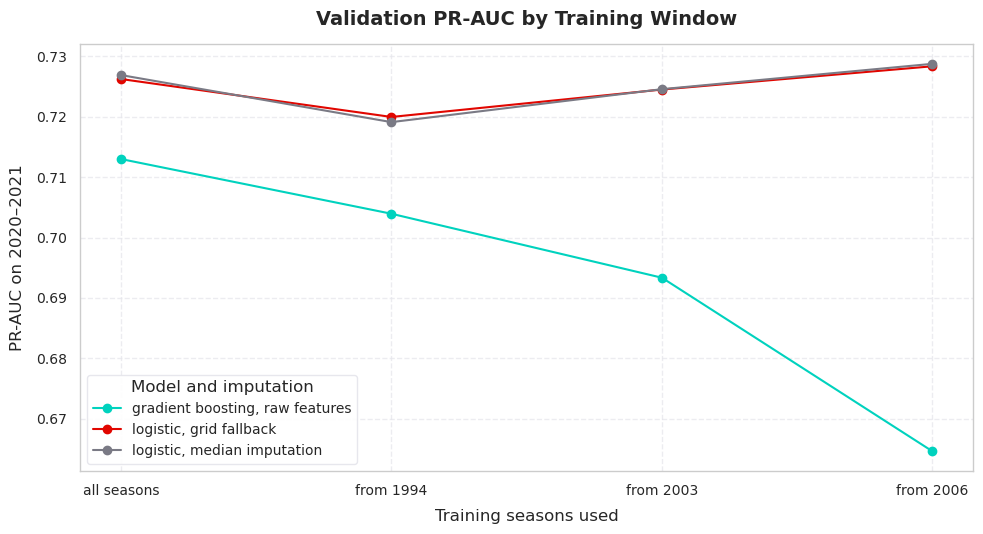

In [68]:
# Task 17: training-window and qualifying-imputation experiment
WINDOWS: Dict[str, Optional[int]] = {"all seasons": None, "from 1994": 1994, "from 2003": 2003, "from 2006": 2006}

window_predictions, window_rows = {}, {}
for window_name, first_year in WINDOWS.items():
    train = split_by_season(model_df, first_year)["train"]
    variants = {
        "logistic, median imputation": (make_preprocessor(quali_fallback=False), None),
        "logistic, grid fallback": (make_preprocessor(quali_fallback=True), None),
        # Gradient boosting reads missing values natively, so it needs no imputer or scaler
        "gradient boosting, raw features": (None, HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=RANDOM_SEED)),
    }
    for variant_name, (preprocessor, model) in variants.items():
        key = f"{window_name} | {variant_name}"
        window_predictions[key] = validation_probabilities(train, preprocessor, model)
        window_rows[key] = {"train rows": len(train), "train rows without qualifying (%)": train["missing_quali_flag"].mean() * 100}

WINDOW_REFERENCE = "all seasons | logistic, median imputation"
window_results = pd.DataFrame(window_rows).T.join(compare_on_validation(window_predictions, WINDOW_REFERENCE))
window_results.index = pd.MultiIndex.from_tuples([tuple(key.split(" | ")) for key in window_results.index], names=["training window", "model"])
display(window_results.round({"train rows": 0, "train rows without qualifying (%)": 1}).round(4))

pr_by_window = window_results["val PR-AUC"].unstack("model").loc[list(WINDOWS)]
ax = pr_by_window.plot(marker="o", figsize=(10, 5.5), color=[F1_PALETTE["teal"], F1_PALETTE["crimson"], F1_PALETTE["gray"]])
ax.set(title="Validation PR-AUC by Training Window", xlabel="Training seasons used", ylabel="PR-AUC on 2020–2021",
       xticks=range(len(WINDOWS)), xticklabels=list(WINDOWS))
ax.legend(title="Model and imputation")
save_fig("prep_training_window")
plt.show()

**Result (DEC-019): train on all seasons, with the grid fallback.**

- **For the logistic regression the window does not matter.** Validation PR-AUC is 0.727 on all seasons, 0.719 from 1994, 0.725 from 2003 and 0.729 from 2006. All of these sit within about 0.01 of each other, which is inside the bootstrap noise of a 39-race validation set.
- **Median or grid fallback makes no measurable difference** (0.7269 vs. 0.7262). The grid fallback is kept because the values it fills in are sensible: before 2003, qualifying and grid position agree in 98% of the rows that have both.
- **Gradient boosting gets worse with less data:** 0.713 on all seasons, 0.665 from 2006. Discarding 74% of the training rows costs it more than the cleaner qualifying columns give back.

So no rows are deleted. This also follows the instructors' rule that the whole dataset be used and that old seasons not be dropped (Piazza). Dropping the seasons without qualifying buys nothing for one model and hurts the other.

In [69]:
# Task 17.2: choices taken from the experiment (DEC-019)
TRAIN_MIN_YEAR: Optional[int] = None   # train on every season up to TRAIN_MAX_YEAR
QUALI_FALLBACK: bool = True            # a missing qualifying position is filled with the grid slot

splits = split_by_season(model_df, TRAIN_MIN_YEAR)
train_df, val_df, test_df = splits["train"], splits["validation"], splits["test"]
print(f"Training window: {train_df['year'].min()}–{train_df['year'].max()} ({len(train_df):,} rows) | "
      f"validation {len(val_df):,} rows | test {len(test_df):,} rows | qualifying fallback from grid: {QUALI_FALLBACK}")

Training window: 1950–2019 (22,355 rows) | validation 775 rows | test 1,352 rows | qualifying fallback from grid: True


## Task 18: Distributions Before and After Each Transformation

Four features, each shown raw, after imputation and after scaling, for the three splits. The preprocessor is fitted on the training seasons only, so the validation and test curves show how far those seasons sit from what the scaler learned.

[FIGURE SAVED] figures/prep_distributions_by_stage.png


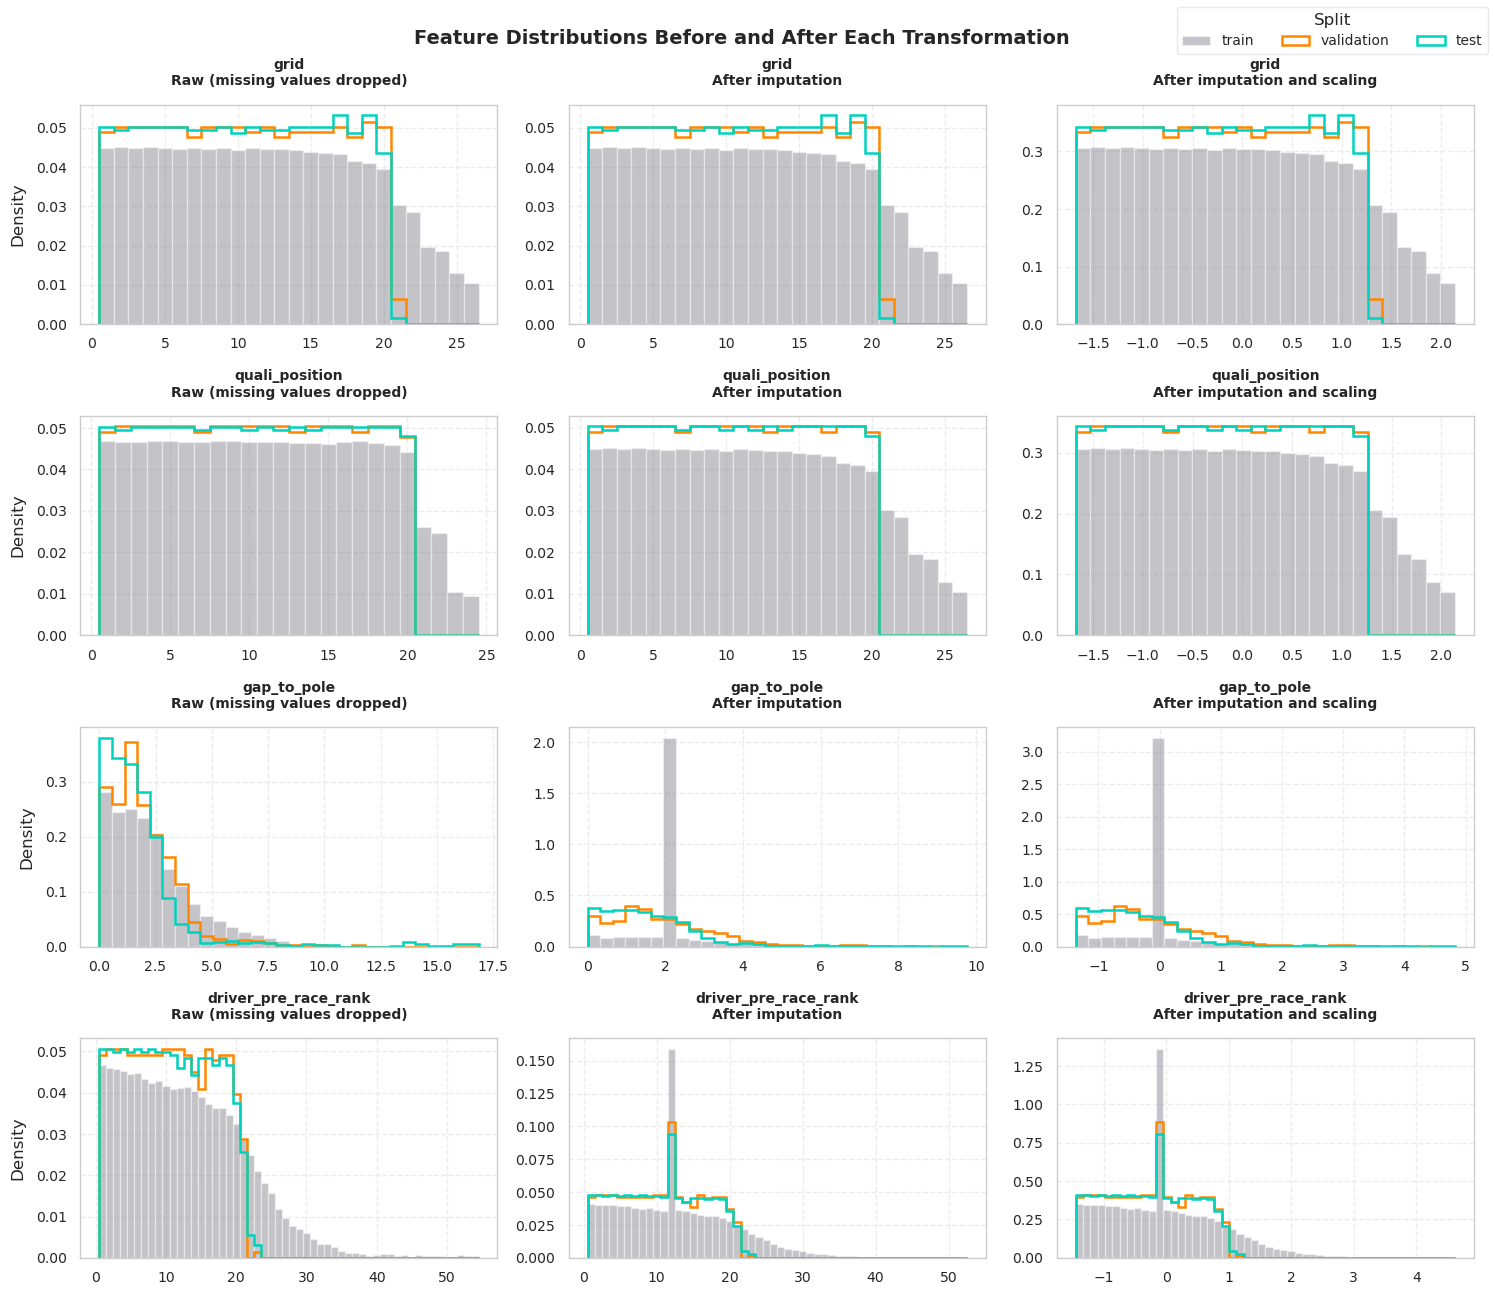

,missing in train (%),median used to impute,train mean after scaling,train std after scaling
grid,0.000,12.000,-0.0,1.0
teammate_grid_diff,7.560,0.000,0.0,1.0
quali_position,62.912,12.000,-0.0,1.0
gap_to_pole,63.498,1.961,-0.0,1.0
driver_rolling_podium_rate_5,2.970,0.000,0.0,1.0
driver_rolling_avg_finish_5,2.970,12.000,-0.0,1.0
driver_career_podium_rate,2.970,0.050,0.0,1.0
constructor_rolling_podium_rate_5,1.118,0.000,0.0,1.0
constructor_rolling_points_5,1.118,0.048,0.0,1.0
driver_pre_race_points,0.000,0.048,0.0,1.0


In [70]:
# Task 18.1: feature distributions before and after each transformation
preprocessor = make_preprocessor(quali_fallback=QUALI_FALLBACK).fit(train_df[FEATURE_COLUMNS])   # fitted on training rows only
column_step = preprocessor.named_steps["columns"]
imputer = column_step.named_transformers_["continuous"].named_steps["impute"]


def after_imputation(df: pd.DataFrame) -> pd.DataFrame:
    """Continuous features after the grid fallback and the median imputer, before scaling."""
    filled = fill_quali_from_grid(df[FEATURE_COLUMNS]) if QUALI_FALLBACK else df[FEATURE_COLUMNS]
    return pd.DataFrame(imputer.transform(filled[CONTINUOUS_FEATURES]), columns=CONTINUOUS_FEATURES, index=df.index)


def histogram_bins(train_values: pd.Series) -> np.ndarray:
    """One bin per distinct value for discrete features (grid slots, ranks), 30 equal bins otherwise."""
    low, high = np.percentile(train_values, [0.5, 99.5])
    distinct = np.sort(train_values[train_values.between(low, high)].unique())
    if len(distinct) > 60:
        return np.linspace(low, high, 31)
    step = np.diff(distinct).min()
    return np.concatenate([[distinct[0] - step / 2], (distinct[:-1] + distinct[1:]) / 2, [distinct[-1] + step / 2]])


STAGE_FEATURES: List[str] = ["grid", "quali_position", "gap_to_pole", "driver_pre_race_rank"]
stages = {
    "Raw (missing values dropped)": {name: part[FEATURE_COLUMNS] for name, part in splits.items()},
    "After imputation": {name: after_imputation(part) for name, part in splits.items()},
    "After imputation and scaling": {name: preprocessor.transform(part[FEATURE_COLUMNS]) for name, part in splits.items()},
}
SPLIT_COLORS = {"train": F1_PALETTE["gray"], "validation": F1_PALETTE["orange"], "test": F1_PALETTE["teal"]}

fig, axes = plt.subplots(len(STAGE_FEATURES), len(stages), figsize=(15, 13))
for row, feature in enumerate(STAGE_FEATURES):
    for col, (stage_name, stage_data) in enumerate(stages.items()):
        ax = axes[row, col]
        values = {name: data[feature].dropna() for name, data in stage_data.items()}
        bins = histogram_bins(values["train"])
        ax.hist(values["train"], bins=bins, density=True, color=SPLIT_COLORS["train"], alpha=0.45, label="train")
        for name in ["validation", "test"]:
            ax.hist(values[name], bins=bins, density=True, histtype="step", linewidth=1.8, color=SPLIT_COLORS[name], label=name)
        ax.set_title(f"{feature}\n{stage_name}", fontsize=10)
        ax.set(ylabel="Density" if col == 0 else "")
fig.legend(*axes[0, 0].get_legend_handles_labels(), title="Split", loc="upper right", ncol=3)
fig.suptitle("Feature Distributions Before and After Each Transformation", fontsize=14, fontweight="bold")
save_fig("prep_distributions_by_stage")
plt.show()

display(pd.DataFrame({
    "missing in train (%)": train_df[CONTINUOUS_FEATURES].isna().mean() * 100,
    "median used to impute": imputer.statistics_,
    "train mean after scaling": stages["After imputation and scaling"]["train"][CONTINUOUS_FEATURES].mean(),
    "train std after scaling": stages["After imputation and scaling"]["train"][CONTINUOUS_FEATURES].std(ddof=0),
}).round(3))

[FIGURE SAVED] figures/prep_distribution_shift.png


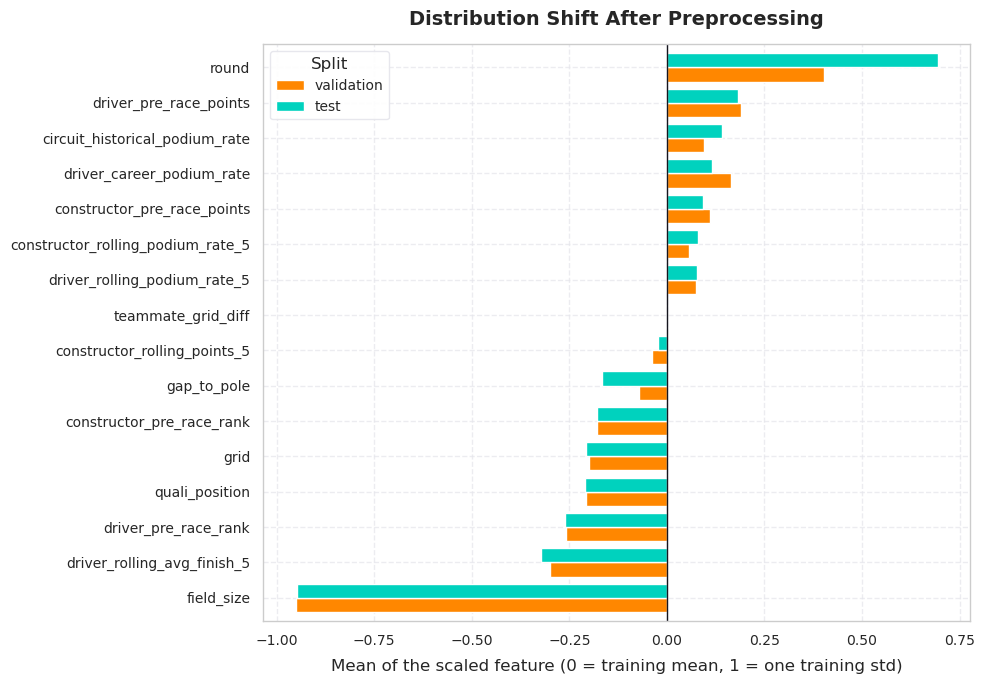

,field_size,driver_rolling_avg_finish_5,driver_pre_race_rank,quali_position,grid,constructor_pre_race_rank,gap_to_pole,constructor_rolling_points_5,teammate_grid_diff,driver_rolling_podium_rate_5,constructor_rolling_podium_rate_5,constructor_pre_race_points,driver_career_podium_rate,circuit_historical_podium_rate,driver_pre_race_points,round
validation,-0.95,-0.30,-0.26,-0.21,-0.20,-0.18,-0.07,-0.04,-0.0,0.07,0.06,0.11,0.16,0.10,0.19,0.40
test,-0.95,-0.32,-0.26,-0.21,-0.21,-0.18,-0.17,-0.02,0.0,0.08,0.08,0.09,0.12,0.14,0.18,0.69


In [71]:
# Task 18.2: how far the validation and test seasons sit from the training seasons, in training standard deviations
shift = pd.DataFrame({
    name: stages["After imputation and scaling"][name][CONTINUOUS_FEATURES].mean() for name in ["validation", "test"]
}).sort_values("test")

ax = shift.plot.barh(color=[SPLIT_COLORS["validation"], SPLIT_COLORS["test"]], width=0.8, figsize=(10, 7))
ax.axvline(0, color=F1_PALETTE["dark"], linewidth=1)
ax.set(title="Distribution Shift After Preprocessing", xlabel="Mean of the scaled feature (0 = training mean, 1 = one training std)")
ax.legend(title="Split")
save_fig("prep_distribution_shift")
plt.show()
display(shift.round(2).T)

**Reading the figures**

- **Scaling changes the axis, not the shape.** The third column is the second column on a new scale, with the training distribution centred on 0.
- **Imputation adds a spike** at the training median. It is tall for `gap_to_pole`, missing in 64% of training rows, and absent from `quali_position`, which the grid fallback fills with real values first.
- **Validation and test are not distributed like training.** Modern grids stop at 20 cars, so `grid`, `quali_position` and the standings ranks have no tail. `field_size` sits 0.95 training standard deviations below the training mean, and `round` 0.4 to 0.7 above it, because seasons now have more races. This shift is real and is the reason for validating on recent seasons.

## Task 19: Preprocessing-Order Experiments

Two controlled experiments. In each, only one thing changes; the model, the training rows and the validation rows stay the same.

### Experiment 1: fit the preprocessor on the training rows, or on all rows

Fitting the imputer and scaler on all rows lets the medians, means and standard deviations see the validation and test seasons. That is leakage, and this experiment measures how much it changes the score.

In [72]:
# Task 19.1: Experiment 1, preprocessor fitted on the training rows vs. on all rows
exp1_predictions = {
    "fitted on train only": validation_probabilities(train_df, make_preprocessor(QUALI_FALLBACK)),
    "fitted on train + validation + test (leaks)": validation_probabilities(train_df, make_preprocessor(QUALI_FALLBACK), fit_preprocessor_on=model_df),
}
display(compare_on_validation(exp1_predictions, "fitted on train only").round(4))

# What actually changes: the statistics the imputer and scaler learn
continuous_steps = lambda fitted: fitted.named_steps["columns"].named_transformers_["continuous"].named_steps
train_fit = continuous_steps(make_preprocessor(QUALI_FALLBACK).fit(train_df[FEATURE_COLUMNS]))
all_fit = continuous_steps(make_preprocessor(QUALI_FALLBACK).fit(model_df[FEATURE_COLUMNS]))
learned = pd.DataFrame({
    "median, train only": train_fit["impute"].statistics_, "median, all rows": all_fit["impute"].statistics_,
    "std, train only": train_fit["scale"].scale_, "std, all rows": all_fit["scale"].scale_,
}, index=CONTINUOUS_FEATURES)
learned["std change (%)"] = (learned["std, all rows"] / learned["std, train only"] - 1) * 100
display(learned.round(3))
print(f"Rows the leaking fit can see that the honest fit cannot: {len(model_df) - len(train_df):,} of {len(model_df):,} "
      f"({1 - len(train_df) / len(model_df):.1%})")

,val ROC-AUC,val PR-AUC,PR-AUC Δ vs. reference,Δ 95% low,Δ 95% high
fitted on train only,0.9286,0.7262,0.0000,0.0000,0.0
fitted on train + validation + test (leaks),0.9285,0.7261,-0.0001,-0.0004,0.0


,"median, train only","median, all rows","std, train only","std, all rows",std change (%)
grid,12.000,12.000,6.820,6.748,-1.060
teammate_grid_diff,0.000,0.000,5.482,5.505,0.413
quali_position,12.000,12.000,6.821,6.747,-1.079
gap_to_pole,1.961,1.836,1.576,1.682,6.763
driver_rolling_podium_rate_5,0.000,0.000,0.232,0.235,1.099
driver_rolling_avg_finish_5,12.000,12.000,4.345,4.352,0.147
driver_career_podium_rate,0.050,0.050,0.156,0.158,1.311
constructor_rolling_podium_rate_5,0.000,0.000,0.201,0.203,1.356
constructor_rolling_points_5,0.048,0.048,0.128,0.126,-1.318
driver_pre_race_points,0.048,0.052,0.280,0.281,0.423


Rows the leaking fit can see that the honest fit cannot: 2,127 of 24,482 (8.7%)


**Result: no measurable difference here** (PR-AUC Δ = −0.0001, 95% interval −0.0004 to +0.0000).

The reason is in the second table: the validation and test seasons are only 8.7% of the rows, so the statistics barely move. Medians are almost identical and standard deviations change by 1 to 2% for most features (7% for `gap_to_pole`). A linear model absorbs a small rescaling of its inputs.

The pipeline is still fitted on training rows only. It costs nothing, it keeps the validation and test scores honest by construction, and the same shortcut would matter far more with a transformation that looks at the target, such as feature selection or target encoding.

### Experiment 2: impute then scale, or scale then impute

The order decides which values the scaler sees. If imputation comes first, the scaler measures the spread of a column that already has many copies of the median in it, so the standard deviation it learns is too small.

In [73]:
# Task 19.2: Experiment 2, impute then scale vs. scale then impute
exp2_predictions = {
    "impute -> scale": validation_probabilities(train_df, make_preprocessor(QUALI_FALLBACK, impute_first=True)),
    "scale -> impute": validation_probabilities(train_df, make_preprocessor(QUALI_FALLBACK, impute_first=False)),
}
display(compare_on_validation(exp2_predictions, "impute -> scale").round(4))

# What actually changes: the scaler's standard deviation, and so the spread of the real (non-imputed) values
impute_first = continuous_steps(make_preprocessor(QUALI_FALLBACK, impute_first=True).fit(train_df[FEATURE_COLUMNS]))
scale_first = continuous_steps(make_preprocessor(QUALI_FALLBACK, impute_first=False).fit(train_df[FEATURE_COLUMNS]))
order_effect = pd.DataFrame({
    "missing in train (%)": (fill_quali_from_grid(train_df[FEATURE_COLUMNS]) if QUALI_FALLBACK else train_df)[CONTINUOUS_FEATURES].isna().mean() * 100,
    "std seen by scaler, impute -> scale": impute_first["scale"].scale_,
    "std seen by scaler, scale -> impute": scale_first["scale"].scale_,
}, index=CONTINUOUS_FEATURES)
order_effect["real values larger under impute -> scale (%)"] = (order_effect.iloc[:, 2] / order_effect.iloc[:, 1] - 1) * 100
display(order_effect[order_effect["missing in train (%)"] > 0].sort_values("missing in train (%)", ascending=False).round(3))

,val ROC-AUC,val PR-AUC,PR-AUC Δ vs. reference,Δ 95% low,Δ 95% high
impute -> scale,0.9286,0.7262,0.0000,0.0000,0.0000
scale -> impute,0.9286,0.7261,-0.0001,-0.0007,0.0002


,missing in train (%),"std seen by scaler, impute -> scale","std seen by scaler, scale -> impute",real values larger under impute -> scale (%)
gap_to_pole,63.498,1.576,2.572,63.222
circuit_historical_podium_rate,31.438,0.215,0.246,14.619
driver_pre_race_rank,12.225,8.565,9.135,6.650
constructor_pre_race_rank,12.091,3.464,3.694,6.643
teammate_grid_diff,7.560,5.482,5.702,4.009
constructor_pre_race_points,4.769,0.326,0.332,1.928
driver_rolling_podium_rate_5,2.970,0.232,0.235,1.008
driver_rolling_avg_finish_5,2.970,4.345,4.411,1.515
driver_career_podium_rate,2.970,0.156,0.157,1.206
constructor_rolling_podium_rate_5,1.118,0.201,0.201,0.306


**Result: no measurable difference in the score** (PR-AUC Δ = −0.0001, 95% interval −0.0007 to +0.0002), **but the transformed values do differ.**

With imputation first, the standard deviation the scaler learns for `gap_to_pole` is 1.57 instead of 2.57, so its real values end up 63% further from zero. The effect shrinks with the share of missing values: 15% for the circuit history, 7% for the standings ranks.

The logistic regression compensates by learning a smaller coefficient, so the ranking of predictions hardly changes. The order would matter more for a model that depends on distances or on input scale, such as a neural network with a fixed learning rate. **Impute → scale is kept**: it is the conventional order and it guarantees that the training columns have mean 0 and standard deviation 1.

## Task 20: Final Matrices

In [74]:
# Task 20: final preprocessed matrices for modeling
X_train, y_train = train_df[FEATURE_COLUMNS], train_df[TARGET_COLUMN]
X_val, y_val = val_df[FEATURE_COLUMNS], val_df[TARGET_COLUMN]
X_test, y_test = test_df[FEATURE_COLUMNS], test_df[TARGET_COLUMN]

preprocessor = make_preprocessor(quali_fallback=QUALI_FALLBACK).fit(X_train)   # training rows only
X_train_prep, X_val_prep, X_test_prep = (preprocessor.transform(X) for X in (X_train, X_val, X_test))
PREPROCESSED_COLUMNS: List[str] = list(X_train_prep.columns)

assert set(PREPROCESSED_COLUMNS) == set(FEATURE_COLUMNS), "The pipeline dropped or added a feature"
assert not any(X.isna().any().any() for X in (X_train_prep, X_val_prep, X_test_prep)), "A missing value survived the pipeline"
assert np.allclose(X_train_prep[CONTINUOUS_FEATURES].mean(), 0, atol=1e-8) and np.allclose(X_train_prep[CONTINUOUS_FEATURES].std(ddof=0), 1)
assert X_train_prep.index.equals(X_train.index) and X_test_prep.index.equals(X_test.index), "Row order changed"
display(pd.DataFrame({name: {"rows": len(X), "features": X.shape[1], "podiums": int(y.sum()), "podium %": round(y.mean() * 100, 2)}
                      for name, X, y in [("train", X_train_prep, y_train), ("validation", X_val_prep, y_val), ("test", X_test_prep, y_test)]}).T)
print(f"[STEP 5 COMPLETE] Preprocessor fitted on {len(X_train):,} training rows; {len(PREPROCESSED_COLUMNS)} features, no missing values.")

,rows,features,podiums,podium %
train,22355.0,21.0,3004.0,13.44
validation,775.0,21.0,117.0,15.10
test,1352.0,21.0,204.0,15.09


[STEP 5 COMPLETE] Preprocessor fitted on 22,355 training rows; 21 features, no missing values.


## Hand-Off

| Object | Contents |
| :--- | :--- |
| `X_train`, `X_val`, `X_test` | Raw features (with missing values), for models that handle them natively |
| `X_train_prep`, `X_val_prep`, `X_test_prep` | Imputed and scaled features, no missing values, for logistic regression and the neural network |
| `y_train`, `y_val`, `y_test` | The `podium` target |
| `preprocessor` | The fitted pipeline; `make_preprocessor()` returns a fresh, unfitted one |
| `compare_on_validation()` | Scores variants on the validation seasons with a bootstrap interval |

**Keep in mind for Step 6**

- **Validation is small:** 775 rows, 117 podiums, 39 races. Differences below about 0.01 PR-AUC are noise.
- **The baseline to beat is already strong.** A plain logistic regression reaches a validation PR-AUC of 0.726 and ROC-AUC of 0.929. An untuned gradient-boosting model is below it (0.713).
- **Put the preprocessor inside the model pipeline** when tuning, so it is refitted on whatever rows the model is trained on.
- **The test matrices exist but have not been scored.** Use them once, after the model and threshold are fixed.

---
# 7. Step 6: Modeling (M4)

Five ways of predicting `podium` are trained on the same rows and the same 21 features, then compared: a fixed rule, a logistic regression, a random forest, a gradient-boosting model (LightGBM) and a shallow neural network.

**Three rules hold for the whole section**

- **Every model is fitted on the training seasons only** (up to 2019).
- **Every choice is made on the validation seasons** (2020–2021): hyperparameters, when the network stops training, the decision threshold and which model is carried forward.
- **The test seasons (2022 onward) are scored once**, in Task 28, after all of those choices are fixed.

## Task 21: Evaluation Protocol

**DEC-022.** The main metric is **PR-AUC** (average precision). About 15% of rows are podiums, and PR-AUC measures how well a model ranks those few positives without needing a threshold. ROC-AUC is reported next to it, but it moves little here because it also rewards ranking the many easy negatives at the back of the grid.

The secondary metric is **F1** at a decision threshold, with its precision and recall. A model outputs a score; the threshold turns it into a yes or no.

Two more helpers are defined here:

- `compare_models()` gives each PR-AUC a 95% interval by resampling whole races 500 times, and the same for the difference to a reference model.
- `random_search()` fits random hyperparameter configurations on the training seasons and ranks them by validation PR-AUC.

**DEC-037, every configuration is judged on five seeds.** Each configuration is fitted once per seed and ranked by its *mean* validation PR-AUC. The same rule picks the network architecture in Task 25. On a single seed, the configurations near the top of a search are separated by less than the seed-to-seed noise, so the winner is often the one with the luckiest seed. When the shared-drive fix (DEC-034) removed 157 training rows, a single-seed search switched LightGBM to a configuration that scored 0.746 on seed 42 but 0.732 on average, against 0.742 for the configuration it replaced. The final model of each kind is then fitted once, with `RANDOM_SEED`.

In [75]:
# Task 21.1: metrics and decision rules
from typing import Callable

from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_curve, precision_score, recall_score
from sklearn.model_selection import ParameterSampler


def best_f1_threshold(y_true, scores) -> float:
    """The threshold on the scores that gives the highest F1; rows with score >= threshold are predicted as podiums."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return float(thresholds[np.argmax(f1)])


def top3_per_race(race_ids, scores) -> np.ndarray:
    """Predict the three highest-scoring drivers of each race as the podium. Needs no threshold."""
    ranks = pd.Series(np.asarray(scores, dtype=float)).groupby(np.asarray(race_ids)).rank(method="first", ascending=False)
    return (ranks <= 3).to_numpy().astype(int)


def ranking_metrics(y_true, scores) -> Dict[str, float]:
    return {"ROC-AUC": roc_auc_score(y_true, scores), "PR-AUC": average_precision_score(y_true, scores)}


def decision_metrics(y_true, predicted) -> Dict[str, float]:
    return {"F1": f1_score(y_true, predicted, zero_division=0), "Precision": precision_score(y_true, predicted, zero_division=0),
            "Recall": recall_score(y_true, predicted, zero_division=0)}

In [76]:
# Task 21.2: model registry, race bootstrap and random search
PREDICTORS: Dict[str, Callable[[pd.DataFrame], np.ndarray]] = {}   # model name -> function from raw feature rows to podium scores
val_scores: Dict[str, np.ndarray] = {}                             # model name -> scores on the validation seasons


def register_model(name: str, predict: Callable[[pd.DataFrame], np.ndarray]) -> None:
    """Add a fitted model to the comparison and print its ranking metrics on the training and validation seasons."""
    PREDICTORS[name], val_scores[name] = predict, predict(X_val)
    train, validation = ranking_metrics(y_train, predict(X_train)), ranking_metrics(y_val, val_scores[name])
    print(f"{name}: validation PR-AUC {validation['PR-AUC']:.4f}, ROC-AUC {validation['ROC-AUC']:.4f} | "
          f"train PR-AUC {train['PR-AUC']:.4f}, ROC-AUC {train['ROC-AUC']:.4f}")


def compare_models(frame: pd.DataFrame, scores: Dict[str, np.ndarray], reference: str) -> pd.DataFrame:
    """ROC-AUC and PR-AUC per model on the rows of frame, with a 95% interval, and the PR-AUC difference to the reference.

    The intervals come from resampling whole races, the same resamples for every model.
    """
    y, race_ids = frame[TARGET_COLUMN].to_numpy(), frame["raceId"].to_numpy()
    race_rows = [np.flatnonzero(race_ids == race) for race in pd.unique(race_ids)]
    rng = np.random.default_rng(RANDOM_SEED)
    resamples = [np.concatenate([race_rows[i] for i in rng.integers(0, len(race_rows), len(race_rows))]) for _ in range(N_BOOTSTRAP)]
    boot = {name: np.array([average_precision_score(y[idx], s[idx]) for idx in resamples]) for name, s in scores.items()}

    rows = {}
    for name, s in scores.items():
        low, high = np.percentile(boot[name], [2.5, 97.5])
        delta_low, delta_high = np.percentile(boot[name] - boot[reference], [2.5, 97.5])
        rows[name] = {**ranking_metrics(y, s), "PR-AUC 95% low": low, "PR-AUC 95% high": high,
                      "PR-AUC Δ vs. reference": average_precision_score(y, s) - average_precision_score(y, scores[reference]),
                      "Δ 95% low": delta_low, "Δ 95% high": delta_high}
    return pd.DataFrame(rows).T


# DEC-037: every configuration is fitted once per seed and judged by its mean validation PR-AUC. On one seed,
# the configuration that wins a search is often the one whose seed happened to be lucky.
TUNING_SEEDS: List[int] = [RANDOM_SEED, 0, 1, 2, 3]


def random_search(make_model: Callable, space: Dict[str, list], n_iter: int, X_fit: pd.DataFrame,
                  X_score: pd.DataFrame, seeds: List[int] = TUNING_SEEDS) -> Tuple[pd.DataFrame, dict]:
    """Fit n_iter random configurations on the training rows, each once per seed.

    Returns the configurations ranked by mean validation PR-AUC over the seeds (DEC-037), and the best one.
    "val PR-AUC" is that mean; "val PR-AUC, seed 42" is what a single-seed search would have ranked on.
    """
    candidates = list(ParameterSampler(space, n_iter=n_iter, random_state=RANDOM_SEED))
    rows = []
    for params in candidates:
        train_pr, val_pr = [], []
        for seed in seeds:
            model = make_model(**params).set_params(random_state=seed).fit(X_fit, y_train)
            train_pr.append(average_precision_score(y_train, model.predict_proba(X_fit)[:, 1]))
            val_pr.append(average_precision_score(y_val, model.predict_proba(X_score)[:, 1]))
        rows.append({**params, "train PR-AUC": np.mean(train_pr), "val PR-AUC": np.mean(val_pr),
                     "val PR-AUC, seed range": np.ptp(val_pr), f"val PR-AUC, seed {seeds[0]}": val_pr[0]})
    results = pd.DataFrame(rows).sort_values("val PR-AUC", ascending=False)
    return results.reset_index(drop=True), candidates[results.index[0]]

## Task 22: Baselines

Two baselines set the bar that a more complex model has to clear.

- **The grid rule (DEC-023).** Predict a podium for the drivers starting in the first three grid slots. It has nothing to fit and nothing to tune. To give it a PR-AUC and a ROC-AUC, drivers are ranked by grid position, front first.
- **Logistic regression.** The same model that scored the experiments in Step 5: all 21 preprocessed features, `C = 1`, balanced class weights. It is left untuned on purpose; the sweep below shows that tuning `C` would not change it.

In [77]:
# Task 22.1: heuristic baseline, podium if grid <= 3 (DEC-023)
GRID_RULE: str = "Grid ≤ 3 rule"
GRID_RULE_CUTOFF: int = 3

register_model(GRID_RULE, lambda X: -X["grid"].to_numpy(dtype=float))   # score = minus the grid slot, so pole ranks first
grid_rule_val = decision_metrics(y_val, (X_val["grid"] <= GRID_RULE_CUTOFF).astype(int))
print(f"Rule on validation: F1 {grid_rule_val['F1']:.4f}, precision {grid_rule_val['Precision']:.4f}, recall {grid_rule_val['Recall']:.4f}")

Grid ≤ 3 rule: validation PR-AUC 0.6478, ROC-AUC 0.9102 | train PR-AUC 0.4995, ROC-AUC 0.8837
Rule on validation: F1 0.6953, precision 0.6983, recall 0.6923


In [78]:
# Task 22.2: logistic regression baseline
LOGISTIC: str = "Logistic regression"

logistic_model = Pipeline([("prep", make_preprocessor(QUALI_FALLBACK)), ("model", make_reference_model())]).fit(X_train, y_train)
register_model(LOGISTIC, lambda X: logistic_model.predict_proba(X)[:, 1])

# Would a different regularisation strength change the baseline?
c_sweep = pd.DataFrame({
    C: ranking_metrics(y_val, LogisticRegression(C=C, max_iter=5000, class_weight="balanced", random_state=RANDOM_SEED)
                       .fit(X_train_prep, y_train).predict_proba(X_val_prep)[:, 1])
    for C in [0.001, 0.01, 0.1, 1, 10, 100]
}).T.rename_axis("C")
display(c_sweep.round(4))

Logistic regression: validation PR-AUC 0.7262, ROC-AUC 0.9286 | train PR-AUC 0.5622, ROC-AUC 0.9013


,ROC-AUC,PR-AUC
C,,
0.001,0.9249,0.7129
0.010,0.9281,0.7256
0.100,0.9286,0.7262
1.000,0.9286,0.7262
10.000,0.9285,0.7262
100.000,0.9285,0.7262


**Result: the bar is 0.648 for the rule and 0.726 for the logistic regression.**

- **The grid rule** reaches a validation PR-AUC of 0.648 and an F1 of 0.695 (precision 0.698, recall 0.692). Starting in the first three is right about seven times in ten.
- **The logistic regression** reaches 0.726 (ROC-AUC 0.929). The other 20 features add about 0.08 PR-AUC to grid position alone.
- **Tuning `C` would change nothing.** PR-AUC is 0.726 for every `C` from 0.01 to 100; only a very strong penalty (`C = 0.001`) lowers it, to 0.713.
- **Training scores are lower than validation scores** (0.500 and 0.562). This is the same for every model below. The training seasons run from 1950 to 2019, have a lower podium rate (13.4% against 15.1%) and mostly lack qualifying data, so they are harder to predict than 2020–2021. A training score below the validation score is therefore not a sign of a problem, and a training score far above it still signals overfitting.

## Task 23: Random Forest

The first statistical model beyond the baseline. A forest averages many decision trees, each grown on a resample of the training rows, so it can pick up interactions (for example a strong car starting from a poor grid slot) that a logistic regression cannot.

It is fitted on the preprocessed features, with balanced class weights per tree. An untuned forest is shown first, then a random search over 20 configurations that vary tree depth, leaf size and the share of features tried at each split. Each configuration is fitted with five seeds and ranked by its mean validation PR-AUC (DEC-037).

In [79]:
# Task 23.1: random forest, untuned and tuned (DEC-025)
FOREST: str = "Random forest"


def make_forest(**params) -> RandomForestClassifier:
    """Random forest with balanced class weights per tree. Unfitted."""
    return RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_SEED, **params)


untuned_forest = make_forest().fit(X_train_prep, y_train)
print(f"Untuned forest: validation PR-AUC {average_precision_score(y_val, untuned_forest.predict_proba(X_val_prep)[:, 1]):.4f} | "
      f"train PR-AUC {average_precision_score(y_train, untuned_forest.predict_proba(X_train_prep)[:, 1]):.4f}")

FOREST_SPACE: Dict[str, list] = {"max_depth": [4, 6, 8, 10, 12, 20], "min_samples_leaf": [1, 5, 10, 20, 50, 100],
                                 "max_features": [0.2, 0.3, 0.5, 0.8]}
forest_search, FOREST_PARAMS = random_search(make_forest, FOREST_SPACE, 20, X_train_prep, X_val_prep)
display(forest_search.head(5).round(4))
print(f"20 configurations: validation PR-AUC from {forest_search['val PR-AUC'].min():.4f} to {forest_search['val PR-AUC'].max():.4f} "
      f"(median {forest_search['val PR-AUC'].median():.4f}) | chosen: {FOREST_PARAMS}")

forest_model = Pipeline([("prep", make_preprocessor(QUALI_FALLBACK)), ("model", make_forest(**FOREST_PARAMS))]).fit(X_train, y_train)
register_model(FOREST, lambda X: forest_model.predict_proba(X)[:, 1])

Untuned forest: validation PR-AUC 0.6853 | train PR-AUC 1.0000


,min_samples_leaf,max_features,max_depth,train PR-AUC,val PR-AUC,"val PR-AUC, seed range","val PR-AUC, seed 42"
0,5,0.8,4,0.5872,0.7377,0.0064,0.7347
1,1,0.8,4,0.5872,0.7376,0.0061,0.7347
2,1,0.5,4,0.5863,0.7305,0.0107,0.7347
3,100,0.5,8,0.6093,0.7281,0.0064,0.7299
4,100,0.2,20,0.6029,0.7269,0.0035,0.7279


20 configurations: validation PR-AUC from 0.6682 to 0.7377 (median 0.7225) | chosen: {'min_samples_leaf': 5, 'max_features': 0.8, 'max_depth': 4}
Random forest: validation PR-AUC 0.7347, ROC-AUC 0.9299 | train PR-AUC 0.5872, ROC-AUC 0.9062


**Result: validation PR-AUC 0.735, with very shallow trees.**

- **The untuned forest overfits:** a training PR-AUC of 1.000 against 0.685 on validation, below the logistic regression.
- **The best configuration limits the trees to a depth of 4** (at least 5 rows per leaf, 80% of the features tried per split): 0.738 on average over the five seeds, 0.735 for the final model (seed 42), 0.587 on training. The three best configurations all have depth 4, and the top two are level (0.7377 and 0.7376).
- **The search matters more than the model.** The 20 configurations range from 0.668 to 0.738 (median 0.723), a spread of 0.07, while the final model is less than 0.01 above the logistic regression.

## Task 24: Gradient Boosting (LightGBM)

**DEC-024.** Boosting builds trees one after another, each correcting the errors of the ones before. LightGBM is used because it reads missing values directly and is supported by the SHAP `TreeExplainer` needed in Step 8.

It is fitted on the raw features, without the imputer or scaler: trees do not depend on feature scale, and a missing value is sent down whichever branch fits best. Balanced class weights are used, as for the other models. An untuned model is shown first, then a random search over 40 configurations, each fitted with five seeds and ranked by its mean validation PR-AUC (DEC-037).

In [80]:
# Task 24.1: LightGBM, untuned and tuned (DEC-025)
LGBM: str = "LightGBM"


def make_lgbm(class_weight: Optional[str] = "balanced", **params) -> LGBMClassifier:
    """LightGBM classifier on the raw features. Unfitted. One thread, so that a run gives the same trees on any machine."""
    return LGBMClassifier(class_weight=class_weight, subsample_freq=1, n_jobs=1, random_state=RANDOM_SEED, verbose=-1, **params)


untuned_lgbm = make_lgbm().fit(X_train, y_train)
print(f"Untuned LightGBM: validation PR-AUC {average_precision_score(y_val, untuned_lgbm.predict_proba(X_val)[:, 1]):.4f} | "
      f"train PR-AUC {average_precision_score(y_train, untuned_lgbm.predict_proba(X_train)[:, 1]):.4f}")

LGBM_SPACE: Dict[str, list] = {
    "n_estimators": [100, 200, 300, 500, 800], "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
    "num_leaves": [4, 8, 15, 31], "min_child_samples": [20, 50, 100, 200],
    "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.7, 1.0], "reg_lambda": [0, 1, 10],
}
lgbm_search, LGBM_PARAMS = random_search(make_lgbm, LGBM_SPACE, 40, X_train, X_val)
display(lgbm_search.head(5).round(4))
print(f"40 configurations: validation PR-AUC from {lgbm_search['val PR-AUC'].min():.4f} to {lgbm_search['val PR-AUC'].max():.4f} "
      f"(median {lgbm_search['val PR-AUC'].median():.4f}) | chosen: {LGBM_PARAMS}")

lgbm_model = make_lgbm(**LGBM_PARAMS).fit(X_train, y_train)
register_model(LGBM, lambda X: lgbm_model.predict_proba(X[FEATURE_COLUMNS])[:, 1])

Untuned LightGBM: validation PR-AUC 0.7020 | train PR-AUC 0.7156


,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree,train PR-AUC,val PR-AUC,"val PR-AUC, seed range","val PR-AUC, seed 42"
0,1.0,0,8,100,20,0.03,0.7,0.5906,0.7420,0.0028,0.7425
1,0.8,0,4,500,200,0.01,1.0,0.5872,0.7410,0.0074,0.7412
2,0.6,10,4,200,100,0.02,1.0,0.5846,0.7395,0.0093,0.7375
3,1.0,0,4,500,50,0.01,0.7,0.5876,0.7391,0.0016,0.7389
4,0.8,10,31,200,20,0.01,1.0,0.6052,0.7359,0.0125,0.7393


40 configurations: validation PR-AUC from 0.6893 to 0.7420 (median 0.7232) | chosen: {'subsample': 1.0, 'reg_lambda': 0, 'num_leaves': 8, 'n_estimators': 100, 'min_child_samples': 20, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
LightGBM: validation PR-AUC 0.7425, ROC-AUC 0.9306 | train PR-AUC 0.5903, ROC-AUC 0.9092


In [81]:
# Task 24.2: does LightGBM do better on the imputed and scaled features than on the raw ones?
lgbm_inputs = {
    "raw features (used)": val_scores[LGBM],
    "raw features, qualifying filled from grid": make_lgbm(**LGBM_PARAMS).fit(fill_quali_from_grid(X_train), y_train)
                                                 .predict_proba(fill_quali_from_grid(X_val))[:, 1],
    "imputed and scaled features": make_lgbm(**LGBM_PARAMS).fit(X_train_prep, y_train).predict_proba(X_val_prep)[:, 1],
}
display(compare_models(val_df, lgbm_inputs, "raw features (used)").round(4))

,ROC-AUC,PR-AUC,PR-AUC 95% low,PR-AUC 95% high,PR-AUC Δ vs. reference,Δ 95% low,Δ 95% high
raw features (used),0.9306,0.7425,0.6255,0.8536,0.0000,0.0000,0.0000
"raw features, qualifying filled from grid",0.9321,0.7393,0.6237,0.8557,-0.0032,-0.0207,0.0108
imputed and scaled features,0.9297,0.7391,0.6226,0.8540,-0.0035,-0.0195,0.0105


**Result: validation PR-AUC 0.743, again with a small model.**

- **The untuned model** (100 trees of 31 leaves, learning rate 0.1) scores 0.702, below the logistic regression.
- **The chosen configuration** has 100 trees of 8 leaves with a learning rate of 0.03 and 70% of the features per tree: 0.742 on average over the five seeds (seed-to-seed range 0.003), 0.743 for the final model, 0.590 on training. The 40 configurations range from 0.689 to 0.742 (median 0.723).
- **Why the mean over seeds (DEC-037).** Ranked on seed 42 alone, this search picks a configuration with 31 leaves and 50% of the features per tree, which scores 0.746 on that seed but 0.732 on average. It won on a lucky seed, and it spreads the model's reliance on the starting position across `grid` and its near-copies, which makes the explanations in Step 8 depend on the seed as well.
- **The form of the inputs does not matter.** Filling qualifying from the grid changes PR-AUC by −0.003 (95% interval −0.021 to +0.011), and the imputed and scaled features by −0.004 (−0.020 to +0.011). The raw features are kept: the model then needs no preprocessing step, which keeps the SHAP analysis in Step 8 and the inference function in Step 9 simpler. LightGBM routes a missing value down the branch it learned for missing values; this is used deliberately, because the experiment shows no loss against imputing (the instructors require that missing values be handled on evidence, Piazza).

## Task 25: Shallow Neural Network

**DEC-026.** A feed-forward network in Keras: one or two hidden layers with ReLU activations, dropout after each hidden layer, and a single sigmoid output that gives the podium probability.

| Setting | Value | Why |
| :--- | :--- | :--- |
| Input | The 21 preprocessed features | A network needs complete inputs on a common scale |
| Loss | Binary cross-entropy with balanced class weights | A podium row counts about 6 times as much as a non-podium row |
| Optimiser | Adam, learning rate 0.001, batch size 256 | Standard defaults |
| Early stopping | Stop when validation PR-AUC has not improved for 10 epochs; keep the weights of the best epoch | The stopping rule follows the main metric |
| Seed | `RANDOM_SEED`, set before every fit | The same run gives the same network |

Eight architectures are compared on validation: four layer layouts, each with a dropout of 0.2 and 0.4. Each is trained with five seeds and ranked by its mean validation PR-AUC (DEC-037).

In [82]:
# Task 25.1: the network and its training loop (DEC-026)
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hide TensorFlow's start-up messages

import keras
from keras import layers
from sklearn.utils.class_weight import compute_class_weight

NEURAL_NET: str = "Neural network"
NN_MAX_EPOCHS, NN_PATIENCE, NN_BATCH_SIZE, NN_LEARNING_RATE = 100, 10, 256, 1e-3
CLASS_WEIGHTS: Dict[int, float] = dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)))
nn_train, nn_val = X_train_prep.to_numpy("float32"), X_val_prep.to_numpy("float32")


def fit_neural_net(units: Tuple[int, ...] = (64, 32), dropout: float = 0.2, seed: int = RANDOM_SEED,
                   class_weight: Optional[Dict[int, float]] = CLASS_WEIGHTS) -> Tuple[keras.Model, pd.DataFrame]:
    """Train a feed-forward network on the preprocessed training rows, stopping on validation PR-AUC.

    Returns the model with the weights of its best epoch, and the per-epoch history.
    """
    keras.utils.set_random_seed(seed)
    hidden = [layer for n in units for layer in (layers.Dense(n, activation="relu"), layers.Dropout(dropout))]
    model = keras.Sequential([keras.Input(shape=(nn_train.shape[1],)), *hidden, layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer=keras.optimizers.Adam(NN_LEARNING_RATE), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(curve="PR", num_thresholds=1000, name="pr_auc")])
    stop = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=NN_PATIENCE, restore_best_weights=True)
    history = model.fit(nn_train, y_train.to_numpy("float32"), validation_data=(nn_val, y_val.to_numpy("float32")),
                        epochs=NN_MAX_EPOCHS, batch_size=NN_BATCH_SIZE, class_weight=class_weight, callbacks=[stop], verbose=0)
    return model, pd.DataFrame(history.history).rename_axis("epoch")


def neural_net_scores(model: keras.Model, X: pd.DataFrame) -> np.ndarray:
    """Podium probabilities for raw feature rows: the Step 5 preprocessor first, then the network."""
    return np.asarray(model(preprocessor.transform(X[FEATURE_COLUMNS]).to_numpy("float32"), training=False)).ravel()


print(f"Class weights: {CLASS_WEIGHTS[0]:.3f} for a non-podium row, {CLASS_WEIGHTS[1]:.3f} for a podium row "
      f"(ratio {CLASS_WEIGHTS[1] / CLASS_WEIGHTS[0]:.1f})")

Class weights: 0.578 for a non-podium row, 3.721 for a podium row (ratio 6.4)


In [83]:
# Task 25.2: compare eight architectures on validation, each trained once per seed (DEC-037)
NN_CANDIDATES: List[dict] = [{"units": units, "dropout": dropout}
                             for units in [(32,), (64,), (32, 16), (64, 32)] for dropout in [0.2, 0.4]]

nn_rows = []
for config in NN_CANDIDATES:
    runs = []
    for seed in TUNING_SEEDS:
        model, history = fit_neural_net(seed=seed, **config)
        runs.append({"best epoch": int(history["val_pr_auc"].idxmax()) + 1,
                     "train PR-AUC": average_precision_score(y_train, neural_net_scores(model, X_train)),
                     "val PR-AUC": average_precision_score(y_val, neural_net_scores(model, X_val))})
    runs = pd.DataFrame(runs)
    nn_rows.append({"hidden layers": " → ".join(str(n) for n in config["units"]), "dropout": config["dropout"],
                    "parameters": model.count_params(), "mean best epoch": runs["best epoch"].mean(),
                    "train PR-AUC": runs["train PR-AUC"].mean(), "val PR-AUC": runs["val PR-AUC"].mean(),
                    "val PR-AUC, seed range": np.ptp(runs["val PR-AUC"]), f"val PR-AUC, seed {TUNING_SEEDS[0]}": runs["val PR-AUC"].iloc[0]})
nn_search = pd.DataFrame(nn_rows)
display(nn_search.sort_values("val PR-AUC", ascending=False).round(4))

NN_CONFIG: dict = NN_CANDIDATES[int(nn_search["val PR-AUC"].idxmax())]
neural_net, nn_history = fit_neural_net(**NN_CONFIG)
print(f"Chosen: {NN_CONFIG}")
register_model(NEURAL_NET, lambda X: neural_net_scores(neural_net, X))

,hidden layers,dropout,parameters,mean best epoch,train PR-AUC,val PR-AUC,"val PR-AUC, seed range","val PR-AUC, seed 42"
6,64 → 32,0.2,3521,23.8,0.5900,0.7315,0.0118,0.7330
3,64,0.4,1473,44.4,0.5876,0.7310,0.0138,0.7391
4,32 → 16,0.2,1249,35.8,0.5849,0.7310,0.0096,0.7344
2,64,0.2,1473,30.0,0.5894,0.7293,0.0261,0.7178
7,64 → 32,0.4,3521,35.0,0.5876,0.7289,0.0153,0.7259
0,32,0.2,737,31.0,0.5846,0.7279,0.0098,0.7308
1,32,0.4,737,30.0,0.5793,0.7262,0.0105,0.7289
5,32 → 16,0.4,1249,39.8,0.5797,0.7254,0.0075,0.7220


Chosen: {'units': (64, 32), 'dropout': 0.2}
Neural network: validation PR-AUC 0.7330, ROC-AUC 0.9263 | train PR-AUC 0.5854, ROC-AUC 0.9070


[FIGURE SAVED] figures/model_nn_training_history.png


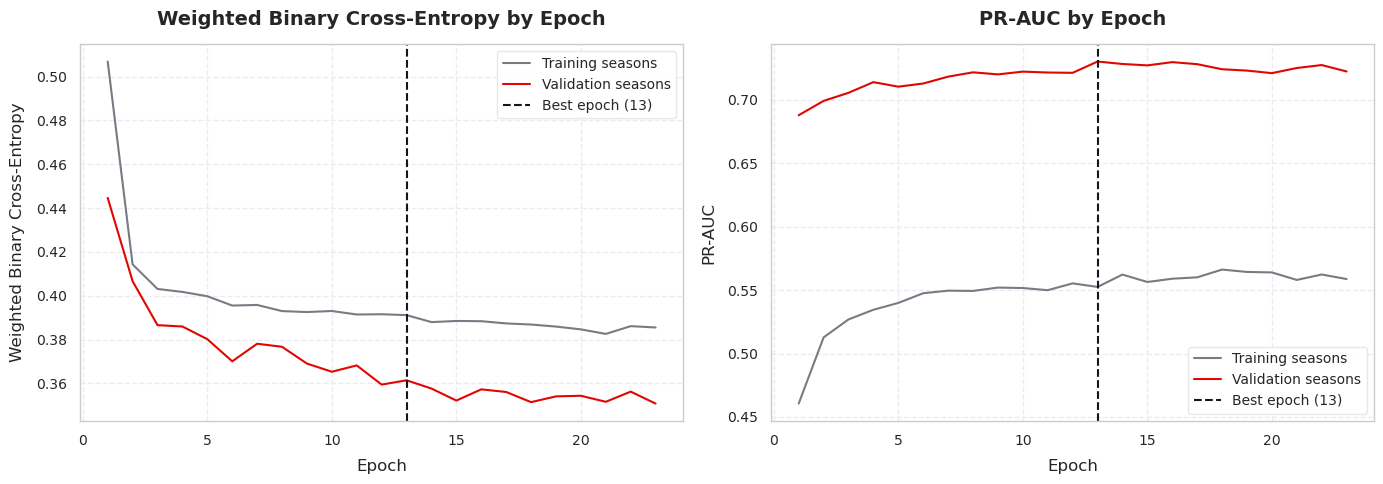

,best epoch,ROC-AUC,PR-AUC
seed,,,
42,13.0,0.9263,0.7330
0,43.0,0.9257,0.7301
1,19.0,0.9259,0.7377
2,19.0,0.9278,0.7308
3,25.0,0.9273,0.7259


Validation PR-AUC over 5 seeds: mean 0.7315, from 0.7259 to 0.7377


In [84]:
# Task 25.3: training history of the chosen network, and how much the result moves with the random seed
best_epoch = int(nn_history["val_pr_auc"].idxmax()) + 1
epochs = nn_history.index + 1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (train_col, val_col, label) in zip(axes, [("loss", "val_loss", "Weighted Binary Cross-Entropy"), ("pr_auc", "val_pr_auc", "PR-AUC")]):
    ax.plot(epochs, nn_history[train_col], color=F1_PALETTE["gray"], label="Training seasons")
    ax.plot(epochs, nn_history[val_col], color=F1_PALETTE["crimson"], label="Validation seasons")
    ax.axvline(best_epoch, color=F1_PALETTE["dark"], linestyle="--", label=f"Best epoch ({best_epoch})")
    ax.set(title=f"{label} by Epoch", xlabel="Epoch", ylabel=label)
    ax.legend()
save_fig("model_nn_training_history")
plt.show()

NN_SEEDS: List[int] = [RANDOM_SEED, 0, 1, 2, 3]
seed_rows = {}
for seed in NN_SEEDS:
    model, history = (neural_net, nn_history) if seed == RANDOM_SEED else fit_neural_net(seed=seed, **NN_CONFIG)
    seed_rows[seed] = {"best epoch": int(history["val_pr_auc"].idxmax()) + 1, **ranking_metrics(y_val, neural_net_scores(model, X_val))}
nn_seed_spread = pd.DataFrame(seed_rows).T.rename_axis("seed")
display(nn_seed_spread.round(4))
print(f"Validation PR-AUC over {len(NN_SEEDS)} seeds: mean {nn_seed_spread['PR-AUC'].mean():.4f}, "
      f"from {nn_seed_spread['PR-AUC'].min():.4f} to {nn_seed_spread['PR-AUC'].max():.4f}")

**Result: validation PR-AUC 0.733 with two hidden layers of 64 and 32 units and a dropout of 0.2.**

- **The eight architectures are close:** their five-seed means range from 0.725 to 0.732. The chosen network has 3,521 parameters; with seed 42 it stopped after 23 epochs, keeping the weights of epoch 13.
- **The random seed moves the score more than the architecture does.** For a single architecture, five seeds span 0.008 to 0.026 PR-AUC; the eight means span 0.006. The 64 → 32 layout has the highest mean and is the layout named in the plan, but its lead is not measurable. On seed 42 alone, a single layer of 64 units with dropout 0.4 would have been chosen (0.739 on that seed, 0.731 on average).
- **Reading the curves.** The validation loss stays below the training loss for the reason given in Task 22: the training seasons are harder. Both losses are still falling slowly when training stops, while validation PR-AUC levels off after about epoch 13. The network is not overfitting; training stops because the main metric has stopped improving.
- **One caveat.** Early stopping picks the epoch with the best validation PR-AUC, so the network's validation score is slightly flattering. Its test score in Task 28 is the fair one.

## Task 26: Does Class Weighting Help?

The plan asks for class weighting in every model. This task measures what it does: each model is refitted with the same settings but without weights, and the two versions are compared on validation.

Two things are reported: the PR-AUC (does weighting change the ranking?) and the average predicted probability (does it change the meaning of the output?). The true podium rate on validation is 15.1%.

In [85]:
# Task 26: each model with and without class weights, same hyperparameters (DEC-027)
unweighted_scores = {
    LOGISTIC: LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_SEED).fit(X_train_prep, y_train).predict_proba(X_val_prep)[:, 1],
    FOREST: make_forest(**FOREST_PARAMS).set_params(class_weight=None).fit(X_train_prep, y_train).predict_proba(X_val_prep)[:, 1],
    LGBM: make_lgbm(class_weight=None, **LGBM_PARAMS).fit(X_train, y_train).predict_proba(X_val)[:, 1],
    NEURAL_NET: neural_net_scores(fit_neural_net(class_weight=None, **NN_CONFIG)[0], X_val),
}

weighting_rows = {}
for name, unweighted in unweighted_scores.items():
    pair = compare_models(val_df, {"weighted": val_scores[name], "unweighted": unweighted}, "weighted")
    weighting_rows[name] = {
        "val PR-AUC, weighted": pair.loc["weighted", "PR-AUC"], "val PR-AUC, unweighted": pair.loc["unweighted", "PR-AUC"],
        "Δ (unweighted − weighted)": pair.loc["unweighted", "PR-AUC Δ vs. reference"],
        "Δ 95% low": pair.loc["unweighted", "Δ 95% low"], "Δ 95% high": pair.loc["unweighted", "Δ 95% high"],
        "mean probability, weighted": val_scores[name].mean(), "mean probability, unweighted": unweighted.mean(),
    }
weighting_check = pd.DataFrame(weighting_rows).T
display(weighting_check.round(4))
print(f"Podium rate on validation: {y_val.mean():.4f}")

,"val PR-AUC, weighted","val PR-AUC, unweighted",Δ (unweighted − weighted),Δ 95% low,Δ 95% high,"mean probability, weighted","mean probability, unweighted"
Logistic regression,0.7262,0.7286,0.0024,-0.0046,0.0105,0.3185,0.1461
Random forest,0.7347,0.7274,-0.0072,-0.0215,0.0151,0.3357,0.1545
LightGBM,0.7425,0.7263,-0.0163,-0.0316,0.0053,0.3210,0.1431
Neural network,0.7330,0.7195,-0.0135,-0.0315,0.0085,0.3143,0.1378


Podium rate on validation: 0.1510


**Result (DEC-027): weighting does not change the ranking measurably, but it doubles the predicted probabilities.**

- **PR-AUC.** Without weights the logistic regression gains 0.002; the forest loses 0.007, LightGBM 0.016 and the network 0.014. Every 95% interval includes zero.
- **Probabilities.** With weights, the average predicted probability on validation is 0.31 to 0.34, twice the true podium rate of 0.151. Without weights it is 0.14 to 0.15.

Class weights are kept, as the plan asks: they do not hurt the ranking and three of four models score slightly higher with them. The consequence is that **the output of these models is a score, not a calibrated probability.** A value of 0.5 does not mean a 50% chance of a podium. This is why the thresholds in Task 27 are well above 0.5, and Step 9 has to say so (or recalibrate) when it reports a probability.

## Task 27: Decision Thresholds and Model Choice

**DEC-028.** A model gives each driver a score. Two rules turn the scores into predicted podiums:

- **A threshold tuned for F1.** For each model, the threshold with the highest F1 on the validation seasons. This is the main rule. The grid rule keeps its fixed cut at third place.
- **Top 3 per race.** The three highest-scoring drivers of each race are predicted as the podium. It uses a fact the threshold ignores, that every race has exactly three podium places, and it has nothing to tune.

,threshold,"F1, tuned threshold","Precision, tuned threshold","Recall, tuned threshold",predicted podiums per race,"F1, threshold 0.5","F1, top 3 per race"
Grid ≤ 3 rule,-3.0000,0.6953,0.6983,0.6923,2.9744,NaN,0.7009
Logistic regression,0.5866,0.7111,0.6275,0.8205,3.9231,0.6435,0.6923
Random forest,0.7580,0.7102,0.6797,0.7436,3.2821,0.6034,0.6752
LightGBM,0.7473,0.7113,0.6967,0.7265,3.1282,0.6383,0.6923
Neural network,0.7400,0.7097,0.6718,0.7521,3.3590,0.6186,0.7009


[FIGURE SAVED] figures/model_threshold_f1.png


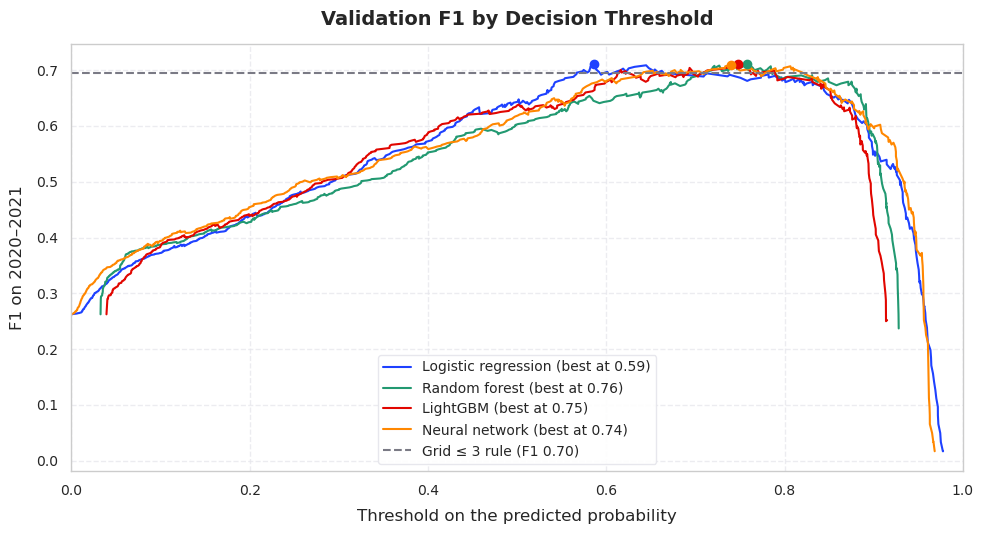

In [86]:
# Task 27.1: decision thresholds chosen on the validation seasons (DEC-028)
LEARNED_MODELS: List[str] = [LOGISTIC, FOREST, LGBM, NEURAL_NET]
MODEL_COLORS: Dict[str, str] = {GRID_RULE: F1_PALETTE["gray"], LOGISTIC: F1_PALETTE["blue"], FOREST: F1_PALETTE["green"],
                                LGBM: F1_PALETTE["crimson"], NEURAL_NET: F1_PALETTE["orange"]}

THRESHOLDS: Dict[str, float] = {name: best_f1_threshold(y_val, val_scores[name]) for name in LEARNED_MODELS}
THRESHOLDS[GRID_RULE] = -float(GRID_RULE_CUTOFF)   # fixed, not tuned: score >= -3 means grid <= 3


def predict_with_threshold(name: str, scores: np.ndarray) -> np.ndarray:
    return (scores >= THRESHOLDS[name]).astype(int)


threshold_rows = {}
for name in PREDICTORS:
    tuned = predict_with_threshold(name, val_scores[name])
    top3 = top3_per_race(val_df["raceId"], val_scores[name])
    threshold_rows[name] = {
        "threshold": THRESHOLDS[name], **{f"{k}, tuned threshold": v for k, v in decision_metrics(y_val, tuned).items()},
        "predicted podiums per race": tuned.sum() / val_df["raceId"].nunique(),
        "F1, threshold 0.5": decision_metrics(y_val, (val_scores[name] >= 0.5).astype(int))["F1"] if name in LEARNED_MODELS else np.nan,
        "F1, top 3 per race": decision_metrics(y_val, top3)["F1"],
    }
threshold_table = pd.DataFrame(threshold_rows).T
display(threshold_table.round(4))

fig, ax = plt.subplots(figsize=(10, 5.5))
for name in LEARNED_MODELS:
    precision, recall, thresholds = precision_recall_curve(y_val, val_scores[name])
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    ax.plot(thresholds, f1, color=MODEL_COLORS[name], label=f"{name} (best at {THRESHOLDS[name]:.2f})")
    ax.scatter([THRESHOLDS[name]], [f1.max()], color=MODEL_COLORS[name], zorder=3)
ax.axhline(grid_rule_val["F1"], color=MODEL_COLORS[GRID_RULE], linestyle="--", label=f"{GRID_RULE} (F1 {grid_rule_val['F1']:.2f})")
ax.set(title="Validation F1 by Decision Threshold", xlabel="Threshold on the predicted probability", ylabel="F1 on 2020–2021", xlim=(0, 1))
ax.legend(loc="lower center")
save_fig("model_threshold_f1")
plt.show()

**Result: thresholds between 0.59 and 0.76, and a validation F1 of 0.71.**

- **The tuned thresholds** are 0.59 (logistic regression), 0.76 (forest), 0.75 (LightGBM) and 0.74 (network). They sit above 0.5 because of the class weights. At the default 0.5 the F1 would be 0.60 to 0.64, below the grid rule.
- **The gain over the grid rule is small:** F1 0.710 to 0.711 against 0.695.
- **The exact threshold is not well determined.** Each curve in the figure is nearly flat from about 0.6 to 0.85, and its peak is a small bump on that plateau. With 117 podiums in validation, the position of the peak is partly chance, so these thresholds may not suit the test seasons as well.
- **Top 3 per race** gives an F1 of 0.675 to 0.701 on validation, no better than the tuned thresholds. It is kept as a comparison for Task 28, where it has the advantage of not depending on validation at all.

In [87]:
# Task 27.2: validation comparison and the model carried forward (DEC-029)
validation_comparison = compare_models(val_df, val_scores, LOGISTIC)
display(validation_comparison.round(4))

SELECTED_MODEL: str = validation_comparison.loc[LEARNED_MODELS, "PR-AUC"].idxmax()
print(f"Highest validation PR-AUC: {SELECTED_MODEL} ({validation_comparison.loc[SELECTED_MODEL, 'PR-AUC']:.4f}). "
      f"Chosen before the test seasons are scored.")

,ROC-AUC,PR-AUC,PR-AUC 95% low,PR-AUC 95% high,PR-AUC Δ vs. reference,Δ 95% low,Δ 95% high
Grid ≤ 3 rule,0.9102,0.6478,0.5478,0.7620,-0.0784,-0.1345,-0.0153
Logistic regression,0.9286,0.7262,0.6145,0.8401,0.0000,0.0000,0.0000
Random forest,0.9299,0.7347,0.6191,0.8519,0.0084,-0.0270,0.0315
LightGBM,0.9306,0.7425,0.6255,0.8536,0.0163,-0.0098,0.0372
Neural network,0.9263,0.7330,0.6242,0.8445,0.0068,-0.0119,0.0235


Highest validation PR-AUC: LightGBM (0.7425). Chosen before the test seasons are scored.


**Result (DEC-029): LightGBM is carried forward, but validation cannot separate the four learned models.**

- **All four beat the grid rule.** The rule is 0.078 below the logistic regression (95% interval −0.135 to −0.015).
- **None is clearly better than the logistic regression.** The forest is +0.008, LightGBM +0.016 and the network +0.007; all three intervals include zero.

The rule for choosing was fixed beforehand: the highest validation PR-AUC. That is LightGBM (0.743). It is also the most convenient model for the next steps, since it takes the raw features and works with the SHAP `TreeExplainer`.

## Task 28: Final Evaluation on the Test Seasons

Everything is now fixed: the hyperparameters, the stopping epoch of the network, the thresholds and the selected model. **DEC-030.** The models stay as fitted on the seasons up to 2019; they are not refitted on train + validation, so the model described by the validation column is the model that is scored on test.

This is the only task in the notebook where the test seasons (2022–2024, 68 races) are scored.

In [88]:
# Task 28.1: every model on every split. The test seasons are scored here and nowhere else.
SPLIT_FRAMES: Dict[str, pd.DataFrame] = {"train": train_df, "validation": val_df, "test": test_df}
split_scores: Dict[str, Dict[str, np.ndarray]] = {
    split: {name: predict(frame[FEATURE_COLUMNS]) for name, predict in PREDICTORS.items()} for split, frame in SPLIT_FRAMES.items()
}

MODEL_RESULTS = pd.DataFrame({
    (name, split): {**ranking_metrics(frame[TARGET_COLUMN], split_scores[split][name]),
                    **decision_metrics(frame[TARGET_COLUMN], predict_with_threshold(name, split_scores[split][name]))}
    for name in PREDICTORS for split, frame in SPLIT_FRAMES.items()
}).T.rename_axis(["model", "split"])
display(MODEL_RESULTS.round(4))
display(MODEL_RESULTS["PR-AUC"].unstack("split")[list(SPLIT_FRAMES)].loc[list(PREDICTORS)].round(4))

ROC-AUC  PR-AUC      F1  Precision  Recall
model               split                                                 
Grid ≤ 3 rule       train        0.8837  0.4995  0.5448     0.5450  0.5446
                    validation   0.9102  0.6478  0.6953     0.6983  0.6923
                    test         0.9134  0.6474  0.6486     0.6502  0.6471
Logistic regression train        0.9013  0.5622  0.5693     0.4408  0.8036
                    validation   0.9286  0.7262  0.7111     0.6275  0.8205
                    test         0.9365  0.7116  0.6703     0.5282  0.9167
Random forest       train        0.9062  0.5872  0.5870     0.5288  0.6595
                    validation   0.9299  0.7347  0.7102     0.6797  0.7436
                    test         0.9383  0.7070  0.6710     0.5977  0.7647
LightGBM            train        0.9092  0.5903  0.5868     0.5354  0.6491
                    validation   0.9306  0.7425  0.7113     0.6967  0.7265
                    test         0.9393  0.7088  0.6841     0.6157  0.7696
Neural network      train        0.9070  0.5854  0.5902     0.5215  0.6798
                    validation   0.9263  0.7330  0.7097     0.6718  0.7521
                    test         0.9371  0.7203  0.6751     0.5897  0.7892

split,train,validation,test
model,,,
Grid ≤ 3 rule,0.4995,0.6478,0.6474
Logistic regression,0.5622,0.7262,0.7116
Random forest,0.5872,0.7347,0.7070
LightGBM,0.5903,0.7425,0.7088
Neural network,0.5854,0.7330,0.7203


In [89]:
# Task 28.2: is any model really better than the logistic regression on the test seasons?
test_comparison = compare_models(test_df, split_scores["test"], LOGISTIC)
display(test_comparison.round(4))

,ROC-AUC,PR-AUC,PR-AUC 95% low,PR-AUC 95% high,PR-AUC Δ vs. reference,Δ 95% low,Δ 95% high
Grid ≤ 3 rule,0.9134,0.6474,0.5928,0.7089,-0.0643,-0.1176,-0.0107
Logistic regression,0.9365,0.7116,0.6536,0.7745,0.0000,0.0000,0.0000
Random forest,0.9383,0.7070,0.6524,0.7693,-0.0047,-0.0340,0.0221
LightGBM,0.9393,0.7088,0.6467,0.7738,-0.0029,-0.0297,0.0207
Neural network,0.9371,0.7203,0.6628,0.7805,0.0087,-0.0093,0.0246


[FIGURE SAVED] figures/model_pr_curves.png


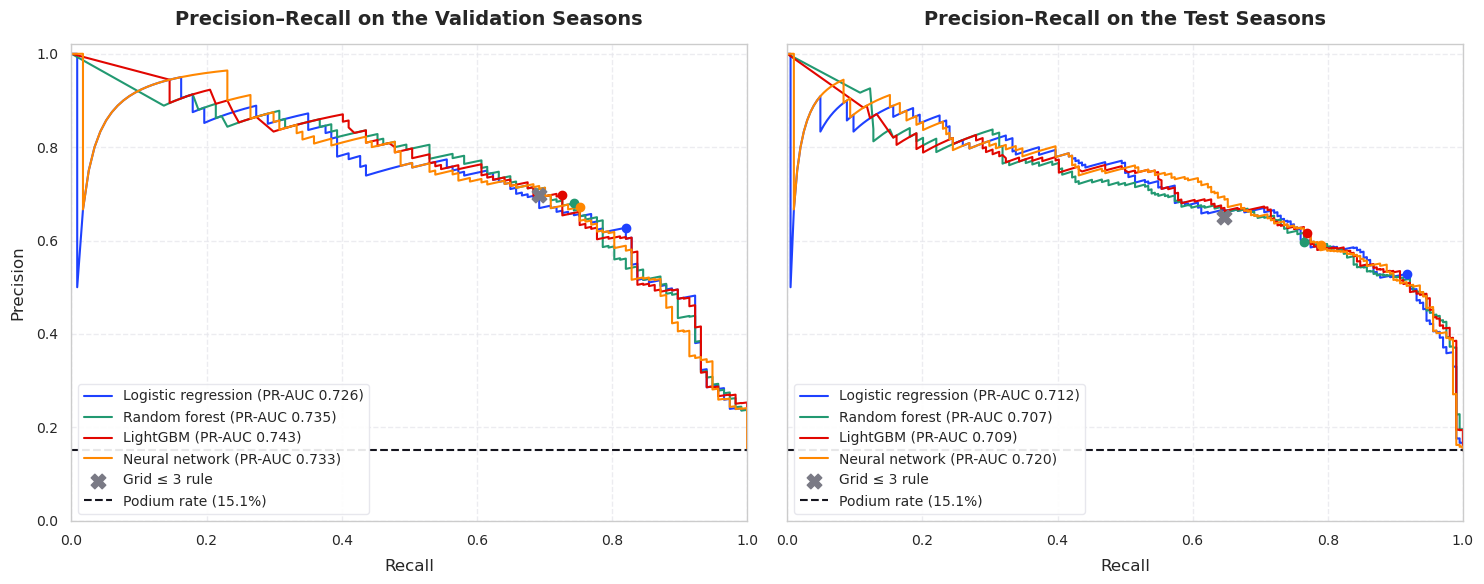

[FIGURE SAVED] figures/model_comparison.png


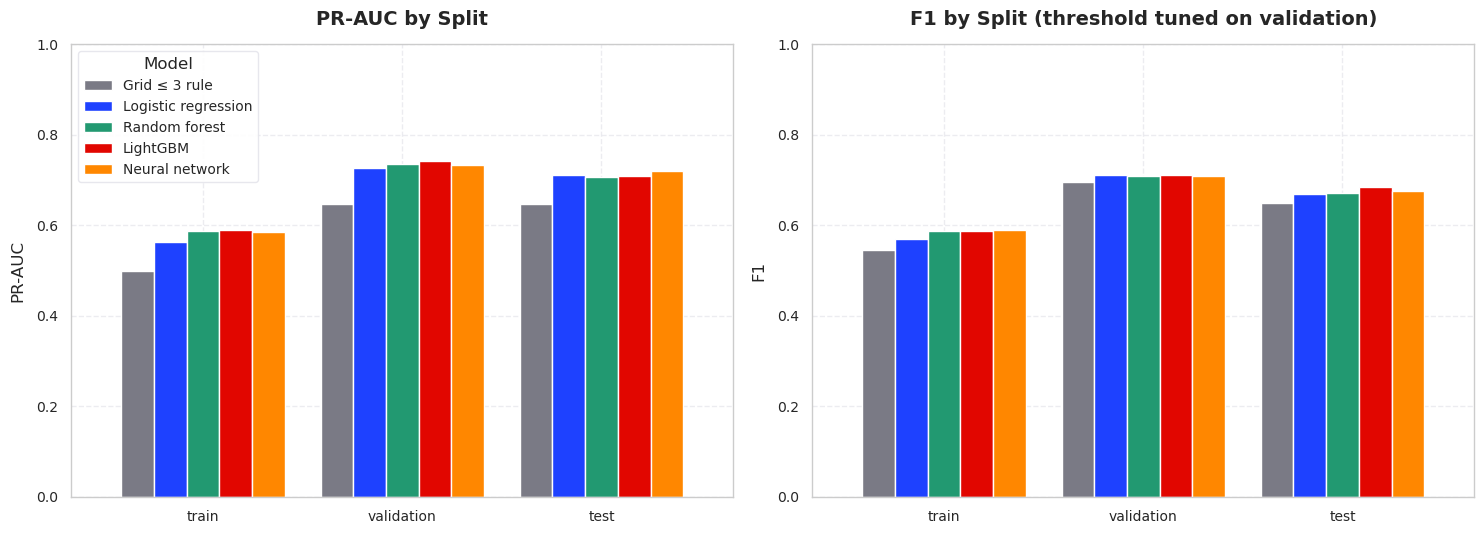

In [90]:
# Task 28.3: precision-recall curves, and the two main metrics by split
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, split in zip(axes, ["validation", "test"]):
    y = SPLIT_FRAMES[split][TARGET_COLUMN]
    for name in LEARNED_MODELS:
        precision, recall, _ = precision_recall_curve(y, split_scores[split][name])
        ax.plot(recall, precision, color=MODEL_COLORS[name], label=f"{name} (PR-AUC {MODEL_RESULTS.loc[(name, split), 'PR-AUC']:.3f})")
        ax.scatter([MODEL_RESULTS.loc[(name, split), "Recall"]], [MODEL_RESULTS.loc[(name, split), "Precision"]], color=MODEL_COLORS[name], zorder=3)
    ax.scatter([MODEL_RESULTS.loc[(GRID_RULE, split), "Recall"]], [MODEL_RESULTS.loc[(GRID_RULE, split), "Precision"]], marker="X", s=110,
               color=MODEL_COLORS[GRID_RULE], zorder=3, label=GRID_RULE)
    ax.axhline(y.mean(), color=F1_PALETTE["dark"], linestyle="--", label=f"Podium rate ({y.mean():.1%})")
    ax.set(title=f"Precision–Recall on the {split.capitalize()} Seasons", xlabel="Recall", xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc="lower left")
axes[0].set_ylabel("Precision")
save_fig("model_pr_curves")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, metric in zip(axes, ["PR-AUC", "F1"]):
    by_split = MODEL_RESULTS[metric].unstack("model")[list(PREDICTORS)].loc[list(SPLIT_FRAMES)]
    by_split.plot(kind="bar", ax=ax, color=[MODEL_COLORS[name] for name in by_split.columns], width=0.82, rot=0, legend=False)
    ax.set(title=f"{metric} by Split" + (" (threshold tuned on validation)" if metric == "F1" else ""), xlabel="", ylabel=metric, ylim=(0, 1))
axes[0].legend(title="Model", loc="upper left")
save_fig("model_comparison")
plt.show()

,"F1, tuned threshold","Precision, tuned threshold","Recall, tuned threshold",predicted podiums per race,"F1, top 3 per race","podium places right per race, top 3"
Grid ≤ 3 rule,0.6486,0.6502,0.6471,2.9853,0.6520,1.9559
Logistic regression,0.6703,0.5282,0.9167,5.2059,0.6569,1.9706
Random forest,0.6710,0.5977,0.7647,3.8382,0.6667,2.0000
LightGBM,0.6841,0.6157,0.7696,3.7500,0.6569,1.9706
Neural network,0.6751,0.5897,0.7892,4.0147,0.6471,1.9412


[FIGURE SAVED] figures/model_confusion_matrix.png


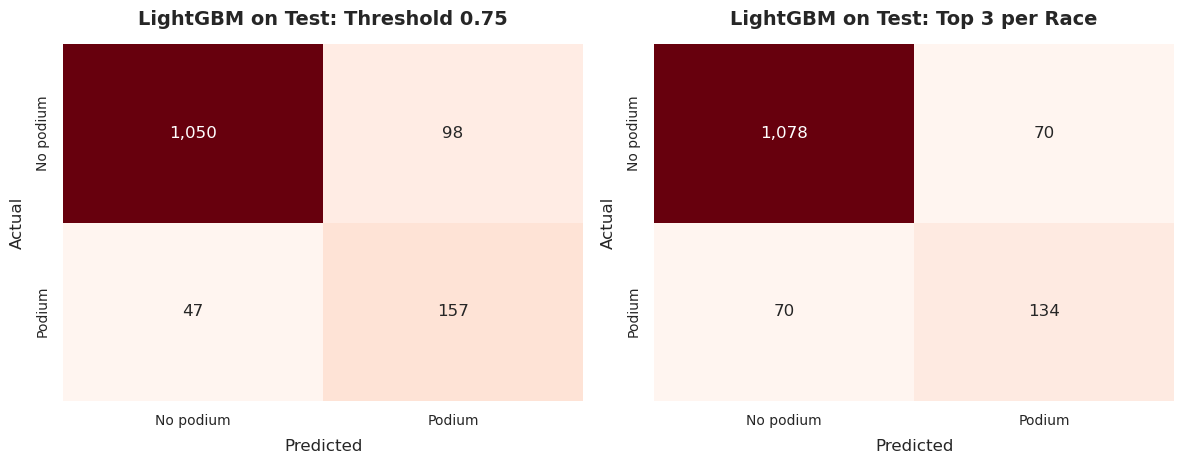

In [91]:
# Task 28.4: the two decision rules on the test seasons, and the confusion matrices of the selected model
y_test_array, test_races = test_df[TARGET_COLUMN].to_numpy(), test_df["raceId"]
rule_rows = {}
for name in PREDICTORS:
    tuned, top3 = predict_with_threshold(name, split_scores["test"][name]), top3_per_race(test_races, split_scores["test"][name])
    rule_rows[name] = {**{f"{k}, tuned threshold": v for k, v in decision_metrics(y_test_array, tuned).items()},
                       "predicted podiums per race": tuned.sum() / test_races.nunique(),
                       "F1, top 3 per race": decision_metrics(y_test_array, top3)["F1"],
                       "podium places right per race, top 3": (top3 * y_test_array).sum() / test_races.nunique()}
test_decision_rules = pd.DataFrame(rule_rows).T
display(test_decision_rules.round(4))

selected_test = split_scores["test"][SELECTED_MODEL]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (title, predicted) in zip(axes, [(f"Threshold {THRESHOLDS[SELECTED_MODEL]:.2f}", predict_with_threshold(SELECTED_MODEL, selected_test)),
                                         ("Top 3 per Race", top3_per_race(test_races, selected_test))]):
    sns.heatmap(confusion_matrix(y_test_array, predicted), annot=True, fmt=",d", cmap="Reds", cbar=False, ax=ax,
                xticklabels=["No podium", "Podium"], yticklabels=["No podium", "Podium"])
    ax.set(title=f"{SELECTED_MODEL} on Test: {title}", xlabel="Predicted", ylabel="Actual")
save_fig("model_confusion_matrix")
plt.show()

### Results on the test seasons

**1. The extra features are worth about 0.06 PR-AUC over the grid rule.** On test the rule scores 0.647 and the four learned models 0.707 to 0.720. The rule is 0.064 below the logistic regression (95% interval −0.118 to −0.011).

**2. Model complexity adds nothing measurable.**

| Model | Validation PR-AUC | Test PR-AUC | Test difference to logistic regression (95% interval) |
| :--- | :--- | :--- | :--- |
| Grid ≤ 3 rule | 0.648 | 0.647 | −0.064 (−0.118 to −0.011) |
| Logistic regression | 0.726 | 0.712 | reference |
| Random forest | 0.735 | 0.707 | −0.005 (−0.034 to +0.022) |
| LightGBM | 0.743 | 0.709 | −0.003 (−0.030 to +0.021) |
| Neural network | 0.733 | 0.720 | +0.009 (−0.009 to +0.025) |

The untuned logistic regression is level with the forest and LightGBM. The network scores highest on test, but by less than the width of its interval. The small leads the forest and LightGBM had on validation did not carry over.

**3. Tuning on a small validation set flattered the forest and LightGBM.** From validation to test the logistic regression loses 0.015, the forest 0.028, LightGBM 0.034 and the network 0.013. The two models whose settings were picked as the best of 20 and 40 candidates on 39 races fall furthest, and their validation numbers should be read as optimistic. The network, whose architecture was chosen from 8 candidates by its mean over five seeds, falls no further than the untuned model.

**4. LightGBM stays the selected model.** It was chosen before the test seasons were scored and that choice is not revisited. On test it is equal to the logistic regression, so the logistic regression would be an equally defensible choice and is the simpler one. Step 7 and Step 8 can use either.

**5. The tuned thresholds are too low for the test seasons.** They predict 3.8 to 5.2 podiums per race on test, against 3.1 to 3.9 on validation. Recall rises (0.76 to 0.92) and precision falls (0.53 to 0.62). The test F1 is 0.670 to 0.684, against 0.649 for the grid rule. For LightGBM at its threshold: 157 podiums found, 47 missed, 98 false alarms.

**6. Top 3 per race gets about two of the three podium places right, the same as the grid rule.** Its F1 on test is 0.647 to 0.667 for the learned models and 0.652 for the rule (1.94 to 2.00 correct places per race, against 1.96). When exactly three drivers must be named, the models do not beat the starting grid. Their advantage is in ranking the whole field: which drivers outside the first three grid slots have a real chance, and which of the first three do not. The tuned threshold remains the main decision rule (DEC-028).

**7. Training scores are the lowest in every row** (PR-AUC 0.50 to 0.59), for the reason given in Task 22. No model shows a training score far above its validation score, so none of the final models is overfitted.

## Hand-Off

| Object | Contents |
| :--- | :--- |
| `PREDICTORS` | Model name → function that takes raw feature rows (`FEATURE_COLUMNS`) and returns podium scores, for all five models |
| `THRESHOLDS`, `predict_with_threshold()` | The decision threshold of each model, chosen on validation |
| `SELECTED_MODEL` | `"LightGBM"`, the model carried into Steps 7 to 9 |
| `lgbm_model`, `logistic_model`, `forest_model`, `neural_net` | The fitted models |
| `LGBM_PARAMS`, `FOREST_PARAMS`, `NN_CONFIG` | The chosen hyperparameters |
| `make_lgbm()`, `make_forest()`, `fit_neural_net()` | Build an unfitted model, to retrain on other columns or rows |
| `MODEL_RESULTS` | All metrics per model and split (the comparison table for the report) |
| `compare_models()`, `top3_per_race()` | Race-bootstrap comparison on any split; the top-3 decision rule |

**Keep in mind for Steps 7 to 9**

- **Step 7 (ablation):** retrain with `make_lgbm(**LGBM_PARAMS).fit(X_train[columns], y_train)`. LightGBM takes the raw features, so dropping a group needs no change to the preprocessor. Differences below about 0.02 PR-AUC are inside the noise on both validation and test.
- **Step 8 (XAI):** `lgbm_model` works directly with `shap.TreeExplainer` on `X_val`. Its SHAP values are in log-odds of the weighted model.
- **Step 9 (inference):** the model output is a score that is about twice the true probability (Task 26). Report it as a score, or recalibrate it on validation before calling it a probability.
- **The test seasons have now been used.** Any further change to the models or thresholds that is judged on the test scores would turn them into a second validation set.

---
# 8. Step 7: Ablation (M3)

The selected model (LightGBM) is retrained with part of the feature table removed, to measure what each feature group contributes to the score.

**Three rules hold for the whole section**

- **Only the columns change.** Every retrained model uses the Step 6 hyperparameters (`LGBM_PARAMS`), the same training seasons and the same class weights. Nothing is retuned.
- **Both validation and test are reported, and nothing is chosen from either.** The model, its threshold and the feature set stay as fixed in Step 6. The test seasons are scored here to describe the features, not to change the model.
- **Every difference comes with two checks.** A 95% interval from resampling whole races (`compare_models()`), and the same difference averaged over 10 LightGBM seeds.

## Task 29: Ablation Protocol

**DEC-031.** The ablation is run on LightGBM, the model selected in Task 27. It takes the raw features, so a group can be removed without changing an imputer or a scaler.

Three kinds of feature set are compared with the full set of 21 features:

- **Without one group** (Task 30): the six groups of `FEATURE_GROUPS`, one at a time.
- **Without one block** (Task 31): groups that describe the same thing are removed together. `starting position` is grid + qualifying; `past results` is driver form + constructor form + standings; `context` is a block on its own.
- **One group or block alone** (Task 31): the model sees nothing else.

**Why the seed check.** The chosen configuration gives each tree a random 70% of the features (`colsample_bytree = 0.7`). Removing columns changes which features each tree is offered, so part of any difference is the random draw and not the removed group. The cell below shows how much the seed alone moves the score of the full model.

In [92]:
# Task 29.1: the feature sets, and a helper that retrains the selected model on one of them (DEC-031)
ALL_FEATURES: str = "All features"
ABLATION_SPLITS: List[str] = ["validation", "test"]
ABLATION_SEEDS: List[int] = list(range(10))

# Groups that describe the same thing from different sources. Task 31 removes each block as a whole.
FEATURE_BLOCKS: Dict[str, List[str]] = {
    "starting position": ["grid", "qualifying"],
    "past results": ["driver_form", "constructor_form", "standings"],
    "context": ["context"],
}
BLOCK_COLUMNS: Dict[str, List[str]] = {block: [col for group in groups for col in FEATURE_GROUPS[group]]
                                       for block, groups in FEATURE_BLOCKS.items()}
assert sorted(col for cols in BLOCK_COLUMNS.values() for col in cols) == sorted(FEATURE_COLUMNS), "The blocks must cover every feature once"


def all_but(columns: List[str]) -> List[str]:
    return [col for col in FEATURE_COLUMNS if col not in columns]


def ablation_scores(columns: List[str], seed: int = RANDOM_SEED) -> Dict[str, np.ndarray]:
    """Retrain LightGBM with the Step 6 hyperparameters on the given columns; return its podium scores per split."""
    model = make_lgbm(**LGBM_PARAMS).set_params(random_state=seed).fit(X_train[columns], y_train)
    return {split: model.predict_proba(SPLIT_FRAMES[split][columns])[:, 1] for split in ABLATION_SPLITS}


def seed_pr_auc(columns: List[str]) -> pd.DataFrame:
    """PR-AUC per split of the model retrained on the given columns, one row per seed in ABLATION_SEEDS."""
    return pd.DataFrame([{split: average_precision_score(SPLIT_FRAMES[split][TARGET_COLUMN], scores)
                          for split, scores in ablation_scores(columns, seed).items()} for seed in ABLATION_SEEDS], index=ABLATION_SEEDS)


def ablation_table(variants: Dict[str, List[str]]) -> pd.DataFrame:
    """PR-AUC of each feature set on validation and test, and its difference to the model with all features.

    The 95% interval of the difference comes from resampling whole races (compare_models). The last column per split
    repeats the difference with ABLATION_SEEDS as the LightGBM seed and averages it.
    """
    variants = {ALL_FEATURES: FEATURE_COLUMNS, **variants}
    scores = {name: ablation_scores(columns) for name, columns in variants.items()}
    by_seed = {name: seed_pr_auc(columns) for name, columns in variants.items()}
    columns = {("", "features"): {name: len(cols) for name, cols in variants.items()}}
    for split in ABLATION_SPLITS:
        compared = compare_models(SPLIT_FRAMES[split], {name: s[split] for name, s in scores.items()}, ALL_FEATURES)
        columns.update({(split, "PR-AUC"): compared["PR-AUC"], (split, "Δ"): compared["PR-AUC Δ vs. reference"],
                        (split, "Δ 95% low"): compared["Δ 95% low"], (split, "Δ 95% high"): compared["Δ 95% high"],
                        (split, f"Δ, mean of {len(ABLATION_SEEDS)} seeds"): {name: (by_seed[name][split] - by_seed[ALL_FEATURES][split]).mean()
                                                                           for name in variants}})
    return pd.DataFrame(columns).loc[list(variants)]


def plot_delta_bars(ax: plt.Axes, table: pd.DataFrame, rows: List[str], labels: List[str]) -> None:
    """Horizontal bars of the PR-AUC difference per split, with the 95% race-bootstrap interval as error bars."""
    positions, height = np.arange(len(rows)), 0.38
    for offset, split in zip([-height / 2, height / 2], ABLATION_SPLITS):
        delta = table.loc[rows, (split, "Δ")].astype(float)
        errors = [delta - table.loc[rows, (split, "Δ 95% low")].astype(float), table.loc[rows, (split, "Δ 95% high")].astype(float) - delta]
        ax.barh(positions + offset, delta, height=height, color=SPLIT_COLORS[split], label=split.capitalize(),
                xerr=errors, error_kw={"ecolor": F1_PALETTE["dark"], "capsize": 3, "linewidth": 1})
    ax.axvline(0, color=F1_PALETTE["dark"], linewidth=1)
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()


# The reference of every comparison is the Step 6 model itself: same columns, same seed, same scores
reference_scores = ablation_scores(FEATURE_COLUMNS)
assert all(np.allclose(reference_scores[split], split_scores[split][LGBM]) for split in ABLATION_SPLITS)
seed_spread = seed_pr_auc(FEATURE_COLUMNS)
display(seed_spread.agg(["mean", "std", "min", "max"]).round(4))
print(f"All {len(FEATURE_COLUMNS)} features, seed {RANDOM_SEED}: " +
      ", ".join(f"{split} PR-AUC {MODEL_RESULTS.loc[(LGBM, split), 'PR-AUC']:.4f}" for split in ABLATION_SPLITS))

,validation,test
mean,0.7420,0.7115
std,0.0017,0.0027
min,0.7395,0.7073
max,0.7444,0.7171


All 21 features, seed 42: validation PR-AUC 0.7425, test PR-AUC 0.7088


**The seed alone moves PR-AUC by about 0.005 on validation and 0.010 on test.** Over 10 seeds the full model scores 0.740 to 0.744 on validation (mean 0.742) and 0.707 to 0.717 on test (mean 0.712). The Step 6 model (seed 42) is inside both ranges, and the retrained reference reproduces its scores exactly.

## Task 30: Leave One Group Out

Each of the six groups is removed in turn and the model is retrained on the remaining features. `Δ` is the PR-AUC without the group minus the PR-AUC with all features: a negative value means the model is worse without the group.

In [93]:
# Task 30.1: retrain without one feature group at a time
group_ablation = ablation_table({f"without {group}": all_but(cols) for group, cols in FEATURE_GROUPS.items()})
display(group_ablation.round(4))

validation                                                     test                                                 
                         features     PR-AUC       Δ Δ 95% low Δ 95% high Δ, mean of 10 seeds  PR-AUC       Δ Δ 95% low Δ 95% high Δ, mean of 10 seeds
All features                   21     0.7425  0.0000    0.0000     0.0000              0.0000  0.7088  0.0000    0.0000     0.0000              0.0000
without grid                   17     0.7258 -0.0168   -0.0420     0.0058             -0.0203  0.6903 -0.0184   -0.0409     0.0017             -0.0226
without qualifying             17     0.7276 -0.0149   -0.0485     0.0115             -0.0115  0.7224  0.0137   -0.0016     0.0280              0.0116
without driver_form            18     0.7379 -0.0046   -0.0156     0.0072             -0.0053  0.7037 -0.0051   -0.0230     0.0166             -0.0094
without constructor_form       19     0.7399 -0.0027   -0.0128     0.0053             -0.0022  0.7065 -0.0022   -0.0104     0.0051             -0.0038
without standings              17     0.7361 -0.0064   -0.0187     0.0062             -0.0058  0.7090  0.0002   -0.0109     0.0109             -0.0002
without context                17     0.7422 -0.0003   -0.0093     0.0105             -0.0007  0.7108  0.0021   -0.0043     0.0087             -0.0004

[FIGURE SAVED] figures/ablation_leave_one_group_out.png


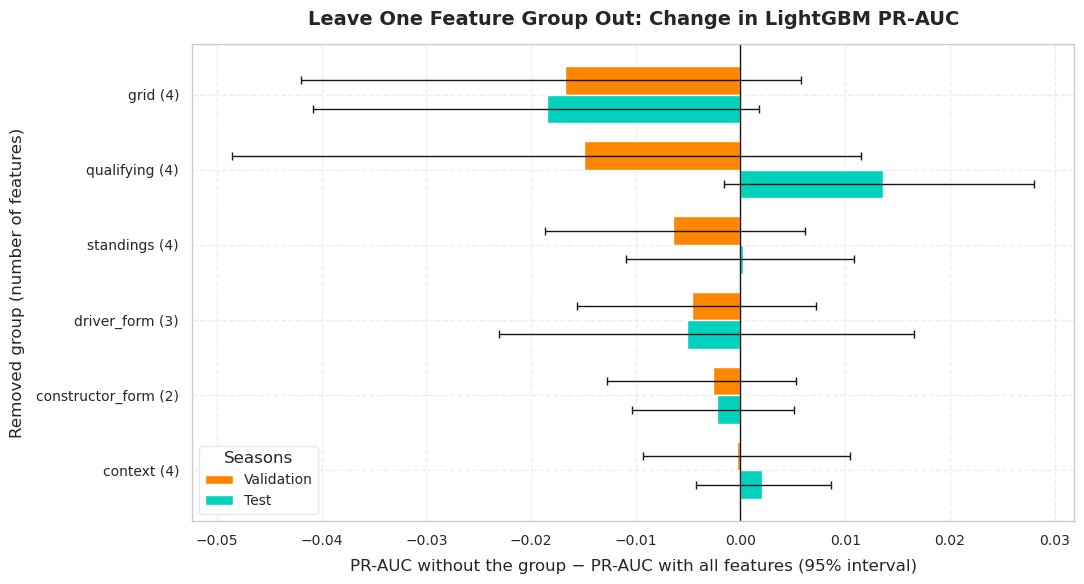

In [94]:
# Task 30.2: the change in PR-AUC when a group is removed
group_rows = group_ablation.drop(index=ALL_FEATURES).sort_values(("validation", "Δ")).index.tolist()
fig, ax = plt.subplots(figsize=(11, 6))
plot_delta_bars(ax, group_ablation, group_rows, [f"{row.removeprefix('without ')} ({len(FEATURE_COLUMNS) - group_ablation.loc[row, ('', 'features')]})"
                                                 for row in group_rows])
ax.set(title=f"Leave One Feature Group Out: Change in {LGBM} PR-AUC", xlabel="PR-AUC without the group − PR-AUC with all features (95% interval)",
       ylabel="Removed group (number of features)")
ax.legend(title="Seasons", loc="lower left")
save_fig("ablation_leave_one_group_out")
plt.show()

**Result: no single group is needed. Every 95% interval includes zero on both validation and test.**

| Removed group | Validation Δ (95% interval) | Test Δ (95% interval) | Seed-averaged Δ, validation / test |
| :--- | :--- | :--- | :--- |
| grid | −0.017 (−0.042 to +0.006) | −0.018 (−0.041 to +0.002) | −0.020 / −0.023 |
| qualifying | −0.015 (−0.049 to +0.012) | +0.014 (−0.002 to +0.028) | −0.012 / +0.012 |
| standings | −0.006 (−0.019 to +0.006) | +0.000 (−0.011 to +0.011) | −0.006 / −0.000 |
| driver_form | −0.005 (−0.016 to +0.007) | −0.005 (−0.023 to +0.017) | −0.005 / −0.009 |
| constructor_form | −0.003 (−0.013 to +0.005) | −0.002 (−0.010 to +0.005) | −0.002 / −0.004 |
| context | −0.000 (−0.009 to +0.011) | +0.002 (−0.004 to +0.009) | −0.001 / −0.000 |

- **Grid is the only group with a cost of the same size everywhere:** about −0.02 on validation, on test and across seeds. Its interval still reaches zero.
- **Qualifying looks important on validation only.** It costs 0.015 there but gains 0.014 on test, and the seed averages split the same way. Standings cost 0.006 on validation and nothing on test. Both are noise at this sample size.
- **Driver form and constructor form cost less than 0.01** on either split.
- **Context contributes nothing:** the score is unchanged without its four features.

**This does not mean the features are useless.** Leave-one-out measures what a group adds *on top of all the others*. Grid and qualifying both say where the car starts; driver form, constructor form and standings all say how the driver and team have been doing. When one group is removed, the model reads the same information from its neighbour. Task 31 removes the neighbours together.

## Task 31: Groups That Overlap

Two more views, to measure the information itself and not one copy of it:

- **Leave one block out:** remove all groups that describe the same thing.
- **One group or block alone:** train on nothing else. This shows how much a set of features carries by itself.

In [95]:
# Task 31.1: remove a whole block of overlapping groups
block_ablation = ablation_table({f"without {block}": all_but(cols) for block, cols in BLOCK_COLUMNS.items() if len(FEATURE_BLOCKS[block]) > 1})
block_ablation.loc["without context"] = group_ablation.loc["without context"]   # a block of one group, already fitted in Task 30
block_ablation[("", "features")] = block_ablation[("", "features")].astype(int)
display(block_ablation.round(4))

validation                                                     test                                                 
                          features     PR-AUC       Δ Δ 95% low Δ 95% high Δ, mean of 10 seeds  PR-AUC       Δ Δ 95% low Δ 95% high Δ, mean of 10 seeds
All features                    21     0.7425  0.0000    0.0000     0.0000              0.0000  0.7088  0.0000    0.0000     0.0000              0.0000
without starting position       13     0.6573 -0.0853   -0.1447    -0.0354             -0.0861  0.5880 -0.1207   -0.1753    -0.0706             -0.1242
without past results            12     0.6782 -0.0643   -0.1076    -0.0179             -0.0531  0.6782 -0.0305   -0.0647     0.0064             -0.0432
without context                 17     0.7422 -0.0003   -0.0093     0.0105             -0.0007  0.7108  0.0021   -0.0043     0.0087             -0.0004

In [96]:
# Task 31.2: train on one group or one block alone
alone_ablation = ablation_table({**{f"only {group}": cols for group, cols in FEATURE_GROUPS.items()},
                                 **{f"only {block}": cols for block, cols in BLOCK_COLUMNS.items() if len(FEATURE_BLOCKS[block]) > 1}})
display(alone_ablation.round(4))

validation                                                     test                                                 
                       features     PR-AUC       Δ Δ 95% low Δ 95% high Δ, mean of 10 seeds  PR-AUC       Δ Δ 95% low Δ 95% high Δ, mean of 10 seeds
All features                 21     0.7425  0.0000    0.0000     0.0000              0.0000  0.7088  0.0000    0.0000     0.0000              0.0000
only grid                     4     0.6371 -0.1054   -0.1497    -0.0587             -0.0869  0.6549 -0.0539   -0.1051    -0.0029             -0.0457
only qualifying               4     0.6700 -0.0725   -0.1179    -0.0166             -0.0716  0.6427 -0.0661   -0.1006    -0.0296             -0.0686
only driver_form              3     0.6310 -0.1115   -0.1788    -0.0524             -0.1070  0.5480 -0.1608   -0.2232    -0.1044             -0.1631
only constructor_form         2     0.5246 -0.2180   -0.2727    -0.1534             -0.2171  0.5072 -0.2016   -0.2668    -0.1325             -0.2043
only standings                4     0.6241 -0.1184   -0.1893    -0.0500             -0.1170  0.5566 -0.1522   -0.2043    -0.1024             -0.1470
only context                  4     0.3888 -0.3537   -0.4564    -0.2479             -0.3540  0.2732 -0.4355   -0.5013    -0.3632             -0.4381
only starting position        8     0.6700 -0.0725   -0.1147    -0.0303             -0.0719  0.6672 -0.0415   -0.0769     0.0021             -0.0453
only past results             9     0.6523 -0.0902   -0.1435    -0.0365             -0.0887  0.5910 -0.1178   -0.1717    -0.0682             -0.1213

[FIGURE SAVED] figures/ablation_blocks_and_alone.png


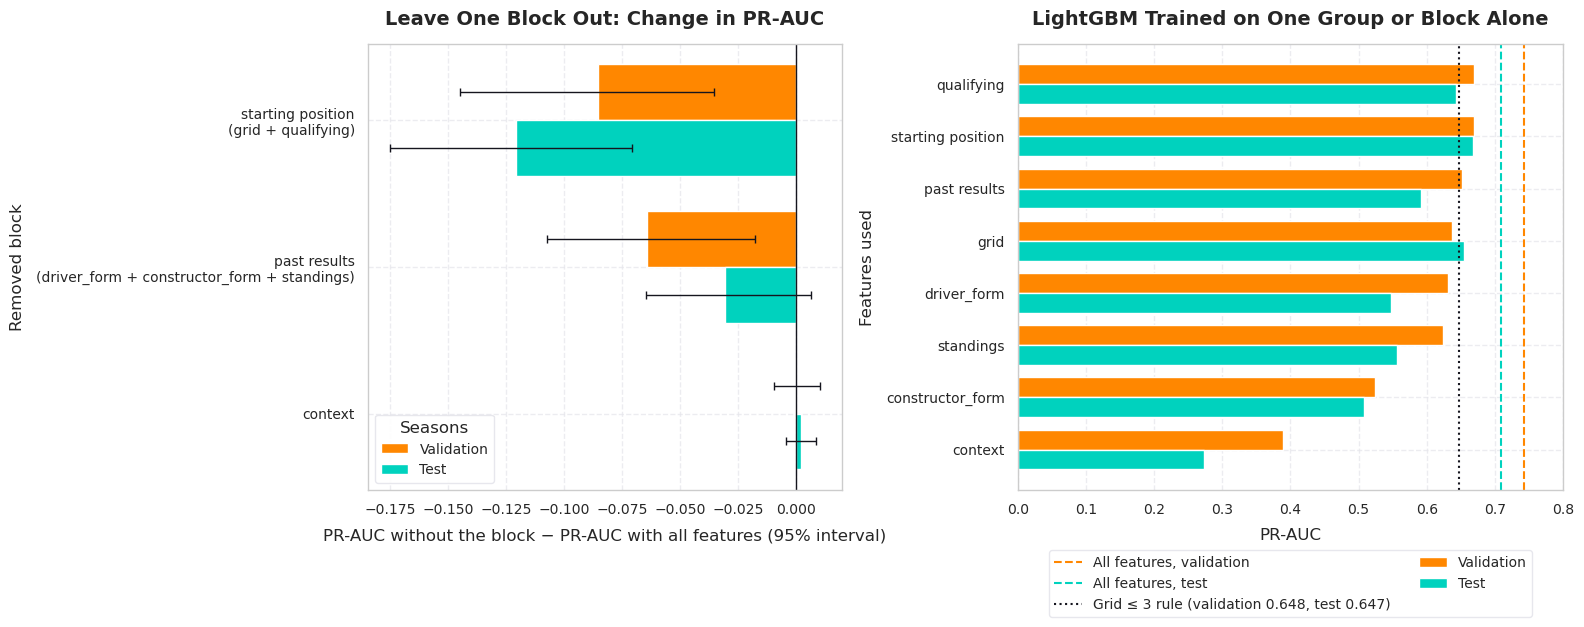

In [97]:
# Task 31.3: blocks removed, and groups and blocks used alone
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.15]})
block_rows = [f"without {block}" for block in FEATURE_BLOCKS]
plot_delta_bars(axes[0], block_ablation, block_rows, [f"{block}\n({' + '.join(groups)})" if len(groups) > 1 else block for block, groups in FEATURE_BLOCKS.items()])
axes[0].set(title="Leave One Block Out: Change in PR-AUC", xlabel="PR-AUC without the block − PR-AUC with all features (95% interval)", ylabel="Removed block")
axes[0].legend(title="Seasons", loc="lower left")

alone_rows = alone_ablation.drop(index=ALL_FEATURES).sort_values(("validation", "PR-AUC"), ascending=False).index.tolist()
positions, height = np.arange(len(alone_rows)), 0.38
for offset, split in zip([-height / 2, height / 2], ABLATION_SPLITS):
    axes[1].barh(positions + offset, alone_ablation.loc[alone_rows, (split, "PR-AUC")].astype(float), height=height, color=SPLIT_COLORS[split], label=split.capitalize())
    axes[1].axvline(alone_ablation.loc[ALL_FEATURES, (split, "PR-AUC")], color=SPLIT_COLORS[split], linestyle="--", label=f"All features, {split}")
grid_rule_pr_auc = MODEL_RESULTS.loc[GRID_RULE, "PR-AUC"]
axes[1].axvline(grid_rule_pr_auc["validation"], color=F1_PALETTE["dark"], linestyle=":",
                label=f"{GRID_RULE} (validation {grid_rule_pr_auc['validation']:.3f}, test {grid_rule_pr_auc['test']:.3f})")
axes[1].set_yticks(positions, [row.removeprefix("only ") for row in alone_rows])
axes[1].invert_yaxis()
axes[1].set(title=f"{LGBM} Trained on One Group or Block Alone", xlabel="PR-AUC", xlim=(0, 0.8), ylabel="Features used")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
save_fig("ablation_blocks_and_alone")
plt.show()

**Result: the starting position carries most of the signal, past results add a smaller amount on top (clear on validation, weaker on test), and context adds nothing.**

| Removed block | Features removed | Validation Δ (95% interval) | Test Δ (95% interval) |
| :--- | :--- | :--- | :--- |
| starting position (grid + qualifying) | 8 | −0.085 (−0.145 to −0.035) | −0.121 (−0.175 to −0.071) |
| past results (driver form + constructor form + standings) | 9 | −0.064 (−0.108 to −0.018) | −0.031 (−0.065 to +0.006) |
| context | 4 | −0.000 (−0.009 to +0.011) | +0.002 (−0.004 to +0.009) |

Removing the starting position costs a clear amount on both splits: both intervals exclude zero, and the seed averages agree (−0.086 on validation, −0.124 on test). Removing past results costs a clear amount on validation (the interval excludes zero; seed average −0.053). On test the seed-42 model loses 0.031 and its interval reaches zero, while the average over 10 seeds loses 0.043.

| Features used alone | Validation PR-AUC | Test PR-AUC |
| :--- | :--- | :--- |
| All 21 features | 0.743 | 0.709 |
| starting position (8) | 0.670 | 0.667 |
| qualifying (4) | 0.670 | 0.643 |
| grid (4) | 0.637 | 0.655 |
| past results (9) | 0.652 | 0.591 |
| driver_form (3) | 0.631 | 0.548 |
| standings (4) | 0.624 | 0.557 |
| constructor_form (2) | 0.525 | 0.507 |
| context (4) | 0.389 | 0.273 |
| *Grid ≤ 3 rule (Step 6)* | *0.648* | *0.647* |

**1. The two halves of a block are substitutes.** Removing grid or qualifying alone costs at most 0.02, but removing both costs 0.09 to 0.12. Each one alone scores about the same as the two together (0.64 to 0.67). The same holds inside the past-results block: its three groups cost less than 0.01 each, but 0.03 to 0.06 together.

**2. Starting position is the larger block.** Without it the model falls to 0.657 on validation, level with the grid rule, and to 0.588 on test, well below it. On its own it scores 0.670 and 0.667, about 0.02 above the rule.

**3. Past results are worth about 0.03 to 0.06 PR-AUC on top of the starting position.** The evidence is firm on validation and weaker on test, where the interval of the selected model reaches zero but the seed average does not. This is the gain that Step 6 found between the grid rule and the learned models, and it is where that gain comes from. Without knowing where the car starts, past results alone reach 0.652 on validation but only 0.591 on test.

**4. The history features transfer less well to the test seasons than the starting position.** Alone, the starting position scores about the same on both splits (0.670 and 0.667), while past results lose 0.061 and driver form 0.083. Validation is 2020–2021 and test is 2022–2024, after the 2022 regulation change; this is consistent with form from before a rule change saying less about results after it, but two splits cannot prove that.

**5. Context can be dropped at no cost.** Field size, round number, home race and the circuit's historical podium rate change neither split, and alone they score 0.39 and 0.27.

**The feature set is not changed (DEC-031).** All 21 features stay in the model. The model was fixed in Step 6 before the test seasons were scored, and removing context now would change it after the fact for no gain in score. A simpler model without the context group is noted as future work.

## Task 31b: Cleaning Choices Tested by Retraining

Two cleaning choices remove rows from the training data. The instructors require evidence for both (Piazza):

- **Withdrawn entries (DEC-009).** Removing `W` rows is allowed only if keeping and removing them is shown to give the same results.
- **The Indianapolis 500 (DEC-003).** The whole dataset should be used, and every exclusion needs evidence.

**DEC-038.** Each choice is reversed on its own: the modeling table is rebuilt with the rows kept, LightGBM is retrained with the Step 6 hyperparameters, and the logistic regression is retrained as a second check.

- **Same evaluation rows.** Every variant is scored on the same validation and test rows: the rows the cleaned table contains (the 5 validation and 7 test `W` rows are left out, since no variant can be compared on them).
- **Decision rule.** A removal stands unless putting the rows back makes the selected model measurably *better* on validation: the 95% interval of the difference lies above zero, or the seed-averaged difference is positive and larger than the seed-to-seed spread of the full model (Task 29). The verdict also says whether the two versions give the same results, which is what the instructors asked to see, or whether the model is better without the rows. (A first draft of this rule called for the rows to go back whenever the results differed in either direction. That would restore rows that make the model worse, so the rule was made one-sided before this cell was added to the notebook.)
- **Kept rows are cleaned the same way as the others.** A kept withdrawn entry has no pit-lane flag, gets a slot behind the last car (DEC-010) and is not counted in `field_size`, since the driver did not start. A kept Indianapolis 500 gets its own circuit identifier, because `circuitId` 19 is also the road course used for the 2000–2007 United States GP, and a driver's record on one should not count on the other.

In [98]:
# Task 31.4: rebuild the modeling table with a cleaning choice reversed (DEC-038)
INDY_OVAL_CIRCUIT_ID: int = int(cleaned_dataframes["circuits"]["circuitId"].max()) + 1   # the oval gets its own circuit history


def rebuild_model_table(keep_withdrawn: bool = False, keep_indy: bool = False) -> pd.DataFrame:
    """Tasks 5–7 and 12 in one function, with two removals that can be reversed.

    keep_withdrawn  keep the zero-lap withdrawn entries (`W`, or status `Withdrew`) that DEC-009 removes. They did not start:
                    no pit-lane flag, a slot behind the last car (DEC-010), not counted in field_size.
    keep_indy       keep the Indianapolis 500 races of 1950–1960 that DEC-003 removes, with the oval as its own circuit.
    With both False the result equals model_df (asserted below).
    """
    work = (raw_dataframes["results"]
            .merge(races[["raceId", "year", "name"]].rename(columns={"name": "race_name"}), on="raceId", how="left", validate="many_to_one")
            .merge(cleaned_dataframes["status"], on="statusId", how="left", validate="many_to_one"))
    is_indy = work["year"].between(1950, 1960) & work["race_name"].str.contains("Indianapolis 500", case=False, na=False)
    work = work if keep_indy else work[~is_indy]

    # DEC-009, with the withdrawn entries optionally kept
    flagged = work["positionText"].isin(NON_START_POSITION_TEXT) | work["status"].isin(NON_START_STATUSES)
    did_not_start = (work["laps"] == 0) & (flagged | (work["grid"] == 0))
    withdrawn = did_not_start & (work["positionText"].eq("W") | work["status"].eq("Withdrew"))
    work = work[~did_not_start | (withdrawn & keep_withdrawn)].assign(withdrawn=withdrawn)

    # DEC-010: a slot behind the last car; the pit-lane flag only for drivers who started
    no_slot = work["grid"] == 0
    work["pit_start"] = (no_slot & ~work["withdrawn"]).astype(int)
    work.loc[no_slot, "grid"] = work.groupby("raceId")["grid"].transform("max")[no_slot] + 1

    # DEC-034: field size counts starters, before shared cars are removed
    work["field_size"] = work[~work["withdrawn"]].groupby("raceId")["driverId"].transform("nunique")
    work["field_size"] = work.groupby("raceId")["field_size"].transform("max")
    own_cars = work[work.groupby(CAR_KEY)["driverId"].transform("nunique") == 1]
    work = own_cars[~own_cars.duplicated(subset=GRAIN, keep=False)]

    base = (work.merge(races[["raceId", "round", "circuitId", "date"]], on="raceId", how="left", validate="many_to_one")
                .merge(cleaned_dataframes["circuits"][["circuitId", "country"]].rename(columns={"country": "circuit_country"}),
                       on="circuitId", how="left", validate="many_to_one"))
    indy_rows = base["year"].between(1950, 1960) & base["race_name"].str.contains("Indianapolis 500", case=False, na=False)
    base.loc[indy_rows, "circuitId"] = INDY_OVAL_CIRCUIT_ID
    base[TARGET_COLUMN] = (base["positionOrder"] <= 3).astype(int)
    base = (base[IDENTIFIER_COLUMNS + ["round", "circuitId", "circuit_country", "grid", "pit_start", "field_size"] + OUTCOME_COLUMNS]
            .sort_values(["date", "raceId", "driverId"]).reset_index(drop=True))
    return build_feature_table(base, qualifying_clean, cleaned_dataframes["driver_standings"], cleaned_dataframes["constructor_standings"])


# The rebuild with nothing reversed must be the modeling table itself, or the comparison below means nothing
pd.testing.assert_frame_equal(rebuild_model_table().reset_index(drop=True), model_df.reset_index(drop=True))
DATA_VARIANTS: Dict[str, Dict[str, bool]] = {"As cleaned": {}, "Withdrawn entries kept": {"keep_withdrawn": True},
                                            "Indianapolis 500 kept": {"keep_indy": True}}
variant_tables = {name: rebuild_model_table(**options) for name, options in DATA_VARIANTS.items()}
display(pd.DataFrame({name: {"rows": len(t), "training rows": int((t["year"] <= TRAIN_MAX_YEAR).sum()),
                             "training podium %": t.loc[t["year"] <= TRAIN_MAX_YEAR, TARGET_COLUMN].mean() * 100}
                      for name, t in variant_tables.items()}).T.round(2))
print("rebuild_model_table() with nothing reversed reproduces model_df exactly")

,rows,training rows,training podium %
As cleaned,24482.0,22355.0,13.44
Withdrawn entries kept,24813.0,22674.0,13.25
Indianapolis 500 kept,24814.0,22687.0,13.37


rebuild_model_table() with nothing reversed reproduces model_df exactly


In [99]:
# Task 31.5: retrain on each variant and compare on the same validation and test rows (DEC-038)
def variant_scores(table: pd.DataFrame, seed: int = RANDOM_SEED) -> Dict[str, Dict[str, np.ndarray]]:
    """Retrain LightGBM (Step 6 hyperparameters) and the logistic regression on a variant's training seasons.

    Returns their scores on the rows of SPLIT_FRAMES, with the features as the variant computes them.
    """
    train = table[table["year"] <= TRAIN_MAX_YEAR]
    indexed = table.set_index(GRAIN)
    frames = {split: indexed.loc[pd.MultiIndex.from_frame(SPLIT_FRAMES[split][GRAIN]), FEATURE_COLUMNS] for split in ABLATION_SPLITS}
    lgbm = make_lgbm(**LGBM_PARAMS).set_params(random_state=seed).fit(train[FEATURE_COLUMNS], train[TARGET_COLUMN])
    logistic = Pipeline([("prep", make_preprocessor(QUALI_FALLBACK)), ("model", make_reference_model())]).fit(train[FEATURE_COLUMNS], train[TARGET_COLUMN])
    return {LGBM: {s: lgbm.predict_proba(f)[:, 1] for s, f in frames.items()},
            LOGISTIC: {s: logistic.predict_proba(f)[:, 1] for s, f in frames.items()}}


AS_CLEANED: str = "As cleaned"
scores_by_variant = {name: variant_scores(table) for name, table in variant_tables.items()}
assert all(np.allclose(scores_by_variant[AS_CLEANED][LGBM][s], split_scores[s][LGBM]) for s in ABLATION_SPLITS), "Reference differs from Step 6"

# The LightGBM difference again, averaged over the ablation seeds
seed_deltas = {name: pd.DataFrame([{s: average_precision_score(SPLIT_FRAMES[s][TARGET_COLUMN], sc)
                                    for s, sc in variant_scores(table, seed)[LGBM].items()} for seed in ABLATION_SEEDS])
               for name, table in variant_tables.items()}
SEED_MEAN: str = f"Δ, mean of {len(ABLATION_SEEDS)} seeds"

records = {(model, name): {} for model in [LGBM, LOGISTIC] for name in DATA_VARIANTS}
for split in ABLATION_SPLITS:
    for model in [LGBM, LOGISTIC]:
        compared = compare_models(SPLIT_FRAMES[split], {name: scores_by_variant[name][model][split] for name in DATA_VARIANTS}, AS_CLEANED)
        for name in DATA_VARIANTS:
            records[(model, name)].update({
                (split, "PR-AUC"): compared.loc[name, "PR-AUC"], (split, "Δ"): compared.loc[name, "PR-AUC Δ vs. reference"],
                (split, "Δ 95% low"): compared.loc[name, "Δ 95% low"], (split, "Δ 95% high"): compared.loc[name, "Δ 95% high"],
                (split, SEED_MEAN): (seed_deltas[name][split] - seed_deltas[AS_CLEANED][split]).mean() if model == LGBM else np.nan})
data_scope = pd.DataFrame.from_dict(records, orient="index").rename_axis(["model", "variant"])
data_scope.columns = pd.MultiIndex.from_tuples(data_scope.columns)
display(data_scope.round(4))

spread = seed_deltas[AS_CLEANED]["validation"]
print(f"Seed-to-seed spread of the full model on validation (Task 29): {spread.min():.4f} to {spread.max():.4f} "
      f"(range {spread.max() - spread.min():.4f})")
for name in list(DATA_VARIANTS)[1:]:
    low, high = data_scope.loc[(LGBM, name), ("validation", "Δ 95% low")], data_scope.loc[(LGBM, name), ("validation", "Δ 95% high")]
    seed_mean = data_scope.loc[(LGBM, name), ("validation", SEED_MEAN)]
    noise = spread.max() - spread.min()
    if low > 0 or seed_mean > noise:
        verdict = "the model is better with these rows: they go back into the training data"
    elif low <= 0 <= high and abs(seed_mean) <= noise:
        verdict = "same results with and without these rows: the removal stands"
    else:
        verdict = "the model is better without these rows: the removal stands"
    print(f"{name}: validation Δ interval {low:+.4f} to {high:+.4f}, seed-averaged Δ {seed_mean:+.4f} -> {verdict}")

validation                                                     test                                                 
                                               PR-AUC       Δ Δ 95% low Δ 95% high Δ, mean of 10 seeds  PR-AUC       Δ Δ 95% low Δ 95% high Δ, mean of 10 seeds
model               variant                                                                                                                                    
LightGBM            As cleaned                 0.7425  0.0000    0.0000     0.0000              0.0000  0.7088  0.0000    0.0000     0.0000              0.0000
                    Withdrawn entries kept     0.7293 -0.0132   -0.0285    -0.0008             -0.0068  0.7143  0.0055   -0.0006     0.0146             -0.0006
                    Indianapolis 500 kept      0.7422 -0.0004   -0.0039     0.0032             -0.0000  0.7091  0.0003   -0.0026     0.0031              0.0008
Logistic regression As cleaned                 0.7262  0.0000    0.0000     0.0000                 NaN  0.7116  0.0000    0.0000     0.0000                 NaN
                    Withdrawn entries kept     0.7264  0.0001   -0.0013     0.0013                 NaN  0.7105 -0.0011   -0.0027     0.0004                 NaN
                    Indianapolis 500 kept      0.7257 -0.0005   -0.0029     0.0021                 NaN  0.7122  0.0006   -0.0026     0.0035                 NaN

Seed-to-seed spread of the full model on validation (Task 29): 0.7395 to 0.7444 (range 0.0049)
Withdrawn entries kept: validation Δ interval -0.0285 to -0.0008, seed-averaged Δ -0.0068 -> the model is better without these rows: the removal stands
Indianapolis 500 kept: validation Δ interval -0.0039 to +0.0032, seed-averaged Δ -0.0000 -> same results with and without these rows: the removal stands


**Result (DEC-038): both removals stand.**

| Variant | Training rows | LightGBM, validation Δ (95% interval) | LightGBM, test Δ (95% interval) | LightGBM, 10-seed Δ (validation / test) | Logistic regression Δ (validation / test) |
| :--- | ---: | :--- | :--- | :--- | :--- |
| As cleaned | 22,355 | reference | reference | reference | reference |
| Withdrawn entries kept | 22,674 | −0.013 (−0.029 to −0.001) | +0.006 (−0.001 to +0.015) | −0.007 / −0.001 | +0.000 / −0.001 |
| Indianapolis 500 kept | 22,687 | −0.000 (−0.004 to +0.003) | +0.000 (−0.003 to +0.003) | −0.000 / +0.001 | −0.001 / +0.001 |

- **The Indianapolis 500 makes no difference** to either model on either split: every interval is within ±0.004 and contains zero. The exclusion (DEC-003) is therefore a scope decision with no measurable effect on the model. The 11 races were oval races run to other rules, and 103 of their 107 drivers never started another championship race. No season is dropped: the 1950–1960 seasons stay in the data without these 11 races.
- **The withdrawn entries make LightGBM worse on validation.** The interval lies below zero and the 10-seed average (−0.007) is larger than the seed-to-seed spread (0.005). They change nothing for the logistic regression or on the test seasons. So the two versions do not give the same results: the model is better without the withdrawn entries, and the removal (DEC-009) stands on evidence. The likely reason is that each kept withdrawal adds a race without a podium to the driver's and the team's form and career rate, although the driver never took the start, so the history features describe races that did not happen on track.
- **The training population matches the inference population.** `predict_podium()` is asked about drivers who start, the same rows the model is trained on.

## Hand-Off

| Object | Contents |
| :--- | :--- |
| `group_ablation` | Leave-one-group-out table: PR-AUC, Δ, 95% interval and seed-averaged Δ, on validation and test |
| `block_ablation` | The same for the three blocks |
| `alone_ablation` | The same for each group and block used alone |
| `FEATURE_BLOCKS`, `BLOCK_COLUMNS` | Block name → groups, and block name → columns |
| `rebuild_model_table()`, `data_scope` | The modeling table with a cleaning choice reversed (withdrawn entries, Indianapolis 500), and the retraining comparison (Task 31b) |
| `ablation_scores()`, `ablation_table()` | Retrain on any list of columns; compare any set of feature lists with the full model |
| `figures/ablation_leave_one_group_out.png` | The delta bar chart by group |
| `figures/ablation_blocks_and_alone.png` | Blocks removed, and groups and blocks alone |

**Keep in mind for Steps 8 to 10**

- **Step 8 (XAI):** grid and qualifying carry the same information, so SHAP and permutation importance will split the credit between them, and permuting one of them understates it. Report importance summed by block (`BLOCK_COLUMNS`) next to the per-feature values. Context features should come out near zero.
- **Step 9 (inference):** the model still takes all 21 features, including the context group.
- **Step 10 (report):** the per-group table shows no significant group. Quote it together with the block table, or it reads as "no feature matters".

---
# 9. Step 8: Explainable AI (M2)

This section explains how the selected model (LightGBM, as fitted in Step 6) arrives at its scores. Two questions are answered:

- **Global: which features does the model rely on overall?** Permutation importance (Task 32) and SHAP values (Task 33).
- **Local: why did one driver in one race get the score they got?** SHAP waterfalls (Task 34) and LIME (Task 35), for two surprising results.

**Three rules hold for the whole section (DEC-032)**

- **The model is not changed.** Every method here reads the fitted `lgbm_model`. Nothing is retrained, unlike the ablation in Step 7.
- **Everything is computed on the validation seasons** (2020–2021, 775 rows). The test seasons are not used.
- **An explanation describes the model, not Formula 1.** A large importance means the model uses the feature, not that the feature causes podiums. The closing notes come back to this.

## Task 32: Permutation Importance

The values of a feature are shuffled across the validation rows, which breaks its link to the result while leaving its distribution intact. The drop in PR-AUC is how much the fitted model depended on it. Each shuffle is repeated 50 times.

Step 7 showed that the feature groups overlap, so a group or a block is also shuffled **as a whole**: all of its columns are moved together, with the same row order.

In [100]:
# Task 32.1: permutation importance on the validation seasons, for features, groups and blocks (DEC-032)
try:
    import shap
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:   # not preinstalled in this environment; the install needs Internet access
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap", "lime"])
    import shap
    from lime.lime_tabular import LimeTabularExplainer

N_PERMUTATIONS: int = 50
FEATURE_TO_GROUP: Dict[str, str] = {col: group for group, cols in FEATURE_GROUPS.items() for col in cols}


def permutation_drop(column_sets: Dict[str, List[str]], frame: pd.DataFrame = val_df, n_repeats: int = N_PERMUTATIONS) -> pd.DataFrame:
    """Drop in PR-AUC of the fitted LightGBM when the columns of a set are shuffled across the rows of frame.

    The columns of one set are shuffled together (the same row order for all of them), so a set is tested as a whole.
    """
    rng = np.random.default_rng(RANDOM_SEED)
    X, y = frame[FEATURE_COLUMNS], frame[TARGET_COLUMN]
    baseline = average_precision_score(y, lgbm_model.predict_proba(X)[:, 1])
    rows = {}
    for name, columns in column_sets.items():
        drops = []
        for _ in range(n_repeats):
            shuffled = X.copy()
            shuffled[columns] = X[columns].to_numpy()[rng.permutation(len(X))]
            drops.append(baseline - average_precision_score(y, lgbm_model.predict_proba(shuffled)[:, 1]))
        low, high = np.percentile(drops, [2.5, 97.5])
        rows[name] = {"PR-AUC drop": np.mean(drops), "2.5%": low, "97.5%": high}
    return pd.DataFrame(rows).T


feature_permutation = permutation_drop({col: [col] for col in FEATURE_COLUMNS})
feature_permutation.insert(0, "group", pd.Series(FEATURE_TO_GROUP))
feature_permutation = feature_permutation.sort_values("PR-AUC drop", ascending=False)
group_permutation, block_permutation = permutation_drop(FEATURE_GROUPS), permutation_drop(BLOCK_COLUMNS)
display(feature_permutation.round(4))
display(pd.concat({"group": group_permutation, "block": block_permutation}).round(4))
print(f"Sum of the {len(FEATURE_COLUMNS)} single-feature drops: {feature_permutation['PR-AUC drop'].sum():.4f} | "
      f"all features shuffled together: {permutation_drop({'all': FEATURE_COLUMNS}).loc['all', 'PR-AUC drop']:.4f}")

,group,PR-AUC drop,2.5%,97.5%
grid,grid,0.2294,0.1484,0.3021
constructor_rolling_points_5,constructor_form,0.0211,-0.0088,0.0475
driver_career_podium_rate,driver_form,0.0188,-0.0096,0.0479
gap_to_pole,qualifying,0.0146,-0.0030,0.0434
driver_pre_race_rank,standings,0.0128,-0.0057,0.0364
driver_pre_race_points,standings,0.0051,-0.0022,0.0136
constructor_rolling_podium_rate_5,constructor_form,0.0031,-0.0084,0.0195
driver_rolling_podium_rate_5,driver_form,0.0030,-0.0121,0.0217
quali_position,qualifying,0.0027,-0.0105,0.0169
constructor_pre_race_rank,standings,0.0013,-0.0086,0.0124


PR-AUC drop    2.5%   97.5%
group grid                    0.2787  0.1960  0.3512
      qualifying              0.0202 -0.0016  0.0466
      driver_form             0.0387  0.0067  0.0727
      constructor_form        0.0341  0.0094  0.0593
      standings               0.0285  0.0026  0.0614
      context                -0.0004 -0.0012  0.0002
block starting position       0.3899  0.3239  0.4600
      past results            0.1671  0.1146  0.2119
      context                -0.0004 -0.0009  0.0001

Sum of the 21 single-feature drops: 0.3105 | all features shuffled together: 0.5861


[FIGURE SAVED] figures/xai_permutation_importance.png


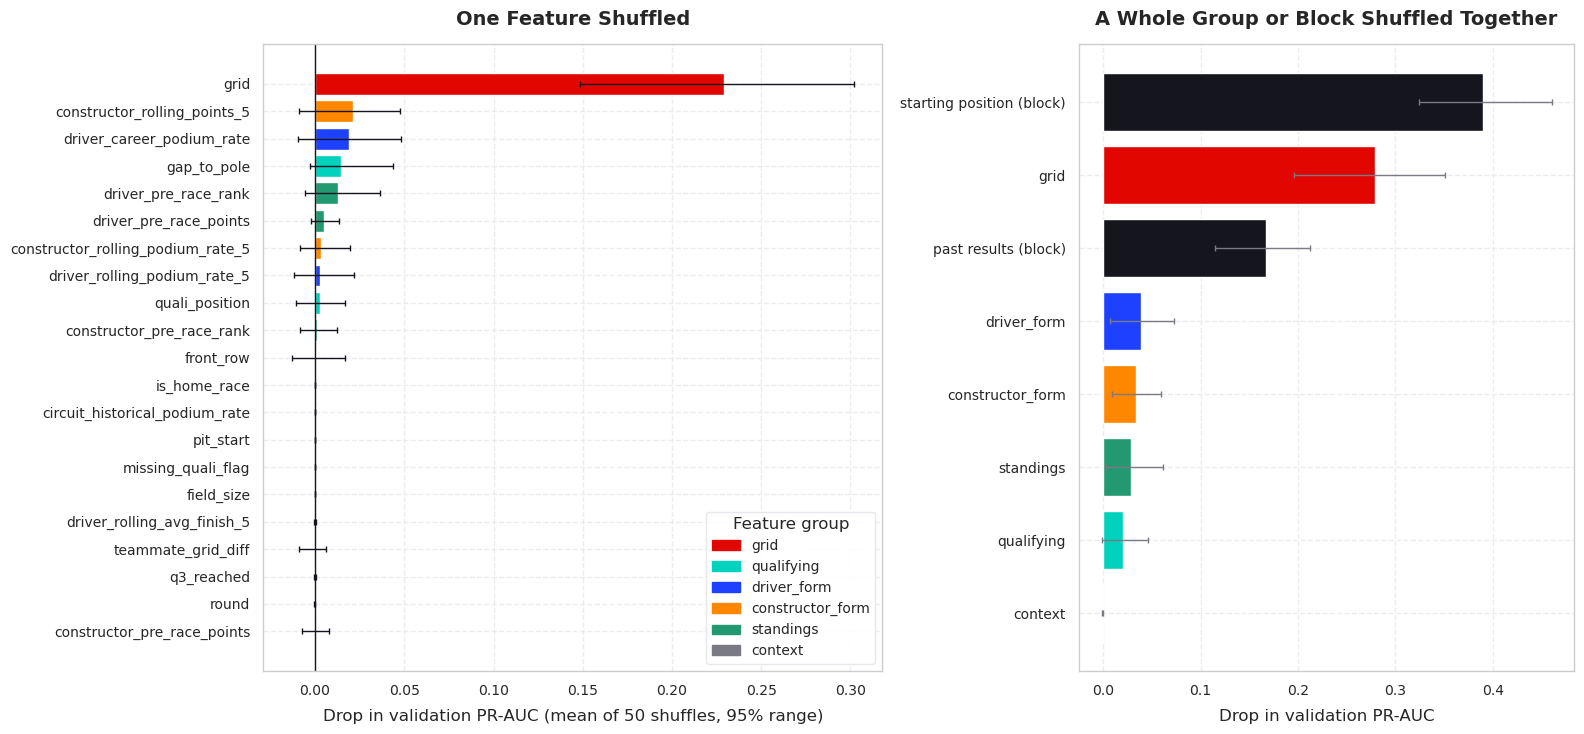

In [101]:
# Task 32.2: permutation importance by feature and by group or block
def interval_errors(table: pd.DataFrame) -> List[pd.Series]:
    # clipped at 0: with a skewed set of shuffles the mean can lie outside its own 95% range
    return [(table["PR-AUC drop"] - table["2.5%"]).clip(lower=0), (table["97.5%"] - table["PR-AUC drop"]).clip(lower=0)]


fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={"width_ratios": [1.25, 1]})
plot_features = feature_permutation.iloc[::-1]
axes[0].barh(plot_features.index, plot_features["PR-AUC drop"].astype(float), color=plot_features["group"].map(GROUP_COLORS),
             xerr=[e.astype(float) for e in interval_errors(plot_features)], error_kw={"ecolor": F1_PALETTE["dark"], "capsize": 2, "linewidth": 1})
axes[0].axvline(0, color=F1_PALETTE["dark"], linewidth=1)
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=color) for color in GROUP_COLORS.values()], labels=list(GROUP_COLORS),
               title="Feature group", loc="lower right")
axes[0].set(title="One Feature Shuffled", xlabel=f"Drop in validation PR-AUC (mean of {N_PERMUTATIONS} shuffles, 95% range)")

sets = pd.concat([group_permutation, block_permutation.drop(index="context").rename(index=lambda block: f"{block} (block)")])
sets = sets.sort_values("PR-AUC drop")
axes[1].barh(sets.index, sets["PR-AUC drop"], color=[F1_PALETTE["dark"] if "(block)" in name else GROUP_COLORS[name] for name in sets.index],
             xerr=interval_errors(sets), error_kw={"ecolor": F1_PALETTE["gray"], "capsize": 2, "linewidth": 1})
axes[1].set(title="A Whole Group or Block Shuffled Together", xlabel="Drop in validation PR-AUC")
save_fig("xai_permutation_importance")
plt.show()

**Result: the fitted model depends on `grid` far more than on anything else.**

- **`grid` alone:** shuffling it costs 0.229 PR-AUC (95% range 0.148 to 0.302), about a third of the model's 0.743.
- **No other single feature is clearly above zero.** The next ones are `constructor_rolling_points_5` (0.021), `driver_career_podium_rate` (0.019), `gap_to_pole` (0.015) and `driver_pre_race_rank` (0.013), and each of their ranges includes zero.
- **`quali_position` costs almost nothing (0.003)** although it carries nearly the same information as `grid`. The model reads the starting position from `grid` and barely uses its copy.
- **Whole blocks are much larger than their parts.** Starting position 0.390 (0.324 to 0.460), past results 0.167 (0.115 to 0.212), context 0.000. The three past-results groups cost about 0.03 each, but 0.17 together.
- **Single-feature importances do not add up.** The 21 single drops sum to 0.311, while shuffling everything at once costs 0.586. When one of several overlapping features is shuffled, the others cover for it, so a per-feature ranking understates every feature that has a substitute. **Importance is therefore quoted per block** in the conclusions and the report.

## Task 33: SHAP Values (Global)

SHAP splits each prediction into one contribution per feature. For a tree model the split is exact: the base value plus the 21 contributions equals the model output for that row (checked by an assertion below).

**The unit is log-odds, not probability.** The model output before the final squashing step is a log-odds value, and a SHAP value of +1 raises it by 1. The base value is the model's average output over the training rows. Because the model was trained with class weights (Task 26), these are the log-odds of the *weighted* score, not of a calibrated probability.

In [102]:
# Task 33.1: SHAP values of the selected model on the validation seasons
explainer = shap.TreeExplainer(lgbm_model)
shap_val = explainer(X_val)
if shap_val.values.ndim == 3:   # older SHAP versions return one slice per class; keep the podium class
    shap_val = shap_val[:, :, 1]

# SHAP is exact for trees: base value + contributions = the model output in log-odds, for every row
raw_scores = lgbm_model.predict(X_val, raw_score=True)
assert np.allclose(shap_val.base_values + shap_val.values.sum(axis=1), raw_scores, atol=1e-6)
assert np.allclose(1 / (1 + np.exp(-raw_scores)), val_scores[LGBM])
print(f"Base value: {float(np.ravel(shap_val.base_values)[0]):.3f} log-odds (score {1 / (1 + np.exp(-float(np.ravel(shap_val.base_values)[0]))):.3f}) | "
      f"decision threshold: score {THRESHOLDS[LGBM]:.3f} = {np.log(THRESHOLDS[LGBM] / (1 - THRESHOLDS[LGBM])):.3f} log-odds")

shap_importance = pd.DataFrame({"group": pd.Series(FEATURE_TO_GROUP), "mean |SHAP|": pd.Series(np.abs(shap_val.values).mean(axis=0), index=FEATURE_COLUMNS)})
shap_importance["share %"] = shap_importance["mean |SHAP|"] / shap_importance["mean |SHAP|"].sum() * 100
shap_importance["permutation rank"] = feature_permutation["PR-AUC drop"].rank(ascending=False).astype(int)
shap_importance = shap_importance.sort_values("mean |SHAP|", ascending=False)
shap_importance.insert(1, "SHAP rank", range(1, len(shap_importance) + 1))
display(shap_importance.round(3))

UNUSED_FEATURES: List[str] = [col for col, n_splits in zip(FEATURE_COLUMNS, lgbm_model.feature_importances_) if n_splits == 0]
print(f"Features the model never splits on ({len(UNUSED_FEATURES)}): {', '.join(UNUSED_FEATURES)}")

Base value: -1.092 log-odds (score 0.251) | decision threshold: score 0.747 = 1.084 log-odds


,group,SHAP rank,mean |SHAP|,share %,permutation rank
grid,grid,1,0.835,40.096,1
constructor_rolling_points_5,constructor_form,2,0.256,12.279,2
driver_career_podium_rate,driver_form,3,0.165,7.926,3
driver_rolling_podium_rate_5,driver_form,4,0.158,7.604,8
driver_pre_race_points,standings,5,0.096,4.593,6
gap_to_pole,qualifying,6,0.094,4.504,4
q3_reached,qualifying,7,0.092,4.397,19
constructor_rolling_podium_rate_5,constructor_form,8,0.086,4.123,7
driver_pre_race_rank,standings,9,0.082,3.928,5
quali_position,qualifying,10,0.075,3.618,9


Features the model never splits on (4): pit_start, missing_quali_flag, is_home_race, circuit_historical_podium_rate


[FIGURE SAVED] figures/xai_shap_beeswarm.png


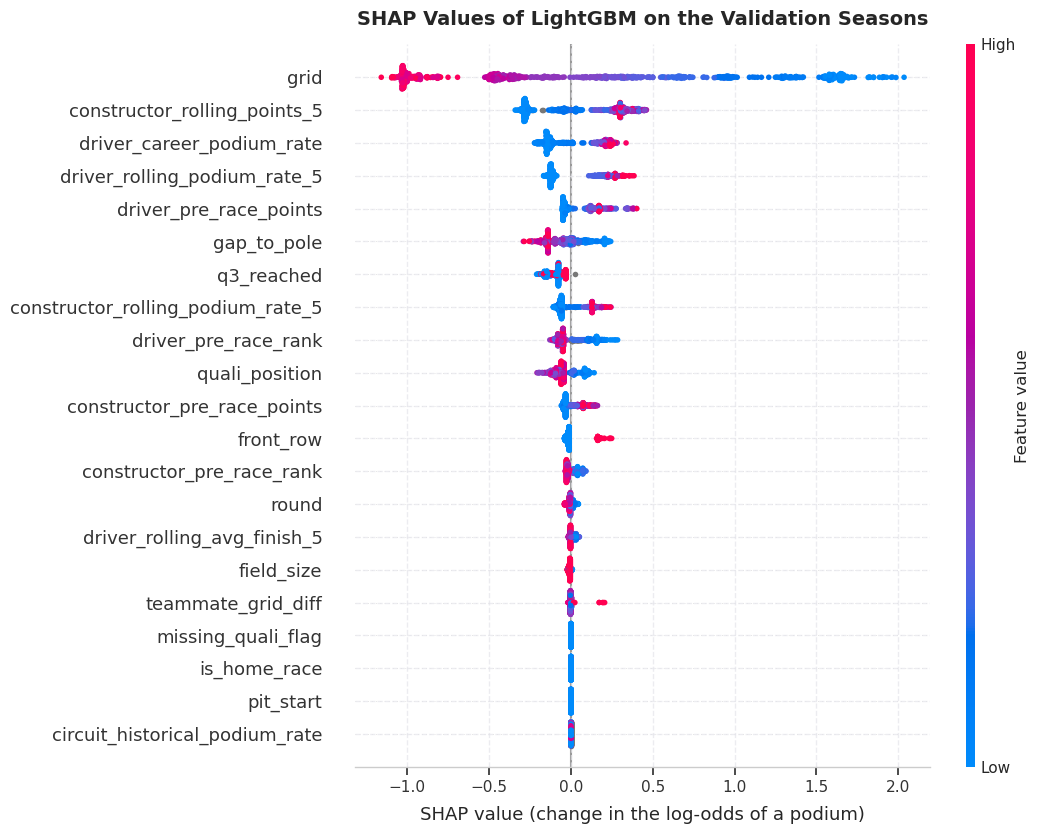

In [103]:
# Task 33.2: SHAP summary (beeswarm) plot
shap.plots.beeswarm(shap_val, max_display=len(FEATURE_COLUMNS), show=False, plot_size=(11, 8.5))
plt.gca().set(title=f"SHAP Values of {LGBM} on the Validation Seasons", xlabel="SHAP value (change in the log-odds of a podium)")
save_fig("xai_shap_beeswarm")
plt.show()

[FIGURE SAVED] figures/xai_shap_dependence.png


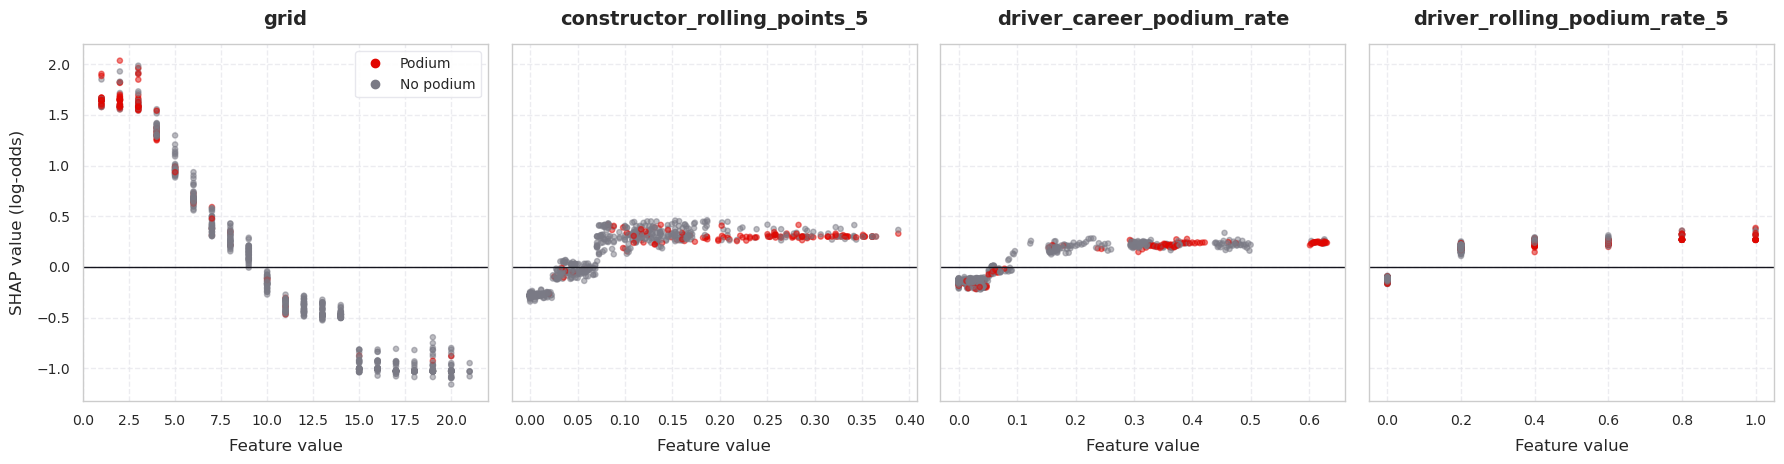

grid,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
median,1.65,1.64,1.61,1.34,0.96,0.67,0.39,0.27,0.14,-0.15,-0.38,-0.40,-0.47,-0.47,-1.00,-1.00,-1.03,-1.03,-1.02,-1.03,-1.03
min,1.58,1.56,1.54,1.25,0.88,0.56,0.30,0.15,-0.01,-0.27,-0.47,-0.49,-0.53,-0.51,-1.04,-1.07,-1.08,-1.09,-1.09,-1.16,-1.08
max,1.91,2.04,1.99,1.56,1.30,0.94,0.59,0.43,0.29,-0.04,-0.27,-0.28,-0.32,-0.38,-0.81,-0.81,-0.81,-0.82,-0.69,-0.80,-0.95
rows,38.00,39.00,39.00,39.00,39.00,39.00,37.00,39.00,39.00,39.00,38.00,39.00,37.00,38.00,38.00,38.00,39.00,37.00,40.00,39.00,5.00


Mean SHAP value of q3_reached on validation: q3_reached = 0: -0.105 (391 rows), q3_reached = 1: -0.078 (383 rows) | training rows with a q3_reached value: 25.5%


In [104]:
# Task 33.3: how the SHAP value of the leading features depends on the feature value
DEPENDENCE_FEATURES: List[str] = list(shap_importance.index[:4])   # the four features with the largest mean |SHAP|
fig, axes = plt.subplots(1, len(DEPENDENCE_FEATURES), figsize=(18, 4.8), sharey=True)
for ax, feature in zip(axes, DEPENDENCE_FEATURES):
    ax.scatter(X_val[feature], shap_val.values[:, FEATURE_COLUMNS.index(feature)], s=14, alpha=0.5,
               c=y_val.map({0: F1_PALETTE["gray"], 1: F1_PALETTE["crimson"]}))
    ax.axhline(0, color=F1_PALETTE["dark"], linewidth=1)
    ax.set(title=feature, xlabel="Feature value")
axes[0].set_ylabel("SHAP value (log-odds)")
axes[0].legend(handles=[plt.Line2D([0], [0], marker="o", linestyle="", color=F1_PALETTE[c]) for c in ["crimson", "gray"]], labels=["Podium", "No podium"])
save_fig("xai_shap_dependence")
plt.show()

grid_shap = pd.Series(shap_val.values[:, FEATURE_COLUMNS.index("grid")], index=X_val.index).groupby(X_val["grid"]).agg(["median", "min", "max", "size"])
display(grid_shap.rename(columns={"size": "rows"}).T.round(2))
q3_shap = pd.Series(shap_val.values[:, FEATURE_COLUMNS.index("q3_reached")], index=X_val.index).groupby(X_val["q3_reached"]).agg(["mean", "size"])
print("Mean SHAP value of q3_reached on validation: " + ", ".join(f"q3_reached = {int(v)}: {r['mean']:+.3f} ({int(r['size'])} rows)" for v, r in q3_shap.iterrows())
      + f" | training rows with a q3_reached value: {X_train['q3_reached'].notna().mean():.1%}")

In [105]:
# Task 33.4: three views of each group and block: SHAP, permutation (this step) and retraining (Step 7)
def shap_share(column_sets: Dict[str, List[str]]) -> pd.Series:
    return pd.Series({name: shap_importance.loc[columns, "share %"].sum() for name, columns in column_sets.items()})


importance_views = pd.concat({
    kind: pd.DataFrame({"features": pd.Series({name: len(cols) for name, cols in column_sets.items()}), "SHAP share %": shap_share(column_sets),
                        "permutation drop (validation)": permuted["PR-AUC drop"],
                        "retraining drop (validation)": pd.Series({name: -ablated.loc[f"without {name}", ("validation", "Δ")] for name in column_sets})})
    for kind, column_sets, permuted, ablated in [("group", FEATURE_GROUPS, group_permutation, group_ablation),
                                                 ("block", BLOCK_COLUMNS, block_permutation, block_ablation)]
})
display(importance_views.round(3))

features  SHAP share %  permutation drop (validation)  retraining drop (validation)
group grid                      4        41.965                          0.279                         0.017
      qualifying                4        12.519                          0.020                         0.015
      driver_form               3        16.048                          0.039                         0.005
      constructor_form          2        16.402                          0.034                         0.003
      standings                 4        12.139                          0.028                         0.006
      context                   4         0.928                         -0.000                         0.000
block starting position         8        54.484                          0.390                         0.085
      past results              9        44.588                          0.167                         0.064
      context                   4         0.928                         -0.000                         0.000

**Result: SHAP gives the same ranking as permutation at the top, and shows the direction and shape of each effect.**

**1. The starting-position block carries 54% of all SHAP magnitude and past results 45%.** Within the first block, `grid` alone has 40% (mean |SHAP| 0.835). It is followed by `constructor_rolling_points_5` (12%), `driver_career_podium_rate` (8%) and `driver_rolling_podium_rate_5` (8%). The top two are the same as in Task 32.

**2. The effect of `grid` is a staircase, not a line.** Slots 1 to 3 all get about +1.6 log-odds; the value then falls by about 0.3 per slot (+1.34 at slot 4, +0.96 at 5, +0.67 at 6, +0.39 at 7) and crosses zero between slots 9 and 10. Slots 11 to 14 get about −0.4 and every slot from 15 back gets about −1.0. The model has learned "the first three slots are alike, and the back of the grid is alike".

**3. Form features act as a switch and then level off.** `driver_rolling_podium_rate_5` is about −0.13 for a driver with no podium in the last five races and +0.2 to +0.3 for a driver with at least one, with little difference between one podium and five. `constructor_rolling_points_5` rises from about −0.3 for the weakest teams to about +0.3 and stays there: the model separates front-running teams from the rest but does not rank them among themselves.

**4. Four features are never used.** `pit_start`, `missing_quali_flag`, `is_home_race` and `circuit_historical_podium_rate` appear in no tree, so their SHAP value is exactly zero for every row. The whole context group has 0.9% of the SHAP magnitude, which agrees with Step 7.

**5. `q3_reached` is an example of a SHAP value that must not be read literally.** It is negative for almost every validation row: −0.08 on average for drivers who reached Q3 and −0.11 for those who did not. The feature has a value in only 25% of the training rows, so what the model picked up is "this row has a Q3 value at all", not whether Q3 was reached.

**Three ways of measuring a block, side by side:**

| Block | SHAP share | Permutation drop (fitted model) | Retraining drop (Step 7) |
| :--- | :--- | :--- | :--- |
| Starting position | 54% | 0.390 | 0.085 |
| Past results | 45% | 0.167 | 0.064 |
| Context | 0.9% | 0.000 | 0.000 |

All three agree on the order. They differ in size because they answer different questions. Permutation asks what the *fitted* model loses when a block is scrambled: it still trusts the scrambled values, so the loss is large. Retraining asks what a *new* model loses when it never sees the block: it leans on what is left, so the loss is smaller. The `grid` group shows the gap most clearly: 0.279 by permutation, 0.017 by retraining, because a retrained model takes the same information from qualifying.

**The split between `grid` and its near-copies is a property of this fitted model, not of the data.** A LightGBM configuration that offers each tree only half of the features moves much of `grid`'s share to `quali_position` and `gap_to_pole` (to about 28% for `grid`), while the starting-position block keeps about half of the total. The block shares are the numbers to quote (DEC-037).

## Task 34: Two Surprising Results (SHAP Waterfalls)

Two rows are picked from the validation seasons by rule, not by hand:

- **Unexpected podium:** the podium finisher to whom the model gave the lowest score.
- **Pole-sitter off the podium:** the driver who started first and missed the podium, with the highest score.

Only rows with no missing feature are considered, because LIME (Task 35) cannot take a missing value. The finishing position and status shown below come from the race result. They are used to describe the case and are not features.

In [106]:
# Task 34.1: two surprising results from the validation seasons
race_names = raw_dataframes["races"].assign(race=lambda r: r["year"].astype(str) + " " + r["name"]).set_index("raceId")["race"]
driver_names = raw_dataframes["drivers"].assign(driver=lambda d: d["forename"] + " " + d["surname"]).set_index("driverId")["driver"]
constructor_names = raw_dataframes["constructors"].set_index("constructorId")["name"]
finishes = raw_dataframes["results"].merge(raw_dataframes["status"], on="statusId")[GRAIN + ["positionOrder", "status"]]

val_cases = val_df[IDENTIFIER_COLUMNS + [TARGET_COLUMN, "grid", "quali_position"]].assign(score=val_scores[LGBM], row=np.arange(len(val_df)))
complete = X_val.notna().all(axis=1)   # LIME (Task 35) cannot take a missing value
CASES: Dict[str, int] = {
    "Unexpected podium": int(val_cases[complete & (val_cases[TARGET_COLUMN] == 1)].sort_values("score")["row"].iloc[0]),
    "Pole-sitter off the podium": int(val_cases[complete & (val_cases["grid"] == 1) & (val_cases[TARGET_COLUMN] == 0)]
                                      .sort_values("score", ascending=False)["row"].iloc[0]),
}


def case_title(row: int) -> str:
    case = val_cases.iloc[row]
    return f"{driver_names[case['driverId']]} ({constructor_names[case['constructorId']]}), {race_names[case['raceId']]}"


case_table = val_cases.iloc[list(CASES.values())].merge(finishes, on=GRAIN, how="left").set_axis(list(CASES))
case_table = case_table.assign(driver=case_table["driverId"].map(driver_names), constructor=case_table["constructorId"].map(constructor_names),
                               race=case_table["raceId"].map(race_names), predicted=(case_table["score"] >= THRESHOLDS[LGBM]).astype(int))
display(case_table[["driver", "constructor", "race", "grid", "quali_position", "score", "predicted", TARGET_COLUMN, "positionOrder", "status"]])
print(f"Decision threshold: {THRESHOLDS[LGBM]:.3f} | podiums among the {int((val_cases[TARGET_COLUMN] == 1).sum())} validation podiums scored below it: "
      f"{int(((val_cases[TARGET_COLUMN] == 1) & (val_cases['score'] < THRESHOLDS[LGBM])).sum())} | pole-sitters off the podium: "
      f"{int(((val_cases['grid'] == 1) & (val_cases[TARGET_COLUMN] == 0)).sum())} of {int((val_cases['grid'] == 1).sum())}")
display(X_val.iloc[list(CASES.values())].set_axis(list(CASES)).T.round(3))

,driver,constructor,race,grid,quali_position,score,predicted,podium,positionOrder,status
Unexpected podium,Pierre Gasly,AlphaTauri,2020 Italian Grand Prix,10,10.0,0.126559,0,1,1,Finished
Pole-sitter off the podium,Lewis Hamilton,Mercedes,2020 Italian Grand Prix,1,1.0,0.914940,1,0,7,Finished


Decision threshold: 0.747 | podiums among the 117 validation podiums scored below it: 32 | pole-sitters off the podium: 9 of 38


,Unexpected podium,Pole-sitter off the podium
grid,10.000,1.000
pit_start,0.000,0.000
front_row,0.000,1.000
teammate_grid_diff,-1.000,-1.000
quali_position,10.000,1.000
gap_to_pole,1.296,0.000
q3_reached,1.000,1.000
missing_quali_flag,0.000,0.000
driver_rolling_podium_rate_5,0.000,1.000
driver_rolling_avg_finish_5,11.000,1.200


[FIGURE SAVED] figures/xai_shap_waterfall_unexpected_podium.png


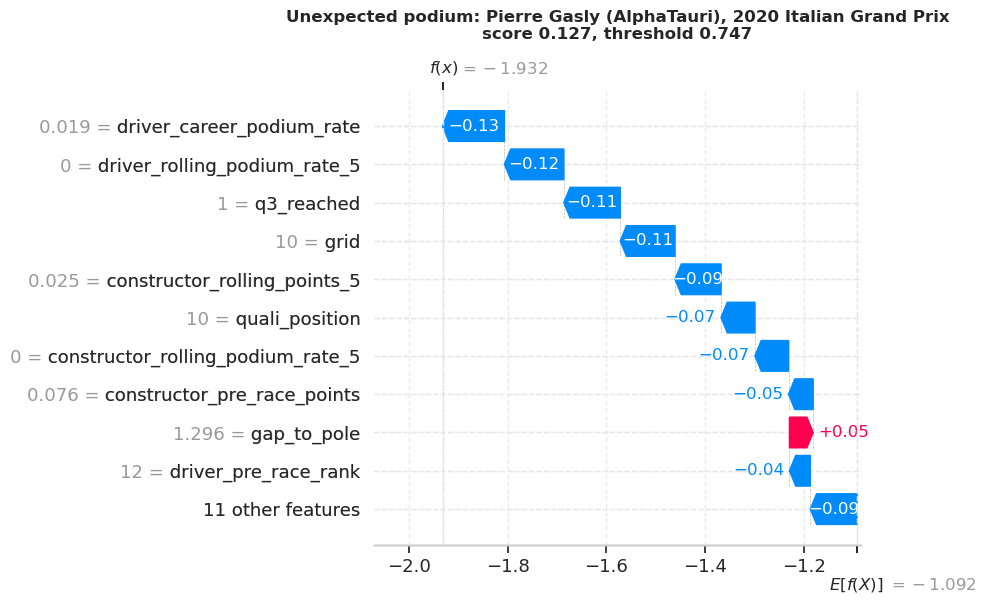

[FIGURE SAVED] figures/xai_shap_waterfall_pole_sitter_off_the_podium.png


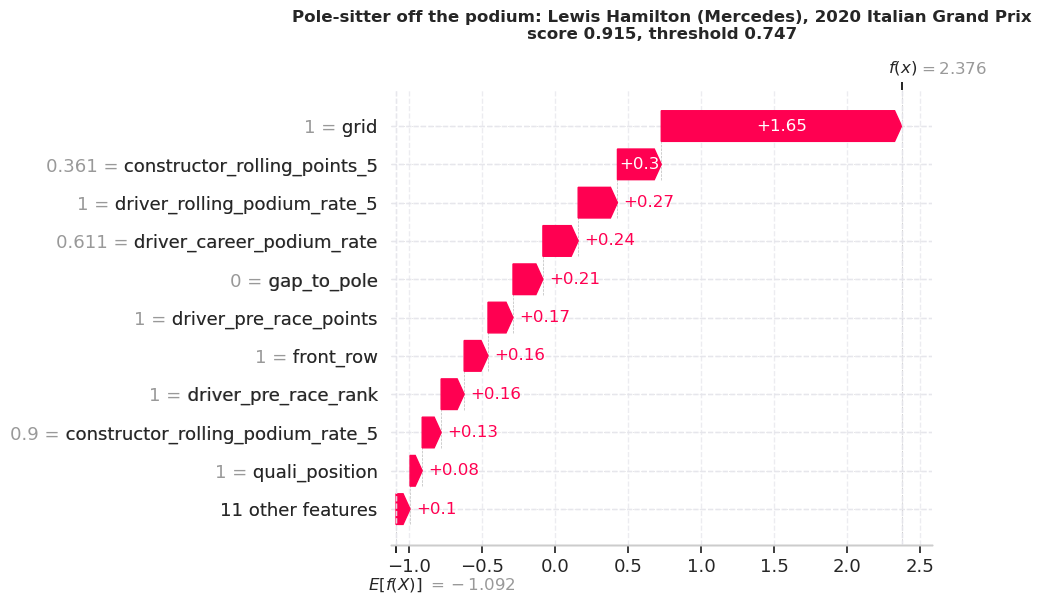

In [107]:
# Task 34.2: SHAP waterfall of each case
for label, row in CASES.items():
    plt.figure()   # the waterfall draws into the current figure
    shap.plots.waterfall(shap_val[row], max_display=11, show=False)
    plt.gcf().set_size_inches(10, 6.2)
    plt.title(f"{label}: {case_title(row)}\nscore {val_scores[LGBM][row]:.3f}, threshold {THRESHOLDS[LGBM]:.3f}", fontsize=12)
    save_fig("xai_shap_waterfall_" + label.lower().replace(" ", "_").replace("-", "_"))
    plt.show()

**Both rows come from the same race, the 2020 Italian Grand Prix, and in both the model did what its inputs justified.**

A waterfall is read from the bottom: it starts at the base value (−1.092 log-odds, a score of 0.25), each bar adds one feature's contribution, and the top is the model output for that row. The decision threshold of 0.747 is +1.08 log-odds.

**Pierre Gasly (AlphaTauri): score 0.127, won the race.**
- Nearly every bar points down. The largest are a career podium rate of 2% (−0.13), no podium in his last five races (−0.12), `q3_reached` (−0.11; see Task 33 for why this one is not meaningful) and the grid slot of 10 (−0.11). The only bar pointing up is his gap to pole of 1.3% (+0.05).
- Nothing in his pre-race data suggested a podium: tenth on the grid, twelfth in the standings, in a team with no podium in its last five races.
- No single feature decided it. The ten largest contributions are all between −0.13 and +0.05: a midfield profile on every count.

**Lewis Hamilton (Mercedes): score 0.915, finished seventh.**
- Pole position alone adds +1.65 log-odds, nearly half of the total of +3.47. The team's recent points add +0.30, his five podiums in five races +0.27, his career podium rate +0.24 and the zero gap to pole +0.21.
- Every bar points up. By every pre-race measure the model was right to give a high score.

**What the two cases show.** Both results were decided during the race: a safety car, a red flag and a penalty for Hamilton (known from the race itself, not from this dataset). None of that exists before the start. In these two rows the model did not misread its inputs; the outcome was not in them. On validation the model scores 32 of the 117 podium finishers below its threshold, and 9 of the 38 pole-sitters missed the podium. However many of those are of this kind, they are errors that tuning cannot remove, and they set a limit on any pre-race model.

## Task 35: LIME on the Same Two Cases

LIME explains one prediction by a different route. It creates 5,000 artificial rows around the row of interest, scores them with the model, and fits a small linear model to those scores. The weights of that linear model are the explanation. Its unit is the model score (0 to 1), not log-odds, so LIME weights and SHAP values are compared by sign and rank, not by size.

Two settings matter here:

- **The background.** LIME draws the artificial rows from the training distribution and cannot handle missing values, so it is given the 4,027 training rows with no missing feature (seasons 2006–2019).
- **Bins.** LIME cuts each continuous feature into quartile bins and reports a rule such as `grid <= 5.00`.

LIME is random, so each case is also explained with five different seeds to see whether the answer holds.

LIME background: 4,027 of 22,355 training rows with no missing feature (seasons 2006–2019)
[FIGURE SAVED] figures/xai_lime.png


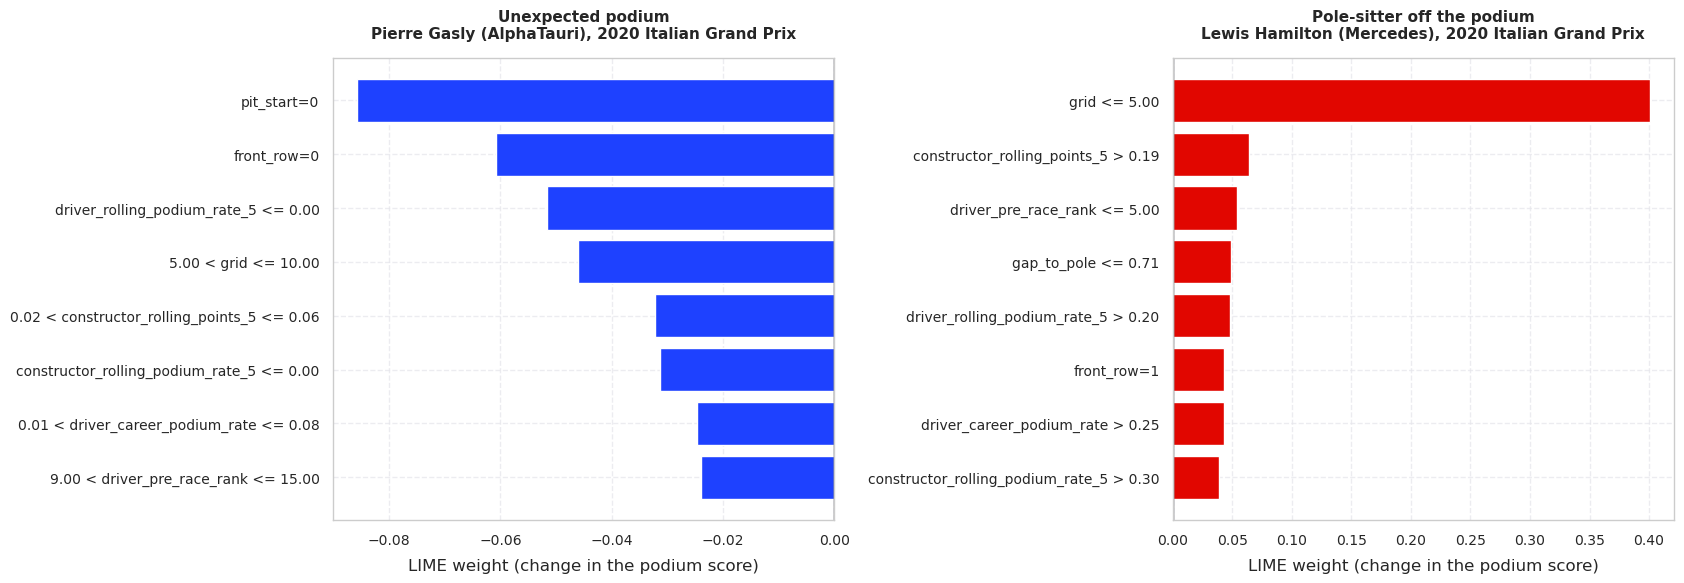

In [108]:
# Task 35.1: LIME explanation of the same two cases
N_LIME_SAMPLES: int = 5000
N_LIME_FEATURES: int = 8
LIME_SEEDS: List[int] = [RANDOM_SEED, 0, 1, 2, 3]

lime_background = X_train.dropna()   # LIME samples around a row from these columns' distributions and cannot take a missing value
print(f"LIME background: {len(lime_background):,} of {len(X_train):,} training rows with no missing feature "
      f"(seasons {int(train_df.loc[lime_background.index, 'year'].min())}–{int(train_df.loc[lime_background.index, 'year'].max())})")


def lime_explain(row: int, seed: int = RANDOM_SEED):
    """LIME explanation of the LightGBM podium score for one validation row."""
    lime_explainer = LimeTabularExplainer(
        lime_background.to_numpy(), feature_names=FEATURE_COLUMNS, class_names=["no podium", "podium"], mode="classification",
        categorical_features=[FEATURE_COLUMNS.index(col) for col in BINARY_FEATURES], discretize_continuous=True, random_state=seed)
    return lime_explainer.explain_instance(
        X_val.iloc[row].to_numpy(), lambda values: lgbm_model.predict_proba(pd.DataFrame(values, columns=FEATURE_COLUMNS)),
        num_features=len(FEATURE_COLUMNS), num_samples=N_LIME_SAMPLES)


def lime_weights(explanation) -> pd.Series:
    """Feature name -> LIME weight for the podium class, largest absolute weight first."""
    return pd.Series({FEATURE_COLUMNS[i]: weight for i, weight in explanation.as_map()[1]})


lime_explanations = {label: lime_explain(row) for label, row in CASES.items()}
fig, axes = plt.subplots(1, len(CASES), figsize=(17, 6))
for ax, (label, explanation) in zip(axes, lime_explanations.items()):
    rules = dict(zip([FEATURE_COLUMNS[i] for i, _ in explanation.as_map()[1]], [rule for rule, _ in explanation.as_list(label=1)]))
    top = lime_weights(explanation).iloc[:N_LIME_FEATURES].iloc[::-1]
    ax.barh([rules[col] for col in top.index], top, color=[F1_PALETTE["crimson"] if w > 0 else F1_PALETTE["blue"] for w in top])
    ax.axvline(0, color=F1_PALETTE["dark"], linewidth=1)
    ax.set(title=f"{label}\n{case_title(CASES[label])}", xlabel="LIME weight (change in the podium score)")
    ax.title.set_fontsize(11)
save_fig("xai_lime")
plt.show()

In [109]:
# Task 35.2: do LIME and SHAP agree, and is LIME stable?
lime_rows = {}
for label, row in CASES.items():
    weights = lime_weights(lime_explanations[label])
    shap_row = pd.Series(shap_val.values[row], index=FEATURE_COLUMNS)
    shap_top, lime_top = shap_row.abs().sort_values(ascending=False).index[:5], weights.index[:5]
    reruns = [lime_weights(lime_explain(row, seed)) for seed in LIME_SEEDS[1:]]
    lime_rows[label] = {
        "model score": val_scores[LGBM][row], "LIME local prediction": float(lime_explanations[label].local_pred[0]),
        "LIME fit (R²)": lime_explanations[label].score,
        "top-5 features shared with SHAP": len(set(shap_top) & set(lime_top)),
        "same sign as SHAP, LIME top 5": int((np.sign(weights[lime_top]) == np.sign(shap_row[lime_top])).sum()),
        "rank correlation with SHAP (all features)": weights.reindex(FEATURE_COLUMNS).corr(shap_row, method="spearman"),
        "LIME top feature": weights.index[0], "SHAP value of LIME's top feature": shap_row[weights.index[0]],
        f"different top features in {len(LIME_SEEDS)} LIME runs": len({weights.index[0], *[r.index[0] for r in reruns]}),
        f"top-5 features in all {len(LIME_SEEDS)} runs": len(set(lime_top).intersection(*[set(r.index[:5]) for r in reruns])),
    }
    display(pd.DataFrame({"feature value": X_val.iloc[row], "SHAP (log-odds)": shap_row, "LIME weight (score)": weights}).loc[shap_top].round(3))
lime_check = pd.DataFrame(lime_rows)
display(lime_check)

,feature value,SHAP (log-odds),LIME weight (score)
driver_career_podium_rate,0.019,-0.126,-0.025
driver_rolling_podium_rate_5,0.000,-0.120,-0.052
q3_reached,1.000,-0.114,0.010
grid,10.000,-0.111,-0.046
constructor_rolling_points_5,0.025,-0.093,-0.032


,feature value,SHAP (log-odds),LIME weight (score)
grid,1.000,1.648,0.401
constructor_rolling_points_5,0.361,0.301,0.064
driver_rolling_podium_rate_5,1.000,0.269,0.049
driver_career_podium_rate,0.611,0.242,0.043
gap_to_pole,0.000,0.205,0.049


,Unexpected podium,Pole-sitter off the podium
model score,0.126559,0.91494
LIME local prediction,0.1839,0.977606
LIME fit (R²),0.054005,0.823885
top-5 features shared with SHAP,3,4
"same sign as SHAP, LIME top 5",4,5
rank correlation with SHAP (all features),0.425409,0.867757
LIME top feature,pit_start,grid
SHAP value of LIME's top feature,0.0,1.648162
different top features in 5 LIME runs,3,1
top-5 features in all 5 runs,3,4


**Result: LIME agrees with SHAP where the model is confident, and fails on the low-score case.**

| | Gasly (score 0.127) | Hamilton (score 0.915) |
| :--- | :--- | :--- |
| How well LIME's linear model fits the model (R²) | 0.05 | 0.82 |
| LIME's own estimate of the score | 0.184 | 0.978 |
| LIME's top feature | `pit_start = 0` | `grid` (pole) |
| SHAP value of that feature | 0 (never used by the model) | +1.65 (SHAP's top feature too) |
| Top-5 features shared with SHAP | 3 | 4 |
| Rank correlation with SHAP, all features | 0.43 | 0.87 |
| Different top features across 5 seeds | 3 | 1 |

- **Hamilton: a usable explanation.** The linear model fits well, `grid` dominates with a weight of +0.40, the next features are the same as SHAP's with the same signs, and all five seeds give the same top feature.
- **Gasly: not a usable explanation.** The linear model explains 5% of the variation in the model's scores. Its largest weight goes to `pit_start`, a feature that appears in no tree, and the top feature changes from seed to seed.
- **Why it fails there.** `pit_start` is 1 in only 7 of the 4,027 background rows, so the handful of artificial rows with `pit_start = 1` get scores that differ by chance and the linear model reads that as an effect. The low R² says the same thing more generally: around this row, a straight line does not describe how the model's score changes.

**SHAP is the method to rely on for this model.** Its values are exact for trees, add up to the prediction and do not change between runs. LIME is kept as a second opinion: where the two agree (Hamilton) the explanation is solid, and a low R² or an unstable top feature (Gasly) is the signal not to quote it.

## What the Explanations Do and Do Not Say

**What the model does**

- It is mostly a model of the starting position: the starting-position block carries 54% of the SHAP magnitude, and `grid` alone 40% and a third of the PR-AUC.
- Recent results of the team and the driver supply the rest (45%), mainly as a switch between "has been on the podium lately" and "has not".
- Context is ignored, and four of the 21 features are never used.

**What must not be concluded**

- **Importance is not causation.** `grid` is important because it summarises everything that makes a car fast that weekend: the car, the driver and the setup. Putting a slow car on pole would not make it a podium contender. The model has learned an association that holds when drivers reach their grid slot in the usual way.
- **Credit between overlapping features is arbitrary.** `grid` and `quali_position` are nearly the same number. The model happened to use `grid`, so `grid` gets the credit; a model with other settings splits it differently (Task 33). Importance should be quoted per block, not per feature.
- **A SHAP value can reflect how the data was recorded.** `q3_reached` gets a negative value whether or not Q3 was reached, because most training rows have no value for it.
- **The explanations are of the weighted score, on the validation seasons.** They describe this model on 2020–2021. They are not a statement about other seasons, and the scores are not calibrated probabilities (Task 26).

## Hand-Off

| Object | Contents |
| :--- | :--- |
| `feature_permutation`, `group_permutation`, `block_permutation` | Drop in validation PR-AUC when a feature, group or block is shuffled, with a 95% range |
| `explainer`, `shap_val` | The `TreeExplainer` and the SHAP values of the 775 validation rows (log-odds) |
| `shap_importance` | Mean \|SHAP\| per feature, its share, and its rank by SHAP and by permutation |
| `importance_views` | SHAP share, permutation drop and retraining drop per group and block |
| `UNUSED_FEATURES` | The four features that appear in no tree |
| `CASES`, `case_table` | The two validation rows explained locally |
| `lime_explain()`, `lime_check` | LIME explanation of a validation row; its agreement with SHAP and its stability |
| `figures/xai_*.png` | Six figures: permutation importance, beeswarm, dependence, two waterfalls, LIME |

**Keep in mind for Steps 9 and 10**

- **Step 9 (inference):** `explainer(row)` can return the SHAP values of a new prediction, if the inference function should say why. `grid` is by far the most influential input, so a call without a grid slot has little to go on.
- **Step 9:** four features are unused, but the model still expects all 21 columns in the order of `FEATURE_COLUMNS`.
- **Step 10 (report):** show the block table of Task 33 next to the beeswarm. Quote LIME only for the Hamilton case, and state its R² when it is quoted.
- **Step 10 (limitations):** the two cases are the clearest illustration that in-race events put a ceiling on any pre-race model.

---
# 10. Step 9: Inference Function (M4)

`predict_podium(raceId, driverId, grid, quali_info=None)` answers one question: before the race starts, will this driver finish on the podium? It builds the driver's 21 features from the history in the dataset, runs the model fitted in Step 6, and returns a probability and a yes or no.

**Three rules hold for the whole section (DEC-033)**

- **The model is not changed.** The function uses `lgbm_model` and its threshold exactly as fixed in Step 6. Because LightGBM takes the raw features, there is no imputer or scaler to run: a missing value is passed to the model as missing.
- **Features are rebuilt, not looked up.** The function does not read a row from `model_df`. It runs the Step 4 functions on the races before the requested one, so it uses the same code as training and cannot see the result of the race it predicts.
- **A probability is only called a probability after calibration.** The raw model output is about twice the true podium rate (Task 26). Task 36 corrects that.

## Task 36: From Score to Probability

The model was trained with class weights, which push its output up: the average score on validation is 0.32, while 15% of the rows are podiums. Reported as it is, a score of 0.50 would read as "a 50% chance" when the real chance is far lower.

**Platt scaling** fixes this with one small model: a logistic regression with a single input, the model's log-odds, fitted on the validation seasons. It has two parameters, so 775 rows are enough to fit it. It is monotone: it changes the values, never the order of the drivers, so PR-AUC and every yes/no prediction stay the same.

The test seasons are used below only to check the result. Nothing is chosen from them.

In [110]:
# Task 36.1: from model score to podium probability (DEC-033)
from sklearn.metrics import brier_score_loss


def to_log_odds(scores) -> np.ndarray:
    clipped = np.clip(np.asarray(scores, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(clipped / (1 - clipped))


# Platt scaling: a one-variable logistic regression from the model's log-odds to the outcome, fitted on validation only
calibrator = LogisticRegression(C=1e6, max_iter=1000).fit(to_log_odds(val_scores[LGBM]).reshape(-1, 1), y_val)
assert calibrator.coef_[0, 0] > 0, "The calibration must keep the order of the scores"


def score_to_probability(scores) -> np.ndarray:
    """Calibrated podium probability for LightGBM scores. Monotone, so the ranking of drivers does not change."""
    return calibrator.predict_proba(to_log_odds(scores).reshape(-1, 1))[:, 1]


calibration_rows = {}
for split in ["validation", "test"]:
    y, scores = SPLIT_FRAMES[split][TARGET_COLUMN], split_scores[split][LGBM]
    probabilities = score_to_probability(scores)
    calibration_rows[split] = {
        "podium rate": y.mean(), "mean score": scores.mean(), "mean probability": probabilities.mean(),
        "Brier, score": brier_score_loss(y, scores), "Brier, probability": brier_score_loss(y, probabilities),
        "PR-AUC, score": average_precision_score(y, scores), "PR-AUC, probability": average_precision_score(y, probabilities),
    }
calibration_check = pd.DataFrame(calibration_rows).T
display(calibration_check.round(4))
PROBABILITY_THRESHOLD: float = float(score_to_probability([THRESHOLDS[LGBM]])[0])
print(f"probability = sigmoid({calibrator.coef_[0, 0]:.3f} × log-odds(score) {calibrator.intercept_[0]:+.3f}) | "
      f"decision threshold: score {THRESHOLDS[LGBM]:.3f} = probability {PROBABILITY_THRESHOLD:.3f}")

,podium rate,mean score,mean probability,"Brier, score","Brier, probability","PR-AUC, score","PR-AUC, probability"
validation,0.1510,0.3210,0.1510,0.1113,0.0668,0.7425,0.7425
test,0.1509,0.3294,0.1613,0.1167,0.0686,0.7088,0.7088


probability = sigmoid(1.348 × log-odds(score) -1.838) | decision threshold: score 0.747 = probability 0.407


[FIGURE SAVED] figures/inference_calibration.png


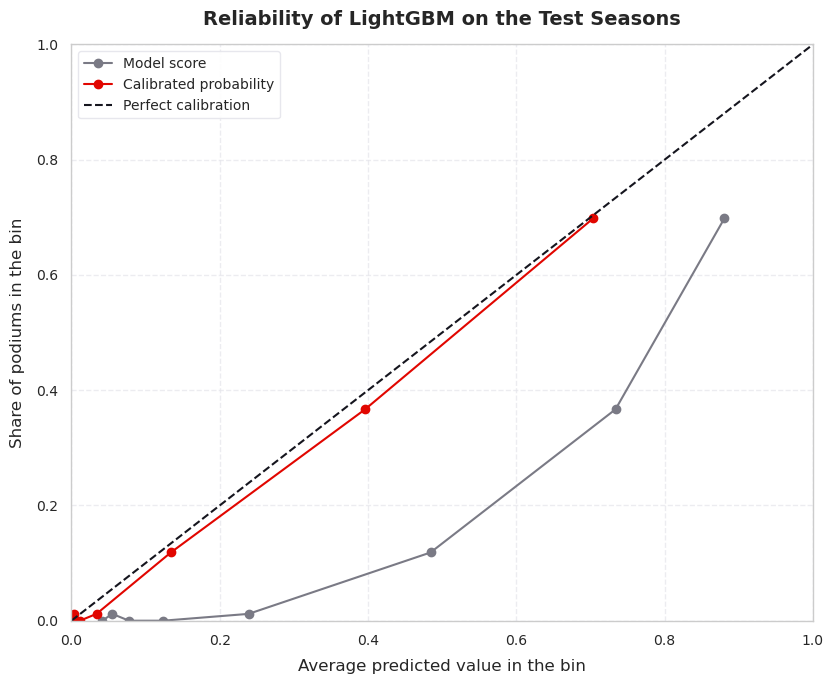

Model score               Calibrated probability              
    predicted observed rows              predicted observed rows
0       0.042    0.000  169                  0.002    0.000  169
1       0.055    0.012  169                  0.003    0.012  169
2       0.078    0.000  169                  0.006    0.000  169
3       0.124    0.000  169                  0.011    0.000  169
4       0.239    0.012  169                  0.034    0.012  169
5       0.484    0.118  169                  0.134    0.118  169
6       0.734    0.367  169                  0.396    0.367  169
7       0.881    0.698  169                  0.704    0.698  169

In [111]:
# Task 36.2: reliability on the test seasons, before and after calibration
N_RELIABILITY_BINS: int = 8
y, scores = test_df[TARGET_COLUMN].to_numpy(), split_scores["test"][LGBM]
fig, ax = plt.subplots(figsize=(8.5, 7))
reliability_rows = {}
for label, values, color in [("Model score", scores, F1_PALETTE["gray"]), ("Calibrated probability", score_to_probability(scores), F1_PALETTE["crimson"])]:
    bins = pd.qcut(pd.Series(values).rank(method="first"), N_RELIABILITY_BINS, labels=False)   # equal-sized bins
    binned = pd.DataFrame({"predicted": values, "observed": y}).groupby(bins).agg(predicted=("predicted", "mean"), observed=("observed", "mean"), rows=("observed", "size"))
    reliability_rows[label] = binned
    ax.plot(binned["predicted"], binned["observed"], marker="o", color=color, label=label)
ax.plot([0, 1], [0, 1], color=F1_PALETTE["dark"], linestyle="--", label="Perfect calibration")
ax.set(title=f"Reliability of {LGBM} on the Test Seasons", xlabel="Average predicted value in the bin", ylabel="Share of podiums in the bin",
       xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper left")
save_fig("inference_calibration")
plt.show()
display(pd.concat(reliability_rows, axis=1).round(3))

**Result: after calibration the probabilities match what happens on the test seasons.**

| | Podium rate | Mean score | Mean probability | Brier score, raw | Brier score, calibrated |
| :--- | ---: | ---: | ---: | ---: | ---: |
| Validation (fitted here) | 0.151 | 0.32 | 0.151 | 0.111 | 0.067 |
| Test (check only) | 0.151 | 0.33 | 0.161 | 0.117 | 0.069 |

- **On test, the average probability is 0.161 against a podium rate of 0.151.** The raw score averaged 0.33. The Brier score (the mean squared error of a probability; lower is better) falls from 0.117 to 0.069.
- **The reliability plot shows the same thing by bin.** The test rows are cut into eight equal groups by predicted value. The calibrated points lie close to the diagonal: in the top group the average probability is 0.70 and 70% were podiums. The raw score in that group averaged 0.88.
- **PR-AUC is unchanged** (0.743 and 0.709), as it must be for a monotone correction.
- **The decision threshold of 0.747 on the score is a probability of 0.407.** The function predicts a podium when the calibrated probability is about 40% or more. That is where F1 was highest on validation (DEC-028); it is not a "more likely than not" rule.

## Task 37: Pre-Race Feature Builder

`pre_race_features()` produces the 21 model inputs for one driver in one race. It gives the Step 4 function `build_feature_table()` three things:

- **Every race before the requested one,** with its results. This is where form, career rates and the circuit record come from.
- **The entry list of the requested race, with its results blanked.** The other drivers are needed for `field_size`, the teammate's grid slot and the pole time. Their finishing positions, points and podium flags are set to missing before anything is computed.
- **The `grid` and `quali_info` passed in,** which replace whatever the dataset holds for this driver.

Three cases are handled explicitly:

- **`grid = 0` is a pit-lane start.** It is recoded as in cleaning (DEC-010): one slot behind the last car on the grid, with `pit_start = 1`.
- **A driver who is not in the entry list** is added to it, in the team of their most recent race (or the `constructorId` passed in).
- **Qualifying.** `quali_info=None` leaves all qualifying features missing. A session key with a missing time (`"q3": nan`) means the driver took part and set no time, which is how the dataset records it.

In [112]:
# Task 37.1: the 21 features of one driver in one race, from pre-race information only
import time

QUALI_KEYS: List[str] = ["position", "q1", "q2", "q3"]


def recorded_quali(race_id: int, driver_id: int) -> Optional[dict]:
    """The qualifying record stored in the dataset, as a quali_info dict; None if the driver has none for this race."""
    row = qualifying_clean[(qualifying_clean["raceId"] == race_id) & (qualifying_clean["driverId"] == driver_id)]
    return None if row.empty else dict(zip(QUALI_KEYS, row.iloc[0][["quali_position", "q1", "q2", "q3"]]))


def pre_race_features(race_id: int, driver_id: int, grid: int, quali_info: Optional[dict] = None,
                      constructor_id: Optional[int] = None) -> pd.DataFrame:
    """One row with the model's features for a driver in a race, built with the Step 4 functions.

    Inputs to those functions: every race before this one, with its results; the entry list of this race with its
    results blanked; and the grid slot and qualifying record passed in. grid = 0 means a pit-lane start (DEC-010).
    """
    calendar = cleaned_dataframes["races"].set_index("raceId")
    if race_id not in calendar.index:
        raise ValueError(f"raceId {race_id} is not in the races table")
    if driver_id not in set(cleaned_dataframes["drivers"]["driverId"]):
        raise ValueError(f"driverId {driver_id} is not in the drivers table")
    if not (isinstance(grid, (int, np.integer)) and grid >= 0):
        raise ValueError(f"grid must be a whole number: 1 or more for a grid slot, 0 for a pit-lane start (got {grid!r})")
    unknown_keys = set(quali_info or {}) - set(QUALI_KEYS)
    if unknown_keys:
        raise ValueError(f"quali_info accepts the keys {QUALI_KEYS} (got {sorted(unknown_keys)})")

    history = feature_base[feature_base["date"] < calendar.loc[race_id, "date"]]
    entries = feature_base[feature_base["raceId"] == race_id].copy()
    if entries.empty:
        raise ValueError(f"raceId {race_id} has no entry list in the cleaned data")
    entries[OUTCOME_COLUMNS] = np.nan   # the results of this race do not exist yet

    if driver_id not in set(entries["driverId"]):   # a driver who did not enter this race: add a row for them
        past_teams = history.loc[history["driverId"] == driver_id, "constructorId"]
        if constructor_id is None and past_teams.empty:
            raise ValueError(f"driverId {driver_id} has no earlier race; pass constructorId")
        entries = pd.concat([entries, entries.iloc[[0]].assign(
            driverId=driver_id, constructorId=past_teams.iloc[-1] if constructor_id is None else constructor_id)], ignore_index=True)
        entries["field_size"] += 1   # the added driver is one more starter
    elif constructor_id is not None:
        entries.loc[entries["driverId"] == driver_id, "constructorId"] = constructor_id

    is_driver = entries["driverId"] == driver_id
    if grid == 0:
        entries.loc[is_driver, ["grid", "pit_start"]] = [entries.loc[~is_driver & (entries["pit_start"] == 0), "grid"].max() + 1, 1]
    else:
        entries.loc[is_driver, ["grid", "pit_start"]] = [grid, 0]

    quali = qualifying_clean[~((qualifying_clean["raceId"] == race_id) & (qualifying_clean["driverId"] == driver_id))]
    sessions_given = quali_info is not None and any(key in quali_info for key in ["q1", "q2", "q3"])
    if quali_info is not None:
        times = {key: quali_info.get(key, np.nan) for key in ["q1", "q2", "q3"]}
        times = {key: lap_time_to_seconds(value) if isinstance(value, str) else float(value) for key, value in times.items()}
        quali = pd.concat([quali, pd.DataFrame([{"raceId": race_id, "driverId": driver_id,
                                                 "quali_position": quali_info.get("position", np.nan), **times}])], ignore_index=True)

    table = build_feature_table(pd.concat([history, entries], ignore_index=True), quali,
                                cleaned_dataframes["driver_standings"], cleaned_dataframes["constructor_standings"])
    features = table.loc[(table["raceId"] == race_id) & (table["driverId"] == driver_id), FEATURE_COLUMNS].astype(float)
    if not sessions_given:
        features["q3_reached"] = np.nan   # no session was reported, so whether Q3 was reached is unknown, not "no"
    return features


example = model_df[model_df["year"] >= TEST_MIN_YEAR].iloc[0]
started = time.perf_counter()
example_features = pre_race_features(int(example["raceId"]), int(example["driverId"]), int(example["grid"]),
                                     recorded_quali(int(example["raceId"]), int(example["driverId"])))
print(f"One call: {time.perf_counter() - started:.1f} s (it rebuilds the feature table from {len(feature_base):,} rows of history)")
display(example_features.T.round(3))

One call: 0.8 s (it rebuilds the feature table from 24,482 rows of history)


,23130
grid,5.000
pit_start,0.000
front_row,0.000
teammate_grid_diff,-4.000
quali_position,5.000
gap_to_pole,0.541
q3_reached,1.000
missing_quali_flag,0.000
driver_rolling_podium_rate_5,1.000
driver_rolling_avg_finish_5,1.400


In [113]:
# Task 37.2: the builder must reproduce the modeling table, and the model its stored scores
N_CONSISTENCY_ROWS: int = 30
held_out = pd.concat([val_df.assign(score=split_scores["validation"][LGBM]), test_df.assign(score=split_scores["test"][LGBM])])
pit_starts = held_out[held_out["pit_start"] == 1]
no_quali = held_out[held_out["missing_quali_flag"] == 1]
checked = pd.concat([held_out.sample(N_CONSISTENCY_ROWS, random_state=RANDOM_SEED), pit_starts.head(5), no_quali.head(3)]).drop_duplicates(subset=GRAIN)

for _, row in checked.iterrows():
    race_id, driver_id = int(row["raceId"]), int(row["driverId"])
    rebuilt = pre_race_features(race_id, driver_id, 0 if row["pit_start"] == 1 else int(row["grid"]), recorded_quali(race_id, driver_id))
    assert np.allclose(rebuilt.to_numpy()[0], row[FEATURE_COLUMNS].to_numpy(dtype=float), equal_nan=True), f"Features differ for {race_id}, {driver_id}"
    assert np.isclose(lgbm_model.predict_proba(rebuilt)[0, 1], row["score"]), f"Score differs for {race_id}, {driver_id}"
print(f"{len(checked)} validation and test rows rebuilt from pre-race information: features and scores identical to the modeling table "
      f"({int((checked['pit_start'] == 1).sum())} pit-lane starts, {int((checked['missing_quali_flag'] == 1).sum())} without a qualifying record)")

36 validation and test rows rebuilt from pre-race information: features and scores identical to the modeling table (7 pit-lane starts, 1 without a qualifying record)


**Result: the builder reproduces the modeling table exactly.**

For 36 rows from the validation and test seasons (30 at random, plus pit-lane starts and a row without a qualifying record), the features rebuilt from pre-race information are identical to the row in `model_df`, and the model gives the identical score. This is the check that training and inference use the same definitions.

One call takes about a second, because it rebuilds the whole feature table from 24,482 rows of history. That is fine for single predictions; scoring a full season this way would be slow, and `model_df` already holds those rows.

## Task 38: `predict_podium()`

The function returns a dict:

| Key | Contents |
| :--- | :--- |
| `prediction` | 1 if the score is at or above the Step 6 threshold, otherwise 0 |
| `probability` | The calibrated podium probability (Task 36) |
| `score`, `threshold` | The raw model output and the threshold it is compared with |
| `features` | The 21 model inputs that were built |
| `race`, `driver`, `constructor`, `grid`, `qualifying` | Labels, to make the output readable |
| `top_factors` | With `explain=True`: the five largest SHAP contributions, in log-odds (Step 8) |

It is shown on a complete record, on the same record with qualifying information missing, on other grid slots, and on invalid input. The example is the pole-sitter of the last race in the data.

In [114]:
# Task 38.1: the inference function
def predict_podium(raceId: int, driverId: int, grid: int, quali_info: Optional[dict] = None, *,
                   constructorId: Optional[int] = None, explain: bool = False) -> Dict[str, object]:
    """Predict whether a driver finishes on the podium, from what is known before the race starts.

    raceId, driverId   Ids from the races and drivers tables. The race must have an entry list in the data.
    grid               Starting slot (1 = pole). 0 means a start from the pit lane.
    quali_info         Optional dict with any of "position", "q1", "q2", "q3" (lap times in seconds or as "m:ss.sss").
                       A session key with a missing value means "took part, set no time", as in the dataset.
                       None means no qualifying information: the qualifying features are left missing.
    constructorId      Only needed for a driver who is not in the race's entry list and has no earlier race.
    explain            Also return the five largest SHAP contributions (log-odds).

    Returns a dict: "prediction" (1 = podium), "probability" (calibrated), "score" (raw model output),
    "threshold" (on the score), "features" (the 21 model inputs) and labels for the race and driver.
    """
    features = pre_race_features(raceId, driverId, grid, quali_info, constructorId)
    score = float(lgbm_model.predict_proba(features)[0, 1])
    constructor_id = constructorId
    if constructor_id is None:
        entered = feature_base[(feature_base["raceId"] == raceId) & (feature_base["driverId"] == driverId)]
        earlier = feature_base[(feature_base["driverId"] == driverId) & (feature_base["date"] < cleaned_dataframes["races"].set_index("raceId").loc[raceId, "date"])]
        constructor_id = (entered if len(entered) else earlier.iloc[[-1]])["constructorId"].iloc[0]
    result = {
        "race": race_names[raceId], "driver": driver_names[driverId], "constructor": constructor_names[constructor_id],
        "grid": "pit lane" if grid == 0 else grid, "qualifying": "missing" if quali_info is None else "given",
        "score": score, "probability": float(score_to_probability([score])[0]),
        "threshold": THRESHOLDS[LGBM], "prediction": int(score >= THRESHOLDS[LGBM]), "features": features.iloc[0],
    }
    if explain:
        contributions = explainer(features).values
        contributions = pd.Series(contributions[0, :, 1] if contributions.ndim == 3 else contributions[0], index=FEATURE_COLUMNS)
        result["top_factors"] = contributions[contributions.abs().sort_values(ascending=False).index[:5]]
    return result


def summary(result: Dict[str, object]) -> pd.Series:
    """A prediction without the feature vector, for display."""
    return pd.Series({key: value for key, value in result.items() if key not in ("features", "top_factors")})

In [115]:
# Task 38.2: a complete record
demo_race = int(test_df.sort_values("date")["raceId"].iloc[-1])   # the last race in the data
demo_entries = clean_df[clean_df["raceId"] == demo_race].sort_values("grid")
demo_driver, demo_grid = int(demo_entries["driverId"].iloc[0]), int(demo_entries["grid"].iloc[0])   # the pole-sitter
demo_quali = recorded_quali(demo_race, demo_driver)
print(f"quali_info = {demo_quali}")

complete = predict_podium(demo_race, demo_driver, demo_grid, demo_quali, explain=True)
display(summary(complete).to_frame("complete record"))
display(complete["features"].to_frame("feature value").T.round(3))
display(complete["top_factors"].to_frame("SHAP contribution (log-odds)").round(3))
actual = demo_entries.iloc[0]
print(f"What happened: {driver_names[demo_driver]} finished in position {int(actual['positionOrder'])} (podium = {int(actual[TARGET_COLUMN])})")

quali_info = {'position': 1.0, 'q1': 83.682, 'q2': 83.098, 'q3': 82.595}


,complete record
race,2024 Abu Dhabi Grand Prix
driver,Lando Norris
constructor,McLaren
grid,1
qualifying,given
score,0.900593
probability,0.75625
threshold,0.747297
prediction,1


,grid,pit_start,front_row,teammate_grid_diff,quali_position,gap_to_pole,q3_reached,missing_quali_flag,driver_rolling_podium_rate_5,driver_rolling_avg_finish_5,driver_career_podium_rate,constructor_rolling_podium_rate_5,constructor_rolling_points_5,driver_pre_race_points,driver_pre_race_rank,constructor_pre_race_points,constructor_pre_race_rank,field_size,round,is_home_race,circuit_historical_podium_rate
feature value,1.0,0.0,1.0,-1.0,1.0,0.0,1.0,0.0,0.2,5.6,0.197,0.2,0.173,0.814,2.0,1.0,1.0,20.0,24.0,0.0,0.0


,SHAP contribution (log-odds)
grid,1.652
constructor_rolling_points_5,0.265
gap_to_pole,0.224
front_row,0.195
driver_career_podium_rate,0.186


What happened: Lando Norris finished in position 1 (podium = 1)


In [116]:
# Task 38.3: the same record with qualifying information missing
QUALI_FEATURES: List[str] = FEATURE_GROUPS["qualifying"]
variants = {
    "complete record": complete,
    "no lap times (position only)": predict_podium(demo_race, demo_driver, demo_grid, {"position": demo_quali["position"]}),
    "no qualifying information": predict_podium(demo_race, demo_driver, demo_grid, None),
}
missing_demo = pd.DataFrame({name: {**result["features"][QUALI_FEATURES], "score": result["score"], "probability": result["probability"],
                                    "prediction": result["prediction"]} for name, result in variants.items()})
display(missing_demo.round(4))

# The same comparison for every row of the last test season: how much does the score move without qualifying data?
last_season = test_df[test_df["year"] == test_df["year"].max()]
without_quali = last_season[FEATURE_COLUMNS].copy()
without_quali[["quali_position", "gap_to_pole", "q3_reached"]] = np.nan
without_quali["missing_quali_flag"] = 1
with_scores, without_scores = lgbm_model.predict_proba(last_season[FEATURE_COLUMNS])[:, 1], lgbm_model.predict_proba(without_quali)[:, 1]
print(f"Season {int(last_season['year'].max())}, {len(last_season)} rows | PR-AUC with qualifying {average_precision_score(last_season[TARGET_COLUMN], with_scores):.4f}, "
      f"without {average_precision_score(last_season[TARGET_COLUMN], without_scores):.4f} | mean absolute change in score {np.abs(with_scores - without_scores).mean():.4f}, "
      f"largest {np.abs(with_scores - without_scores).max():.4f} | predictions that change: "
      f"{int(((with_scores >= THRESHOLDS[LGBM]) != (without_scores >= THRESHOLDS[LGBM])).sum())}")

,complete record,no lap times (position only),no qualifying information
quali_position,1.0000,1.0000,NaN
gap_to_pole,0.0000,NaN,NaN
q3_reached,1.0000,NaN,NaN
missing_quali_flag,0.0000,0.0000,1.0000
score,0.9006,0.8756,0.8662
probability,0.7562,0.6883,0.6635
prediction,1.0000,1.0000,1.0000


Season 2024, 476 rows | PR-AUC with qualifying 0.6937, without 0.6919 | mean absolute change in score 0.0378, largest 0.1888 | predictions that change: 8


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,pit lane
score,0.866164,0.866164,0.835771,0.807034,0.769764,0.729499,0.692521,0.672212,0.641632,0.592165,0.549935,0.547802,0.547802,0.540654,0.437459,0.437459,0.437459,0.437459,0.518594,0.518594,0.518594
probability,0.663477,0.663477,0.587793,0.522567,0.44734,0.377286,0.32215,0.295204,0.258607,0.208226,0.172476,0.170825,0.170825,0.165393,0.101809,0.101809,0.101809,0.101809,0.149566,0.149566,0.149566
prediction (1 = podium),1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


[FIGURE SAVED] figures/inference_grid_what_if.png


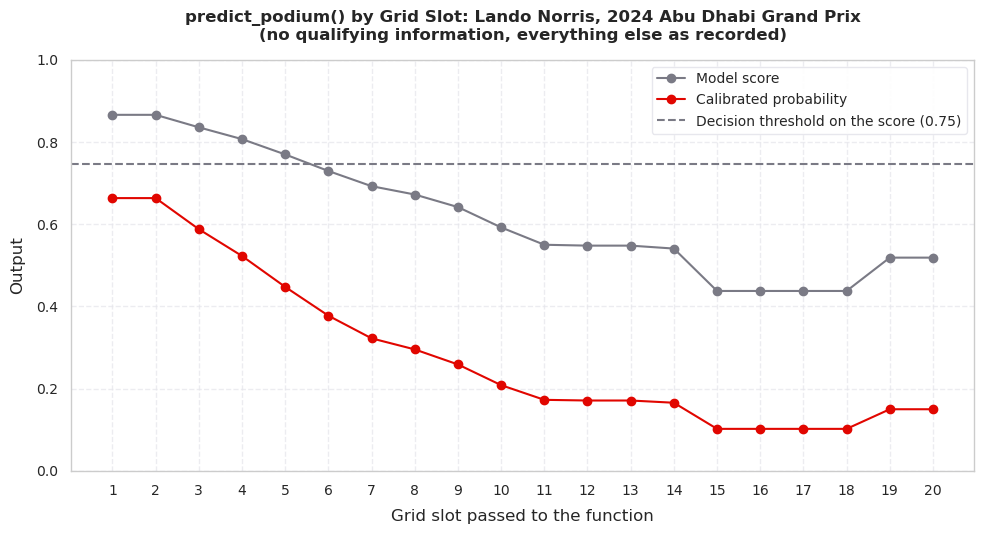

Training rows of teams with more than 15% of recent points, starting from slots 13 to 16: 449 rows, podium rate 6.5%
Training rows of teams with more than 15% of recent points, starting from slot 19 or further back: 288 rows, podium rate 4.2%


,driver outside the entry list
race,2024 Abu Dhabi Grand Prix
driver,Esteban Ocon
constructor,Alpine F1 Team
grid,10
qualifying,missing
score,0.300914
probability,0.04859
threshold,0.747297
prediction,0


In [117]:
# Task 38.4: what the function returns for other grid slots, a pit-lane start and a driver outside the entry list
grid_sweep = pd.DataFrame({slot: summary(predict_podium(demo_race, demo_driver, slot, None))[["score", "probability", "prediction"]]
                           for slot in [*range(1, len(demo_entries) + 1), 0]}).T.rename(index={0: "pit lane"})
display(grid_sweep.T.rename(index={'prediction': 'prediction (1 = podium)'}))

fig, ax = plt.subplots(figsize=(10, 5.5))
on_grid = grid_sweep.drop(index="pit lane")
ax.plot(on_grid.index.astype(int), on_grid["score"].astype(float), marker="o", color=F1_PALETTE["gray"], label="Model score")
ax.plot(on_grid.index.astype(int), on_grid["probability"].astype(float), marker="o", color=F1_PALETTE["crimson"], label="Calibrated probability")
ax.axhline(THRESHOLDS[LGBM], color=F1_PALETTE["gray"], linestyle="--", label=f"Decision threshold on the score ({THRESHOLDS[LGBM]:.2f})")
ax.set(title=f"predict_podium() by Grid Slot: {complete['driver']}, {complete['race']}\n(no qualifying information, everything else as recorded)",
       xlabel="Grid slot passed to the function", ylabel="Output", ylim=(0, 1), xticks=on_grid.index.astype(int))
ax.title.set_fontsize(12)
ax.legend(loc="upper right")
save_fig("inference_grid_what_if")
plt.show()

# The output rises again at the last two slots. What the training seasons say about strong teams' cars starting there:
STRONG_TEAM_POINTS_SHARE: float = 0.15
strong_cars = train_df[train_df["constructor_rolling_points_5"] > STRONG_TEAM_POINTS_SHARE]
for label, rows in [("slots 13 to 16", strong_cars[strong_cars["grid"].between(13, 16)]), ("slot 19 or further back", strong_cars[strong_cars["grid"] >= 19])]:
    print(f"Training rows of teams with more than {STRONG_TEAM_POINTS_SHARE:.0%} of recent points, starting from {label}: "
          f"{len(rows)} rows, podium rate {rows[TARGET_COLUMN].mean():.1%}")

outsider = int(clean_df.loc[~clean_df["driverId"].isin(demo_entries["driverId"]) & (clean_df["date"] < demo_entries["date"].iloc[0])]
               .sort_values("date")["driverId"].iloc[-1])   # the most recent driver who is not in this race
display(summary(predict_podium(demo_race, outsider, 10, None)).to_frame("driver outside the entry list"))

In [118]:
# Task 38.5: invalid input is rejected with a message
for label, call in [("unknown race", lambda: predict_podium(-1, demo_driver, 1)),
                    ("unknown driver", lambda: predict_podium(demo_race, -1, 1)),
                    ("grid is not a whole number", lambda: predict_podium(demo_race, demo_driver, 1.5)),
                    ("unknown qualifying key", lambda: predict_podium(demo_race, demo_driver, 1, {"pole_time": 80.0}))]:
    try:
        call()
        print(f"{label}: no error raised")
    except ValueError as error:
        print(f"{label}: ValueError: {error}")

unknown race: ValueError: raceId -1 is not in the races table
unknown driver: ValueError: driverId -1 is not in the drivers table
grid is not a whole number: ValueError: grid must be a whole number: 1 or more for a grid slot, 0 for a pit-lane start (got 1.5)
unknown qualifying key: ValueError: quali_info accepts the keys ['position', 'q1', 'q2', 'q3'] (got ['pole_time'])


**1. A complete record.** Lando Norris, pole at the 2024 Abu Dhabi Grand Prix, with his recorded qualifying times: score 0.901, probability 0.756, prediction podium. He won the race. The largest contribution is the grid slot (+1.65 log-odds), then the team's recent points, the zero gap to pole and the front-row flag.

**2. Missing values are handled by the model itself, and the answer degrades gently.**

| Input | `quali_position` | `gap_to_pole` | `q3_reached` | `missing_quali_flag` | Score | Probability | Prediction |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | :--- |
| Complete record | 1 | 0.0 | 1 | 0 | 0.901 | 0.756 | Podium |
| Position only, no lap times | 1 | missing | missing | 0 | 0.876 | 0.688 | Podium |
| No qualifying information | missing | missing | missing | 1 | 0.866 | 0.663 | Podium |

- No value is invented. The missing features reach LightGBM as missing, and each tree sends them down the branch it learned for missing values (DEC-024). Most of the training seasons have no qualifying data, so this is a situation the model has seen in about 14,000 training rows, not an edge case.
- The probability falls from 0.76 to 0.66 because the model can no longer see that he was fastest; the grid slot still tells it he starts first.
- **Across the whole 2024 season,** removing qualifying from every row moves PR-AUC from 0.694 to 0.692. The score changes by 0.038 on average and 0.189 at most, and 8 of 476 predictions flip.

**3. Other grid slots.** With the same driver and race, the probability falls from 0.66 on the front row to 0.38 at slot 6, where the prediction turns to "no podium", and to 0.10 at slots 15 to 18.

- **Slots 1 and 2 give the same output, and so do several neighbouring slots.** This is the staircase seen in the SHAP dependence plot (Task 33).
- **The output rises again at slots 19 and 20 (0.15) and for a pit-lane start.** The training data does not support this: cars of strong teams starting from slot 19 or further back reached the podium in 4.2% of 288 cases, against 6.5% from slots 13 to 16. A front-running car at the very back of the grid is rare, and the model's output there should not be trusted.
- **This is a what-if on the model, not on the race.** Only this driver's slot is changed; the other 19 cars keep theirs. It shows how the model responds to its input, not what would happen if the driver really started there (see "importance is not causation" at the end of Step 8).

**4. A driver outside the entry list** (Esteban Ocon, who did not start this race) is added in the team of his last race and scored like anyone else: probability 0.05 from slot 10.

**5. Invalid input raises a `ValueError` with a message** naming the problem: an unknown race or driver, a grid slot that is not a whole number, or an unknown qualifying key.

## Hand-Off

| Object | Contents |
| :--- | :--- |
| `predict_podium()` | The inference function |
| `pre_race_features()` | The 21 features of one driver in one race, from pre-race information |
| `recorded_quali()` | The dataset's qualifying record of a driver in a race, as a `quali_info` dict |
| `score_to_probability()`, `calibrator` | Platt scaling fitted on validation; `PROBABILITY_THRESHOLD` is the decision threshold as a probability (0.407) |
| `calibration_check` | Podium rate, mean score, mean probability and Brier scores on validation and test |
| `figures/inference_calibration.png` | Reliability on the test seasons, before and after calibration |
| `figures/inference_grid_what_if.png` | The function's output for each grid slot |

**Limits to state in the report (Step 10)**

- **The race must be in the dataset.** The function needs the race's date, circuit and entry list. A race that has not been loaded cannot be predicted; adding one means adding its rows to `races` and the entry list, not changing the function.
- **History is frozen at the dataset.** Form and standings come from the races in `archive/`, which end with the 2024 season.
- **The probability is calibrated on 39 races** (validation) and checked on 68 (test). It is a good average description; for unusual inputs, such as a front-running car starting last, it is not reliable.
- **The threshold is a probability of about 0.40,** chosen for F1. On the test seasons it predicts more podiums than there are (3.8 per race for LightGBM against 3 real ones, Task 28).

---
# 11. Step 10: Limitations and Future Work

This section closes the notebook. It first maps each requirement of the milestone brief to the place where it is met, then states what the results do not support, and ends with what would be worth doing next.

## Where Each Requirement Is Met

| Requirement of the brief | Notebook section | Tasks | Main evidence |
| :--- | :--- | :--- | :--- |
| EDA before and after cleaning | 2 and 3 | 3, 8 | Six `before_eda_*` and five `after_eda_*` figures |
| Sentinel values and semantic typing | 3 | 4 | No `\N` text remains; dates and lap times converted; raw tables unchanged (asserted) |
| One row per `(raceId, driverId)`, documented duplicate rule | 3 | 6 | DEC-034; 157 shared-car rows removed (Piazza: no mixing of two drivers' data); grain asserted |
| Primary keys and foreign keys | 2 | 2 | 16 keys unique and non-null; 22 foreign keys with zero orphans |
| Three data-engineering questions | 4 | 9–11 | Answer, figure, joins, grain, missing values and pre-race cutoff per question; Q1 by grid only over all seasons (DEC-035), Q3 with the instructors' mechanical list (DEC-036) |
| Evidence-backed features, no leakage | 5 | 12–14 | Feature registry; two leakage tests; sprint leakage check (DEC-039); five `feat_*` figures |
| Justified train/validation/test split | 6 | 15 | Split by season (DEC-002) |
| Distribution plots before and after preprocessing | 6 | 18 | `prep_distributions_by_stage`, `prep_distribution_shift` |
| Two preprocessing-order experiments | 6 | 19 | Train-only vs. all rows; impute → scale vs. scale → impute (DEC-021) |
| Baseline, two statistical models, shallow neural network | 7 | 22–25 | Grid rule, logistic regression, random forest, LightGBM, Keras network |
| Threshold tuning on validation only | 7 | 27 | DEC-028 |
| ROC-AUC, PR-AUC and F1 on all three splits | 7 | 28 | `MODEL_RESULTS` |
| Feature-group ablation | 8 | 29–31 | Per group and per block, with intervals |
| Every row removal backed by evidence | 8 | 31b | Withdrawn entries and the Indianapolis 500 retrained with the rows kept (DEC-038) |
| Global and local explainability, causal disclaimer | 9 | 32–35 | Permutation importance, SHAP beeswarm and waterfalls, LIME |
| Inference function on complete and incomplete records | 10 | 36–38 | `predict_podium()` |

## Limitations

**Data**

- **Qualifying data is thin before 2003.** There is none before 1994, and in 1996–2002 the file covers only 6% to 59% of the results rows. The four qualifying features are missing in 63% of the training rows and in almost none of the validation and test rows. The model therefore learns the value of qualifying from about a third of its training rows.
- **The training seasons are not like the seasons the model is tested on.** Training runs from 1950 to 2019: larger and more variable fields, a lower podium rate (13.5% against 15.1%), different points systems and different car reliability. `field_size` in validation and test sits almost one training standard deviation below the training mean (Task 18).
- **Era boundaries are not modelled.** Regulation changes (2014 hybrid engines, 2022 ground-effect cars) reshuffle which teams are fast. The model only sees them through form and standings, which lag by a few races. Features built from past results transfer less well to the 2022–2024 test seasons than the starting position does (Task 31).
- **Constructor identity breaks at rebrands.** Form and standings are keyed by `constructorId`, so a renamed team (for example Toro Rosso to AlphaTauri) starts its rolling history from nothing. The lineage mapping of DEC-014 was used for Q3 only, not for the features.
- **Shared drives of the 1950s and early 1960s are removed** (DEC-034): 157 rows in 40 races, 0.7% of the training rows. The data cannot say which driver started a shared car, so neither driver's row can be kept without mixing two drivers' data. Two races are left with one podium row and 13 with two.

**Evaluation**

- **The validation and test sets are small.** 39 validation races (117 podiums) and 68 test races (204 podiums). The 95% intervals on PR-AUC differences are about ±0.02 to ±0.03, so no learned model can be separated from another, and the choice of LightGBM over logistic regression is not supported by the test scores (0.709 against 0.712).
- **Tuning on validation flattered the forest and LightGBM.** They lose 0.028 and 0.034 PR-AUC from validation to test, the untuned logistic regression 0.015 (Task 28).
- **Single-seed tuning picks winners by luck.** Removing 157 shared-drive rows was enough to change the winner of all three searches when each configuration was fitted once. Ranking by the mean over five seeds (DEC-037) picks stable settings, at five times the tuning cost.
- **The decision thresholds do not transfer well.** Chosen for F1 on validation, they predict 3.8 to 5.2 podiums per race on test. Picking the three highest-scoring drivers of each race does no better than the grid rule (Task 28).
- **The test seasons were scored more than once.** Task 28 is the only place a model was judged on them, and nothing was chosen from test scores. They were scored again to describe the features in Step 7 and to check the calibration in Step 9. They are no longer untouched data for any future change.

**Model**

- **It is mostly a model of the starting grid.** The starting-position block carries 54% of the SHAP magnitude (`grid` alone 40%); the gain from all other features is about 0.06 PR-AUC over a rule that predicts the first three grid slots (Tasks 28 and 33).
- **In-race events put a ceiling on any pre-race model.** Crashes, safety cars, penalties, weather and strategy are not in the inputs. The 2020 Italian Grand Prix cases (Task 34) show a correct reading of the inputs followed by an outcome they did not contain.
- **Four of the 21 features are never used** and the context group contributes nothing (Tasks 31 and 33). They were kept because the model was fixed before the test seasons were scored.
- **The model output is unreliable for unusual inputs.** The grid what-if in Task 38 rises again for a front-running car starting last, which the training data does not support.
- **Explanations describe the model, not the sport.** Importance is not a causal effect, and credit between overlapping features such as `grid` and `quali_position` is arbitrary (Step 8).

**Inference**

- **`predict_podium()` works only for races in the dataset.** It needs the race's date, circuit and entry list, and its history ends with the 2024 season.
- **The probability is calibrated on 39 races.** It matches the test seasons on average (0.161 against a podium rate of 0.151) but is not a guarantee for a single unusual prediction.

## Future Work

- **Use the lineage of renamed teams in the features,** so a rebrand does not reset constructor form (the mapping exists from DEC-014).
- **Drop the context group and the four unused features,** and compare a logistic regression on the remaining blocks with LightGBM on a new, untouched season. The simpler model is level with the tuned ones here.
- **Rank within the race instead of scoring rows independently.** Every race has exactly three podium places; a model that knows this could use it, where the per-row classifier cannot.
- **Add pre-race information the dataset does not hold:** practice-session pace, tyre allocation, weather forecast, and grid penalties known before qualifying.
- **Add sprint results** once enough seasons contain them. The training seasons hold none (DEC-016).
- **Re-evaluate on seasons after 2024** before any further change, since the 2022–2024 seasons have now been used.
- **Tune with rolling-origin validation** (several consecutive validation windows) instead of one 39-race window, to make tuning and threshold choice less noisy.

## Run Check

The result paragraphs of this notebook, and the report, quote numbers from one run. A different dataset version or different library versions can shift them. The cell below compares the headline numbers as quoted with the values of the current run.

- **Every row matches:** the text and the report describe this run.
- **A row differs:** the text that quotes it has to be checked against the new outputs. Counts (rows, features) differing means the dataset is a different version; scores differing while counts match means a library behaves differently, most likely for the neural network.

The cell never raises, so it cannot break a Run All.

In [119]:
# Run check: headline numbers as quoted in the text and the report, against this run
import platform
from importlib import metadata

# name -> (value as quoted, number of decimals it is quoted with, value in this run)
HEADLINE_NUMBERS: Dict[str, Tuple[float, int, float]] = {
    "Rows in raw results": (26759, 0, len(raw_dataframes["results"])),
    "Rows in the modeling table": (24482, 0, len(model_df)),
    "Training rows": (22355, 0, len(train_df)),
    "Validation rows": (775, 0, len(val_df)),
    "Test rows": (1352, 0, len(test_df)),
    "Features": (21, 0, len(FEATURE_COLUMNS)),
    "Podium rate after cleaning (%)": (13.58, 2, clean_df[TARGET_COLUMN].mean() * 100),
    **{f"{name}, {split} PR-AUC": (quoted, 3, MODEL_RESULTS.loc[(name, split), "PR-AUC"])
       for name, by_split in {GRID_RULE: {"validation": 0.648, "test": 0.647}, LOGISTIC: {"validation": 0.726, "test": 0.712},
                              FOREST: {"validation": 0.735, "test": 0.707}, LGBM: {"validation": 0.743, "test": 0.709},
                              NEURAL_NET: {"validation": 0.733, "test": 0.720}}.items()
       for split, quoted in by_split.items()},
    f"{LGBM}, decision threshold": (0.747, 3, THRESHOLDS[LGBM]),
    f"{LGBM}, test F1": (0.684, 3, MODEL_RESULTS.loc[(LGBM, "test"), "F1"]),
    "Ablation, without starting position, test Δ": (-0.121, 3, block_ablation.loc["without starting position", ("test", "Δ")]),
    "Ablation, without past results, test Δ": (-0.031, 3, block_ablation.loc["without past results", ("test", "Δ")]),
    "Permutation drop of grid": (0.229, 3, feature_permutation.loc["grid", "PR-AUC drop"]),
    "SHAP share of grid (%)": (40, 0, shap_importance.loc["grid", "share %"]),
    "SHAP share of the starting-position block (%)": (54, 0, importance_views.loc[("block", "starting position"), "SHAP share %"]),
    "Data scope, withdrawn entries kept, validation Δ": (-0.013, 3, data_scope.loc[(LGBM, "Withdrawn entries kept"), ("validation", "Δ")]),
    "Data scope, Indianapolis 500 kept, validation Δ": (-0.000, 3, data_scope.loc[(LGBM, "Indianapolis 500 kept"), ("validation", "Δ")]),
    "Mean calibrated probability, test": (0.161, 3, calibration_check.loc["test", "mean probability"]),
    "Probability of the complete demo record": (0.756, 3, complete["probability"]),
}

run_check = pd.DataFrame([{"number": name, "quoted": quoted, "this run": round(float(value), decimals + 1),
                           "matches": abs(float(value) - quoted) <= 0.6 * 10.0 ** -decimals}
                          for name, (quoted, decimals, value) in HEADLINE_NUMBERS.items()]).set_index("number")
display(run_check)

differing = list(run_check.index[~run_check["matches"]])
if differing:
    print(f"{len(differing)} of {len(run_check)} headline numbers differ from the text: " + "; ".join(differing))
    print("Check the result paragraphs and the report against the outputs of this run.")
else:
    print(f"All {len(run_check)} headline numbers match the text and the report.")

versions = {package: metadata.version(package) for package in ["pandas", "numpy", "scikit-learn", "lightgbm", "tensorflow", "shap", "lime"]}
print(f"Python {platform.python_version()} | " + ", ".join(f"{package} {version}" for package, version in versions.items()))
print(f"Dataset: {DATASET_DIR} | seasons {int(clean_df['year'].min())}–{int(clean_df['year'].max())} | last race {clean_df['date'].max().date()}")

,quoted,this run,matches
number,,,
Rows in raw results,26759.000,26759.0000,True
Rows in the modeling table,24482.000,24482.0000,True
Training rows,22355.000,22355.0000,True
Validation rows,775.000,775.0000,True
Test rows,1352.000,1352.0000,True
Features,21.000,21.0000,True
Podium rate after cleaning (%),13.580,13.5810,True
"Grid ≤ 3 rule, validation PR-AUC",0.648,0.6478,True
"Grid ≤ 3 rule, test PR-AUC",0.647,0.6474,True


All 28 headline numbers match the text and the report.
Python 3.11.8 | pandas 2.3.3, numpy 1.26.4, scikit-learn 1.4.2, lightgbm 4.7.0, tensorflow 2.19.1, shap 0.49.1, lime 0.2.0.1
Dataset: /Users/marina/Desktop/Formula-1/archive | seasons 1950–2024 | last race 2024-12-08
